
#  DBSCAN Spatial Clustering


### Objective

Identify geographic concentrations of infrastructure-related  complaints using Density-Based Spatial Clustering of Applications with Noise (DBSCAN).



### Methodological Considerations

- Use appropriate geographic coordinates and distance units.
- Audit missing, invalid and duplicated locations.
- Review previously identified geographic consistency flags.
- Avoid interpreting complaint density directly as physical infrastructure risk.
- Select and evaluate DBSCAN parameters systematically.
- Preserve the completed K-Means models and outputs.

###  Spatial Data Readiness

Initial tasks:

- Load the full-data geographic complaint dataset.
- Inspect coordinate availability and validity.
- Identify duplicated locations.
- Establish the eligible complaint population for DBSCAN.
- Document geographic limitations before spatial clustering.


In [1]:

from pathlib import Path

import pandas as pd
import numpy as np

print(" DBSCAN SPATIAL DATA READINESS")
print("=" * 65)

# Project directories
PROJECT_ROOT = Path(
    r"D:\Urban-Infrastructure-Pulse-Intelligence"
)

PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

DBSCAN_TABLES_DIR = PROJECT_ROOT / "outputs" / "tables" / "dbscan"
DBSCAN_FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures" / "dbscan"

DBSCAN_TABLES_DIR.mkdir(parents=True, exist_ok=True)
DBSCAN_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Load the full-data geographic dataset
INPUT_FILE = (
    PROCESSED_DATA_DIR
    / "nyc311_infrastructure_geographic.csv"
)

if not INPUT_FILE.is_file():
    raise FileNotFoundError(
        f"Geographic dataset not found: {INPUT_FILE}"
    )

df_spatial = pd.read_csv(
    INPUT_FILE,
    low_memory=False
)

if df_spatial.empty:
    raise ValueError("Spatial dataset is empty.")

print("\nDATASET OVERVIEW")
print("-" * 65)

print("Source:", INPUT_FILE.name)
print("Records:", f"{len(df_spatial):,}")
print("Columns:", df_spatial.shape[1])

print("\nCOLUMN NAMES")
for i, column in enumerate(df_spatial.columns, start=1):
    print(f"{i:02d}. {column}")

print("\nPOSSIBLE GEOGRAPHIC COLUMNS")

geo_keywords = [
    "latitude",
    "longitude",
    "location",
    "borough",
    "incident_zip",
    "geometry",
    "coordinate",
    "area_id"
]

geo_columns = [
    column for column in df_spatial.columns
    if any(
        keyword in column.lower()
        for keyword in geo_keywords
    )
]

for column in geo_columns:
    print(
        column,
        "| Missing:",
        f"{df_spatial[column].isna().sum():,}",
        "| Type:",
        df_spatial[column].dtype
    )

print("\nFIRST FIVE RECORDS")
display(df_spatial.head())

print("\nSTATUS: DATASET LOADED")


 DBSCAN SPATIAL DATA READINESS

DATASET OVERVIEW
-----------------------------------------------------------------
Source: nyc311_infrastructure_geographic.csv
Records: 611,284
Columns: 53

COLUMN NAMES
01. unique_key
02. created_date
03. closed_date
04. agency
05. agency_name
06. complaint_type
07. descriptor
08. descriptor_2
09. location_type
10. incident_zip
11. incident_address
12. street_name
13. cross_street_1
14. cross_street_2
15. intersection_street_1
16. intersection_street_2
17. address_type
18. city
19. landmark
20. facility_type
21. status
22. due_date
23. resolution_description
24. resolution_action_updated_date
25. community_board
26. council_district
27. police_precinct
28. bbl
29. borough
30. x_coordinate_state_plane
31. y_coordinate_state_plane
32. open_data_channel_type
33. park_facility_name
34. park_borough
35. vehicle_type
36. taxi_company_borough
37. taxi_pick_up_location
38. bridge_highway_name
39. bridge_highway_direction
40. road_ramp
41. bridge_highway_segmen

,unique_key,created_date,closed_date,agency,agency_name,complaint_type,descriptor,descriptor_2,location_type,incident_zip,...,location,created_year,created_month,created_day_of_week,resolution_hours,has_valid_coordinates,coordinate_quality_flag,date_quality_flag,has_closed_date,is_closed_status
0,56409451,2023-01-01T00:18:00.000,2023-01-01T03:40:00.000,DOT,Department of Transportation,Traffic Signal Condition,Controller,Operating Improperly,NaN,11208.0,...,POINT (-73.881428919213 40.676634912459),2023,1,Sunday,3.367,True,valid_coordinate_range,valid_or_not_evaluable,True,True
1,56410624,2023-01-01T00:25:00.000,2023-01-01T05:50:00.000,DOT,Department of Transportation,Traffic Signal Condition,Controller,Operating Improperly,NaN,11358.0,...,POINT (-73.803741344846 40.762132385932),2023,1,Sunday,5.417,True,valid_coordinate_range,valid_or_not_evaluable,True,True
2,56410653,2023-01-01T00:52:00.000,2023-01-01T03:50:00.000,DOT,Department of Transportation,Traffic Signal Condition,Controller,Operating Improperly,NaN,11102.0,...,POINT (-73.920768788821 40.767649260236),2023,1,Sunday,2.967,True,valid_coordinate_range,valid_or_not_evaluable,True,True
3,56411233,2023-01-01T00:18:00.000,2023-01-01T03:40:00.000,DOT,Department of Transportation,Traffic Signal Condition,Controller,Operating Improperly,NaN,11208.0,...,POINT (-73.881428919213 40.676634912459),2023,1,Sunday,3.367,True,valid_coordinate_range,valid_or_not_evaluable,True,True
4,56411829,2023-01-01T00:21:00.000,2023-01-01T05:00:00.000,DOT,Department of Transportation,Traffic Signal Condition,Controller,Operating Improperly,NaN,11214.0,...,POINT (-73.990933324253 40.594332825657),2023,1,Sunday,4.650,True,valid_coordinate_range,valid_or_not_evaluable,True,True



STATUS: DATASET LOADED



##  Coordinate Validity and Geographic Coverage Audit

### Objective

Assess the coordinate quality and dataset coverage before selecting observations for DBSCAN.

### Verification Requirements

- Compare the geographic dataset against the full cleaned complaint dataset.
- Verify unique complaint identifiers.
- Count missing and invalid coordinates.
- Inspect existing coordinate quality flags.
- Identify coordinates outside approximate NYC geographic bounds.
- Measure the number of repeated coordinate locations.
- Preserve all records during this audit.

### Important

Repeated coordinates are not automatically duplicate complaints. Multiple independent 311 reports can legitimately originate from the same location.

Coordinate-range validity does not independently establish borough, ZIP, or street-level geographic accuracy.


In [2]:

import numpy as np
import pandas as pd

print("DBSCAN COORDINATE QUALITY AND COVERAGE AUDIT")
print("=" * 65)

# 1. Dataset coverage
full_cleaned_path = (
    PROCESSED_DATA_DIR
    / "nyc311_infrastructure_cleaned.csv"
)

full_keys = pd.read_csv(
    full_cleaned_path,
    usecols=["unique_key"],
    low_memory=False
)

geo_keys = df_spatial["unique_key"]

print("\n1. DATASET COVERAGE")
print("Full cleaned records:", f"{len(full_keys):,}")
print("Geographic records:", f"{len(df_spatial):,}")
print(
    "Records excluded:",
    f"{len(full_keys) - len(df_spatial):,}"
)

assert full_keys["unique_key"].is_unique
assert geo_keys.is_unique

full_key_set = set(full_keys["unique_key"])
geo_key_set = set(geo_keys)

print("Geographic keys subset of full:",
      geo_key_set.issubset(full_key_set))

print(
    "Full records absent from geographic dataset:",
    f"{len(full_key_set - geo_key_set):,}"
)

print(
    "Unexpected geographic keys:",
    f"{len(geo_key_set - full_key_set):,}"
)

# 2. Coordinate availability
latitude = pd.to_numeric(
    df_spatial["latitude"], errors="coerce"
)
longitude = pd.to_numeric(
    df_spatial["longitude"], errors="coerce"
)

finite_coordinates = (
    np.isfinite(latitude.to_numpy())
    & np.isfinite(longitude.to_numpy())
)

print("\n2. COORDINATE AVAILABILITY")
print("Finite coordinate pairs:",
      f"{finite_coordinates.sum():,}")
print("Missing/invalid pairs:",
      f"{(~finite_coordinates).sum():,}")

print("\n3. EXISTING QUALITY FLAGS")
print(
    df_spatial[
        "coordinate_quality_flag"
    ].value_counts(dropna=False).to_string()
)

print("\nExisting valid-coordinate indicator:")
print(
    df_spatial[
        "has_valid_coordinates"
    ].value_counts(dropna=False).to_string()
)

# 4. Approximate NYC bounding-box screening
# This is a broad screening box, not a borough polygon.
within_nyc_bounds = (
    latitude.between(40.45, 40.95)
    & longitude.between(-74.30, -73.65)
)

outside_bounds = (
    finite_coordinates
    & ~within_nyc_bounds.to_numpy()
)

print("\n4. APPROXIMATE NYC BOUNDS")
print(
    "Finite coordinate pairs outside screening bounds:",
    f"{outside_bounds.sum():,}"
)

# 5. Repeated coordinate locations
coordinates = pd.DataFrame({
    "latitude": latitude,
    "longitude": longitude
}).loc[finite_coordinates]

coordinate_counts = coordinates.value_counts()

print("\n5. REPEATED COORDINATES")
print("Unique coordinate pairs:",
      f"{len(coordinate_counts):,}")

print(
    "Coordinate pairs used more than once:",
    f"{(coordinate_counts > 1).sum():,}"
)

print(
    "Complaints at repeated coordinate pairs:",
    f"{coordinate_counts[coordinate_counts > 1].sum():,}"
)

print(
    "Maximum complaints at one coordinate pair:",
    int(coordinate_counts.max()) if len(coordinate_counts) else 0
)

print("\nSTATUS: COORDINATE AUDIT COMPLETED")


DBSCAN COORDINATE QUALITY AND COVERAGE AUDIT

1. DATASET COVERAGE
Full cleaned records: 685,284
Geographic records: 611,284
Records excluded: 74,000
Geographic keys subset of full: True
Full records absent from geographic dataset: 74,000
Unexpected geographic keys: 0

2. COORDINATE AVAILABILITY
Finite coordinate pairs: 611,284
Missing/invalid pairs: 0

3. EXISTING QUALITY FLAGS
coordinate_quality_flag
valid_coordinate_range    611284

Existing valid-coordinate indicator:
has_valid_coordinates
True    611284

4. APPROXIMATE NYC BOUNDS
Finite coordinate pairs outside screening bounds: 0

5. REPEATED COORDINATES
Unique coordinate pairs: 211,660
Coordinate pairs used more than once: 91,041
Complaints at repeated coordinate pairs: 490,665
Maximum complaints at one coordinate pair: 784

STATUS: COORDINATE AUDIT COMPLETED



##  Geographic Exclusion and Coordinate Repetition Audit

### Objective

Investigate why 74,000 complaints from the full cleaned dataset are absent from the spatial dataset, and quantify coordinate repetition before selecting a DBSCAN implementation.

### Required Checks

1. Identify the records absent from the geographic dataset.
2. Compare coordinate availability for excluded and retained records.
3. Examine existing coordinate quality flags.
4. Quantify the number of unique coordinate pairs.
5. Measure the distribution of complaints per coordinate.
6. Evaluate whether coordinate aggregation is appropriate for scalable DBSCAN.

### Interpretation

Repeated coordinate pairs are not automatically duplicate complaints.

Coordinate aggregation with complaint-count weights may preserve spatial density while reducing computation, but it must be validated against the intended clustering methodology.


In [4]:

import numpy as np
import pandas as pd

print("DBSCAN EXCLUSION AND COORDINATE REPETITION AUDIT")
print("=" * 65)

# Read only required columns from the full cleaned dataset
audit_columns = [
    "unique_key",
    "latitude",
    "longitude",
    "complaint_type",
]

full_audit = pd.read_csv(
    PROCESSED_DATA_DIR / "nyc311_infrastructure_cleaned.csv",
    usecols=lambda c: c in audit_columns,
    low_memory=False
)

required = set(audit_columns)
missing = required - set(full_audit.columns)

assert not missing, f"Missing columns: {missing}"
assert full_audit["unique_key"].is_unique

# Identify the records excluded from the geographic dataset
geo_key_set = set(df_spatial["unique_key"])

excluded = full_audit.loc[
    ~full_audit["unique_key"].isin(geo_key_set)
].copy()

print("\n1. EXCLUDED RECORDS")
print("Full cleaned records:", f"{len(full_audit):,}")
print("Geographic records:", f"{len(df_spatial):,}")
print("Excluded records:", f"{len(excluded):,}")

assert len(excluded) == 74000

# Coordinate availability among excluded records
lat = pd.to_numeric(excluded["latitude"], errors="coerce")
lon = pd.to_numeric(excluded["longitude"], errors="coerce")

finite = (
    np.isfinite(lat.to_numpy())
    & np.isfinite(lon.to_numpy())
)

within_bounds = (
    lat.between(40.45, 40.95)
    & lon.between(-74.30, -73.65)
).to_numpy()

print("\n2. EXCLUDED COORDINATE QUALITY")
print("Finite coordinate pairs:", f"{finite.sum():,}")
print("Non-finite coordinate pairs:", f"{(~finite).sum():,}")
print(
    "Finite pairs within broad NYC bounds:",
    f"{(finite & within_bounds).sum():,}"
)
print(
    "Finite pairs outside broad NYC bounds:",
    f"{(finite & ~within_bounds).sum():,}"
)

# Complaint category distribution among excluded records
print("\n3. TOP EXCLUDED COMPLAINT TYPES")

print(
    excluded["complaint_type"]
    .value_counts(dropna=False)
    .head(15)
    .to_string()
)

# Count complaints at every exact coordinate pair
coord_counts = (
    df_spatial
    .groupby(["latitude", "longitude"], dropna=False)
    .size()
    .rename("complaint_count")
    .reset_index()
)

print("\n4. UNIQUE COORDINATE POPULATION")
print("Unique coordinate pairs:", f"{len(coord_counts):,}")
print("Total complaints:", f"{coord_counts['complaint_count'].sum():,}")

print("\n5. COMPLAINTS PER COORDINATE")
print(
    coord_counts["complaint_count"]
    .describe(percentiles=[0.5, 0.75, 0.90, 0.95, 0.99])
    .round(2)
    .to_string()
)

print("\n6. HIGH-FREQUENCY COORDINATES")

display(
    coord_counts.nlargest(10, "complaint_count")
    .reset_index(drop=True)
)

print("\nSTATUS: AUDIT COMPLETED")




DBSCAN EXCLUSION AND COORDINATE REPETITION AUDIT

1. EXCLUDED RECORDS
Full cleaned records: 685,284
Geographic records: 611,284
Excluded records: 74,000

2. EXCLUDED COORDINATE QUALITY
Finite coordinate pairs: 0
Non-finite coordinate pairs: 74,000
Finite pairs within broad NYC bounds: 0
Finite pairs outside broad NYC bounds: 0

3. TOP EXCLUDED COMPLAINT TYPES
complaint_type
Street Condition                 57193
Traffic Signal Condition          8746
Street Light Condition            5637
Bridge Condition                   833
Sewer                              767
Sidewalk Condition                 341
Street Sign - Dangling             148
Street Sign - Damaged              136
Street Sign - Missing              110
Sewer Maintenance                   36
Root/Sewer/Sidewalk Condition       30
Curb Condition                      14
Water Leak                           6
Water Maintenance                    3

4. UNIQUE COORDINATE POPULATION
Unique coordinate pairs: 211,660
Total compl

,latitude,longitude,complaint_count
0,40.782369,-73.965238,784
1,40.742377,-73.842157,426
2,40.730099,-73.810908,330
3,40.663089,-73.962387,283
4,40.714558,-74.021232,222
5,40.766887,-73.921391,209
6,40.693663,-73.852164,206
7,40.702512,-73.852566,199
8,40.726328,-73.766188,176
9,40.732730,-73.993816,171



STATUS: AUDIT COMPLETED



##  Spatial Population and Coordinate Aggregation Audit

### Objective

Define the eligible complaint population for DBSCAN and evaluate whether weighted unique-coordinate clustering is computationally appropriate.

### Analysis

- Calculate spatial coordinate availability by complaint category.
- Count unique coordinate pairs.
- Examine complaint-frequency concentration.
- Estimate reduction in DBSCAN input observations.
- Preserve the number of complaints represented by every coordinate.

### Methodological Decision

Candidate approach: apply DBSCAN to unique latitude–longitude pairs using complaint frequency as sample weight.

This approach preserves the contribution of repeated exact coordinates to neighborhood density, subject to verification of the DBSCAN implementation and distance metric.

### Caution

Missing-coordinate complaints cannot be assigned spatial clusters without additional valid geographic information.

Spatial clusters describe concentrations of geocoded 311 reporting activity, not independently established infrastructure damage.


In [5]:

import numpy as np
import pandas as pd

print("DBSCAN SPATIAL POPULATION ASSESSMENT")
print("=" * 65)

# 1. Complaint-type geographic coverage
full_counts = (
    full_audit.groupby("complaint_type")
    .size()
    .rename("full_complaints")
)

spatial_counts = (
    df_spatial.groupby("complaint_type")
    .size()
    .rename("spatial_complaints")
)

coverage = pd.concat(
    [full_counts, spatial_counts],
    axis=1
).fillna(0)

coverage["full_complaints"] = (
    coverage["full_complaints"].astype(int)
)

coverage["spatial_complaints"] = (
    coverage["spatial_complaints"].astype(int)
)

coverage["missing_coordinates"] = (
    coverage["full_complaints"]
    - coverage["spatial_complaints"]
)

coverage["spatial_coverage_pct"] = (
    100
    * coverage["spatial_complaints"]
    / coverage["full_complaints"]
)

coverage = coverage.sort_values(
    "spatial_coverage_pct"
)

print("\n1. COMPLAINT-TYPE GEOGRAPHIC COVERAGE")
display(coverage.round(2))

# 2. Unique-coordinate aggregation
coordinate_frequency = (
    df_spatial.groupby(
        ["latitude", "longitude"]
    )
    .size()
    .rename("complaint_weight")
    .reset_index()
)

coordinate_frequency = coordinate_frequency.sort_values(
    "complaint_weight",
    ascending=False
).reset_index(drop=True)

unique_locations = len(coordinate_frequency)
total_complaints = len(df_spatial)

reduction_pct = (
    100 * (1 - unique_locations / total_complaints)
)

print("\n2. COORDINATE AGGREGATION")
print("Original complaint observations:",
      f"{total_complaints:,}")
print("Unique coordinate observations:",
      f"{unique_locations:,}")
print("Reduction in observations:",
      f"{reduction_pct:.2f}%")

assert coordinate_frequency["complaint_weight"].sum() == total_complaints

# 3. Complaint-weight distribution
weights = coordinate_frequency["complaint_weight"]

print("\n3. LOCATION WEIGHT DISTRIBUTION")
print(
    weights.describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2).to_string()
)

# 4. Concentration of complaints at high-frequency locations
print("\n4. HIGH-FREQUENCY LOCATION CONTRIBUTION")

for threshold in [2, 5, 10, 25, 50, 100]:

    qualifying = weights >= threshold

    locations = int(qualifying.sum())
    complaints = int(weights[qualifying].sum())

    print(
        f"Locations with >= {threshold:3} complaints: "
        f"{locations:7,} locations | "
        f"{complaints:7,} complaints | "
        f"{100 * complaints / total_complaints:6.2f}%"
    )

# 5. Verify aggregation preserves all complaints
assert unique_locations > 0
assert unique_locations <= total_complaints
assert (weights >= 1).all()

print("\nSTATUS: PASSED")
print("SPATIAL POPULATION ASSESSMENT COMPLETED")


DBSCAN SPATIAL POPULATION ASSESSMENT

1. COMPLAINT-TYPE GEOGRAPHIC COVERAGE


,full_complaints,spatial_complaints,missing_coordinates,spatial_coverage_pct
complaint_type,,,,
Bridge Condition,840,7,833,0.83
Street Condition,205581,148388,57193,72.18
Traffic Signal Condition,129490,120744,8746,93.25
Street Light Condition,99259,93622,5637,94.32
Street Sign - Dangling,10585,10437,148,98.60
Sewer Maintenance,2949,2913,36,98.78
Street Sign - Missing,10408,10298,110,98.94
Sewer,82230,81463,767,99.07
Street Sign - Damaged,14976,14840,136,99.09



2. COORDINATE AGGREGATION
Original complaint observations: 611,284
Unique coordinate observations: 211,660
Reduction in observations: 65.37%

3. LOCATION WEIGHT DISTRIBUTION
count    211660.00
mean          2.89
std           5.95
min           1.00
50%           1.00
75%           2.00
90%           5.00
95%          10.00
99%          26.00
max         784.00

4. HIGH-FREQUENCY LOCATION CONTRIBUTION
Locations with >=   2 complaints:  91,041 locations | 490,665 complaints |  80.27%
Locations with >=   5 complaints:  26,510 locations | 326,269 complaints |  53.37%
Locations with >=  10 complaints:  10,964 locations | 226,771 complaints |  37.10%
Locations with >=  25 complaints:   2,473 locations | 102,470 complaints |  16.76%
Locations with >=  50 complaints:     511 locations |  37,670 complaints |   6.16%
Locations with >= 100 complaints:      58 locations |   8,833 complaints |   1.44%

STATUS: PASSED
SPATIAL POPULATION ASSESSMENT COMPLETED



##Prepare Weighted Geographic Coordinates

### Objective

Prepare the 211,660 unique coordinate pairs for geographic DBSCAN experiments.

### Method

- Use exact latitude–longitude coordinate pairs.
- Preserve complaint counts as sample weights.
- Convert geographic coordinates from degrees to radians.
- Use Haversine distance for geographic neighborhood calculations.
- Validate sample-weight totals and coordinate ranges.
- Avoid creating a full pairwise distance matrix.

### Important

Haversine measures approximate great-circle distance, not road-network distance.

Repeated complaint locations are retained through their sample weights.

Final DBSCAN parameter selection will follow spatial-distance and computational feasibility experiments.


In [6]:

import numpy as np
import pandas as pd

print("DBSCAN WEIGHTED GEOGRAPHIC COORDINATE PREPARATION")
print("=" * 65)

# 1. Aggregate exact coordinate pairs
dbscan_locations = (
    df_spatial
    .groupby(["latitude", "longitude"], as_index=False)
    .agg(
        complaint_weight=("unique_key", "count")
    )
)

# 2. Validate coordinates
coords_degrees = dbscan_locations[
    ["latitude", "longitude"]
].to_numpy(dtype=np.float64)

assert np.isfinite(coords_degrees).all()

assert (
    (coords_degrees[:, 0] >= -90)
    & (coords_degrees[:, 0] <= 90)
).all()

assert (
    (coords_degrees[:, 1] >= -180)
    & (coords_degrees[:, 1] <= 180)
).all()

# 3. Convert degrees to radians
coords_radians = np.radians(coords_degrees)

# 4. Preserve complaint frequencies as weights
sample_weights = dbscan_locations[
    "complaint_weight"
].to_numpy(dtype=np.int64)

# 5. Validate aggregation
assert len(dbscan_locations) == 211660

assert len(coords_radians) == len(sample_weights)

assert sample_weights.sum() == len(df_spatial)

assert (sample_weights >= 1).all()

# 6. Geographic distance configuration
EARTH_RADIUS_KM = 6371.0088

def km_to_radians(distance_km):
    if distance_km <= 0:
        raise ValueError("Distance must be positive.")
    return distance_km / EARTH_RADIUS_KM

print("\nSPATIAL INPUT SUMMARY")
print("-" * 65)

print("Original complaints:", f"{len(df_spatial):,}")
print("Unique coordinate locations:", f"{len(dbscan_locations):,}")
print("Total preserved complaint weight:",
      f"{sample_weights.sum():,}")

print("\nCOORDINATE REPRESENTATION")
print("Degree matrix shape:", coords_degrees.shape)
print("Radian matrix shape:", coords_radians.shape)
print("Sample-weight shape:", sample_weights.shape)

print("\nDISTANCE CONVERSION EXAMPLES")
for distance_m in [50, 100, 200, 300, 500]:
    print(
        f"{distance_m} meters = "
        f"{km_to_radians(distance_m / 1000):.10f} radians"
    )

print("\nSTATUS: PASSED")
print("WEIGHTED GEOGRAPHIC COORDINATES READY")


DBSCAN WEIGHTED GEOGRAPHIC COORDINATE PREPARATION

SPATIAL INPUT SUMMARY
-----------------------------------------------------------------
Original complaints: 611,284
Unique coordinate locations: 211,660
Total preserved complaint weight: 611,284

COORDINATE REPRESENTATION
Degree matrix shape: (211660, 2)
Radian matrix shape: (211660, 2)
Sample-weight shape: (211660,)

DISTANCE CONVERSION EXAMPLES
50 meters = 0.0000078481 radians
100 meters = 0.0000156961 radians
200 meters = 0.0000313922 radians
300 meters = 0.0000470883 radians
500 meters = 0.0000784805 radians

STATUS: PASSED
WEIGHTED GEOGRAPHIC COORDINATES READY



##  Spatial Neighborhood Distance Analysis

### Objective

Evaluate candidate DBSCAN neighborhood distances using weighted complaint counts.

### Method

- Construct a Haversine BallTree using all 211,660 unique locations.
- Select 1,200 reproducible random locations for neighborhood evaluation.
- Test neighborhood distances of 25, 50, 75, 100, 150 and 200 meters.
- Calculate complaint-weighted neighborhood counts.
- Estimate the proportion of sampled locations meeting candidate DBSCAN core-point thresholds.
- Process neighborhood queries in small batches to control memory usage.

### Candidate Parameters

| Parameter | Exploratory Values |
|---|---|
| eps | 25, 50, 75, 100, 150, 200 meters |
| min_samples | 5, 10, 20, 50 complaints |
| Distance Metric | Haversine |
| Neighborhood Density | Sum of complaint weights |

### Limitations

The sampled neighborhood summaries describe the spatial density around selected geographic locations. They are not final DBSCAN model results.

Random sampling over unique locations does not represent complaint-weighted sampling. Dense areas may also produce large neighborhood lists despite batching.


In [7]:

import numpy as np
import pandas as pd

from sklearn.neighbors import BallTree

print("DBSCAN SPATIAL NEIGHBORHOOD ANALYSIS")
print("=" * 65)

# Reuse the verified coordinate preparation
assert coords_radians.shape == (211660, 2)
assert len(sample_weights) == 211660
assert sample_weights.sum() == 611284

# 1. Build spatial search tree
print("\n1. BUILDING HAVERSINE BALLTREE")

spatial_tree = BallTree(
    coords_radians,
    metric="haversine",
    leaf_size=40
)

print("BallTree construction: PASSED")

# 2. Sample unique locations reproducibly
RANDOM_STATE = 42
SAMPLE_SIZE = 1200

rng = np.random.default_rng(RANDOM_STATE)

sample_indices = rng.choice(
    len(coords_radians),
    size=SAMPLE_SIZE,
    replace=False
)

sample_coords = coords_radians[sample_indices]

# 3. Candidate neighborhood distances
eps_values_m = [25, 50, 75, 100, 150, 200]
min_samples_values = [5, 10, 20, 50]

BATCH_SIZE = 100
EARTH_RADIUS_KM = 6371.0088

results = []

print("\n2. EVALUATING WEIGHTED NEIGHBORHOODS")
print("Sampled locations:", SAMPLE_SIZE)

for eps_m in eps_values_m:

    eps_radians = (
        eps_m / 1000
    ) / EARTH_RADIUS_KM

    weighted_counts = []
    unique_neighbor_counts = []

    # Process queries in small batches
    for start in range(0, SAMPLE_SIZE, BATCH_SIZE):

        end = min(start + BATCH_SIZE, SAMPLE_SIZE)

        neighbor_lists = spatial_tree.query_radius(
            sample_coords[start:end],
            r=eps_radians,
            return_distance=False
        )

        for neighbors in neighbor_lists:

            unique_neighbor_counts.append(len(neighbors))

            weighted_counts.append(
                int(sample_weights[neighbors].sum())
            )

    weighted_counts = np.asarray(
        weighted_counts,
        dtype=np.int64
    )

    unique_neighbor_counts = np.asarray(
        unique_neighbor_counts,
        dtype=np.int64
    )

    row = {
        "eps_m": eps_m,
        "median_weighted_complaints": float(
            np.median(weighted_counts)
        ),
        "p90_weighted_complaints": float(
            np.percentile(weighted_counts, 90)
        ),
        "p95_weighted_complaints": float(
            np.percentile(weighted_counts, 95)
        ),
        "median_unique_neighbors": float(
            np.median(unique_neighbor_counts)
        ),
    }

    for threshold in min_samples_values:

        row[f"core_pct_min_{threshold}"] = (
            100 * np.mean(weighted_counts >= threshold)
        )

    results.append(row)

    print(
        f"eps={eps_m:3} m | "
        f"median weighted complaints="
        f"{row['median_weighted_complaints']:.1f} | "
        f"90th percentile="
        f"{row['p90_weighted_complaints']:.1f}"
    )

# 4. Summarize results
neighborhood_results = pd.DataFrame(results)

print("\n3. NEIGHBORHOOD COMPARISON")

display(
    neighborhood_results.round(2)
)

# 5. Basic integrity checks
assert len(neighborhood_results) == len(eps_values_m)

assert neighborhood_results[
    "median_weighted_complaints"
].is_monotonic_increasing

print("\nSTATUS: PASSED")
print("SPATIAL NEIGHBORHOOD ANALYSIS COMPLETED")


DBSCAN SPATIAL NEIGHBORHOOD ANALYSIS

1. BUILDING HAVERSINE BALLTREE
BallTree construction: PASSED

2. EVALUATING WEIGHTED NEIGHBORHOODS
Sampled locations: 1200
eps= 25 m | median weighted complaints=6.0 | 90th percentile=21.0
eps= 50 m | median weighted complaints=11.0 | 90th percentile=34.0
eps= 75 m | median weighted complaints=19.5 | 90th percentile=53.0
eps=100 m | median weighted complaints=40.0 | 90th percentile=91.1
eps=150 m | median weighted complaints=79.0 | 90th percentile=177.0
eps=200 m | median weighted complaints=146.5 | 90th percentile=304.0

3. NEIGHBORHOOD COMPARISON


,eps_m,median_weighted_complaints,p90_weighted_complaints,p95_weighted_complaints,median_unique_neighbors,core_pct_min_5,core_pct_min_10,core_pct_min_20,core_pct_min_50
0,25,6.0,21.0,26.05,3.0,59.00,30.83,10.83,0.83
1,50,11.0,34.0,44.05,5.0,82.58,56.33,26.17,4.08
2,75,19.5,53.0,67.00,8.0,93.50,78.67,50.00,11.92
3,100,40.0,91.1,114.10,16.0,98.83,96.17,83.00,36.33
4,150,79.0,177.0,220.00,30.5,99.67,99.33,97.92,76.92
5,200,146.5,304.0,360.15,53.0,99.92,99.75,99.25,95.75



STATUS: PASSED
SPATIAL NEIGHBORHOOD ANALYSIS COMPLETED



##  Spatial Pilot Region Selection

### Objective

Select a geographically contiguous pilot region for computationally controlled DBSCAN parameter screening.

### Method

1. Partition NYC coordinates into approximate geographic tiles.
2. Count unique locations and complaints per tile.
3. Identify a tile containing approximately 10,000–20,000 unique coordinate locations.
4. Preserve complaint weights.
5. Inspect the candidate pilot region before running DBSCAN.

### Methodological Limitations

A spatial pilot may differ from the full NYC distribution.

Tile boundaries can remove neighbors that would exist in the full dataset.

Therefore, pilot results will guide computational feasibility and preliminary parameter selection, not establish final citywide clustering results.

### Initial Candidate Grid

- Neighborhood radii: 25, 50, 75, 100 meters
- Minimum weighted complaints: 10, 20, 50

Final parameter selection must also consider cluster size, connectivity, noise and spatial interpretability.


In [8]:

import numpy as np
import pandas as pd

print("DBSCAN SPATIAL PILOT REGION SELECTION")
print("=" * 65)

# Reuse verified unique-coordinate table
assert len(dbscan_locations) == 211660

pilot_source = dbscan_locations.copy()

# Approximate tile dimensions:
# 0.05 degrees latitude ≈ 5.6 km
# 0.05 degrees longitude ≈ 4.2 km near NYC
# Tile dimensions are approximate and vary geographically.
TILE_SIZE_DEGREES = 0.05

pilot_source["lat_tile"] = np.floor(
    pilot_source["latitude"] / TILE_SIZE_DEGREES
).astype(int)

pilot_source["lon_tile"] = np.floor(
    pilot_source["longitude"] / TILE_SIZE_DEGREES
).astype(int)

# Summarize coordinate locations and complaint weights
tile_summary = (
    pilot_source
    .groupby(["lat_tile", "lon_tile"], as_index=False)
    .agg(
        unique_locations=("complaint_weight", "size"),
        represented_complaints=("complaint_weight", "sum")
    )
)

# Rank tiles by unique coordinate count
tile_summary = tile_summary.sort_values(
    "unique_locations",
    ascending=False
).reset_index(drop=True)

print("\n1. GEOGRAPHIC TILE SUMMARY")
print("Total tiles:", len(tile_summary))

print("\n2. TOP 15 TILES BY UNIQUE LOCATIONS")
display(tile_summary.head(15))

# Identify tiles suitable for a computational pilot
candidate_tiles = tile_summary[
    tile_summary["unique_locations"].between(
        10000, 20000
    )
].copy()

print("\n3. SUITABLE PILOT CANDIDATES")
print("Candidate tiles:", len(candidate_tiles))

display(candidate_tiles.head(10))

# Select a pilot tile for later experiments
if not candidate_tiles.empty:

    selected_tile = candidate_tiles.iloc[0]

    selection_reason = (
        "Largest tile within the 10,000–20,000 "
        "unique-location target"
    )

else:

    # Do not silently treat an undersized tile as equivalent.
    selected_tile = None

    selection_reason = (
        "No single tile satisfies the target range. "
        "A multi-tile pilot may be required."
    )

print("\n4. PILOT REGION SELECTION")
print("Selection reason:", selection_reason)

if selected_tile is not None:

    print("Latitude tile:", int(selected_tile["lat_tile"]))
    print("Longitude tile:", int(selected_tile["lon_tile"]))
    print(
        "Unique locations:",
        int(selected_tile["unique_locations"])
    )
    print(
        "Represented complaints:",
        int(selected_tile["represented_complaints"])
    )

else:
    print("No pilot tile selected.")

print("\nSTATUS: PILOT REGION SCREENING COMPLETED")


DBSCAN SPATIAL PILOT REGION SELECTION

1. GEOGRAPHIC TILE SUMMARY
Total tiles: 60

2. TOP 15 TILES BY UNIQUE LOCATIONS


,lat_tile,lon_tile,unique_locations,represented_complaints
0,813,-1480,13150,38370
1,812,-1480,10839,32595
2,813,-1479,10442,30329
3,814,-1480,10177,31721
4,814,-1478,9142,25205
5,815,-1480,9094,35781
6,812,-1479,7767,20988
7,814,-1479,7681,22678
8,815,-1479,7431,22148
9,816,-1479,7179,26126



3. SUITABLE PILOT CANDIDATES
Candidate tiles: 4


,lat_tile,lon_tile,unique_locations,represented_complaints
0,813,-1480,13150,38370
1,812,-1480,10839,32595
2,813,-1479,10442,30329
3,814,-1480,10177,31721



4. PILOT REGION SELECTION
Selection reason: Largest tile within the 10,000–20,000 unique-location target
Latitude tile: 813
Longitude tile: -1480
Unique locations: 13150
Represented complaints: 38370

STATUS: PILOT REGION SCREENING COMPLETED


results confirm that we have identified a suitable geographically contiguous region for our first weighted DBSCAN experiment.

We can now begin testing DBSCAN parameters without immediately processing all 211,660 unique locations.
1. Selected pilot region
Selected geographic tile

813, −1480

Unique coordinate locations
13,150


Represented complaints
38,370




Approximate geographic extent: latitude 40.65°–40.70° N and longitude 74.00°–73.95° W. These are rectangular tile boundaries, not administrative boundaries.


## Weighted DBSCAN Pilot Experiments

### Objective

Evaluate candidate DBSCAN neighborhood distances and minimum weighted complaint thresholds within the selected spatial pilot region.

### Pilot Specification

| Parameter | Value |
|---|---|
| Latitude Tile | 813 |
| Longitude Tile | -1480 |
| Tile Size | 0.05 degrees |
| Core Evaluation Locations | 13,150 |
| Represented Core Complaints | 38,370 |
| Geographic Buffer | 200 meters |
| Distance Metric | Haversine |
| eps Values | 25, 50, 75, 100 meters |
| min_samples | 10, 20, 50 |

### Evaluation Metrics

- Number of clusters intersecting the core pilot region
- Percentage of core locations classified as noise
- Percentage of represented complaints classified as noise
- Largest cluster size
- Number of core points
- Computational feasibility

### Methodological Cautions

Cluster labels are arbitrary identifiers.

A 200-meter buffer includes nearby locations for the candidate neighborhood radii but does not guarantee complete equivalence to citywide DBSCAN connectivity.

Pilot results are exploratory and cannot establish the final NYC-wide DBSCAN parameter choice.


In [9]:

import numpy as np
import pandas as pd

print("DBSCAN BUFFERED PILOT PREPARATION")
print("=" * 65)

# Selected tile
LAT_TILE = 813
LON_TILE = -1480
TILE_SIZE = 0.05

# Largest candidate eps radius
BUFFER_METERS = 200

lat_min = LAT_TILE * TILE_SIZE
lat_max = (LAT_TILE + 1) * TILE_SIZE

lon_min = LON_TILE * TILE_SIZE
lon_max = (LON_TILE + 1) * TILE_SIZE

# Conservative degree conversion for the buffer
lat_buffer = BUFFER_METERS / 111_000

mean_lat = (lat_min + lat_max) / 2

lon_buffer = (
    BUFFER_METERS
    / (111_000 * np.cos(np.radians(mean_lat)))
)

# Identify original core tile locations
core_mask = (
    (dbscan_locations["latitude"] >= lat_min)
    & (dbscan_locations["latitude"] < lat_max)
    & (dbscan_locations["longitude"] >= lon_min)
    & (dbscan_locations["longitude"] < lon_max)
)

# Identify buffered pilot locations
buffer_mask = (
    dbscan_locations["latitude"].between(
        lat_min - lat_buffer,
        lat_max + lat_buffer
    )
    & dbscan_locations["longitude"].between(
        lon_min - lon_buffer,
        lon_max + lon_buffer
    )
)

pilot_df = dbscan_locations.loc[
    buffer_mask
].copy()

# Record which locations belong to the core tile
pilot_df["is_core_tile"] = core_mask.loc[
    pilot_df.index
].to_numpy()

pilot_df = pilot_df.reset_index(drop=True)

# Prepare radian coordinates and sample weights
pilot_coords_rad = np.radians(
    pilot_df[["latitude", "longitude"]].to_numpy(
        dtype=np.float64
    )
)

pilot_weights = pilot_df[
    "complaint_weight"
].to_numpy(dtype=np.int64)

pilot_core_mask = pilot_df[
    "is_core_tile"
].to_numpy(dtype=bool)

# Validate original pilot population
core_locations = int(pilot_core_mask.sum())

core_complaints = int(
    pilot_weights[pilot_core_mask].sum()
)

assert core_locations == 13150
assert core_complaints == 38370

assert np.isfinite(pilot_coords_rad).all()
assert (pilot_weights >= 1).all()

print("\nPILOT REGION SUMMARY")
print("-" * 65)

print("Latitude bounds:", lat_min, "to", lat_max)
print("Longitude bounds:", lon_min, "to", lon_max)

print("\nCore tile locations:", f"{core_locations:,}")
print("Core tile complaints:", f"{core_complaints:,}")

print("\nBuffered pilot locations:", f"{len(pilot_df):,}")
print(
    "Buffered pilot complaints:",
    f"{pilot_weights.sum():,}"
)

print(
    "Additional buffered locations:",
    f"{len(pilot_df) - core_locations:,}"
)

print("\nCoordinate shape:", pilot_coords_rad.shape)
print("Weight shape:", pilot_weights.shape)

print("\nSTATUS: PASSED")
print("BUFFERED PILOT DATASET READY")


DBSCAN BUFFERED PILOT PREPARATION

PILOT REGION SUMMARY
-----------------------------------------------------------------
Latitude bounds: 40.650000000000006 to 40.7
Longitude bounds: -74.0 to -73.95

Core tile locations: 13,150
Core tile complaints: 38,370

Buffered pilot locations: 14,606
Buffered pilot complaints: 43,049
Additional buffered locations: 1,456

Coordinate shape: (14606, 2)
Weight shape: (14606,)

STATUS: PASSED
BUFFERED PILOT DATASET READY



##  First Weighted DBSCAN Pilot Model

### Objective

Evaluate an initial weighted DBSCAN configuration using the buffered spatial pilot dataset.

### Initial Parameters

| Parameter | Value |
|---|---|
| eps | 50 meters |
| min_samples | 20 weighted complaints |
| Distance Metric | Haversine |
| Algorithm | BallTree |
| Core Tile Locations | 13,150 |
| Buffered Locations | 14,606 |
| Total Buffered Complaints | 43,049 |

### Evaluation Metrics

- Number of clusters intersecting the core tile
- Number of noise locations
- Percentage of core-tile locations classified as noise
- Complaint-weighted noise percentage
- Number of core samples
- Largest cluster size by locations and complaints
- Model execution time

### Interpretation

DBSCAN clusters identify connected concentrations of reported complaints.

Clusters should not be interpreted as independently verified infrastructure damage or physical infrastructure risk.

Results are exploratory and specific to the selected pilot region.


In [10]:

import time
import numpy as np
import pandas as pd

from sklearn.cluster import DBSCAN

print("FIRST WEIGHTED DBSCAN PILOT EXPERIMENT")
print("=" * 65)

# 1. Verify pilot inputs
assert pilot_coords_rad.shape == (14606, 2)
assert len(pilot_weights) == 14606
assert pilot_weights.sum() == 43049
assert pilot_core_mask.sum() == 13150

# 2. Initial DBSCAN parameters
EPS_METERS = 50
MIN_SAMPLES = 20
EARTH_RADIUS_KM = 6371.0088

eps_radians = (
    EPS_METERS / 1000
) / EARTH_RADIUS_KM

print("\nMODEL CONFIGURATION")
print("eps:", EPS_METERS, "meters")
print("min_samples:", MIN_SAMPLES)
print("Distance metric: Haversine")
print("Buffered locations:", len(pilot_coords_rad))

# 3. Fit weighted DBSCAN
start_time = time.perf_counter()

pilot_dbscan = DBSCAN(
    eps=eps_radians,
    min_samples=MIN_SAMPLES,
    metric="haversine",
    algorithm="ball_tree",
    leaf_size=40,
    n_jobs=1
)

pilot_labels = pilot_dbscan.fit_predict(
    pilot_coords_rad,
    sample_weight=pilot_weights
)

elapsed_seconds = time.perf_counter() - start_time

# 4. Evaluate the original core tile only
core_labels = pilot_labels[pilot_core_mask]
core_weights = pilot_weights[pilot_core_mask]

cluster_ids = sorted(
    set(core_labels) - {-1}
)

noise_mask = core_labels == -1

noise_locations = int(noise_mask.sum())
noise_complaints = int(
    core_weights[noise_mask].sum()
)

total_core_locations = len(core_labels)
total_core_complaints = int(core_weights.sum())

noise_location_pct = (
    100 * noise_locations / total_core_locations
)

noise_complaint_pct = (
    100 * noise_complaints / total_core_complaints
)

# 5. Count core samples within original tile
core_sample_mask = np.zeros(
    len(pilot_labels),
    dtype=bool
)

core_sample_mask[
    pilot_dbscan.core_sample_indices_
] = True

core_points_in_tile = int(
    np.sum(core_sample_mask & pilot_core_mask)
)

# 6. Calculate cluster sizes inside core tile
cluster_summary_rows = []

for cluster_id in cluster_ids:

    cluster_mask = core_labels == cluster_id

    cluster_summary_rows.append({
        "cluster_id": int(cluster_id),
        "locations": int(cluster_mask.sum()),
        "complaints": int(
            core_weights[cluster_mask].sum()
        )
    })

cluster_summary = pd.DataFrame(
    cluster_summary_rows,
    columns=["cluster_id", "locations", "complaints"]
)

if not cluster_summary.empty:
    cluster_summary = cluster_summary.sort_values(
        "complaints",
        ascending=False
    ).reset_index(drop=True)

# 7. Print evaluation
print("\nPILOT DBSCAN RESULTS")
print("-" * 65)

print("Execution time:", round(elapsed_seconds, 3), "seconds")
print("Clusters intersecting core tile:", len(cluster_ids))
print("Core samples within tile:", core_points_in_tile)

print("\nNOISE ANALYSIS")
print("Noise locations:", noise_locations)
print("Noise location percentage:",
      round(noise_location_pct, 2), "%")

print("Noise complaints:", noise_complaints)
print("Noise complaint percentage:",
      round(noise_complaint_pct, 2), "%")

print("\nLARGEST CLUSTERS INSIDE CORE TILE")

display(cluster_summary.head(10))

# 8. Integrity checks
assert (
    int(cluster_summary["locations"].sum())
    + noise_locations
    == total_core_locations
)

assert (
    int(cluster_summary["complaints"].sum())
    + noise_complaints
    == total_core_complaints
)

print("\nSTATUS: PASSED")
print("FIRST WEIGHTED DBSCAN PILOT COMPLETED")


FIRST WEIGHTED DBSCAN PILOT EXPERIMENT

MODEL CONFIGURATION
eps: 50 meters
min_samples: 20
Distance metric: Haversine
Buffered locations: 14606

PILOT DBSCAN RESULTS
-----------------------------------------------------------------
Execution time: 0.15 seconds
Clusters intersecting core tile: 435
Core samples within tile: 6086

NOISE ANALYSIS
Noise locations: 4124
Noise location percentage: 31.36 %
Noise complaints: 7512
Noise complaint percentage: 19.58 %

LARGEST CLUSTERS INSIDE CORE TILE


,cluster_id,locations,complaints
0,191,554,1669
1,330,280,1150
2,401,192,668
3,354,204,550
4,402,120,529
5,344,151,450
6,111,132,426
7,127,106,426
8,273,98,415
9,422,151,413



STATUS: PASSED
FIRST WEIGHTED DBSCAN PILOT COMPLETED



##  Weighted DBSCAN Parameter Sensitivity

### Objective

Compare 12 weighted DBSCAN configurations using the same buffered spatial pilot dataset.

### Parameter Grid

| Parameter | Candidate Values |
|---|---|
| eps | 25, 50, 75, 100 meters |
| min_samples | 10, 20, 50 |
| Distance Metric | Haversine |
| Algorithm | BallTree |
| Complaint Weights | Original complaints per coordinate |

### Evaluation Metrics

- Number of clusters intersecting the pilot core
- Noise percentage by unique locations
- Noise percentage by represented complaints
- Largest cluster complaint count
- Largest cluster complaint share
- Core sample count
- Model execution time

### Interpretation

A suitable configuration should identify meaningful concentrations without excessive fragmentation or merging.

There is no universal optimal noise percentage or cluster count. Parameter selection will depend on spatial interpretability, stability and computational feasibility.

Pilot results are exploratory and do not replace citywide evaluation.


In [11]:

import time
import numpy as np
import pandas as pd

from sklearn.cluster import DBSCAN

print("WEIGHTED DBSCAN PARAMETER SENSITIVITY")
print("=" * 65)

assert pilot_coords_rad.shape == (14606, 2)
assert pilot_weights.sum() == 43049
assert pilot_core_mask.sum() == 13150

EPS_VALUES = [25, 50, 75, 100]
MIN_SAMPLES_VALUES = [10, 20, 50]

EARTH_RADIUS_KM = 6371.0088

core_weights = pilot_weights[pilot_core_mask]

total_core_locations = int(pilot_core_mask.sum())
total_core_complaints = int(core_weights.sum())

experiment_rows = []

for eps_m in EPS_VALUES:

    eps_rad = (
        eps_m / 1000
    ) / EARTH_RADIUS_KM

    for min_samples in MIN_SAMPLES_VALUES:

        start_time = time.perf_counter()

        model = DBSCAN(
            eps=eps_rad,
            min_samples=min_samples,
            metric="haversine",
            algorithm="ball_tree",
            leaf_size=40,
            n_jobs=1
        )

        labels = model.fit_predict(
            pilot_coords_rad,
            sample_weight=pilot_weights
        )

        elapsed = time.perf_counter() - start_time

        # Evaluate only the original core tile
        core_labels = labels[pilot_core_mask]

        noise_mask = core_labels == -1

        noise_locations = int(noise_mask.sum())
        noise_complaints = int(
            core_weights[noise_mask].sum()
        )

        valid_labels = core_labels[~noise_mask]

        cluster_ids = np.unique(valid_labels)

        if len(cluster_ids) > 0:

            cluster_complaint_totals = np.array([
                core_weights[
                    core_labels == cluster_id
                ].sum()
                for cluster_id in cluster_ids
            ])

            largest_cluster_complaints = int(
                cluster_complaint_totals.max()
            )

        else:
            largest_cluster_complaints = 0

        # Core sample count within original tile
        core_sample_flags = np.zeros(
            len(labels),
            dtype=bool
        )

        core_sample_flags[
            model.core_sample_indices_
        ] = True

        core_sample_count = int(
            np.sum(core_sample_flags & pilot_core_mask)
        )

        experiment_rows.append({
            "eps_m": eps_m,
            "min_samples": min_samples,
            "clusters": len(cluster_ids),
            "noise_location_pct": round(
                100 * noise_locations / total_core_locations,
                2
            ),
            "noise_complaint_pct": round(
                100 * noise_complaints / total_core_complaints,
                2
            ),
            "largest_cluster_complaints":
                largest_cluster_complaints,
            "largest_cluster_share_pct": round(
                100 * largest_cluster_complaints
                / total_core_complaints,
                2
            ),
            "core_samples": core_sample_count,
            "runtime_seconds": round(elapsed, 3)
        })

        print(
            f"eps={eps_m:3} m | "
            f"min_samples={min_samples:2} | "
            f"clusters={len(cluster_ids):4} | "
            f"noise complaints="
            f"{100 * noise_complaints / total_core_complaints:5.1f}%"
        )

# Summary
dbscan_pilot_results = pd.DataFrame(experiment_rows)

print("\nPARAMETER COMPARISON")
display(dbscan_pilot_results)

assert len(dbscan_pilot_results) == 12

print("\nSTATUS: PASSED")
print("DBSCAN PARAMETER SENSITIVITY COMPLETED")


WEIGHTED DBSCAN PARAMETER SENSITIVITY
eps= 25 m | min_samples=10 | clusters=1181 | noise complaints= 23.8%
eps= 25 m | min_samples=20 | clusters= 484 | noise complaints= 55.5%
eps= 25 m | min_samples=50 | clusters=  59 | noise complaints= 88.9%
eps= 50 m | min_samples=10 | clusters= 468 | noise complaints=  5.0%
eps= 50 m | min_samples=20 | clusters= 435 | noise complaints= 19.6%
eps= 50 m | min_samples=50 | clusters= 159 | noise complaints= 67.7%
eps= 75 m | min_samples=10 | clusters=  48 | noise complaints=  0.9%
eps= 75 m | min_samples=20 | clusters=  84 | noise complaints=  2.8%
eps= 75 m | min_samples=50 | clusters= 167 | noise complaints= 32.3%
eps=100 m | min_samples=10 | clusters=   3 | noise complaints=  0.2%
eps=100 m | min_samples=20 | clusters=   7 | noise complaints=  0.3%
eps=100 m | min_samples=50 | clusters=  31 | noise complaints=  4.2%

PARAMETER COMPARISON


,eps_m,min_samples,clusters,noise_location_pct,noise_complaint_pct,largest_cluster_complaints,largest_cluster_share_pct,core_samples,runtime_seconds
0,25,10,1181,42.14,23.77,285,0.74,5739,0.137
1,25,20,484,78.47,55.51,285,0.74,1721,0.093
2,25,50,59,98.11,88.94,285,0.74,170,0.086
3,50,10,468,9.68,4.99,7700,20.07,10404,0.108
4,50,20,435,31.36,19.58,1669,4.35,6086,0.136
5,50,50,159,83.93,67.70,328,0.85,888,0.105
6,75,10,48,1.70,0.90,36466,95.04,12313,0.150
7,75,20,84,4.97,2.78,25478,66.40,10192,0.107
8,75,50,167,44.31,32.33,1938,5.05,3327,0.117
9,100,10,3,0.21,0.17,38167,99.47,13068,0.135



STATUS: PASSED
DBSCAN PARAMETER SENSITIVITY COMPLETED



## Preliminary DBSCAN Parameter Shortlist

| eps | min_samples | Clusters | Noise Complaints | Largest Cluster Share | Decision |
|---|---:|---:|---:|---:|---|
| 25 m | 10 | 1,181 | 23.77% | 0.74% | Fine-scale sensitivity |
| 50 m | 10 | 468 | 4.99% | 20.07% | Connectivity comparison |
| 50 m | 20 | 435 | 19.58% | 4.35% | Primary pilot candidate |
| 75 m | 50 | 167 | 32.33% | 5.05% | Larger-scale comparison |
| 75 m | 20 | 84 | 2.78% | 66.40% | Over-merging diagnostic |


Our strongest preliminary candidate is eps=50 meters, min_samples=20.

It balances a meaningful noise fraction with limited largest-cluster dominance. However, its 435 clusters may be too fragmented for citywide interpretation.

The 75-meter / 50-complaint configuration also deserves attention because it produces fewer clusters while avoiding a single overwhelmingly dominant cluster.

Neither is final.


##  DBSCAN Cluster Fragmentation Analysis

### Objective

Compare the spatial fragmentation of selected weighted DBSCAN pilot configurations.

### Selected Configurations

| Configuration | eps | min_samples |
|---|---:|---:|
| Fine-grained | 25 m | 10 |
| Localized | 50 m | 20 |
| Moderate-scale | 75 m | 50 |

### Evaluation Metrics

- Number of clusters
- Median unique locations per cluster
- Median complaints per cluster
- Percentage of clusters containing fewer than 5 unique locations
- Percentage of clusters containing fewer than 10 unique locations
- Top-10 cluster complaint contribution
- Maximum cluster complaint share

### Interpretation

Cluster fragmentation should be evaluated alongside noise and connectivity.

A cluster with few unique locations can still represent many repeated complaints because sample weights affect DBSCAN density.

Pilot results are not final citywide results.


In [12]:

import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN

print("DBSCAN CLUSTER FRAGMENTATION ANALYSIS")
print("=" * 65)

CANDIDATE_CONFIGS = [
    (25, 10),
    (50, 20),
    (75, 50)
]

EARTH_RADIUS_KM = 6371.0088

fragmentation_rows = []
candidate_cluster_tables = {}

for eps_m, min_samples in CANDIDATE_CONFIGS:

    eps_radians = (eps_m / 1000) / EARTH_RADIUS_KM

    model = DBSCAN(
        eps=eps_radians,
        min_samples=min_samples,
        metric="haversine",
        algorithm="ball_tree",
        leaf_size=40,
        n_jobs=1
    )

    labels = model.fit_predict(
        pilot_coords_rad,
        sample_weight=pilot_weights
    )

    # Evaluate original tile only
    core_labels = labels[pilot_core_mask]
    core_weights = pilot_weights[pilot_core_mask]

    cluster_data = pd.DataFrame({
        "cluster": core_labels,
        "complaint_weight": core_weights
    })

    cluster_data = cluster_data[
        cluster_data["cluster"] != -1
    ]

    cluster_stats = (
        cluster_data
        .groupby("cluster")
        .agg(
            locations=("complaint_weight", "size"),
            complaints=("complaint_weight", "sum")
        )
        .sort_values("complaints", ascending=False)
    )

    candidate_cluster_tables[
        (eps_m, min_samples)
    ] = cluster_stats

    n_clusters = len(cluster_stats)

    clustered_complaints = int(
        cluster_stats["complaints"].sum()
    )

    total_complaints = int(
        core_weights.sum()
    )

    if n_clusters > 0:

        median_locations = float(
            cluster_stats["locations"].median()
        )

        median_complaints = float(
            cluster_stats["complaints"].median()
        )

        small_5_pct = (
            100
            * (cluster_stats["locations"] < 5).mean()
        )

        small_10_pct = (
            100
            * (cluster_stats["locations"] < 10).mean()
        )

        top10_complaints = int(
            cluster_stats["complaints"].head(10).sum()
        )

        top10_clustered_pct = (
            100 * top10_complaints / clustered_complaints
        )

        largest_total_pct = (
            100
            * cluster_stats["complaints"].max()
            / total_complaints
        )

    else:
        median_locations = 0
        median_complaints = 0
        small_5_pct = 0
        small_10_pct = 0
        top10_clustered_pct = 0
        largest_total_pct = 0

    fragmentation_rows.append({
        "eps_m": eps_m,
        "min_samples": min_samples,
        "clusters": n_clusters,
        "median_locations": median_locations,
        "median_complaints": median_complaints,
        "clusters_under_5_locations_pct": round(
            small_5_pct, 2
        ),
        "clusters_under_10_locations_pct": round(
            small_10_pct, 2
        ),
        "top10_clustered_complaints_pct": round(
            top10_clustered_pct, 2
        ),
        "largest_total_complaints_pct": round(
            largest_total_pct, 2
        )
    })

    print(
        f"eps={eps_m}m, min_samples={min_samples}: "
        f"{n_clusters} clusters, "
        f"median={median_locations:.1f} locations"
    )

fragmentation_results = pd.DataFrame(
    fragmentation_rows
)

print("\nFRAGMENTATION COMPARISON")
display(fragmentation_results)

assert len(fragmentation_results) == 3

print("\nSTATUS: PASSED")
print("DBSCAN FRAGMENTATION ANALYSIS COMPLETED")


DBSCAN CLUSTER FRAGMENTATION ANALYSIS
eps=25m, min_samples=10: 1181 clusters, median=5.0 locations
eps=50m, min_samples=20: 435 clusters, median=11.0 locations
eps=75m, min_samples=50: 167 clusters, median=24.0 locations

FRAGMENTATION COMPARISON


,eps_m,min_samples,clusters,median_locations,median_complaints,clusters_under_5_locations_pct,clusters_under_10_locations_pct,top10_clustered_complaints_pct,largest_total_complaints_pct
0,25,10,1181,5.0,19.0,43.69,81.20,4.63,0.74
1,50,20,435,11.0,37.0,12.18,42.30,21.70,4.35
2,75,50,167,24.0,91.0,3.59,18.56,34.90,5.05



STATUS: PASSED
DBSCAN FRAGMENTATION ANALYSIS COMPLETED



##  DBSCAN Fragmentation Results

| Metric | 25m / 10 | 50m / 20 | 75m / 50 |
|---|---:|---:|---:|
| Clusters | 1,181 | 435 | 167 |
| Median Locations | 5 | 11 | 24 |
| Median Complaints | 19 | 37 | 91 |
| Clusters Below 5 Locations | 43.69% | 12.18% | 3.59% |
| Clusters Below 10 Locations | 81.20% | 42.30% | 18.56% |
| Top-10 Share of Clustered Complaints | 4.63% | 21.70% | 34.90% |
| Largest Share of Total Complaints | 0.74% | 4.35% | 5.05% |
| Complaint Noise | 23.77% | 19.58% | 32.33% |



## DBSCAN Pilot Configuration Interpretation

| Configuration | eps | min_samples | Clusters | Median Locations | Noise Complaints | Interpretation | Recommendation |
|---|---:|---:|---:|---:|---:|---|---|
| Fine-Grained | 25 m | 10 | 1,181 | 5 | 23.77% | Highly fragmented; 81.20% of clusters contain fewer than 10 distinct locations. | Fine-scale sensitivity analysis |
| Localized | 50 m | 20 | 435 | 11 | 19.58% | Identifies localized reporting concentrations; largest cluster contains 4.35% of total pilot complaints. | Primary pilot candidate |
| Moderate-Scale | 75 m | 50 | 167 | 24 | 32.33% | Produces fewer, larger clusters; only 18.56% contain fewer than 10 distinct locations. | Secondary pilot candidate |



## Preliminary DBSCAN Parameter Selection

| Parameter | Candidate A — Localized | Candidate B — Moderate-Scale |
|---|---|---|
| Neighborhood Radius (eps) | 50 meters | 75 meters |
| Minimum Samples | 20 | 50 |
| Number of Clusters | 435 | 167 |
| Median Locations per Cluster | 11 | 24 |
| Clustered Complaint Percentage | 80.42% | 67.67% |
| Noise Complaint Percentage | 19.58% | 32.33% |
| Largest Cluster Share | 4.35% | 5.05% |
| Spatial Interpretation | Fine-scale reporting concentrations | Broader, more substantial reporting concentrations |
| Preliminary Role | Primary Pilot Candidate | Secondary Pilot Candidate |
| Next Step | Citywide Feasibility Testing | Citywide Feasibility Testing |


Before fitting DBSCAN across all 211,660 unique locations, we will measure the size of the neighborhood graph for both candidates.

This is important because DBSCAN implementations can consume substantial memory when many locations fall within eps.

We will use the existing Haversine BallTree and query a reproducible sample of 2,000 locations, obtaining neighbor counts only, not neighbor-index arrays.

This avoids constructing a large pairwise distance matrix.


##  Citywide Neighborhood Memory Feasibility

### Objective

Estimate the computational demands of the shortlisted DBSCAN neighborhood radii before fitting full-city models.

### Candidate Configurations

| Candidate | eps | min_samples |
|---|---:|---:|
| A — Localized | 50 meters | 20 |
| B — Moderate-scale | 75 meters | 50 |

### Method

- Use all 211,660 unique geographic coordinates to construct a Haversine BallTree.
- Sample 2,000 unique coordinates reproducibly.
- Query neighborhood counts without materializing neighbor-index arrays.
- Measure mean, median, maximum and high-percentile neighborhood sizes.
- Estimate the citywide number of neighborhood-index entries.

### Limitations

Memory estimates are approximate and exclude Python, tree, estimator and temporary-array overhead.

A random sample may miss extremely dense locations.

No full DBSCAN model will be fitted during this step.


In [13]:

import time
import numpy as np
import pandas as pd
from sklearn.neighbors import BallTree

print("CITYWIDE DBSCAN COMPUTATIONAL FEASIBILITY")
print("=" * 65)

assert coords_radians.shape == (211660, 2)

CITYWIDE_SAMPLE_SIZE = 2000
RANDOM_STATE = 42
EARTH_RADIUS_KM = 6371.0088

rng = np.random.default_rng(RANDOM_STATE)

sample_indices = rng.choice(
    len(coords_radians),
    size=CITYWIDE_SAMPLE_SIZE,
    replace=False
)

sample_coordinates = coords_radians[sample_indices]

# Build a citywide Haversine BallTree
start = time.perf_counter()

citywide_tree = BallTree(
    coords_radians,
    metric="haversine",
    leaf_size=40
)

tree_build_seconds = time.perf_counter() - start

print("\nBallTree build time:",
      round(tree_build_seconds, 3), "seconds")

candidate_radii = [50, 75]

feasibility_rows = []

for eps_m in candidate_radii:

    eps_rad = (eps_m / 1000) / EARTH_RADIUS_KM

    start = time.perf_counter()

    # Returns only the number of unique locations
    # inside each queried neighborhood.
    neighbor_counts = citywide_tree.query_radius(
        sample_coordinates,
        r=eps_rad,
        count_only=True
    )

    elapsed = time.perf_counter() - start

    mean_neighbors = float(np.mean(neighbor_counts))

    # Approximate total neighborhood-index entries.
    estimated_entries = (
        mean_neighbors * len(coords_radians)
    )

    # Approximate array storage assuming int64 indices.
    estimated_index_mb = (
        estimated_entries * 8 / (1024 ** 2)
    )

    feasibility_rows.append({
        "eps_m": eps_m,
        "sampled_locations": CITYWIDE_SAMPLE_SIZE,
        "mean_neighbors": round(mean_neighbors, 2),
        "median_neighbors": float(
            np.median(neighbor_counts)
        ),
        "p95_neighbors": float(
            np.percentile(neighbor_counts, 95)
        ),
        "p99_neighbors": float(
            np.percentile(neighbor_counts, 99)
        ),
        "maximum_sampled_neighbors": int(
            neighbor_counts.max()
        ),
        "estimated_index_storage_mb": round(
            estimated_index_mb, 2
        ),
        "query_seconds": round(elapsed, 3)
    })

    print(
        f"\neps={eps_m} meters"
        f"\nMean neighbors: {mean_neighbors:.2f}"
        f"\nMaximum sampled neighbors: "
        f"{neighbor_counts.max():,}"
        f"\nEstimated index storage: "
        f"{estimated_index_mb:.2f} MB"
    )

citywide_feasibility = pd.DataFrame(
    feasibility_rows
)

print("\nCITYWIDE FEASIBILITY SUMMARY")
display(citywide_feasibility)

assert len(citywide_feasibility) == 2

print("\nSTATUS: PASSED")
print("CITYWIDE NEIGHBORHOOD FEASIBILITY AUDIT COMPLETED")


CITYWIDE DBSCAN COMPUTATIONAL FEASIBILITY

BallTree build time: 0.162 seconds

eps=50 meters
Mean neighbors: 5.77
Maximum sampled neighbors: 43
Estimated index storage: 9.31 MB

eps=75 meters
Mean neighbors: 9.22
Maximum sampled neighbors: 55
Estimated index storage: 14.89 MB

CITYWIDE FEASIBILITY SUMMARY


,eps_m,sampled_locations,mean_neighbors,median_neighbors,p95_neighbors,p99_neighbors,maximum_sampled_neighbors,estimated_index_storage_mb,query_seconds
0,50,2000,5.77,5.0,12.05,17.0,43,9.31,0.020
1,75,2000,9.22,8.0,20.00,27.0,55,14.89,0.013



STATUS: PASSED
CITYWIDE NEIGHBORHOOD FEASIBILITY AUDIT COMPLETED


The 75-meter configuration has approximately 60% more neighbors per location than the 50-meter configuration.

However, neither candidate suggests an excessively large neighborhood graph based on the sampled locations.

The BallTree construction also took only 0.162 seconds.

This supports proceeding to a controlled full-city DBSCAN fit. It does not guarantee a particular runtime or peak-memory requirement.

### Full-City Weighted DBSCAN: Candidate A

We'll evaluate cluster counts, noise, core samples and largest-cluster dominance across all 611,284 represented complaints.


##  Full-City Weighted DBSCAN: Candidate A

### Objective

Fit and evaluate the first citywide weighted DBSCAN model using unique complaint-coordinate locations.

### Model Configuration

| Parameter | Value |
|---|---|
| Representation | Weighted unique coordinates |
| Geographic Coverage | NYC geocoded complaints |
| Unique Locations | 211,660 |
| Represented Complaints | 611,284 |
| eps | 50 meters |
| min_samples | 20 |
| Distance Metric | Haversine |
| Algorithm | BallTree |

### Evaluation

- Number of spatial clusters
- Core sample count
- Location-based noise percentage
- Complaint-weighted noise percentage
- Median locations per cluster
- Largest cluster complaint share
- Execution time

### Important Limitations

- 74,000 complaints lack usable coordinates and are excluded.
- Category-specific spatial coverage differs.
- Geographic consistency flags remain unresolved.
- Cluster density represents 311 reporting activity rather than physical infrastructure condition.

This is a citywide candidate experiment, not final model selection.


In [14]:

import time
import numpy as np
import pandas as pd

from sklearn.cluster import DBSCAN

print("FULL-CITY WEIGHTED DBSCAN — CANDIDATE A")
print("=" * 65)

# 1. Verify input integrity
assert coords_radians.shape == (211660, 2)
assert len(sample_weights) == 211660
assert int(sample_weights.sum()) == 611284
assert np.isfinite(coords_radians).all()

# 2. Candidate A configuration
EPS_METERS_A = 50
MIN_SAMPLES_A = 20

EARTH_RADIUS_KM = 6371.0088

eps_rad_a = (
    EPS_METERS_A / 1000
) / EARTH_RADIUS_KM

print("\nMODEL CONFIGURATION")
print("eps:", EPS_METERS_A, "meters")
print("min_samples:", MIN_SAMPLES_A)
print("Unique locations:", len(coords_radians))
print("Represented complaints:", sample_weights.sum())

# 3. Fit citywide weighted DBSCAN
start_time = time.perf_counter()

dbscan_model_a = DBSCAN(
    eps=eps_rad_a,
    min_samples=MIN_SAMPLES_A,
    metric="haversine",
    algorithm="ball_tree",
    leaf_size=40,
    n_jobs=1
)

dbscan_labels_a = dbscan_model_a.fit_predict(
    coords_radians,
    sample_weight=sample_weights
)

runtime_a = time.perf_counter() - start_time

# 4. Noise statistics
noise_mask_a = dbscan_labels_a == -1

noise_locations_a = int(noise_mask_a.sum())

noise_complaints_a = int(
    sample_weights[noise_mask_a].sum()
)

noise_location_pct_a = (
    100 * noise_locations_a / len(sample_weights)
)

noise_complaint_pct_a = (
    100 * noise_complaints_a / sample_weights.sum()
)

# 5. Cluster summary
cluster_data_a = pd.DataFrame({
    "cluster_id": dbscan_labels_a,
    "complaint_weight": sample_weights
})

cluster_stats_a = (
    cluster_data_a[
        cluster_data_a["cluster_id"] != -1
    ]
    .groupby("cluster_id")
    .agg(
        unique_locations=("complaint_weight", "size"),
        complaints=("complaint_weight", "sum")
    )
    .sort_values("complaints", ascending=False)
)

n_clusters_a = len(cluster_stats_a)

# 6. Core sample count
core_samples_a = len(
    dbscan_model_a.core_sample_indices_
)

# 7. Largest cluster statistics
largest_cluster_complaints_a = (
    int(cluster_stats_a["complaints"].max())
    if n_clusters_a > 0 else 0
)

largest_cluster_share_a = (
    100 * largest_cluster_complaints_a
    / sample_weights.sum()
)

median_locations_a = (
    float(cluster_stats_a["unique_locations"].median())
    if n_clusters_a > 0 else 0
)

# 8. Print results
print("\nCITYWIDE CANDIDATE A RESULTS")
print("-" * 65)

print("Execution time:", round(runtime_a, 3), "seconds")
print("Spatial clusters:", n_clusters_a)
print("Core samples:", core_samples_a)

print("\nNOISE ANALYSIS")
print("Noise locations:", f"{noise_locations_a:,}")
print("Noise locations (%):",
      round(noise_location_pct_a, 2))

print("Noise complaints:", f"{noise_complaints_a:,}")
print("Noise complaints (%):",
      round(noise_complaint_pct_a, 2))

print("\nCLUSTER SIZE")
print("Median locations per cluster:", median_locations_a)
print("Largest cluster complaints:",
      f"{largest_cluster_complaints_a:,}")
print("Largest cluster share (%):",
      round(largest_cluster_share_a, 2))

print("\nTOP 10 CLUSTERS")
display(cluster_stats_a.head(10))

# 9. Integrity checks
assert (
    int(cluster_stats_a["unique_locations"].sum())
    + noise_locations_a
    == len(sample_weights)
)

assert (
    int(cluster_stats_a["complaints"].sum())
    + noise_complaints_a
    == int(sample_weights.sum())
)

print("\nSTATUS: PASSED")
print("FULL-CITY CANDIDATE A EXPERIMENT COMPLETED")


FULL-CITY WEIGHTED DBSCAN — CANDIDATE A

MODEL CONFIGURATION
eps: 50 meters
min_samples: 20
Unique locations: 211660
Represented complaints: 611284

CITYWIDE CANDIDATE A RESULTS
-----------------------------------------------------------------
Execution time: 3.16 seconds
Spatial clusters: 7391
Core samples: 57861

NOISE ANALYSIS
Noise locations: 126,742
Noise locations (%): 59.88
Noise complaints: 254,443
Noise complaints (%): 41.62

CLUSTER SIZE
Median locations per cluster: 8.0
Largest cluster complaints: 1,730
Largest cluster share (%): 0.28

TOP 10 CLUSTERS


,unique_locations,complaints
cluster_id,,
4430,617,1730
2453,554,1669
5071,308,1439
2950,280,1150
5669,258,1023
5061,177,857
3576,202,855
5536,244,814
5133,119,798



STATUS: PASSED
FULL-CITY CANDIDATE A EXPERIMENT COMPLETED



## Candidate A — Pilot vs Full NYC

| Metric | Pilot Region | Full NYC |
|---|---:|---:|
| eps | 50 m | 50 m |
| min_samples | 20 | 20 |
| Unique Locations | 13,150 core | 211,660 |
| Represented Complaints | 38,370 core | 611,284 |
| Spatial Clusters | 435 | 7,391 |
| Median Locations per Cluster | 11 | 8 |
| Noise Complaints | 19.58% | 41.62% |
| Largest Cluster Share | 4.35% | 0.28% |


he pilot region was denser than much of the city. As a result, the same DBSCAN configuration produces a much higher noise percentage citywide.

The 7,391 clusters also suggest that Candidate A may be too fragmented for a high-level citywide map, although it could still be valuable for identifying highly localized reporting concentrations.

We should not interpret the higher citywide noise percentage as a model error. DBSCAN classifies locations outside its density-connected clusters as noise.

### Full-City Weighted DBSCAN: Candidate B


##  Full-City Weighted DBSCAN: Candidate B

### Objective

Evaluate a moderate-scale geographic DBSCAN configuration using the complete geocoded NYC 311 complaint population.

### Model Configuration

| Parameter | Value |
|---|---|
| Representation | Weighted unique coordinates |
| Geographic Locations | 211,660 |
| Represented Complaints | 611,284 |
| eps | 75 meters |
| min_samples | 50 |
| Distance Metric | Haversine |
| Algorithm | BallTree |

### Evaluation Metrics

- Number of spatial clusters
- Number of core samples
- Noise locations and complaints
- Median cluster size
- Largest cluster complaint share
- Model execution time

### Interpretation

Candidate B is an alternative to the localized 50-meter configuration.

The final parameter choice will consider fragmentation, noise, stability, geographic interpretability and citywide connectivity.


In [15]:

import time
import numpy as np
import pandas as pd

from sklearn.cluster import DBSCAN

print("FULL-CITY WEIGHTED DBSCAN — CANDIDATE B")
print("=" * 65)

# Verify complete spatial input
assert coords_radians.shape == (211660, 2)
assert len(sample_weights) == 211660
assert int(sample_weights.sum()) == 611284

# Candidate B parameters
EPS_METERS_B = 75
MIN_SAMPLES_B = 50

EARTH_RADIUS_KM = 6371.0088

eps_rad_b = (
    EPS_METERS_B / 1000
) / EARTH_RADIUS_KM

print("\nMODEL CONFIGURATION")
print("eps:", EPS_METERS_B, "meters")
print("min_samples:", MIN_SAMPLES_B)
print("Unique locations:", len(coords_radians))
print("Represented complaints:", sample_weights.sum())

# Fit weighted DBSCAN
start_time = time.perf_counter()

dbscan_model_b = DBSCAN(
    eps=eps_rad_b,
    min_samples=MIN_SAMPLES_B,
    metric="haversine",
    algorithm="ball_tree",
    leaf_size=40,
    n_jobs=1
)

dbscan_labels_b = dbscan_model_b.fit_predict(
    coords_radians,
    sample_weight=sample_weights
)

runtime_b = time.perf_counter() - start_time

# Noise analysis
noise_mask_b = dbscan_labels_b == -1

noise_locations_b = int(noise_mask_b.sum())

noise_complaints_b = int(
    sample_weights[noise_mask_b].sum()
)

noise_location_pct_b = (
    100 * noise_locations_b / len(sample_weights)
)

noise_complaint_pct_b = (
    100 * noise_complaints_b / sample_weights.sum()
)

# Cluster summaries
cluster_data_b = pd.DataFrame({
    "cluster_id": dbscan_labels_b,
    "complaint_weight": sample_weights
})

cluster_stats_b = (
    cluster_data_b[
        cluster_data_b["cluster_id"] != -1
    ]
    .groupby("cluster_id")
    .agg(
        unique_locations=("complaint_weight", "size"),
        complaints=("complaint_weight", "sum")
    )
    .sort_values("complaints", ascending=False)
)

n_clusters_b = len(cluster_stats_b)

# Core sample count
core_samples_b = len(
    dbscan_model_b.core_sample_indices_
)

# Largest cluster statistics
largest_cluster_complaints_b = (
    int(cluster_stats_b["complaints"].max())
    if n_clusters_b > 0 else 0
)

largest_cluster_share_b = (
    100 * largest_cluster_complaints_b
    / sample_weights.sum()
)

median_locations_b = (
    float(cluster_stats_b["unique_locations"].median())
    if n_clusters_b > 0 else 0
)

# Print results
print("\nCITYWIDE CANDIDATE B RESULTS")
print("-" * 65)

print("Execution time:",
      round(runtime_b, 3), "seconds")

print("Spatial clusters:", n_clusters_b)
print("Core samples:", core_samples_b)

print("\nNOISE ANALYSIS")

print("Noise locations:", f"{noise_locations_b:,}")
print("Noise locations (%):",
      round(noise_location_pct_b, 2))

print("Noise complaints:", f"{noise_complaints_b:,}")
print("Noise complaints (%):",
      round(noise_complaint_pct_b, 2))

print("\nCLUSTER SIZE")

print("Median locations per cluster:",
      median_locations_b)

print("Largest cluster complaints:",
      f"{largest_cluster_complaints_b:,}")

print("Largest cluster share (%):",
      round(largest_cluster_share_b, 2))

print("\nTOP 10 CLUSTERS")
display(cluster_stats_b.head(10))

# Verify all locations and complaints are accounted for
assert (
    int(cluster_stats_b["unique_locations"].sum())
    + noise_locations_b
    == len(sample_weights)
)

assert (
    int(cluster_stats_b["complaints"].sum())
    + noise_complaints_b
    == int(sample_weights.sum())
)

print("\nSTATUS: PASSED")
print("FULL-CITY CANDIDATE B EXPERIMENT COMPLETED")


FULL-CITY WEIGHTED DBSCAN — CANDIDATE B

MODEL CONFIGURATION
eps: 75 meters
min_samples: 50
Unique locations: 211660
Represented complaints: 611284

CITYWIDE CANDIDATE B RESULTS
-----------------------------------------------------------------
Execution time: 3.039 seconds
Spatial clusters: 2111
Core samples: 26289

NOISE ANALYSIS
Noise locations: 154,448
Noise locations (%): 72.97
Noise complaints: 362,763
Noise complaints (%): 59.34

CLUSTER SIZE
Median locations per cluster: 17.0
Largest cluster complaints: 4,244
Largest cluster share (%): 0.69

TOP 10 CLUSTERS


,unique_locations,complaints
cluster_id,,
1003,1069,4244
1217,1173,3449
1255,740,2552
1601,675,2488
676,626,1938
1508,411,1632
840,376,1596
1593,399,1490
1489,293,1292



STATUS: PASSED
FULL-CITY CANDIDATE B EXPERIMENT COMPLETED


Candidate A — 50m / 20
Candidate A retains more complaints within clusters, but its 7,391 clusters have a median size of only eight distinct locations. This may make the output difficult to interpret in a high-level citywide GIS visualization.
Candidate B — 75m / 50
Candidate B produces 2,111 clusters with a median of 17 distinct locations, making clusters more substantial on average. However, its 59.34% complaint noise rate means fewer complaints contribute to the identified concentrations.

Neither candidate produces a single overwhelming citywide cluster. The largest cluster represents less than 1% of total geocoded complaints in both configurations.
- Model selection decision
We should not finalize either configuration yet.

Candidate A and Candidate B answer slightly different questions. Rather than selecting one based only on cluster count and noise, we should investigate intermediate parameter combinations.

In particular, the pilot showed that 50 meters with min_samples=10 could become highly connected in dense neighborhoods. We should evaluate how that behaves citywide alongside alternatives between our existing thresholds.


## Additional Citywide DBSCAN Configurations

| Configuration | eps | min_samples | Purpose |
|---|---:|---:|---|
| C | 50 m | 10 | Evaluate lower-density threshold |
| D | 50 m | 15 | Intermediate threshold near Candidate A |
| E | 75 m | 30 | Intermediate threshold near Candidate B |
| F | 75 m | 40 | Evaluate moderate-scale sensitivity |



##  Intermediate Citywide DBSCAN Parameter Screening

### Objective

Evaluate additional weighted DBSCAN configurations between the existing citywide candidates.

### Configurations

| Candidate | eps | min_samples |
|---|---:|---:|
| C | 50 m | 10 |
| D | 50 m | 15 |
| E | 75 m | 30 |
| F | 75 m | 40 |

### Evaluation Metrics

- Number of spatial clusters
- Core sample count
- Noise locations and complaints
- Median locations per cluster
- Largest cluster complaint share
- Execution time

### Methodological Notes

- Preserve the complete citywide coordinate population.
- Use complaint counts as sample weights.
- Use Haversine geographic distance.
- Do not construct a full pairwise distance matrix.
- Do not overwrite the existing Candidate A or B results.
- Treat all configurations as exploratory until geographic sensitivity and stability checks are completed.


In [16]:

import time
import numpy as np
import pandas as pd

from sklearn.cluster import DBSCAN

print("INTERMEDIATE CITYWIDE DBSCAN PARAMETER SCREENING")
print("=" * 65)

# Verify prepared citywide coordinate population
assert coords_radians.shape == (211660, 2)
assert len(sample_weights) == 211660
assert int(sample_weights.sum()) == 611284

# Additional candidate configurations
candidate_configs = [
    ("C", 50, 10),
    ("D", 50, 15),
    ("E", 75, 30),
    ("F", 75, 40),
]

EARTH_RADIUS_KM = 6371.0088

screening_rows = {}
screening_labels = {}

for candidate_name, eps_m, min_samples in candidate_configs:

    print(
        f"\nCandidate {candidate_name}: "
        f"eps={eps_m}m, min_samples={min_samples}"
    )

    eps_rad = (
        eps_m / 1000
    ) / EARTH_RADIUS_KM

    start_time = time.perf_counter()

    model = DBSCAN(
        eps=eps_rad,
        min_samples=min_samples,
        metric="haversine",
        algorithm="ball_tree",
        leaf_size=40,
        n_jobs=1
    )

    labels = model.fit_predict(
        coords_radians,
        sample_weight=sample_weights
    )

    runtime = time.perf_counter() - start_time

    # Store labels for later stability comparisons.
    # Retain labels rather than all four fitted estimators.
    screening_labels[candidate_name] = labels.copy()

    # Noise calculations
    noise_mask = labels == -1

    noise_locations = int(noise_mask.sum())

    noise_complaints = int(
        sample_weights[noise_mask].sum()
    )

    # Cluster statistics
    clustered = pd.DataFrame({
        "cluster_id": labels[~noise_mask],
        "weight": sample_weights[~noise_mask]
    })

    cluster_stats = (
        clustered.groupby("cluster_id")
        .agg(
            locations=("weight", "size"),
            complaints=("weight", "sum")
        )
    )

    cluster_count = len(cluster_stats)

    median_locations = (
        float(cluster_stats["locations"].median())
        if cluster_count else 0.0
    )

    largest_complaints = (
        int(cluster_stats["complaints"].max())
        if cluster_count else 0
    )

    largest_share = (
        100 * largest_complaints / sample_weights.sum()
    )

    screening_rows[candidate_name] = {
        "candidate": candidate_name,
        "eps_m": eps_m,
        "min_samples": min_samples,
        "clusters": cluster_count,
        "core_samples": len(model.core_sample_indices_),
        "noise_location_pct": round(
            100 * noise_locations / len(labels), 2
        ),
        "noise_complaint_pct": round(
            100 * noise_complaints / sample_weights.sum(), 2
        ),
        "median_locations": median_locations,
        "largest_cluster_share_pct": round(
            largest_share, 2
        ),
        "runtime_seconds": round(runtime, 3)
    }

    assert (
        int(cluster_stats["locations"].sum())
        + noise_locations
        == len(labels)
    )

    assert (
        int(cluster_stats["complaints"].sum())
        + noise_complaints
        == int(sample_weights.sum())
    )

    print("Clusters:", cluster_count)
    print(
        "Noise complaints:",
        round(100 * noise_complaints / sample_weights.sum(), 2),
        "%"
    )
    print("Median locations:", median_locations)
    print("Largest cluster share:", round(largest_share, 2), "%")
    print("Runtime:", round(runtime, 3), "seconds")

# Create comparison table
dbscan_intermediate_results = pd.DataFrame(
    screening_rows.values()
).reset_index(drop=True)

print("\nINTERMEDIATE PARAMETER COMPARISON")
display(dbscan_intermediate_results)

assert len(dbscan_intermediate_results) == 4

print("\nSTATUS: PASSED")
print("INTERMEDIATE CITYWIDE SCREENING COMPLETED")


INTERMEDIATE CITYWIDE DBSCAN PARAMETER SCREENING

Candidate C: eps=50m, min_samples=10
Clusters: 14668
Noise complaints: 17.7 %
Median locations: 6.0
Largest cluster share: 2.07 %
Runtime: 3.127 seconds

Candidate D: eps=50m, min_samples=15
Clusters: 10071
Noise complaints: 30.43 %
Median locations: 7.0
Largest cluster share: 0.49 %
Runtime: 2.6 seconds

Candidate E: eps=75m, min_samples=30
Clusters: 3913
Noise complaints: 34.0 %
Median locations: 14.0
Largest cluster share: 8.83 %
Runtime: 2.964 seconds

Candidate F: eps=75m, min_samples=40
Clusters: 2846
Noise complaints: 47.99 %
Median locations: 15.0
Largest cluster share: 2.09 %
Runtime: 3.026 seconds

INTERMEDIATE PARAMETER COMPARISON


,candidate,eps_m,min_samples,clusters,core_samples,noise_location_pct,noise_complaint_pct,median_locations,largest_cluster_share_pct,runtime_seconds
0,C,50,10,14668,122205,31.04,17.70,6.0,2.07,3.127
1,D,50,15,10071,84001,47.37,30.43,7.0,0.49,2.600
2,E,75,30,3913,65537,47.97,34.00,14.0,8.83,2.964
3,F,75,40,2846,40977,62.50,47.99,15.0,2.09,3.026



STATUS: PASSED
INTERMEDIATE CITYWIDE SCREENING COMPLETED



##  Full-City DBSCAN Comparison

| Candidate | eps | min_samples | Clusters | Noise Complaints | Median Locations | Largest Cluster Share |
|---|---:|---:|---:|---:|---:|---:|
| A | 50 m | 20 | 7,391 | 41.62% | 8 | 0.28% |
| B | 75 m | 50 | 2,111 | 59.34% | 17 | 0.69% |
| C | 50 m | 10 | 14,668 | 17.70% | 6 | 2.07% |
| D | 50 m | 15 | 10,071 | 30.43% | 7 | 0.49% |
| E | 75 m | 30 | 3,913 | 34.00% | 14 | 8.83% |
| F | 75 m | 40 | 2,846 | 47.99% | 15 | 2.09% |


Candidate C — 50m / 10: Captures the greatest proportion of complaints in clusters (82.30%), but creates 14,668 clusters with a median of only six locations. It is highly fragmented.

Candidate A — 50m / 20: Creates 7,391 localized clusters with a moderate noise fraction and minimal largest-cluster dominance.

Candidate E — 75m / 30: Creates 3,913 clusters with a median of 14 locations and 34% complaint noise. However, its largest cluster contains 8.83% of all geocoded complaints, suggesting potentially extensive density connectivity.

Candidate F — 75m / 40: Produces 2,846 clusters, a median of 15 locations and 47.99% complaint noise, with a largest-cluster share of 2.09%.

The largest-cluster difference between E and F is particularly important. A relatively small change in min_samples appears to substantially alter spatial connectivity.


## DBSCAN Configurations for Further Validation

| Candidate | Parameters | Preliminary Role | Reason |
|---|---|---|---|
| A | 50 m / 20 | Fine-scale reference | Localized clusters with limited largest-cluster dominance |
| E | 75 m / 30 | Connectivity sensitivity | Good coverage, but one comparatively large cluster |
| F | 75 m / 40 | Moderate-scale candidate | Fewer clusters, moderate noise and limited dominance |


In [17]:

import numpy as np
import pandas as pd

print("CITYWIDE DBSCAN ASSIGNMENT STABILITY")
print("=" * 65)

# Reuse the fitted citywide cluster assignments
candidate_labels = {
    "A": np.asarray(dbscan_labels_a),
    "E": np.asarray(screening_labels["E"]),
    "F": np.asarray(screening_labels["F"])
}

weights = np.asarray(sample_weights)

n_locations = len(weights)
total_complaints = int(weights.sum())

# Verify alignment
for name, labels in candidate_labels.items():
    assert len(labels) == n_locations, (
        f"Candidate {name} has incorrect label length."
    )

noise_flags = {
    name: labels == -1
    for name, labels in candidate_labels.items()
}

# 1. Individual model summary
summary_rows = []

for name, noise in noise_flags.items():

    summary_rows.append({
        "candidate": name,
        "noise_locations": int(noise.sum()),
        "noise_complaints": int(weights[noise].sum()),
        "noise_complaint_pct": round(
            100 * weights[noise].sum() / total_complaints,
            2
        )
    })

noise_summary = pd.DataFrame(summary_rows)

print("\n1. INDIVIDUAL MODEL NOISE")
display(noise_summary)

# 2. Consensus across all three models
all_noise = np.logical_and.reduce(
    list(noise_flags.values())
)

all_clustered = np.logical_and.reduce([
    ~noise for noise in noise_flags.values()
])

mixed_status = ~(all_noise | all_clustered)

consensus_rows = []

for label, mask in [
    ("Noise in all 3", all_noise),
    ("Clustered in all 3", all_clustered),
    ("Changes status", mixed_status)
]:

    consensus_rows.append({
        "classification": label,
        "locations": int(mask.sum()),
        "complaints": int(weights[mask].sum()),
        "complaint_pct": round(
            100 * weights[mask].sum() / total_complaints,
            2
        )
    })

consensus_results = pd.DataFrame(consensus_rows)

print("\n2. THREE-MODEL CLASSIFICATION CONSENSUS")
display(consensus_results)

assert (
    consensus_results["locations"].sum()
    == n_locations
)

assert (
    consensus_results["complaints"].sum()
    == total_complaints
)

# 3. Pairwise binary membership agreement
pairs = [
    ("A", "E"),
    ("A", "F"),
    ("E", "F")
]

pairwise_rows = []

for first, second in pairs:

    first_noise = noise_flags[first]
    second_noise = noise_flags[second]

    agreement_mask = first_noise == second_noise

    weighted_agreement = (
        100 * weights[agreement_mask].sum()
        / total_complaints
    )

    changed_to_noise = (
        ~first_noise & second_noise
    )

    changed_to_clustered = (
        first_noise & ~second_noise
    )

    pairwise_rows.append({
        "comparison": f"{first} vs {second}",
        "location_agreement_pct": round(
            100 * agreement_mask.mean(), 2
        ),
        "complaint_weighted_agreement_pct": round(
            weighted_agreement, 2
        ),
        "first_clustered_second_noise_complaints":
            int(weights[changed_to_noise].sum()),
        "first_noise_second_clustered_complaints":
            int(weights[changed_to_clustered].sum())
    })

pairwise_results = pd.DataFrame(pairwise_rows)

print("\n3. PAIRWISE NOISE MEMBERSHIP AGREEMENT")
display(pairwise_results)

print("\nSTATUS: PASSED")
print("DBSCAN NOISE MEMBERSHIP STABILITY ANALYSIS COMPLETED")


CITYWIDE DBSCAN ASSIGNMENT STABILITY

1. INDIVIDUAL MODEL NOISE


,candidate,noise_locations,noise_complaints,noise_complaint_pct
0,A,126742,254443,41.62
1,E,101538,207864,34.00
2,F,132281,293348,47.99



2. THREE-MODEL CLASSIFICATION CONSENSUS


,classification,locations,complaints,complaint_pct
0,Noise in all 3,94186,183299,29.99
1,Clustered in all 3,62574,281658,46.08
2,Changes status,54900,146327,23.94



3. PAIRWISE NOISE MEMBERSHIP AGREEMENT


,comparison,location_agreement_pct,complaint_weighted_agreement_pct,first_clustered_second_noise_complaints,first_noise_second_clustered_complaints
0,A vs E,81.15,84.34,24565,71144
1,A vs F,81.50,81.77,75183,36278
2,E vs F,85.48,86.02,85484,0



STATUS: PASSED
DBSCAN NOISE MEMBERSHIP STABILITY ANALYSIS COMPLETED



## Three-Model DBSCAN Classification Consensus

| Classification | Unique Locations | Complaints | Complaint Share |
|---|---:|---:|---:|
| Noise in All Three Models | 94,186 | 183,299 | 29.99% |
| Clustered in All Three Models | 62,574 | 281,658 | 46.08% |
| Changes Classification | 54,900 | 146,327 | 23.94% |
| Total | 211,660 | 611,284 | 100.00% |



## DBSCAN Pairwise Membership Stability

| Comparison | Location Agreement | Complaint-Weighted Agreement | First Clustered → Second Noise | First Noise → Second Clustered |
|---|---:|---:|---:|---:|
| A vs E | 81.15% | 84.34% | 24,565 | 71,144 |
| A vs F | 81.50% | 81.77% | 75,183 | 36,278 |
| E vs F | 85.48% | 86.02% | 85,484 | 0 |


The E-versus-F comparison is especially informative.

Both use eps=75m, but F increases min_samples from 30 to 40.

The results show that 85,484 complaints classified into clusters by E become noise under F, while no complaints move from noise under E to clustered under F.

This is consistent with the expected behavior of DBSCAN when increasing the density threshold while holding the radius fixed.

However, E also has a large dominant cluster, representing 8.83% of all geocoded complaints. We must investigate whether this reflects meaningful spatial connectivity or excessive merging.

We now need to evaluate the actual clusters, not only binary clustered/noise status.

A direct comparison such as labels_A == labels_F is invalid because cluster IDs have no shared meaning across independently fitted DBSCAN models.

Instead, we will calculate Adjusted Rand Index (ARI) for three comparisons, using the same location order.

We will calculate both:
- ARI across all unique geographic locations, including noise.
- ARI among locations clustered by both compared models, excluding noise from that particular comparison.
ARI is not a complete measure of spatial validity, particularly when clusters are numerous or noise is extensive, but it helps quantify agreement in cluster partitions.


##  Label-Invariant DBSCAN Cluster Stability

### Objective

Evaluate agreement between citywide DBSCAN cluster partitions using label-invariant comparison metrics.

### Compared Models

| Candidate | eps | min_samples |
|---|---:|---:|
| A | 50 m | 20 |
| E | 75 m | 30 |
| F | 75 m | 40 |

### Evaluation Metrics

- Adjusted Rand Index across all unique locations
- Adjusted Rand Index among locations clustered by both models
- Number of jointly clustered locations
- Complaint-weighted percentage jointly clustered
- Largest-cluster connectivity comparison

### Methodological Limitations

Adjusted Rand Index is calculated over unique coordinate locations, not complaint-frequency weights.

Noise is represented by label -1. Including all noise points as one label affects the all-location ARI.

A high ARI does not independently establish that the spatial clusters are geographically meaningful or stable across future periods.


In [18]:

import numpy as np
import pandas as pd

from sklearn.metrics import adjusted_rand_score

print("DBSCAN LABEL-INVARIANT CLUSTER STABILITY")
print("=" * 65)

candidate_labels = {
    "A": np.asarray(dbscan_labels_a),
    "E": np.asarray(screening_labels["E"]),
    "F": np.asarray(screening_labels["F"])
}

weights = np.asarray(sample_weights)

assert all(
    len(labels) == len(weights)
    for labels in candidate_labels.values()
)

comparison_pairs = [
    ("A", "E"),
    ("A", "F"),
    ("E", "F")
]

stability_rows = []

for first, second in comparison_pairs:

    labels_first = candidate_labels[first]
    labels_second = candidate_labels[second]

    # ARI across all unique locations, including noise.
    ari_all = adjusted_rand_score(
        labels_first,
        labels_second
    )

    # Evaluate locations clustered in both models.
    jointly_clustered = (
        (labels_first != -1)
        & (labels_second != -1)
    )

    jointly_clustered_count = int(
        jointly_clustered.sum()
    )

    jointly_clustered_complaints = int(
        weights[jointly_clustered].sum()
    )

    if jointly_clustered_count >= 2:

        ari_joint = adjusted_rand_score(
            labels_first[jointly_clustered],
            labels_second[jointly_clustered]
        )

    else:
        ari_joint = np.nan

    stability_rows.append({
        "comparison": f"{first} vs {second}",
        "ari_all_locations": round(ari_all, 4),
        "ari_jointly_clustered": (
            round(ari_joint, 4)
            if np.isfinite(ari_joint)
            else np.nan
        ),
        "jointly_clustered_locations":
            jointly_clustered_count,
        "jointly_clustered_complaints":
            jointly_clustered_complaints,
        "jointly_clustered_complaint_pct": round(
            100 * jointly_clustered_complaints
            / weights.sum(),
            2
        )
    })

stability_results = pd.DataFrame(
    stability_rows
)

print("\nCLUSTER PARTITION STABILITY")
display(stability_results)

assert len(stability_results) == 3

print("\nSTATUS: PASSED")
print("DBSCAN CLUSTER STABILITY ANALYSIS COMPLETED")


DBSCAN LABEL-INVARIANT CLUSTER STABILITY

CLUSTER PARTITION STABILITY


,comparison,ari_all_locations,ari_jointly_clustered,jointly_clustered_locations,jointly_clustered_complaints,jointly_clustered_complaint_pct
0,A vs E,0.5325,0.0300,77566,332276,54.36
1,A vs F,0.5521,0.2201,62574,281658,46.08
2,E vs F,0.6243,0.2053,79379,317936,52.01



STATUS: PASSED
DBSCAN CLUSTER STABILITY ANALYSIS COMPLETED


the DBSCAN candidates have moderate agreement when noise is included, but substantially lower agreement in how they group locations into spatial clusters.

A vs E — Very low cluster agreement

The jointly clustered ARI of 0.0300 indicates very different partitions among locations both models classify as clustered. The increase from 50 to 75 meters appears to alter connectivity considerably.

A vs F — Limited cluster agreement

The jointly clustered ARI of 0.2201 suggests that the localized and moderate-scale configurations produce substantially different grouping structures.

E vs F — Threshold sensitivity

Both use a 75-meter radius, yet their jointly clustered ARI is only 0.2053. Increasing min_samples from 30 to 40 changes cluster connectivity considerably, even among locations that remain clustered.

One caveat: ARI is influenced by cluster-size distributions and the large number of DBSCAN clusters. We should investigate the actual cluster-overlap structure before interpreting these scores as instability alone.

he results suggest that A and F represent different spatial scales rather than interchangeable model choices.

We should examine how the large clusters produced by E are divided or retained under F.


##  DBSCAN Cluster Connectivity and Split Analysis

### Objective

Investigate how the largest spatial cluster in Candidate E changes under Candidate F.

### Compared Models

| Candidate | eps | min_samples |
|---|---:|---:|
| E | 75 m | 30 |
| F | 75 m | 40 |

### Analysis

- Identify the largest Candidate E cluster by complaint weight.
- Determine its geographic-location and complaint counts.
- Examine corresponding Candidate F assignments.
- Calculate how much complaint weight remains clustered.
- Identify whether the cluster splits into multiple F clusters.
- Quantify how much complaint weight becomes noise.

### Interpretation

Because Candidates E and F use the same neighborhood radius but different density thresholds, this comparison helps explain how changing the core-point threshold affects connected spatial reporting concentrations.

Cluster IDs are arbitrary and are not compared numerically across models.


In [19]:

import numpy as np
import pandas as pd

print("DBSCAN LARGEST-CLUSTER CONNECTIVITY ANALYSIS")
print("=" * 65)

labels_e = np.asarray(screening_labels["E"])
labels_f = np.asarray(screening_labels["F"])

weights = np.asarray(sample_weights)

assert len(labels_e) == len(labels_f) == len(weights)

# 1. Identify the largest E cluster by complaint weight
e_cluster_weights = (
    pd.DataFrame({
        "cluster": labels_e,
        "weight": weights
    })
    .query("cluster != -1")
    .groupby("cluster")["weight"]
    .sum()
    .sort_values(ascending=False)
)

largest_e_id = int(e_cluster_weights.index[0])

largest_e_mask = labels_e == largest_e_id

largest_e_locations = int(largest_e_mask.sum())

largest_e_complaints = int(
    weights[largest_e_mask].sum()
)

print("\n1. LARGEST CANDIDATE E CLUSTER")
print("E cluster ID:", largest_e_id)
print("Unique locations:", largest_e_locations)
print("Represented complaints:", largest_e_complaints)

print(
    "Share of all geocoded complaints:",
    round(100 * largest_e_complaints / weights.sum(), 2),
    "%"
)

# 2. Examine Candidate F assignments for the same locations
f_assignments = pd.DataFrame({
    "f_cluster": labels_f[largest_e_mask],
    "complaint_weight": weights[largest_e_mask]
})

f_distribution = (
    f_assignments
    .groupby("f_cluster")
    .agg(
        locations=("complaint_weight", "size"),
        complaints=("complaint_weight", "sum")
    )
    .sort_values("complaints", ascending=False)
)

# 3. Retained vs noise complaint weight
retained_mask = (
    largest_e_mask & (labels_f != -1)
)

became_noise_mask = (
    largest_e_mask & (labels_f == -1)
)

retained_complaints = int(
    weights[retained_mask].sum()
)

became_noise_complaints = int(
    weights[became_noise_mask].sum()
)

f_clusters_intersecting = len(
    set(labels_f[retained_mask])
)

print("\n2. CANDIDATE F CONNECTIVITY")

print(
    "F clusters intersecting largest E cluster:",
    f_clusters_intersecting
)

print(
    "Complaints remaining clustered:",
    retained_complaints
)

print(
    "Complaints becoming noise:",
    became_noise_complaints
)

print(
    "Retained clustered percentage:",
    round(
        100 * retained_complaints / largest_e_complaints,
        2
    ),
    "%"
)

print(
    "Became noise percentage:",
    round(
        100 * became_noise_complaints / largest_e_complaints,
        2
    ),
    "%"
)

print("\n3. TOP F ASSIGNMENTS WITHIN E CLUSTER")
display(f_distribution.head(15))

# 4. Integrity
assert (
    retained_complaints + became_noise_complaints
    == largest_e_complaints
)

assert (
    int(f_distribution["complaints"].sum())
    == largest_e_complaints
)

print("\nSTATUS: PASSED")
print("DBSCAN CONNECTIVITY ANALYSIS COMPLETED")


DBSCAN LARGEST-CLUSTER CONNECTIVITY ANALYSIS

1. LARGEST CANDIDATE E CLUSTER
E cluster ID: 1977
Unique locations: 15018
Represented complaints: 53993
Share of all geocoded complaints: 8.83 %

2. CANDIDATE F CONNECTIVITY
F clusters intersecting largest E cluster: 82
Complaints remaining clustered: 52240
Complaints becoming noise: 1753
Retained clustered percentage: 96.75 %
Became noise percentage: 3.25 %

3. TOP F ASSIGNMENTS WITHIN E CLUSTER


,locations,complaints
f_cluster,,
1421,3748,12773
1686,1906,7066
2154,1356,4850
1927,844,3617
2020,506,2117
2141,547,1933
-1,841,1753
2290,387,1459
1666,337,1155



STATUS: PASSED
DBSCAN CONNECTIVITY ANALYSIS COMPLETED


Candidate E merges spatial reporting concentrations that Candidate F separates into 82 distinct clusters.

Importantly, only 3.25% of the complaints in E's largest cluster become noise under F. Most remain clustered but are redistributed into smaller groups.

Candidate F is becoming a stronger choice for identifying moderate-scale reporting concentrations. However, we still need to examine the geographic shape and extent of the clusters before making a final decision.

A large DBSCAN cluster may extend through a long chain of dense locations, even when its points do not form one compact geographic hotspot.


##  Geographic Extent of DBSCAN Cluster Splitting

### Objective

Examine the geographic extent of Candidate E's largest cluster and its corresponding Candidate F components.

### Analysis

- Identify the geographic bounds of E cluster 1977.
- Calculate approximate north–south and east–west extent.
- Measure the geographic extent of the largest intersecting F clusters.
- Compare cluster sizes and complaint weights.
- Investigate whether Candidate F produces more localized reporting concentrations.

### Limitations

Bounding-box extent is not the same as cluster diameter, cluster area, or road-network distance.

Geographic extent alone cannot establish hotspot quality or physical infrastructure conditions.


In [20]:

import numpy as np
import pandas as pd

print("DBSCAN CLUSTER GEOGRAPHIC EXTENT ANALYSIS")
print("=" * 65)

labels_e = np.asarray(screening_labels["E"])
labels_f = np.asarray(screening_labels["F"])
weights = np.asarray(sample_weights)

coordinates = dbscan_locations[
    ["latitude", "longitude"]
].to_numpy(dtype=float)

assert len(coordinates) == len(labels_e) == len(labels_f)
assert len(weights) == len(labels_e)

# Identify the largest E cluster by complaint weight
e_totals = (
    pd.DataFrame({
        "cluster_id": labels_e,
        "weight": weights
    })
    .query("cluster_id != -1")
    .groupby("cluster_id")["weight"]
    .sum()
)

largest_e_id = int(e_totals.idxmax())
e_mask = labels_e == largest_e_id

def summarize_extent(mask, label):
    subset = coordinates[mask]

    lat_min, lon_min = subset.min(axis=0)
    lat_max, lon_max = subset.max(axis=0)

    mean_lat = (lat_min + lat_max) / 2

    north_south_km = (
        (lat_max - lat_min) * 111.2
    )

    east_west_km = (
        (lon_max - lon_min)
        * 111.2
        * np.cos(np.radians(mean_lat))
    )

    return {
        "cluster": label,
        "locations": int(mask.sum()),
        "complaints": int(weights[mask].sum()),
        "north_south_km": round(north_south_km, 3),
        "east_west_km": round(east_west_km, 3),
        "latitude_min": round(lat_min, 5),
        "latitude_max": round(lat_max, 5),
        "longitude_min": round(lon_min, 5),
        "longitude_max": round(lon_max, 5)
    }

rows = [
    summarize_extent(
        e_mask,
        f"E cluster {largest_e_id}"
    )
]

# Examine F clusters that overlap the largest E cluster
overlapping_f = (
    pd.DataFrame({
        "f_cluster": labels_f[e_mask],
        "weight": weights[e_mask]
    })
    .query("f_cluster != -1")
    .groupby("f_cluster")["weight"]
    .sum()
    .sort_values(ascending=False)
)

# Use only the locations belonging to the E cluster
# when comparing the intersecting F components.
for f_id in overlapping_f.head(10).index:

    overlap_mask = (
        e_mask & (labels_f == f_id)
    )

    rows.append(
        summarize_extent(
            overlap_mask,
            f"F cluster {int(f_id)} (E overlap)"
        )
    )

extent_results = pd.DataFrame(rows)

print("\nGEOGRAPHIC EXTENT COMPARISON")
display(extent_results)

print("\nLargest E cluster:", largest_e_id)
print("Overlapping non-noise F clusters:",
      len(overlapping_f))

assert len(overlapping_f) == 82
assert int(weights[e_mask].sum()) == 53993

print("\nSTATUS: PASSED")
print("DBSCAN GEOGRAPHIC EXTENT ANALYSIS COMPLETED")


DBSCAN CLUSTER GEOGRAPHIC EXTENT ANALYSIS

GEOGRAPHIC EXTENT COMPARISON


,cluster,locations,complaints,north_south_km,east_west_km,latitude_min,latitude_max,longitude_min,longitude_max
0,E cluster 1977,15018,53993,11.730,6.272,40.70211,40.80759,-74.01798,-73.94352
1,F cluster 1421 (E overlap),3748,12773,5.164,2.996,40.70211,40.74855,-74.01798,-73.98243
2,F cluster 1686 (E overlap),1906,7066,4.665,2.051,40.72320,40.76515,-73.99369,-73.96934
3,F cluster 2154 (E overlap),1356,4850,2.069,1.477,40.76625,40.78486,-73.96846,-73.95092
4,F cluster 1927 (E overlap),844,3617,2.754,1.332,40.74763,40.77239,-73.99454,-73.97872
5,F cluster 2020 (E overlap),506,2117,1.436,0.897,40.75494,40.76786,-73.97398,-73.96333
6,F cluster 2141 (E overlap),547,1933,2.217,1.092,40.76500,40.78494,-73.95831,-73.94534
7,F cluster 2290 (E overlap),387,1459,1.703,0.896,40.79227,40.80759,-73.97501,-73.96436
8,F cluster 1666 (E overlap),337,1155,1.624,0.962,40.72129,40.73589,-73.99015,-73.97874
9,F cluster 1808 (E overlap),313,973,0.899,0.739,40.73438,40.74247,-73.99597,-73.98720



Largest E cluster: 1977
Overlapping non-noise F clusters: 82

STATUS: PASSED
DBSCAN GEOGRAPHIC EXTENT ANALYSIS COMPLETED


The largest E cluster extends approximately 11.73 km north–south and 6.27 km east–west.

Under Candidate F, this cluster intersects 82 distinct non-noise clusters. Of its 53,993 complaints:
- 52,240 complaints (96.75%) remain clustered.
- 1,753 complaints (3.25%) become noise.
This supports the interpretation that Candidate E joins multiple reporting concentrations into a large density-connected structure.

Candidate F breaks that structure into smaller components while retaining most of its complaint weight.

However, some F components still extend several kilometers. We should not automatically call them neighborhood-scale hotspots, and the bounding-box results alone cannot establish their shapes or compactness.

Before selecting Candidate F as the primary DBSCAN model, we should evaluate whether the overall citywide cluster distribution supports the same interpretation.

We will compare Candidates A, E and F using their geographic extents and complaint-weight distributions.


##  Citywide DBSCAN Geographic Fragmentation Comparison

### Objective

Compare the geographic extent and fragmentation of all clusters produced by Candidates A, E and F.

### Candidate Models

| Candidate | eps | min_samples |
|---|---:|---:|
| A | 50 meters | 20 |
| E | 75 meters | 30 |
| F | 75 meters | 40 |

### Evaluation Metrics

- Number of clusters
- Median locations per cluster
- Median complaints per cluster
- Median north–south and east–west extent
- 95th percentile geographic extent
- Percentage of clusters extending more than 2 km in either direction
- Percentage of clustered complaints contained in those extended clusters

### Interpretation

Smaller geographic extents may support more localized interpretation.

However, compactness is not automatically desirable: genuine infrastructure reporting corridors can extend over long distances.

Bounding-box dimensions are approximate and do not represent cluster polygons, true spatial diameter, or road-network distances.


In [21]:

import numpy as np
import pandas as pd

print("CITYWIDE DBSCAN GEOGRAPHIC FRAGMENTATION")
print("=" * 65)

candidate_labels = {
    "A": np.asarray(dbscan_labels_a),
    "E": np.asarray(screening_labels["E"]),
    "F": np.asarray(screening_labels["F"])
}

coordinates = dbscan_locations[
    ["latitude", "longitude"]
].to_numpy(dtype=float)

weights = np.asarray(sample_weights)

assert len(coordinates) == len(weights) == 211660

fragmentation_summary_rows = []
citywide_cluster_extents = {}

for candidate, labels in candidate_labels.items():

    assert len(labels) == len(weights)

    clustered_mask = labels != -1

    cluster_df = pd.DataFrame({
        "cluster_id": labels[clustered_mask],
        "latitude": coordinates[clustered_mask, 0],
        "longitude": coordinates[clustered_mask, 1],
        "complaint_weight": weights[clustered_mask]
    })

    # Aggregate all geographic clusters
    stats = (
        cluster_df
        .groupby("cluster_id")
        .agg(
            locations=("complaint_weight", "size"),
            complaints=("complaint_weight", "sum"),
            lat_min=("latitude", "min"),
            lat_max=("latitude", "max"),
            lon_min=("longitude", "min"),
            lon_max=("longitude", "max")
        )
    )

    # Approximate north-south extent
    stats["north_south_km"] = (
        (stats["lat_max"] - stats["lat_min"])
        * 111.2
    )

    # Approximate east-west extent
    mean_lat = (
        stats["lat_min"] + stats["lat_max"]
    ) / 2

    stats["east_west_km"] = (
        (stats["lon_max"] - stats["lon_min"])
        * 111.2
        * np.cos(np.radians(mean_lat))
    )

    stats["max_axis_extent_km"] = stats[
        ["north_south_km", "east_west_km"]
    ].max(axis=1)

    citywide_cluster_extents[candidate] = stats

    # Clusters exceeding 2 km in either direction
    extended_mask = (
        stats["max_axis_extent_km"] > 2.0
    )

    extended_complaints = int(
        stats.loc[extended_mask, "complaints"].sum()
    )

    clustered_complaints = int(
        stats["complaints"].sum()
    )

    fragmentation_summary_rows.append({
        "candidate": candidate,
        "clusters": len(stats),
        "median_locations": float(
            stats["locations"].median()
        ),
        "median_complaints": float(
            stats["complaints"].median()
        ),
        "median_north_south_km": round(
            stats["north_south_km"].median(), 3
        ),
        "median_east_west_km": round(
            stats["east_west_km"].median(), 3
        ),
        "p95_max_axis_extent_km": round(
            stats["max_axis_extent_km"].quantile(0.95),
            3
        ),
        "clusters_over_2km_pct": round(
            100 * extended_mask.mean(), 2
        ),
        "clustered_complaints_in_over_2km_pct": round(
            100 * extended_complaints
            / clustered_complaints,
            2
        ) if clustered_complaints else 0.0
    })

    print(
        f"{candidate}: {len(stats):,} clusters | "
        f"median extent="
        f"{stats['max_axis_extent_km'].median():.3f} km"
    )

# Overall comparison
citywide_fragmentation_results = pd.DataFrame(
    fragmentation_summary_rows
)

print("\nCITYWIDE FRAGMENTATION COMPARISON")
display(citywide_fragmentation_results)

# Integrity checks
assert len(citywide_fragmentation_results) == 3

for candidate, labels in candidate_labels.items():
    expected_cluster_count = len(
        set(labels) - {-1}
    )

    assert len(
        citywide_cluster_extents[candidate]
    ) == expected_cluster_count

print("\nSTATUS: PASSED")
print("CITYWIDE GEOGRAPHIC FRAGMENTATION ANALYSIS COMPLETED")


CITYWIDE DBSCAN GEOGRAPHIC FRAGMENTATION
A: 7,391 clusters | median extent=0.079 km
E: 3,913 clusters | median extent=0.155 km
F: 2,846 clusters | median extent=0.161 km

CITYWIDE FRAGMENTATION COMPARISON


,candidate,clusters,median_locations,median_complaints,median_north_south_km,median_east_west_km,p95_max_axis_extent_km,clusters_over_2km_pct,clustered_complaints_in_over_2km_pct
0,A,7391,8.0,31.0,0.062,0.058,0.226,0.00,0.00
1,E,3913,14.0,51.0,0.129,0.132,0.449,0.13,22.03
2,F,2846,15.0,65.0,0.134,0.137,0.428,0.28,12.85



STATUS: PASSED
CITYWIDE GEOGRAPHIC FRAGMENTATION ANALYSIS COMPLETED


Candidate A produces the most localized clusters, while Candidate F produces fewer, somewhat larger clusters without the same degree of large-cluster merging observed in Candidate E.

- Candidate A — Very localized clusters
A has a median maximum-axis extent of approximately 79 meters, and none of its clusters exceeds 2 km on either measured axis.

However, it produces 7,391 clusters, with a median of only eight unique reporting locations.

This makes it valuable for fine-scale investigation, but potentially difficult to display as thousands of individual clusters in a citywide dashboard.

- Candidate E — Greater risk of cluster merging
E has a median maximum-axis extent of 155 meters, but 22.03% of its clustered complaints belong to clusters spanning more than 2 km.

This result is consistent with the previously identified E cluster that stretches approximately 11.73 km north–south.

- Candidate F — Moderate spatial scale
F produces 2,846 clusters, with a median maximum-axis extent of approximately 161 meters.

Although 0.28% of its clusters extend beyond 2 km, those extended clusters represent 12.85% of clustered complaint weight, lower than E's 22.03%.

This suggests that F reduces some of E's extensive connectivity, although it does not eliminate long spatial clusters.

Candidate F is the strongest provisional moderate-scale candidate, while A remains useful for fine-scale analysis.

We should not finalize F until we inspect its geographic distribution and the effect of known coordinate-quality concerns.


##  Geographic Visualization of Major DBSCAN Clusters

### Objective

Compare the geographic distributions of the largest spatial reporting clusters across Candidates A, E and F.

### Visualization Design

- Three panels on one canvas
- Candidate A: 50 meters / 20 complaints
- Candidate E: 75 meters / 30 complaints
- Candidate F: 75 meters / 40 complaints
- Highlight the top 20 clusters by represented complaint weight
- Display remaining clustered locations in gray
- Exclude noise points from this diagnostic plot
- Use consistent geographic axes across all three panels

### Interpretation

The visualization examines geographic connectivity and cluster extent.

Cluster identifiers are model-specific and cannot be compared directly between configurations.

The highlighted locations represent spatial concentrations of geocoded 311 complaints, not verified infrastructure damage.


DBSCAN MAJOR CLUSTER GEOGRAPHIC VISUALIZATION


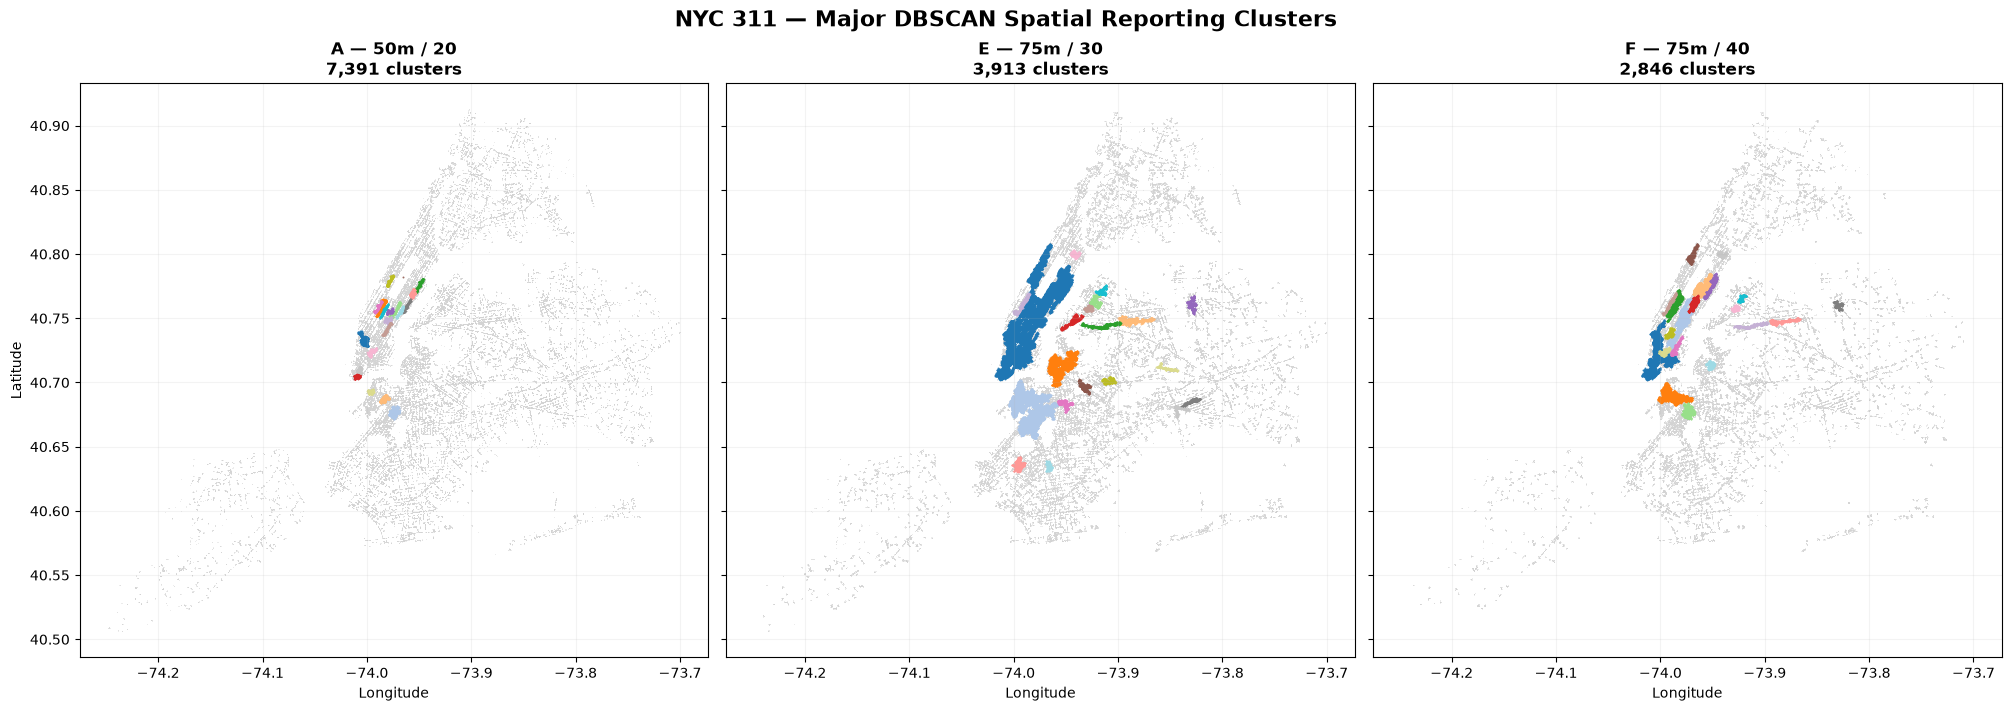


STATUS: PASSED
MAJOR CLUSTER VISUALIZATION COMPLETED


In [22]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("DBSCAN MAJOR CLUSTER GEOGRAPHIC VISUALIZATION")
print("=" * 65)

candidate_configs = {
    "A — 50m / 20": np.asarray(dbscan_labels_a),
    "E — 75m / 30": np.asarray(screening_labels["E"]),
    "F — 75m / 40": np.asarray(screening_labels["F"])
}

latitudes = dbscan_locations["latitude"].to_numpy()
longitudes = dbscan_locations["longitude"].to_numpy()
weights = np.asarray(sample_weights)

# Consistent colors for ranked top-20 clusters.
cmap = plt.get_cmap("tab20")

fig, axes = plt.subplots(
    1, 3,
    figsize=(20, 7),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

for ax, (candidate_name, labels) in zip(
    axes, candidate_configs.items()
):

    assert len(labels) == len(weights)

    clustered = labels != -1

    # Rank clusters by complaint weight.
    cluster_totals = (
        pd.DataFrame({
            "cluster_id": labels[clustered],
            "weight": weights[clustered]
        })
        .groupby("cluster_id")["weight"]
        .sum()
        .sort_values(ascending=False)
    )

    top_clusters = cluster_totals.head(20).index.tolist()

    # Draw remaining clustered locations first.
    other_mask = (
        clustered
        & ~np.isin(labels, top_clusters)
    )

    ax.scatter(
        longitudes[other_mask],
        latitudes[other_mask],
        s=0.45,
        c="lightgray",
        alpha=0.35,
        linewidths=0,
        rasterized=True
    )

    # Highlight the largest 20 clusters.
    for rank, cluster_id in enumerate(top_clusters):

        mask = labels == cluster_id

        ax.scatter(
            longitudes[mask],
            latitudes[mask],
            s=2.0,
            color=cmap(rank),
            alpha=0.85,
            linewidths=0,
            rasterized=True
        )

    ax.set_title(
        f"{candidate_name}\n"
        f"{len(cluster_totals):,} clusters",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel("Longitude")
    ax.grid(alpha=0.15)

axes[0].set_ylabel("Latitude")

fig.suptitle(
    "NYC 311 — Major DBSCAN Spatial Reporting Clusters",
    fontsize=16,
    fontweight="bold"
)

plt.show()

print("\nSTATUS: PASSED")
print("MAJOR CLUSTER VISUALIZATION COMPLETED")



##  Geographic Visualization Findings

| Aspect | Candidate A (50m/20) | Candidate E (75m/30) | Candidate F (75m/40) |
|---|---|---|---|
| Spatial Clusters | 7,391 | 3,913 | 2,846 |
| Visual Pattern | Small, localized clusters | Large connected concentrations | More separated spatial concentrations |
| Geographic Connectivity | Low | High in some areas | Lower than E in major areas |
| Fragmentation | High | Moderate | Moderate |
| Large-Cluster Merging | Limited | Substantial | Reduced relative to E |
| Complaint Noise | 41.62% | 34.00% | 47.99% |
| Preliminary Role | Fine-scale reference | Connectivity diagnostic | Primary moderate-scale candidate |


Before final DBSCAN selection, we need to revisit the geographic integrity issues discovered during our earlier K-Means analysis.

The previous audit identified recorded-borough versus coordinate-borough inconsistencies. For DBSCAN, this matters because clusters are based directly on coordinates.

We should distinguish three situations:
1. The complaint's recorded borough and coordinate-derived borough agree.
2. The complaint's recorded borough and coordinate-derived borough disagree.
3. The geographic relationship cannot be evaluated.


In [23]:

from pathlib import Path
import pandas as pd

print("GEOGRAPHIC QUALITY AUDIT FILE DISCOVERY")
print("=" * 65)

root = Path(r"D:\Urban-Infrastructure-Pulse-Intelligence")

search_dirs = [
    root / "outputs" / "tables",
    root / "outputs" / "reports",
    root / "data" / "processed",
]

keywords = [
    "geograph",
    "borough",
    "coordinate",
    "mismatch",
    "spatial",
    "zcta",
    "zip_audit",
    "location_audit",
]

matches = []

for directory in search_dirs:

    if not directory.exists():
        continue

    for path in directory.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in [
            ".csv", ".parquet", ".json", ".xlsx"
        ]:
            continue

        if any(
            word in path.name.lower()
            for word in keywords
        ):
            matches.append({
                "file": str(path.relative_to(root)),
                "size_kb": round(
                    path.stat().st_size / 1024,
                    2
                )
            })

audit_file_inventory = pd.DataFrame(matches)

print("\nGEOGRAPHIC AUDIT FILE INVENTORY")

if audit_file_inventory.empty:
    print("No matching audit filenames found.")
else:
    display(
        audit_file_inventory.sort_values(
            "file"
        ).reset_index(drop=True)
    )

print("\nFILES FOUND:", len(audit_file_inventory))

print("\nSTATUS: FILE DISCOVERY COMPLETED")


GEOGRAPHIC QUALITY AUDIT FILE DISCOVERY

GEOGRAPHIC AUDIT FILE INVENTORY


,file,size_kb
0,data\processed\nyc311_geographic_valid.csv,99023.15
1,data\processed\nyc311_infrastructure_geographi...,420503.70
2,outputs\tables\eda\borough_category_counts.csv,0.74
3,outputs\tables\eda\borough_complaint_summary.csv,0.17
4,outputs\tables\eda\borough_resolution_statisti...,0.40
5,outputs\tables\eda\coordinate_availability_by_...,0.24
6,outputs\tables\eda\coordinate_quality_summary.csv,0.22
7,outputs\tables\eda\dominant_category_by_boroug...,0.36
8,outputs\tables\eda\official_borough_category_c...,1.73
9,outputs\tables\eda\persistence_by_borough.csv,0.29



FILES FOUND: 23

STATUS: FILE DISCOVERY COMPLETED


In [24]:

from pathlib import Path
import pandas as pd

print("GEOGRAPHIC AUDIT STRUCTURE INSPECTION")
print("=" * 65)

audit_dir = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "kmeans"
)

keywords = [
    "borough_coordinate",
    "geographic_mismatch",
    "mismatch_coordinate",
    "modeled_area_zip_coordinate",
    "geographic_correction",
]

candidate_files = [
    path for path in sorted(audit_dir.glob("*.csv"))
    if any(word in path.name.lower() for word in keywords)
]

audit_schema_rows = []

print("\n1. EXACT AUDIT FILENAMES")

for path in candidate_files:

    print("\nFile:", path.name)

    # Read header only
    header = pd.read_csv(path, nrows=0)
    columns = header.columns.tolist()

    # Count data rows without loading entire file
    with open(path, "r", encoding="utf-8-sig") as f:
        row_count = sum(1 for _ in f) - 1

    print("Rows:", row_count)
    print("Columns:", columns)

    audit_schema_rows.append({
        "file": path.name,
        "rows": row_count,
        "columns": len(columns),
        "has_unique_key": "unique_key" in columns,
        "has_area_id": "area_id" in columns,
    })

print("\n2. AUDIT STRUCTURE SUMMARY")

audit_schema = pd.DataFrame(audit_schema_rows)

display(audit_schema)

print("\n3. POTENTIAL COMPLAINT-LEVEL AUDITS")

if not audit_schema.empty:

    complaint_level_candidates = audit_schema[
        audit_schema["has_unique_key"]
    ]

    display(complaint_level_candidates)

else:
    print("No matching CSV audit files found.")

print("\nSTATUS: AUDIT STRUCTURE INSPECTION COMPLETED")


GEOGRAPHIC AUDIT STRUCTURE INSPECTION

1. EXACT AUDIT FILENAMES

File: borough_coordinate_validation.csv
Rows: 956
Columns: ['incident_zip', 'borough', 'latitude', 'longitude', 'area_id', 'valid_nyc_coordinates', 'recorded_borough', 'audit_row_id', 'boroname', 'coordinate_borough', 'borough_match', 'verification_status']

File: geographic_correction_review_priorities.csv
Rows: 10
Columns: ['area_id', 'mismatched_records', 'total_complaints', 'mismatch_pct', 'k2_cluster', 'k3_cluster', 'low_support_flag', 'review_priority', 'requires_zip_validation', 'correction_approved']

File: geographic_mismatch_classification.csv
Rows: 2
Columns: ['mismatch_group', 'records', 'percentage']

File: geographic_mismatch_cluster_impact.csv
Rows: 10
Columns: ['area_id', 'mismatched_records', 'total_complaints', 'mismatch_pct', 'k2_cluster', 'k3_cluster', 'low_support_flag']

File: geographic_mismatch_records.csv
Rows: 19
Columns: ['incident_zip', 'borough', 'latitude', 'longitude', 'area_id', 'valid_nyc_

,file,rows,columns,has_unique_key,has_area_id
0,borough_coordinate_validation.csv,956,12,False,True
1,geographic_correction_review_priorities.csv,10,10,False,True
2,geographic_mismatch_classification.csv,2,3,False,False
3,geographic_mismatch_cluster_impact.csv,10,7,False,True
4,geographic_mismatch_records.csv,19,12,False,True
5,mismatch_coordinate_borough_distribution.csv,10,3,False,True
6,modeled_area_geographic_mismatches.csv,10,4,False,True
7,modeled_area_zip_coordinate_validation.csv,348,5,False,True



3. POTENTIAL COMPLAINT-LEVEL AUDITS


,file,rows,columns,has_unique_key,has_area_id



STATUS: AUDIT STRUCTURE INSPECTION COMPLETED


In [25]:

from pathlib import Path
import pandas as pd

print("GEOGRAPHIC AUDIT IDENTIFIER INSPECTION")
print("=" * 65)

audit_dir = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "kmeans"
)

target_files = [
    "borough_coordinate_validation.csv",
    "geographic_mismatch_records.csv",
    "modeled_area_zip_coordinate_validation.csv"
]

for filename in target_files:

    path = audit_dir / filename

    print("\n" + "=" * 65)
    print("FILE:", filename)

    if not path.exists():
        print("File not found.")
        continue

    audit_df = pd.read_csv(path)

    print("Rows:", len(audit_df))
    print("Columns:", len(audit_df.columns))

    print("\nCOLUMN NAMES")

    for index, column in enumerate(
        audit_df.columns, start=1
    ):
        print(f"{index:02d}. {column}")

    print("\nFIRST THREE RECORDS")

    # Print a transposed view to avoid wide tables
    display(
        audit_df.head(3).T
    )

print("\nSTATUS: IDENTIFIER INSPECTION COMPLETED")


GEOGRAPHIC AUDIT IDENTIFIER INSPECTION

FILE: borough_coordinate_validation.csv
Rows: 956
Columns: 12

COLUMN NAMES
01. incident_zip
02. borough
03. latitude
04. longitude
05. area_id
06. valid_nyc_coordinates
07. recorded_borough
08. audit_row_id
09. boroname
10. coordinate_borough
11. borough_match
12. verification_status

FIRST THREE RECORDS


,0,1,2
incident_zip,10000,10000,10000
borough,MANHATTAN,MANHATTAN,MANHATTAN
latitude,40.782369,40.782369,40.782369
longitude,-73.965238,-73.965238,-73.965238
area_id,MANHATTAN_10000,MANHATTAN_10000,MANHATTAN_10000
valid_nyc_coordinates,True,True,True
recorded_borough,MANHATTAN,MANHATTAN,MANHATTAN
audit_row_id,0,1,2
boroname,Manhattan,Manhattan,Manhattan
coordinate_borough,MANHATTAN,MANHATTAN,MANHATTAN



FILE: geographic_mismatch_records.csv
Rows: 19
Columns: 12

COLUMN NAMES
01. incident_zip
02. borough
03. latitude
04. longitude
05. area_id
06. valid_nyc_coordinates
07. recorded_borough
08. audit_row_id
09. boroname
10. coordinate_borough
11. borough_match
12. verification_status

FIRST THREE RECORDS


,0,1,2
incident_zip,11237,11237,11237
borough,QUEENS,QUEENS,QUEENS
latitude,40.707381,40.706941,40.692418
longitude,-73.918478,-73.917735,-73.902788
area_id,QUEENS_11237,QUEENS_11237,QUEENS_11237
valid_nyc_coordinates,True,True,True
recorded_borough,QUEENS,QUEENS,QUEENS
audit_row_id,35,65,243
boroname,Brooklyn,Brooklyn,Brooklyn
coordinate_borough,BROOKLYN,BROOKLYN,BROOKLYN



FILE: modeled_area_zip_coordinate_validation.csv
Rows: 348
Columns: 5

COLUMN NAMES
01. zip_audit_id
02. recorded_zip
03. coordinate_zcta
04. zip_status
05. area_id

FIRST THREE RECORDS


,0,1,2
zip_audit_id,0,1,2
recorded_zip,11237,10463,10463
coordinate_zcta,11385,10463,10463
zip_status,ZIP Mismatch,ZIP Match,ZIP Match
area_id,BROOKLYN_11237,BRONX_10463,BRONX_10463



STATUS: IDENTIFIER INSPECTION COMPLETED


In [27]:

import pandas as pd
import numpy as np

print("GEOGRAPHIC AUDIT MATCHING RELIABILITY")
print("=" * 65)

audit_path = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "kmeans"
    / "borough_coordinate_validation.csv"
)

audit = pd.read_csv(audit_path)

required_audit = [
    "latitude",
    "longitude",
    "recorded_borough",
    "verification_status"
]

required_spatial = [
    "latitude",
    "longitude",
    "borough",
    "unique_key"
]

assert set(required_audit).issubset(audit.columns)
assert set(required_spatial).issubset(df_spatial.columns)

# 1. Basic audit integrity
audit_coordinates = ["latitude", "longitude"]

audit_valid = audit.dropna(
    subset=audit_coordinates
).copy()

print("\n1. AUDIT COORDINATE STRUCTURE")

print("Audit rows:", len(audit))
print("Rows with coordinates:", len(audit_valid))

unique_coords = audit_valid[
    audit_coordinates
].drop_duplicates()

print("Unique coordinate pairs:", len(unique_coords))
print(
    "Repeated coordinate rows:",
    len(audit_valid) - len(unique_coords)
)

print("\nVerification statuses:")
print(
    audit_valid["verification_status"]
    .value_counts(dropna=False)
    .to_string()
)

# 2. Identify coordinate pairs with conflicting statuses
status_counts = (
    audit_valid
    .groupby(audit_coordinates, dropna=False)
    ["verification_status"]
    .nunique(dropna=False)
)

conflicting_coordinates = int(
    (status_counts > 1).sum()
)

print("\n2. STATUS CONSISTENCY")

print(
    "Coordinate pairs with conflicting statuses:",
    conflicting_coordinates
)

# 3. Compare coordinates to DBSCAN locations
audit_unique = unique_coords.copy()

matched_locations = audit_unique.merge(
    dbscan_locations[
        ["latitude", "longitude", "complaint_weight"]
    ],
    on=audit_coordinates,
    how="left",
    indicator=True,
    validate="one_to_one"
)

matched = matched_locations["_merge"] == "both"

print("\n3. DBSCAN COORDINATE OVERLAP")

print("Audited unique locations:", len(audit_unique))
print("Matched DBSCAN locations:", int(matched.sum()))
print("Unmatched locations:", int((~matched).sum()))

print(
    "Complaints at matched locations:",
    int(
        matched_locations.loc[
            matched, "complaint_weight"
        ].sum()
    )
)

# 4. Examine coordinate-plus-borough matching
audit_pairs = audit_valid[
    ["latitude", "longitude", "recorded_borough"]
].copy()

audit_pairs["recorded_borough"] = (
    audit_pairs["recorded_borough"]
    .astype("string")
    .str.strip()
    .str.upper()
)

audit_pairs = audit_pairs.drop_duplicates()

spatial_pairs = df_spatial[
    ["latitude", "longitude", "borough"]
].copy()

spatial_pairs["borough"] = (
    spatial_pairs["borough"]
    .astype("string")
    .str.strip()
    .str.upper()
)

spatial_pairs = spatial_pairs.drop_duplicates()

pair_matches = audit_pairs.merge(
    spatial_pairs,
    left_on=[
        "latitude", "longitude", "recorded_borough"
    ],
    right_on=[
        "latitude", "longitude", "borough"
    ],
    how="left",
    indicator=True,
    validate="one_to_one"
)

print("\n4. COORDINATE + RECORDED BOROUGH OVERLAP")

print("Unique audited coordinate-borough pairs:",
      len(audit_pairs))

print(
    "Matching DBSCAN coordinate-borough pairs:",
    int((pair_matches["_merge"] == "both").sum())
)

print(
    "Unmatched coordinate-borough pairs:",
    int((pair_matches["_merge"] != "both").sum())
)

print("\nSTATUS: AUDIT MATCHING RELIABILITY REVIEW COMPLETED")


GEOGRAPHIC AUDIT MATCHING RELIABILITY

1. AUDIT COORDINATE STRUCTURE
Audit rows: 956
Rows with coordinates: 956
Unique coordinate pairs: 78
Repeated coordinate rows: 878

Verification statuses:
verification_status
Match       937
Mismatch     19

2. STATUS CONSISTENCY
Coordinate pairs with conflicting statuses: 0

3. DBSCAN COORDINATE OVERLAP
Audited unique locations: 78
Matched DBSCAN locations: 78
Unmatched locations: 0
Complaints at matched locations: 1264

4. COORDINATE + RECORDED BOROUGH OVERLAP
Unique audited coordinate-borough pairs: 78
Matching DBSCAN coordinate-borough pairs: 78
Unmatched coordinate-borough pairs: 0

STATUS: AUDIT MATCHING RELIABILITY REVIEW COMPLETED


The exact coordinate and borough matching checks passed. That confirms that the audited geographic locations exist in our current DBSCAN dataset.

However, there are two important distinctions.

First: The 19 mismatch rows are not necessarily 19 independently identifiable complaint records. The audit contains repeated coordinates and does not preserve original complaint IDs.

Second: The 1,264 complaints at audited locations are not all geographically validated merely because their coordinates appear in the audit. Individual complaint metadata may differ.

The 78 audited locations cover approximately 0.037% of our 211,660 DBSCAN locations.

Therefore, this audit is useful as a reference for geographic quality, but it is too limited to support a citywide DBSCAN exclusion decision.


## NYC Borough Boundary Data Discovery

### Objective

Locate the original NYC borough boundary files used during previous geographic consistency analyses.

### Required Checks

- Identify local geographic boundary files.
- Determine available formats.
- Check file sizes.
- Identify candidate NYC borough polygon datasets.
- Preserve existing boundary files and geographic audit outputs.

### Planned Validation

The boundary dataset will support coordinate-to-borough spatial joins for the full DBSCAN geographic population.

Where borough information is available, we will distinguish:

- Recorded borough matching the coordinate-derived borough
- Recorded borough disagreeing with the coordinate-derived borough
- Missing or unevaluable borough information

### Important

Coordinate-based borough agreement does not establish that a location's ZIP code is correct.

Geographic review flags must not be interpreted automatically as incorrect complaint coordinates.


In [28]:

from pathlib import Path
import pandas as pd

print("NYC BOROUGH BOUNDARY FILE DISCOVERY")
print("=" * 65)

root = Path(r"D:\Urban-Infrastructure-Pulse-Intelligence")

search_directories = [
    root / "data",
    root / "outputs",
]

geo_extensions = {
    ".geojson",
    ".gpkg",
    ".shp",
    ".json",
    ".zip",
    ".parquet",
    ".feather",
}

keywords = [
    "borough",
    "boro",
    "boundary",
    "boundaries",
    "nyc",
    "zcta",
    "zip",
    "polygon",
]

rows = []

for directory in search_directories:

    if not directory.exists():
        continue

    for path in directory.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in geo_extensions:
            continue

        if not any(
            word in path.name.lower()
            for word in keywords
        ):
            continue

        rows.append({
            "file": str(path.relative_to(root)),
            "format": path.suffix.lower(),
            "size_kb": round(
                path.stat().st_size / 1024,
                2
            )
        })

boundary_inventory = pd.DataFrame(
    rows,
    columns=["file", "format", "size_kb"]
)

print("\nPOTENTIAL GEOGRAPHIC BOUNDARY FILES")

if boundary_inventory.empty:
    print("No matching local boundary files found.")
else:
    display(
        boundary_inventory.sort_values("file")
        .reset_index(drop=True)
    )

print("\nFiles found:", len(boundary_inventory))

print("\nSTATUS: BOUNDARY DISCOVERY COMPLETED")


NYC BOROUGH BOUNDARY FILE DISCOVERY

POTENTIAL GEOGRAPHIC BOUNDARY FILES
No matching local boundary files found.

Files found: 0

STATUS: BOUNDARY DISCOVERY COMPLETED


In [29]:

from pathlib import Path
import json
import re

print("ORIGINAL BOROUGH BOUNDARY SOURCE RECOVERY")
print("=" * 65)

root = Path(r"D:\Urban-Infrastructure-Pulse-Intelligence")

source_files = (
    sorted((root / "notebooks").glob("*.ipynb"))
    + sorted((root / "src").rglob("*.py"))
)

patterns = [
    r"gpd\.read_file",
    r"geopandas\.read_file",
    r"boroboundaries",
    r"borough.*geojson",
    r"borough.*shp",
    r"nyc.*boundary",
    r"nyc.*borough",
    r"spatial.*join",
    r"gpd\.sjoin",
    r"to_crs\s*\(",
    r"data\.cityofnewyork\.us",
    r"opendata",
    r"geometry",
    r"boroname",
]

matches = []

for path in source_files:

    if path.suffix == ".ipynb":

        notebook = json.loads(
            path.read_text(encoding="utf-8")
        )

        sources = [
            (
                f"Cell {i}",
                "".join(cell.get("source", []))
            )
            for i, cell in enumerate(
                notebook["cells"], start=1
            )
            if cell.get("cell_type") == "code"
        ]

    else:
        sources = [
            (
                "Python module",
                path.read_text(encoding="utf-8")
            )
        ]

    for section, source in sources:

        lines = source.splitlines()

        relevant = [
            (i + 1, line.strip())
            for i, line in enumerate(lines)
            if not line.lstrip().startswith("#")
            and any(
                re.search(pattern, line, re.IGNORECASE)
                for pattern in patterns
            )
        ]

        if relevant:
            matches.append({
                "file": str(path.relative_to(root)),
                "section": section,
                "lines": relevant
            })

print("\nMATCHING SOURCE SECTIONS:", len(matches))

for match in matches:

    print(
        f"\n{match['file']} — {match['section']}"
    )

    # Limit printed lines to avoid output truncation
    for line_no, line in match["lines"][:5]:
        print(f"  L{line_no}: {line[:160]}")

print("\nSTATUS: SOURCE CODE SEARCH COMPLETED")


ORIGINAL BOROUGH BOUNDARY SOURCE RECOVERY

MATCHING SOURCE SECTIONS: 11

notebooks\01_exploratory_data_analysis.ipynb — Cell 61
  L12: "Infrastructure Complaint Distribution Across NYC Boroughs",

notebooks\01_exploratory_data_analysis.ipynb — Cell 67
  L1: nyc_boroughs = [
  L16: borough_normalized.isin(nyc_boroughs)

notebooks\04_kmeans_clustering.ipynb — Cell 75
  L7: "https://data.cityofnewyork.us/api/v3/views/"
  L11: boroughs = gpd.read_file(boundary_url)
  L16: ["boroname", "geometry"]
  L19: boroughs = boroughs.to_crs("EPSG:4326")
  L38: geometry=gpd.points_from_xy(

notebooks\04_kmeans_clustering.ipynb — Cell 77
  L56: columns=["geometry", "index_right"],

notebooks\04_kmeans_clustering.ipynb — Cell 79
  L62: geometry=gpd.points_from_xy(
  L70: ["boroname", "geometry"]
  L71: ].to_crs("EPSG:4326")
  L73: matched_all = gpd.sjoin(
  L86: matched_all["boroname"].str.upper()

notebooks\04_kmeans_clustering.ipynb — Cell 90
  L4: "https://data.cityofnewyork.us/api/v3/views/"
  L8: z

In [30]:
from pathlib import Path
import json

print("ORIGINAL NYC BOROUGH BOUNDARY CONFIGURATION")
print("=" * 65)

notebook_path = (
    Path(r"D:\Urban-Infrastructure-Pulse-Intelligence")
    / "notebooks"
    / "04_kmeans_clustering.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

cell_number = 75

cell = notebook["cells"][cell_number - 1]

source = "".join(cell.get("source", []))
lines = source.splitlines()

print("Notebook:", notebook_path.name)
print("Cell:", cell_number)
print("Total lines:", len(lines))

print("\nBOUNDARY SOURCE AND GEOGRAPHIC OPERATIONS")
print("-" * 65)

# Print only the first 45 lines to avoid truncation.
for i, line in enumerate(lines[:45], start=1):
    print(f"{i:03d}: {line}")

print("\nSTATUS: SOURCE CONFIGURATION INSPECTED")

ORIGINAL NYC BOROUGH BOUNDARY CONFIGURATION
Notebook: 04_kmeans_clustering.ipynb
Cell: 75
Total lines: 96

BOUNDARY SOURCE AND GEOGRAPHIC OPERATIONS
-----------------------------------------------------------------
001: import geopandas as gpd
002: import pandas as pd
003: import numpy as np
004: 
005: # Official NYC borough boundaries
006: boundary_url = (
007:     "https://data.cityofnewyork.us/api/v3/views/"
008:     "gthc-hcne/query.geojson?accessType=DOWNLOAD"
009: )
010: 
011: boroughs = gpd.read_file(boundary_url)
012: 
013: boroughs.columns = boroughs.columns.str.lower()
014: 
015: boroughs = boroughs[
016:     ["boroname", "geometry"]
017: ].copy()
018: 
019: boroughs = boroughs.to_crs("EPSG:4326")
020: 
021: # Use record-level data created in Cell 46
022: records = geo.copy()
023: 
024: records["recorded_borough"] = (
025:     records["borough"].str.strip().str.upper()
026: )
027: 
028: records = records.reset_index(drop=True)
029: records["audit_row_id"] = np.arange(len(reco

In [31]:

import geopandas as gpd
from pathlib import Path

print("OFFICIAL NYC BOROUGH BOUNDARY VALIDATION")
print("=" * 65)

# Verified official NYC Open Data GeoJSON endpoint
boundary_url = (
    "https://data.cityofnewyork.us/api/v3/views/"
    "gthc-hcne/query.geojson?accessType=DOWNLOAD"
)

# Load borough polygons
boroughs = gpd.read_file(boundary_url)

# Normalize column names
boroughs.columns = boroughs.columns.str.lower()

required_columns = ["boroname", "geometry"]

missing = [
    col for col in required_columns
    if col not in boroughs.columns
]

assert not missing, f"Missing borough columns: {missing}"

boroughs = boroughs[required_columns].copy()

# Verify CRS
assert boroughs.crs is not None, (
    "Boundary CRS is undefined."
)

boroughs = boroughs.to_crs("EPSG:4326")

boroughs["boroname"] = (
    boroughs["boroname"].str.strip().str.upper()
)

expected_boroughs = {
    "BRONX",
    "BROOKLYN",
    "MANHATTAN",
    "QUEENS",
    "STATEN ISLAND",
}

assert len(boroughs) == 5
assert set(boroughs["boroname"]) == expected_boroughs
assert boroughs.geometry.notna().all()
assert boroughs.geometry.is_valid.all()
assert (~boroughs.geometry.is_empty).all()

print("\nBOUNDARY DATASET SUMMARY")
print("-" * 65)

print("Borough polygons:", len(boroughs))
print("Coordinate system:", boroughs.crs)
print("All geometries valid:", boroughs.geometry.is_valid.all())

print("\nBOROUGH NAMES")
for name in sorted(boroughs["boroname"]):
    print("-", name)

print("\nGEOGRAPHIC BOUNDS")
print(boroughs.total_bounds)

print("\nSTATUS: PASSED")
print("OFFICIAL NYC BOROUGH POLYGONS VALIDATED")


OFFICIAL NYC BOROUGH BOUNDARY VALIDATION

BOUNDARY DATASET SUMMARY
-----------------------------------------------------------------
Borough polygons: 5
Coordinate system: EPSG:4326
All geometries valid: True

BOROUGH NAMES
- BRONX
- BROOKLYN
- MANHATTAN
- QUEENS
- STATEN ISLAND

GEOGRAPHIC BOUNDS
[-74.25559136  40.49613399 -73.70000906  40.91553278]

STATUS: PASSED
OFFICIAL NYC BOROUGH POLYGONS VALIDATED


### Citywide Coordinate–Borough Consistency Audit
Objective
Determine how many DBSCAN locations and represented complaints fall into each geographic verification category.

In [32]:

import geopandas as gpd
import pandas as pd
import numpy as np

print("CITYWIDE DBSCAN COORDINATE-BOROUGH CONSISTENCY AUDIT")
print("=" * 70)

# --------------------------------------------------
# 1. Prepare complaint-level geographic observations
# --------------------------------------------------

required_columns = [
    "unique_key", "latitude", "longitude", "borough"
]

assert set(required_columns).issubset(df_spatial.columns)

geo_audit_df = df_spatial[required_columns].copy()

assert len(geo_audit_df) == 611284

assert geo_audit_df[
    ["latitude", "longitude"]
].notna().all().all()

geo_audit_df["recorded_borough"] = (
    geo_audit_df["borough"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# --------------------------------------------------
# 2. Avoid repeated polygon joins for identical coords
# --------------------------------------------------

unique_geo_points = (
    geo_audit_df[["latitude", "longitude"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

assert len(unique_geo_points) == len(dbscan_locations)

points_gdf = gpd.GeoDataFrame(
    unique_geo_points,
    geometry=gpd.points_from_xy(
        unique_geo_points["longitude"],
        unique_geo_points["latitude"]
    ),
    crs="EPSG:4326"
)

# --------------------------------------------------
# 3. Spatial join against official borough polygons
# --------------------------------------------------

borough_join = gpd.sjoin(
    points_gdf,
    boroughs[["boroname", "geometry"]],
    how="left",
    predicate="intersects"
)

# Check for boundary points intersecting multiple polygons
multiple_matches = (
    borough_join.groupby(
        ["latitude", "longitude"]
    ).size()
)

print(
    "Coordinates intersecting multiple polygons:",
    int((multiple_matches > 1).sum())
)

# Preserve ambiguity rather than arbitrarily choosing a borough
borough_candidates = (
    borough_join.groupby(
        ["latitude", "longitude"],
        as_index=False
    )
    .agg(
        coordinate_borough=(
            "boroname",
            lambda x: (
                x.dropna().iloc[0]
                if x.dropna().nunique() == 1
                else pd.NA
            )
        ),
        polygon_match_count=(
            "boroname",
            lambda x: x.dropna().nunique()
        )
    )
)

assert len(borough_candidates) == len(unique_geo_points)

# --------------------------------------------------
# 4. Attach coordinate-derived borough to complaints
# --------------------------------------------------

geo_audit_df = geo_audit_df.merge(
    borough_candidates,
    on=["latitude", "longitude"],
    how="left",
    validate="many_to_one"
)

assert len(geo_audit_df) == 611284

known_boroughs = {
    "BRONX",
    "BROOKLYN",
    "MANHATTAN",
    "QUEENS",
    "STATEN ISLAND"
}

valid_recorded = geo_audit_df[
    "recorded_borough"
].isin(known_boroughs).fillna(False)

valid_coordinate = (
    geo_audit_df["polygon_match_count"] == 1
)

match_mask = (
    valid_recorded
    & valid_coordinate
    & (
        geo_audit_df["recorded_borough"]
        == geo_audit_df["coordinate_borough"]
    ).fillna(False)
)

mismatch_mask = (
    valid_recorded
    & valid_coordinate
    & (
        geo_audit_df["recorded_borough"]
        != geo_audit_df["coordinate_borough"]
    ).fillna(False)
)

geo_audit_df["geo_status"] = np.select(
    [match_mask, mismatch_mask],
    ["Match", "Mismatch"],
    default="Unresolved"
)

# --------------------------------------------------
# 5. Complaint-level summary
# --------------------------------------------------

complaint_summary = (
    geo_audit_df["geo_status"]
    .value_counts()
    .reindex(
        ["Match", "Mismatch", "Unresolved"],
        fill_value=0
    )
    .rename_axis("geo_status")
    .reset_index(name="complaints")
)

complaint_summary["percentage"] = (
    100 * complaint_summary["complaints"]
    / len(geo_audit_df)
).round(3)

print("\n1. COMPLAINT-LEVEL GEOGRAPHIC CONSISTENCY")

display(complaint_summary)

# --------------------------------------------------
# 6. Coordinate-level summary
# --------------------------------------------------

coordinate_summary = (
    geo_audit_df
    .groupby(["latitude", "longitude"])
    .agg(
        complaints=("unique_key", "size"),
        mismatch_complaints=(
            "geo_status",
            lambda x: (x == "Mismatch").sum()
        ),
        unresolved_complaints=(
            "geo_status",
            lambda x: (x == "Unresolved").sum()
        )
    )
    .reset_index()
)

coordinate_summary["has_geo_flag"] = (
    (coordinate_summary["mismatch_complaints"] > 0)
    | (coordinate_summary["unresolved_complaints"] > 0)
)

flagged_locations = int(
    coordinate_summary["has_geo_flag"].sum()
)

flagged_complaints = int(
    coordinate_summary.loc[
        coordinate_summary["has_geo_flag"],
        "complaints"
    ].sum()
)

print("\n2. COORDINATE-LEVEL GEOGRAPHIC FLAGS")

print("Unique coordinates:", len(coordinate_summary))
print("Flagged coordinates:", flagged_locations)
print(
    "All complaints at flagged coordinates:",
    flagged_complaints
)

print(
    "Individual mismatch/unresolved complaints:",
    int(
        geo_audit_df["geo_status"]
        .ne("Match").sum()
    )
)

# --------------------------------------------------
# 7. Integrity checks
# --------------------------------------------------

assert complaint_summary["complaints"].sum() == 611284

assert len(coordinate_summary) == len(dbscan_locations)

assert coordinate_summary["complaints"].sum() == 611284

print("\nSTATUS: PASSED")
print("CITYWIDE GEOGRAPHIC CONSISTENCY AUDIT COMPLETED")


CITYWIDE DBSCAN COORDINATE-BOROUGH CONSISTENCY AUDIT
Coordinates intersecting multiple polygons: 0

1. COMPLAINT-LEVEL GEOGRAPHIC CONSISTENCY


,geo_status,complaints,percentage
0,Match,609925,99.778
1,Mismatch,348,0.057
2,Unresolved,1011,0.165



2. COORDINATE-LEVEL GEOGRAPHIC FLAGS
Unique coordinates: 211660
Flagged coordinates: 298
All complaints at flagged coordinates: 1822
Individual mismatch/unresolved complaints: 1359

STATUS: PASSED
CITYWIDE GEOGRAPHIC CONSISTENCY AUDIT COMPLETED


Our overall geographic-consistency results are encouraging, but two limitations remain.

First, DBSCAN is density-based. Even excluding a small number of complaint records can change whether a location qualifies as a core point and potentially alter connected clusters.

Second, the audit covers only geocoded complaints. The original 74,000 complaints with missing coordinates remain outside this analysis, and borough consistency does not independently validate ZIP codes or the accuracy of the physical complaint location.

Therefore, we should test DBSCAN directly before declaring the spatial clustering robust.

### DBSCAN Geographic Sensitivity Experiment

We will now refit Candidates A and F using only the 609,925 complaints classified as geographic matches.

The experiment will preserve exact coordinates, use verified complaint counts as DBSCAN sample weights, and compare the resulting clusters against the original models.

We will measure cluster counts, noise percentages, weighted noise-status changes and Adjusted Rand Index (ARI).

A high ARI indicates similar cluster partitions over retained locations. It does not establish that the clusters are externally validated infrastructure hotspots.

In [33]:

import numpy as np
import pandas as pd

from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score

print("DBSCAN GEOGRAPHIC QUALITY SENSITIVITY EXPERIMENT")
print("=" * 70)

# --------------------------------------------------
# 1. Count geographically matched complaints
# --------------------------------------------------

verified_counts = (
    geo_audit_df.loc[
        geo_audit_df["geo_status"] == "Match",
        ["latitude", "longitude"]
    ]
    .groupby(["latitude", "longitude"])
    .size()
    .rename("verified_weight")
    .reset_index()
)

# Preserve the original DBSCAN coordinate ordering
sensitivity_locations = dbscan_locations[
    ["latitude", "longitude", "complaint_weight"]
].merge(
    verified_counts,
    on=["latitude", "longitude"],
    how="left",
    sort=False,
    validate="one_to_one"
)

sensitivity_locations["verified_weight"] = (
    sensitivity_locations["verified_weight"]
    .fillna(0)
    .astype(np.int64)
)

original_weights = np.asarray(sample_weights)

verified_weights = sensitivity_locations[
    "verified_weight"
].to_numpy(dtype=np.int64)

assert np.array_equal(
    sensitivity_locations["complaint_weight"].to_numpy(),
    original_weights
)

assert len(verified_weights) == len(coords_radians)

assert np.all(verified_weights <= original_weights)

assert original_weights.sum() == 611284
assert verified_weights.sum() == 609925

# --------------------------------------------------
# 2. Keep only coordinates with matched complaints
# --------------------------------------------------

keep_mask = verified_weights > 0

filtered_coords = coords_radians[keep_mask]
filtered_weights = verified_weights[keep_mask]

print("\n1. FILTERED SPATIAL POPULATION")

print("Original complaints:", original_weights.sum())
print("Verified complaints:", filtered_weights.sum())

print(
    "Excluded complaint records:",
    original_weights.sum() - filtered_weights.sum()
)

print("Original locations:", len(coords_radians))
print("Retained locations:", len(filtered_coords))

print(
    "Fully removed locations:",
    int((~keep_mask).sum())
)

# --------------------------------------------------
# 3. Candidate configurations
# --------------------------------------------------

candidates = {
    "A": {
        "eps_m": 50,
        "min_samples": 20,
        "original_labels": np.asarray(dbscan_labels_a)
    },
    "F": {
        "eps_m": 75,
        "min_samples": 40,
        "original_labels": np.asarray(screening_labels["F"])
    }
}

sensitivity_rows = {}
dbscan_geo_refit_labels = {}

# --------------------------------------------------
# 4. Refit DBSCAN on verified complaint weights
# --------------------------------------------------

for candidate, config in candidates.items():

    print(f"\n2. REFITTING CANDIDATE {candidate}")

    eps_radians = (
        config["eps_m"] /
        (EARTH_RADIUS_KM * 1000)
    )

    model = DBSCAN(
        eps=eps_radians,
        min_samples=config["min_samples"],
        metric="haversine",
        algorithm="ball_tree",
        n_jobs=1
    )

    new_labels = model.fit_predict(
        filtered_coords,
        sample_weight=filtered_weights
    )

    original_labels = config["original_labels"]

    assert len(original_labels) == len(original_weights)

    # Compare only locations retained in both analyses
    original_retained_labels = original_labels[keep_mask]

    original_noise = original_retained_labels == -1
    new_noise = new_labels == -1

    original_clusters = len(
        set(original_labels) - {-1}
    )

    refit_clusters = len(
        set(new_labels) - {-1}
    )

    # Comparable denominator: matched complaints only
    baseline_noise_pct = (
        100 * filtered_weights[original_noise].sum()
        / filtered_weights.sum()
    )

    refit_noise_pct = (
        100 * filtered_weights[new_noise].sum()
        / filtered_weights.sum()
    )

    noise_status_changed = (
        original_noise != new_noise
    )

    changed_complaints = int(
        filtered_weights[noise_status_changed].sum()
    )

    changed_pct = (
        100 * changed_complaints
        / filtered_weights.sum()
    )

    ari = adjusted_rand_score(
        original_retained_labels,
        new_labels
    )

    sensitivity_rows[candidate] = {
        "candidate": candidate,
        "original_clusters": original_clusters,
        "refit_clusters": refit_clusters,
        "baseline_noise_pct": round(
            baseline_noise_pct, 3
        ),
        "refit_noise_pct": round(
            refit_noise_pct, 3
        ),
        "noise_changed_complaints": changed_complaints,
        "noise_changed_pct": round(changed_pct, 3),
        "ari": round(ari, 5)
    }

    # Keep labels and coordinate mask for later analysis
    dbscan_geo_refit_labels[candidate] = new_labels

    print("Original clusters:", original_clusters)
    print("Refitted clusters:", refit_clusters)
    print("ARI:", round(ari, 5))

# --------------------------------------------------
# 5. Summarize model sensitivity
# --------------------------------------------------

dbscan_geo_sensitivity_summary = pd.DataFrame(
    sensitivity_rows.values()
)

print("\n3. CLUSTER COUNT COMPARISON")

display(
    dbscan_geo_sensitivity_summary[
        [
            "candidate",
            "original_clusters",
            "refit_clusters",
            "ari"
        ]
    ]
)

print("\n4. NOISE MEMBERSHIP COMPARISON")

display(
    dbscan_geo_sensitivity_summary[
        [
            "candidate",
            "baseline_noise_pct",
            "refit_noise_pct",
            "noise_changed_complaints",
            "noise_changed_pct"
        ]
    ]
)

# --------------------------------------------------
# 6. Integrity checks
# --------------------------------------------------

assert len(dbscan_geo_sensitivity_summary) == 2

for candidate, labels in dbscan_geo_refit_labels.items():
    assert len(labels) == len(filtered_coords)

print("\nSTATUS: PASSED")
print("DBSCAN GEOGRAPHIC SENSITIVITY EXPERIMENT COMPLETED")


DBSCAN GEOGRAPHIC QUALITY SENSITIVITY EXPERIMENT

1. FILTERED SPATIAL POPULATION
Original complaints: 611284
Verified complaints: 609925
Excluded complaint records: 1359
Original locations: 211660
Retained locations: 211426
Fully removed locations: 234

2. REFITTING CANDIDATE A
Original clusters: 7391
Refitted clusters: 7369
ARI: 0.99812

2. REFITTING CANDIDATE F
Original clusters: 2846
Refitted clusters: 2833
ARI: 0.9978

3. CLUSTER COUNT COMPARISON


,candidate,original_clusters,refit_clusters,ari
0,A,7391,7369,0.99812
1,F,2846,2833,0.99780



4. NOISE MEMBERSHIP COMPARISON


,candidate,baseline_noise_pct,refit_noise_pct,noise_changed_complaints,noise_changed_pct
0,A,41.639,41.689,300,0.049
1,F,47.989,48.066,468,0.077



STATUS: PASSED
DBSCAN GEOGRAPHIC SENSITIVITY EXPERIMENT COMPLETED


Candidate A loses only 22 clusters, and Candidate F loses only 13 clusters after removing geographically inconsistent or unresolved complaint records.

For Candidate F specifically:
- The cluster count changes from 2,846 to 2,833.
- Only 468 retained complaint observations change between noise and clustered status.
- Noise increases by approximately 0.077 percentage points.
- ARI remains extremely high at 0.99780.
These findings support robustness to this specific geographic-quality filter. They do not establish robustness to other coordinate errors, parameter choices or reporting biases.


##  Final DBSCAN Model Selection

### Selected Primary Spatial Model

**Candidate F: Weighted Haversine DBSCAN**

- Epsilon: 75 meters
- Minimum weighted neighborhood count: 40
- Distance metric: Haversine
- Spatial indexing: BallTree
- Input: 211,660 unique coordinate pairs
- Sample weights: Counts of geocoded complaints
- Original geocoded complaint population: 611,284
- Selected clusters: 2,846
- Geographic sensitivity ARI: 0.99780

### Model Roles

| Model | Role |
|---|---|
| Candidate F (75m/40) | Primary moderate-scale spatial reporting model |
| Candidate A (50m/20) | Fine-scale spatial comparison |
| Candidate E (75m/30) | Cluster connectivity sensitivity |

### Selection Rationale

Candidate F provides a moderate spatial scale, fewer clusters than Candidate A, reduced concentration of clustered complaints in geographically extended clusters compared with Candidate E, and high stability under the geographic-consistency filtering experiment.

### Limitations

- Approximately 47.99% of geocoded complaints are classified as noise.
- Some clusters extend over multiple kilometers.
- 74,000 complaints without valid coordinates are excluded.
- Missing-coordinate coverage differs substantially by complaint category.
- Repeated coordinate counts may include geocoding artifacts.
- Spatial reporting intensity is not equivalent to infrastructure damage or validated risk.
- No external ground-truth hotspot validation has been performed.

### Decision

Candidate F is selected as the primary descriptive DBSCAN configuration for the project.

This selection does not replace the K-Means reporting-pattern model, which addresses a different analytical objective.


In [34]:

import numpy as np
import pandas as pd

print("FINAL DBSCAN MODEL SELECTION")
print("=" * 65)

# Primary spatial reporting model
selected_dbscan_config = {
    "candidate": "F",
    "eps_meters": 75,
    "min_samples": 40,
    "metric": "haversine",
    "algorithm": "ball_tree",
    "sample_weight": "complaint_weight",
    "model_role": "primary_descriptive_spatial",
    "selection_status": "selected",
    "validated_scope": "geographic_quality_sensitivity"
}

# Preserve the original full-population labels
selected_dbscan_labels = np.asarray(
    screening_labels["F"]
).copy()

# Confirm input alignment
assert len(selected_dbscan_labels) == len(dbscan_locations)
assert len(selected_dbscan_labels) == len(sample_weights)

assert int(np.sum(sample_weights)) == 611284

# Calculate primary model results
selected_cluster_mask = selected_dbscan_labels != -1
selected_noise_mask = ~selected_cluster_mask

selected_cluster_count = len(
    set(selected_dbscan_labels) - {-1}
)

selected_clustered_complaints = int(
    np.asarray(sample_weights)[selected_cluster_mask].sum()
)

selected_noise_complaints = int(
    np.asarray(sample_weights)[selected_noise_mask].sum()
)

selected_noise_pct = (
    100 * selected_noise_complaints
    / np.asarray(sample_weights).sum()
)

# Retrieve geographic sensitivity result
f_sensitivity = (
    dbscan_geo_sensitivity_summary
    .set_index("candidate")
    .loc["F"]
)

assert selected_cluster_count == 2846

final_dbscan_summary = pd.DataFrame([{
    "selected_candidate": "F",
    "eps_meters": 75,
    "min_samples": 40,
    "unique_locations": len(selected_dbscan_labels),
    "total_complaints": int(np.sum(sample_weights)),
    "clusters": selected_cluster_count,
    "clustered_complaints": selected_clustered_complaints,
    "noise_complaints": selected_noise_complaints,
    "noise_pct": round(selected_noise_pct, 3),
    "geographic_sensitivity_ari": float(
        f_sensitivity["ari"]
    ),
    "model_role": "primary_descriptive_spatial"
}])

print("\nSELECTED MODEL SUMMARY")
display(final_dbscan_summary.T)

print("\nSTATUS: PASSED")
print("CANDIDATE F SELECTED AS PRIMARY DBSCAN MODEL")
print("NO FILES OVERWRITTEN")


FINAL DBSCAN MODEL SELECTION

SELECTED MODEL SUMMARY


,0
selected_candidate,F
eps_meters,75
min_samples,40
unique_locations,211660
total_complaints,611284
clusters,2846
clustered_complaints,317936
noise_complaints,293348
noise_pct,47.989
geographic_sensitivity_ari,0.9978



STATUS: PASSED
CANDIDATE F SELECTED AS PRIMARY DBSCAN MODEL
NO FILES OVERWRITTEN


In [35]:

from pathlib import Path
import numpy as np
import pandas as pd

print(" DBSCAN COORDINATE ASSIGNMENT EXPORT")
print("=" * 70)

# 1. Selected model: Candidate F
labels = np.asarray(screening_labels["F"], dtype=np.int64)

assignments = dbscan_locations[
    ["latitude", "longitude", "complaint_weight"]
].copy().reset_index(drop=True)

assignments["dbscan_cluster_id"] = labels
assignments["is_noise"] = labels == -1

# 2. Verify input alignment and clustering results
assert len(assignments) == 211660
assert len(labels) == len(assignments)
assert assignments["complaint_weight"].sum() == 611284

assert not assignments[
    ["latitude", "longitude"]
].duplicated().any()

clustered_mask = ~assignments["is_noise"]
noise_mask = assignments["is_noise"]

cluster_count = assignments.loc[
    clustered_mask, "dbscan_cluster_id"
].nunique()

clustered_complaints = int(
    assignments.loc[
        clustered_mask, "complaint_weight"
    ].sum()
)

noise_complaints = int(
    assignments.loc[
        noise_mask, "complaint_weight"
    ].sum()
)

assert cluster_count == 2846
assert clustered_complaints == 317936
assert noise_complaints == 293348

# 3. Prepare output directory
output_dir = (
    PROJECT_ROOT / "outputs" / "tables" / "dbscan"
)
output_dir.mkdir(parents=True, exist_ok=True)

output_file = (
    output_dir
    / "dbscan_primary_f_coordinate_assignments.csv"
)

# 4. Export safely
if output_file.exists():
    print("\nExisting file detected. Verifying contents.")
else:
    assignments.to_csv(
        output_file,
        index=False,
        float_format="%.15g"
    )
    print("\nNew export created.")

# 5. Verify saved file
saved = pd.read_csv(output_file)

pd.testing.assert_frame_equal(
    assignments,
    saved,
    check_dtype=False,
    check_exact=False,
    rtol=0,
    atol=1e-9
)

# Preserve notebook variable for profiling
dbscan_coordinate_assignments = assignments

# 6. Summary
print("\nEXPORT SUMMARY")
print("-" * 70)
print("File:", output_file)
print("Unique locations:", len(assignments))
print("Clusters:", cluster_count)
print("Clustered complaints:", clustered_complaints)
print("Noise complaints:", noise_complaints)
print("Noise percentage:",
      round(100 * noise_complaints / 611284, 3))

print("\nSAMPLE RECORDS")
display(assignments.head(10))

print("\nSTATUS: PASSED")
print("DBSCAN COORDINATE ASSIGNMENTS VERIFIED")


 DBSCAN COORDINATE ASSIGNMENT EXPORT

New export created.

EXPORT SUMMARY
----------------------------------------------------------------------
File: D:\Urban-Infrastructure-Pulse-Intelligence\outputs\tables\dbscan\dbscan_primary_f_coordinate_assignments.csv
Unique locations: 211660
Clusters: 2846
Clustered complaints: 317936
Noise complaints: 293348
Noise percentage: 47.989

SAMPLE RECORDS


,latitude,longitude,complaint_weight,dbscan_cluster_id,is_noise
0,40.498807,-74.241495,1,-1,True
1,40.498949,-74.244365,8,-1,True
2,40.499122,-74.241597,1,-1,True
3,40.499135,-74.243485,3,-1,True
4,40.499268,-74.242878,1,-1,True
5,40.499308,-74.240688,2,-1,True
6,40.499309,-74.242623,4,-1,True
7,40.499313,-74.239750,1,-1,True
8,40.499415,-74.244536,1,-1,True
9,40.499445,-74.241943,2,-1,True



STATUS: PASSED
DBSCAN COORDINATE ASSIGNMENTS VERIFIED


### Generate Basic Spatial Hotspot Profiles

In [36]:

import pandas as pd
import numpy as np

print(" — DBSCAN SPATIAL HOTSPOT PROFILES")
print("=" * 70)

# --------------------------------------------------
# 1. Select clustered coordinates
# --------------------------------------------------

cluster_points = dbscan_coordinate_assignments.loc[
    ~dbscan_coordinate_assignments["is_noise"]
].copy()

assert cluster_points["complaint_weight"].sum() == 317936

# Weighted coordinate components
cluster_points["weighted_latitude"] = (
    cluster_points["latitude"]
    * cluster_points["complaint_weight"]
)

cluster_points["weighted_longitude"] = (
    cluster_points["longitude"]
    * cluster_points["complaint_weight"]
)

# --------------------------------------------------
# 2. Aggregate cluster characteristics
# --------------------------------------------------

dbscan_spatial_profiles = (
    cluster_points
    .groupby("dbscan_cluster_id")
    .agg(
        unique_locations=("latitude", "size"),
        total_complaints=("complaint_weight", "sum"),
        latitude_min=("latitude", "min"),
        latitude_max=("latitude", "max"),
        longitude_min=("longitude", "min"),
        longitude_max=("longitude", "max"),
        weighted_latitude_sum=(
            "weighted_latitude", "sum"
        ),
        weighted_longitude_sum=(
            "weighted_longitude", "sum"
        )
    )
    .reset_index()
)

# --------------------------------------------------
# 3. Weighted geographic center
# --------------------------------------------------

dbscan_spatial_profiles["center_latitude"] = (
    dbscan_spatial_profiles["weighted_latitude_sum"]
    / dbscan_spatial_profiles["total_complaints"]
)

dbscan_spatial_profiles["center_longitude"] = (
    dbscan_spatial_profiles["weighted_longitude_sum"]
    / dbscan_spatial_profiles["total_complaints"]
)

# --------------------------------------------------
# 4. Approximate geographic extent
# --------------------------------------------------

dbscan_spatial_profiles["north_south_km"] = (
    (
        dbscan_spatial_profiles["latitude_max"]
        - dbscan_spatial_profiles["latitude_min"]
    ) * 111.2
)

mean_lat = (
    dbscan_spatial_profiles["latitude_min"]
    + dbscan_spatial_profiles["latitude_max"]
) / 2

dbscan_spatial_profiles["east_west_km"] = (
    (
        dbscan_spatial_profiles["longitude_max"]
        - dbscan_spatial_profiles["longitude_min"]
    )
    * 111.2
    * np.cos(np.radians(mean_lat))
)

dbscan_spatial_profiles["max_axis_extent_km"] = (
    dbscan_spatial_profiles[
        ["north_south_km", "east_west_km"]
    ].max(axis=1)
)

# --------------------------------------------------
# 5. Complaint concentration metrics
# --------------------------------------------------

dbscan_spatial_profiles["share_geocoded_pct"] = (
    100
    * dbscan_spatial_profiles["total_complaints"]
    / 611284
)

dbscan_spatial_profiles["share_clustered_pct"] = (
    100
    * dbscan_spatial_profiles["total_complaints"]
    / 317936
)

dbscan_spatial_profiles["complaint_rank"] = (
    dbscan_spatial_profiles["total_complaints"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Remove intermediate calculation columns
dbscan_spatial_profiles = dbscan_spatial_profiles.drop(
    columns=[
        "weighted_latitude_sum",
        "weighted_longitude_sum"
    ]
)

# --------------------------------------------------
# 6. Verify cluster profiles
# --------------------------------------------------

assert len(dbscan_spatial_profiles) == 2846

assert (
    dbscan_spatial_profiles["total_complaints"].sum()
    == 317936
)

assert (
    dbscan_spatial_profiles["unique_locations"].sum()
    == len(cluster_points)
)

assert dbscan_spatial_profiles[
    "dbscan_cluster_id"
].is_unique

# --------------------------------------------------
# 7. Display hotspot summary
# --------------------------------------------------

print("\nSPATIAL CLUSTER SUMMARY")
print("-" * 70)

print("Total clusters:", len(dbscan_spatial_profiles))

print(
    "Median complaints per cluster:",
    dbscan_spatial_profiles["total_complaints"].median()
)

print(
    "Median unique locations:",
    dbscan_spatial_profiles["unique_locations"].median()
)

print(
    "Median maximum-axis extent (km):",
    round(
        dbscan_spatial_profiles[
            "max_axis_extent_km"
        ].median(), 3
    )
)

print("\nTOP 10 CLUSTERS BY COMPLAINT COUNT")

top_10_clusters = (
    dbscan_spatial_profiles
    .sort_values(
        "total_complaints",
        ascending=False
    )
    .head(10)
)

display(
    top_10_clusters[
        [
            "dbscan_cluster_id",
            "unique_locations",
            "total_complaints",
            "center_latitude",
            "center_longitude",
            "max_axis_extent_km",
            "share_geocoded_pct"
        ]
    ].round(4)
)

# --------------------------------------------------
# 8. Save profiles safely
# --------------------------------------------------

output_file = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "dbscan"
    / "dbscan_primary_f_spatial_cluster_profiles.csv"
)

if output_file.exists():
    existing = pd.read_csv(output_file)

    pd.testing.assert_frame_equal(
        existing,
        dbscan_spatial_profiles,
        check_dtype=False,
        check_exact=False,
        rtol=1e-10,
        atol=1e-9
    )
    print("\nExisting profile export verified.")

else:
    dbscan_spatial_profiles.to_csv(
        output_file,
        index=False,
        float_format="%.15g"
    )
    print("\nNew profile export created.")

print("\nOutput:", output_file)
print("\nSTATUS: PASSED")
print("DBSCAN SPATIAL HOTSPOT PROFILES COMPLETED")


 — DBSCAN SPATIAL HOTSPOT PROFILES

SPATIAL CLUSTER SUMMARY
----------------------------------------------------------------------
Total clusters: 2846
Median complaints per cluster: 65.0
Median unique locations: 15.0
Median maximum-axis extent (km): 0.161

TOP 10 CLUSTERS BY COMPLAINT COUNT


,dbscan_cluster_id,unique_locations,total_complaints,center_latitude,center_longitude,max_axis_extent_km,share_geocoded_pct
1421,1421,3748,12773,40.7201,-74.0029,5.1640,2.0895
1686,1686,1906,7066,40.7466,-73.9801,4.6645,1.1559
1167,1167,2076,6879,40.6894,-73.9880,2.7143,1.1253
2154,2154,1356,4850,40.7744,-73.9587,2.0693,0.7934
1927,1927,844,3617,40.7603,-73.9859,2.7535,0.5917
993,993,861,2533,40.6776,-73.9733,1.3846,0.4144
2020,2020,506,2117,40.7612,-73.9684,1.4364,0.3463
1901,1901,539,1947,40.7478,-73.8819,2.3876,0.3185
2141,2141,547,1933,40.7756,-73.9508,2.2172,0.3162
1871,1871,407,1789,40.7443,-73.9141,2.6759,0.2927



New profile export created.

Output: D:\Urban-Infrastructure-Pulse-Intelligence\outputs\tables\dbscan\dbscan_primary_f_spatial_cluster_profiles.csv

STATUS: PASSED
DBSCAN SPATIAL HOTSPOT PROFILES COMPLETED


### Dominant Infrastructure Complaint Categories

In [37]:

import pandas as pd
import numpy as np

print(" — DBSCAN COMPLAINT CATEGORY PROFILING")
print("=" * 70)

# --------------------------------------------------
# 1. Identify complaint category column
# --------------------------------------------------

category_candidates = [
    "complaint_type",
    "complaint_category",
    "category"
]

category_col = next(
    (c for c in category_candidates if c in df_spatial.columns),
    None
)

if category_col is None:
    raise ValueError(
        "Complaint category column not found. "
        f"Available columns: {df_spatial.columns.tolist()}"
    )

print("\nCategory column:", category_col)

# --------------------------------------------------
# 2. Attach cluster IDs to original complaints
# --------------------------------------------------

complaint_clusters = df_spatial[
    ["latitude", "longitude", category_col]
].merge(
    dbscan_coordinate_assignments[
        ["latitude", "longitude", "dbscan_cluster_id"]
    ],
    on=["latitude", "longitude"],
    how="left",
    validate="many_to_one",
    indicator=True
)

assert len(complaint_clusters) == 611284
assert (complaint_clusters["_merge"] == "both").all()

complaint_clusters = complaint_clusters.drop(
    columns="_merge"
)

complaint_clusters["dbscan_cluster_id"] = (
    complaint_clusters["dbscan_cluster_id"].astype(int)
)

# Normalize category labels
complaint_clusters["complaint_category"] = (
    complaint_clusters[category_col]
    .astype("string")
    .str.strip()
    .str.upper()
    .replace("", pd.NA)
    .fillna("UNKNOWN")
)

# --------------------------------------------------
# 3. Retain complaints within established clusters
# --------------------------------------------------

clustered_complaints = complaint_clusters[
    complaint_clusters["dbscan_cluster_id"] != -1
].copy()

assert len(clustered_complaints) == 317936

print("\nClustered complaints:", len(clustered_complaints))

print(
    "Distinct complaint categories:",
    clustered_complaints["complaint_category"].nunique()
)

print(
    "Unknown category complaints:",
    int(
        (clustered_complaints["complaint_category"] == "UNKNOWN").sum()
    )
)

# --------------------------------------------------
# 4. Complaint counts by cluster and category
# --------------------------------------------------

dbscan_category_counts = (
    clustered_complaints
    .groupby(
        ["dbscan_cluster_id", "complaint_category"]
    )
    .size()
    .reset_index(name="category_complaints")
)

dbscan_category_counts = (
    dbscan_category_counts.sort_values(
        [
            "dbscan_cluster_id",
            "category_complaints",
            "complaint_category"
        ],
        ascending=[True, False, True]
    ).reset_index(drop=True)
)

dbscan_category_counts["category_rank"] = (
    dbscan_category_counts
    .groupby("dbscan_cluster_id")
    .cumcount() + 1
)

# --------------------------------------------------
# 5. Identify dominant complaint category
# --------------------------------------------------

dominant = (
    dbscan_category_counts[
        dbscan_category_counts["category_rank"] == 1
    ]
    [
        [
            "dbscan_cluster_id",
            "complaint_category",
            "category_complaints"
        ]
    ]
    .rename(columns={
        "complaint_category": "dominant_category",
        "category_complaints": "dominant_category_complaints"
    })
)

category_diversity = (
    dbscan_category_counts
    .groupby("dbscan_cluster_id")
    .size()
    .rename("distinct_categories")
    .reset_index()
)

# --------------------------------------------------
# 6. Build hotspot category profile
# --------------------------------------------------

dbscan_category_profiles = (
    dbscan_spatial_profiles[
        ["dbscan_cluster_id", "total_complaints"]
    ]
    .merge(
        dominant,
        on="dbscan_cluster_id",
        validate="one_to_one"
    )
    .merge(
        category_diversity,
        on="dbscan_cluster_id",
        validate="one_to_one"
    )
)

dbscan_category_profiles["dominant_category_pct"] = (
    100
    * dbscan_category_profiles["dominant_category_complaints"]
    / dbscan_category_profiles["total_complaints"]
).round(2)

# --------------------------------------------------
# 7. Validate category totals
# --------------------------------------------------

assert len(dbscan_category_profiles) == 2846

assert (
    dbscan_category_profiles["total_complaints"].sum()
    == 317936
)

assert (
    dbscan_category_counts["category_complaints"].sum()
    == 317936
)

category_totals = (
    dbscan_category_counts
    .groupby("dbscan_cluster_id")["category_complaints"]
    .sum()
    .sort_index()
)

spatial_totals = (
    dbscan_spatial_profiles
    .set_index("dbscan_cluster_id")["total_complaints"]
    .sort_index()
)

pd.testing.assert_series_equal(
    category_totals,
    spatial_totals,
    check_names=False
)

# --------------------------------------------------
# 8. Display largest hotspots
# --------------------------------------------------

print("\nTOP 10 HOTSPOTS — DOMINANT COMPLAINT CATEGORIES")

top_categories = (
    dbscan_category_profiles
    .sort_values("total_complaints", ascending=False)
    .head(10)
)

display(top_categories)

print("\nOVERALL CATEGORY DISTRIBUTION IN CLUSTERS")

overall_categories = (
    clustered_complaints["complaint_category"]
    .value_counts()
    .rename_axis("complaint_category")
    .reset_index(name="complaints")
)

display(overall_categories)

# --------------------------------------------------
# 9. Export safely
# --------------------------------------------------

output_dir = (
    PROJECT_ROOT / "outputs" / "tables" / "dbscan"
)

output_dir.mkdir(parents=True, exist_ok=True)

exports = {
    "dbscan_primary_f_category_profiles.csv":
        dbscan_category_profiles,
    "dbscan_primary_f_category_counts.csv":
        dbscan_category_counts
}

for filename, frame in exports.items():

    path = output_dir / filename

    if path.exists():
        existing = pd.read_csv(path)

        pd.testing.assert_frame_equal(
            existing,
            frame,
            check_dtype=False,
            check_exact=False,
            rtol=0,
            atol=1e-9
        )

        print("\nExisting export verified:", filename)

    else:
        frame.to_csv(path, index=False)
        print("\nExport created:", filename)

print("\nSTATUS: PASSED")
print("DBSCAN CATEGORY PROFILING COMPLETED")


 — DBSCAN COMPLAINT CATEGORY PROFILING

Category column: complaint_type

Clustered complaints: 317936
Distinct complaint categories: 15
Unknown category complaints: 0

TOP 10 HOTSPOTS — DOMINANT COMPLAINT CATEGORIES


,dbscan_cluster_id,total_complaints,dominant_category,dominant_category_complaints,distinct_categories,dominant_category_pct
1421,1421,12773,STREET CONDITION,3870,14,30.30
1686,1686,7066,STREET CONDITION,2792,13,39.51
1167,1167,6879,STREET CONDITION,1616,13,23.49
2154,2154,4850,STREET CONDITION,1545,14,31.86
1927,1927,3617,STREET CONDITION,1171,13,32.37
993,993,2533,STREET CONDITION,623,13,24.60
2020,2020,2117,STREET CONDITION,966,11,45.63
1901,1901,1947,TRAFFIC SIGNAL CONDITION,699,13,35.90
2141,2141,1933,STREET CONDITION,717,11,37.09
1871,1871,1789,TRAFFIC SIGNAL CONDITION,727,12,40.64



OVERALL CATEGORY DISTRIBUTION IN CLUSTERS


,complaint_category,complaints
0,TRAFFIC SIGNAL CONDITION,89288
1,STREET CONDITION,81134
2,STREET LIGHT CONDITION,45571
3,SIDEWALK CONDITION,34801
4,SEWER,32139
5,CURB CONDITION,9852
6,ROOT/SEWER/SIDEWALK CONDITION,6815
7,STREET SIGN - DAMAGED,6547
8,STREET SIGN - MISSING,4718
9,STREET SIGN - DANGLING,4426



Export created: dbscan_primary_f_category_profiles.csv

Export created: dbscan_primary_f_category_counts.csv

STATUS: PASSED
DBSCAN CATEGORY PROFILING COMPLETED


The largest hotspots contain multiple infrastructure complaint types.

For example, Cluster 1421 has 12,773 complaints, but only 30.30% belong to its dominant category, Street Condition.

Across all 2,846 clusters, the median dominant-category share is only 41.18%.

This means our future recommendation engine should not suggest repairs based on the dominant category alone. It should inspect category composition, recurrence, recent trends and resolution history.

### Borough Distribution of DBSCAN Hotspots

We will use the coordinate-derived boroughs from our validated geographic audit, rather than relying only on recorded borough names.

This matters because a DBSCAN cluster can cross a borough boundary.

In [38]:

import pandas as pd
import numpy as np

print(" DBSCAN BOROUGH PROFILING")
print("=" * 70)

# --------------------------------------------------
# 1. Verify required notebook objects
# --------------------------------------------------

required_audit_columns = [
    "latitude", "longitude",
    "coordinate_borough", "geo_status"
]

assert set(required_audit_columns).issubset(
    geo_audit_df.columns
)

assert len(geo_audit_df) == 611284
assert len(dbscan_spatial_profiles) == 2846

# --------------------------------------------------
# 2. Attach DBSCAN assignments to complaint records
# --------------------------------------------------

geo_clustered = geo_audit_df[
    required_audit_columns
].merge(
    dbscan_coordinate_assignments[
        ["latitude", "longitude", "dbscan_cluster_id"]
    ],
    on=["latitude", "longitude"],
    how="left",
    validate="many_to_one",
    indicator=True
)

assert len(geo_clustered) == 611284
assert (geo_clustered["_merge"] == "both").all()

geo_clustered = geo_clustered.drop(columns="_merge")

geo_clustered["coordinate_borough"] = (
    geo_clustered["coordinate_borough"]
    .astype("string")
    .str.strip()
    .str.upper()
    .fillna("UNMAPPED")
)

# Only established DBSCAN clusters
clustered_geo = geo_clustered.loc[
    geo_clustered["dbscan_cluster_id"] != -1
].copy()

assert len(clustered_geo) == 317936

# --------------------------------------------------
# 3. Count complaints by cluster and borough
# --------------------------------------------------

dbscan_borough_counts = (
    clustered_geo
    .groupby(
        ["dbscan_cluster_id", "coordinate_borough"]
    )
    .size()
    .reset_index(name="borough_complaints")
    .sort_values(
        [
            "dbscan_cluster_id",
            "borough_complaints",
            "coordinate_borough"
        ],
        ascending=[True, False, True]
    )
    .reset_index(drop=True)
)

dbscan_borough_counts["borough_rank"] = (
    dbscan_borough_counts
    .groupby("dbscan_cluster_id")
    .cumcount() + 1
)

# --------------------------------------------------
# 4. Primary geographic borough
# --------------------------------------------------

primary_borough = (
    dbscan_borough_counts.loc[
        dbscan_borough_counts["borough_rank"] == 1,
        [
            "dbscan_cluster_id",
            "coordinate_borough",
            "borough_complaints"
        ]
    ]
    .rename(columns={
        "coordinate_borough": "primary_borough",
        "borough_complaints": "primary_borough_complaints"
    })
)

valid_boroughs = {
    "BRONX", "BROOKLYN", "MANHATTAN",
    "QUEENS", "STATEN ISLAND"
}

mapped_counts = (
    dbscan_borough_counts.loc[
        dbscan_borough_counts[
            "coordinate_borough"
        ].isin(valid_boroughs)
    ]
    .groupby("dbscan_cluster_id")
    .size()
    .rename("mapped_borough_count")
)

# --------------------------------------------------
# 5. Geographic quality counts per cluster
# --------------------------------------------------

quality_counts = (
    clustered_geo.assign(
        is_mismatch=(
            clustered_geo["geo_status"] == "Mismatch"
        ),
        is_unresolved=(
            clustered_geo["geo_status"] == "Unresolved"
        ),
        is_unmapped=(
            clustered_geo["coordinate_borough"] == "UNMAPPED"
        )
    )
    .groupby("dbscan_cluster_id")
    .agg(
        mismatch_complaints=("is_mismatch", "sum"),
        unresolved_complaints=("is_unresolved", "sum"),
        unmapped_complaints=("is_unmapped", "sum")
    )
    .reset_index()
)

# --------------------------------------------------
# 6. Build borough-level hotspot profiles
# --------------------------------------------------

dbscan_borough_profiles = (
    dbscan_spatial_profiles[
        ["dbscan_cluster_id", "total_complaints"]
    ]
    .merge(
        primary_borough,
        on="dbscan_cluster_id",
        validate="one_to_one"
    )
    .merge(
        mapped_counts,
        on="dbscan_cluster_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        quality_counts,
        on="dbscan_cluster_id",
        validate="one_to_one"
    )
)

dbscan_borough_profiles["mapped_borough_count"] = (
    dbscan_borough_profiles["mapped_borough_count"]
    .fillna(0).astype(int)
)

dbscan_borough_profiles["cross_borough"] = (
    dbscan_borough_profiles["mapped_borough_count"] > 1
)

dbscan_borough_profiles["primary_borough_pct"] = (
    100
    * dbscan_borough_profiles["primary_borough_complaints"]
    / dbscan_borough_profiles["total_complaints"]
).round(2)

# --------------------------------------------------
# 7. Integrity checks
# --------------------------------------------------

assert len(dbscan_borough_profiles) == 2846

assert (
    dbscan_borough_counts["borough_complaints"].sum()
    == 317936
)

assert (
    dbscan_borough_profiles["total_complaints"].sum()
    == 317936
)

borough_totals = (
    dbscan_borough_counts
    .groupby("dbscan_cluster_id")["borough_complaints"]
    .sum()
    .sort_index()
)

profile_totals = (
    dbscan_borough_profiles
    .set_index("dbscan_cluster_id")["total_complaints"]
    .sort_index()
)

pd.testing.assert_series_equal(
    borough_totals,
    profile_totals,
    check_names=False
)

# --------------------------------------------------
# 8. Display summaries
# --------------------------------------------------

print("\nBOROUGH PROFILE SUMMARY")
print("-" * 70)

print("Profiled clusters:", len(dbscan_borough_profiles))

print(
    "Clusters containing multiple mapped boroughs:",
    int(dbscan_borough_profiles["cross_borough"].sum())
)

print(
    "Mismatch complaints in clusters:",
    int(dbscan_borough_profiles["mismatch_complaints"].sum())
)

print(
    "Unresolved complaints in clusters:",
    int(dbscan_borough_profiles["unresolved_complaints"].sum())
)

print("\nTOP 10 HOTSPOTS — BOROUGH DISTRIBUTION")

display(
    dbscan_borough_profiles
    .sort_values("total_complaints", ascending=False)
    .head(10)
    .round(2)
)

print("\nOVERALL BOROUGH DISTRIBUTION")

overall_borough_counts = (
    clustered_geo["coordinate_borough"]
    .value_counts()
    .rename_axis("borough")
    .reset_index(name="clustered_complaints")
)

display(overall_borough_counts)

# --------------------------------------------------
# 9. Export safely
# --------------------------------------------------

output_dir = (
    PROJECT_ROOT / "outputs" / "tables" / "dbscan"
)

output_dir.mkdir(parents=True, exist_ok=True)

exports = {
    "dbscan_primary_f_borough_profiles.csv":
        dbscan_borough_profiles,
    "dbscan_primary_f_borough_counts.csv":
        dbscan_borough_counts
}

for filename, frame in exports.items():

    path = output_dir / filename

    if path.exists():

        existing = pd.read_csv(path)

        pd.testing.assert_frame_equal(
            existing,
            frame,
            check_dtype=False,
            check_exact=False,
            rtol=0,
            atol=1e-9
        )

        print("\nExisting export verified:", filename)

    else:

        frame.to_csv(path, index=False)
        print("\nExport created:", filename)

print("\nSTATUS: PASSED")
print("DBSCAN BOROUGH PROFILING COMPLETED")


 DBSCAN BOROUGH PROFILING

BOROUGH PROFILE SUMMARY
----------------------------------------------------------------------
Profiled clusters: 2846
Clusters containing multiple mapped boroughs: 14
Mismatch complaints in clusters: 229
Unresolved complaints in clusters: 478

TOP 10 HOTSPOTS — BOROUGH DISTRIBUTION


,dbscan_cluster_id,total_complaints,primary_borough,primary_borough_complaints,mapped_borough_count,mismatch_complaints,unresolved_complaints,unmapped_complaints,cross_borough,primary_borough_pct
1421,1421,12773,MANHATTAN,12773,1,0,7,0,False,100.0
1686,1686,7066,MANHATTAN,7066,1,0,1,0,False,100.0
1167,1167,6879,BROOKLYN,6879,1,0,1,0,False,100.0
2154,2154,4850,MANHATTAN,4850,1,0,2,0,False,100.0
1927,1927,3617,MANHATTAN,3617,1,0,1,0,False,100.0
993,993,2533,BROOKLYN,2533,1,0,2,0,False,100.0
2020,2020,2117,MANHATTAN,2117,1,0,3,0,False,100.0
1901,1901,1947,QUEENS,1947,1,0,1,0,False,100.0
2141,2141,1933,MANHATTAN,1933,1,0,0,0,False,100.0
1871,1871,1789,QUEENS,1789,1,0,0,0,False,100.0



OVERALL BOROUGH DISTRIBUTION


,borough,clustered_complaints
0,BROOKLYN,111801
1,QUEENS,82560
2,MANHATTAN,80712
3,BRONX,31883
4,STATEN ISLAND,10699
5,UNMAPPED,281



Export created: dbscan_primary_f_borough_profiles.csv

Export created: dbscan_primary_f_borough_counts.csv

STATUS: PASSED
DBSCAN BOROUGH PROFILING COMPLETED


In [39]:

import pandas as pd

print(" TEMPORAL & RECURRENCE FIELD INSPECTION")
print("=" * 70)

# --------------------------------------------------
# 1. Inspect available fields
# --------------------------------------------------

keywords = [
    "date",
    "time",
    "created",
    "closed",
    "resolution",
    "repeat",
    "recurr",
    "persistent",
    "status",
    "location",
    "address"
]

relevant_columns = [
    col for col in df_spatial.columns
    if any(word in col.lower() for word in keywords)
]

print("\n1. RELEVANT SOURCE COLUMNS")

field_rows = []

for col in relevant_columns:

    series = df_spatial[col]

    examples = (
        series.dropna()
        .astype(str)
        .head(2)
        .tolist()
    )

    field_rows.append({
        "column": col,
        "dtype": str(series.dtype),
        "missing_pct": round(
            100 * series.isna().mean(), 2
        ),
        "sample_values": " | ".join(examples)[:100]
    })

temporal_field_inventory = pd.DataFrame(field_rows)

display(temporal_field_inventory)

# --------------------------------------------------
# 2. Check complaint identifiers
# --------------------------------------------------

print("\n2. COMPLAINT IDENTIFIER CHECK")

print("Total geographic records:", len(df_spatial))

print("unique_key available:",
      "unique_key" in df_spatial.columns)

if "unique_key" in df_spatial.columns:
    print(
        "Unique complaint IDs:",
        df_spatial["unique_key"].nunique()
    )

# --------------------------------------------------
# 3. Inspect date availability
# --------------------------------------------------

date_columns = [
    col for col in df_spatial.columns
    if (
        "date" in col.lower()
        or "created" in col.lower()
        or "timestamp" in col.lower()
    )
]

print("\n3. DATE COLUMN CANDIDATES")

for col in date_columns:
    print(
        f"{col}: "
        f"{df_spatial[col].notna().sum():,} non-null records"
    )

# --------------------------------------------------
# 4. Inspect recurrence-related fields
# --------------------------------------------------

recurrence_columns = [
    col for col in df_spatial.columns
    if any(
        word in col.lower()
        for word in [
            "repeat",
            "recurr",
            "persistent"
        ]
    )
]

print("\n4. RECURRENCE FIELD CANDIDATES")

if recurrence_columns:
    for col in recurrence_columns:
        print("-", col)
else:
    print(
        "No existing recurrence columns found. "
        "Recurrence features will need to be defined."
    )

print("\nSTATUS: PASSED")
print("TEMPORAL AND RECURRENCE FIELD INSPECTION COMPLETED")


 TEMPORAL & RECURRENCE FIELD INSPECTION

1. RELEVANT SOURCE COLUMNS


,column,dtype,missing_pct,sample_values
0,created_date,str,0.00,2023-01-01T00:18:00.000 | 2023-01-01T00:25:00.000
1,closed_date,str,2.11,2023-01-01T03:40:00.000 | 2023-01-01T05:50:00.000
2,location_type,str,58.60,Street | Sidewalk
3,incident_address,str,36.20,130 AVENUE | 117-01 PARK LANE SOUTH
4,address_type,str,0.02,INTERSECTION | INTERSECTION
5,status,str,0.00,Closed | Closed
6,due_date,float64,100.00,
7,resolution_description,str,1.97,Service Request status for this request is ava...
8,resolution_action_updated_date,str,1.00,2023-01-01T03:40:00.000 | 2023-01-01T05:50:00.000
9,taxi_pick_up_location,float64,100.00,



2. COMPLAINT IDENTIFIER CHECK
Total geographic records: 611284
unique_key available: True
Unique complaint IDs: 611284

3. DATE COLUMN CANDIDATES
created_date: 611,284 non-null records
closed_date: 598,399 non-null records
due_date: 0 non-null records
resolution_action_updated_date: 605,198 non-null records
created_year: 611,284 non-null records
created_month: 611,284 non-null records
created_day_of_week: 611,284 non-null records
date_quality_flag: 611,284 non-null records
has_closed_date: 611,284 non-null records

4. RECURRENCE FIELD CANDIDATES
No existing recurrence columns found. Recurrence features will need to be defined.

STATUS: PASSED
TEMPORAL AND RECURRENCE FIELD INSPECTION COMPLETED


### Build Recurrence Profile

In [41]:

import pandas as pd
import numpy as np

print(" — DBSCAN RECURRENCE PROFILING")
print("=" * 70)

# --------------------------------------------------
# 1. Prepare complaint-level records
# --------------------------------------------------

required = [
    "unique_key", "latitude", "longitude",
    "complaint_type", "created_date"
]

assert set(required).issubset(df_spatial.columns)

events = df_spatial[required].merge(
    dbscan_coordinate_assignments[
        ["latitude", "longitude", "dbscan_cluster_id"]
    ],
    on=["latitude", "longitude"],
    how="left",
    validate="many_to_one",
    indicator=True
)

assert len(events) == 611284
assert (events["_merge"] == "both").all()
assert events["unique_key"].is_unique

events = events.drop(columns="_merge")

# Retain established spatial clusters
dbscan_events = events.loc[
    events["dbscan_cluster_id"] != -1
].copy()

assert len(dbscan_events) == 317936

# --------------------------------------------------
# 2. Parse complaint dates
# --------------------------------------------------

dbscan_events["created_at"] = pd.to_datetime(
    dbscan_events["created_date"],
    errors="coerce"
)

invalid_dates = int(
    dbscan_events["created_at"].isna().sum()
)

print("\nInvalid created dates:", invalid_dates)

assert invalid_dates == 0, (
    "Investigate invalid dates before temporal profiling."
)

dbscan_events["year_month"] = (
    dbscan_events["created_at"]
    .dt.to_period("M")
    .astype(str)
)

dbscan_events["created_year"] = (
    dbscan_events["created_at"].dt.year
)

# Normalize categories
dbscan_events["category_normalized"] = (
    dbscan_events["complaint_type"]
    .astype("string")
    .str.strip()
    .str.upper()
    .fillna("UNKNOWN")
    .replace("", "UNKNOWN")
)

# --------------------------------------------------
# 3. Define repeat-reporting groups
# --------------------------------------------------

repeat_keys = [
    "dbscan_cluster_id",
    "latitude",
    "longitude",
    "category_normalized"
]

location_category_history = (
    dbscan_events
    .groupby(repeat_keys, dropna=False)
    .agg(
        group_complaints=("unique_key", "size"),
        reporting_months=("year_month", "nunique")
    )
    .reset_index()
)

# Repeated reports in at least two calendar months
location_category_history["multi_month_repeat"] = (
    location_category_history["reporting_months"] >= 2
)

repeated_groups = location_category_history.loc[
    location_category_history["multi_month_repeat"]
]

# --------------------------------------------------
# 4. Aggregate recurrence by DBSCAN cluster
# --------------------------------------------------

repeat_summary = (
    repeated_groups
    .groupby("dbscan_cluster_id")
    .agg(
        recurring_location_category_groups=(
            "group_complaints", "size"
        ),
        complaints_in_recurring_groups=(
            "group_complaints", "sum"
        )
    )
    .reset_index()
)

dbscan_recurrence_profiles = (
    dbscan_spatial_profiles[
        ["dbscan_cluster_id", "total_complaints"]
    ]
    .merge(
        repeat_summary,
        on="dbscan_cluster_id",
        how="left",
        validate="one_to_one"
    )
)

count_columns = [
    "recurring_location_category_groups",
    "complaints_in_recurring_groups"
]

dbscan_recurrence_profiles[count_columns] = (
    dbscan_recurrence_profiles[count_columns]
    .fillna(0)
    .astype(int)
)

dbscan_recurrence_profiles["recurring_reporting_pct"] = (
    100
    * dbscan_recurrence_profiles[
        "complaints_in_recurring_groups"
    ]
    / dbscan_recurrence_profiles["total_complaints"]
).round(2)

# --------------------------------------------------
# 5. Prepare monthly counts for trend analysis
# --------------------------------------------------

dbscan_monthly_counts = (
    dbscan_events
    .groupby(["dbscan_cluster_id", "year_month"])
    .size()
    .reset_index(name="monthly_complaints")
)

# --------------------------------------------------
# 6. Integrity checks
# --------------------------------------------------

assert len(dbscan_recurrence_profiles) == 2846

assert (
    dbscan_recurrence_profiles["total_complaints"].sum()
    == 317936
)

assert (
    dbscan_monthly_counts["monthly_complaints"].sum()
    == 317936
)

assert (
    dbscan_recurrence_profiles[
        "complaints_in_recurring_groups"
    ]
    <= dbscan_recurrence_profiles["total_complaints"]
).all()

assert dbscan_recurrence_profiles[
    "dbscan_cluster_id"
].is_unique

# --------------------------------------------------
# 7. Display temporal coverage
# --------------------------------------------------

print("\n1. TEMPORAL DATA COVERAGE")

coverage = (
    dbscan_events
    .groupby("created_year")
    .agg(
        complaints=("unique_key", "size"),
        observed_months=("year_month", "nunique")
    )
    .reset_index()
)

display(coverage)

# --------------------------------------------------
# 8. Overall recurrence results
# --------------------------------------------------

print("\n2. OVERALL RECURRENCE SUMMARY")

print(
    "Total clustered complaints:",
    len(dbscan_events)
)

print(
    "Unique coordinate-category groups:",
    len(location_category_history)
)

print(
    "Multi-month recurring groups:",
    len(repeated_groups)
)

print(
    "Complaints in recurring groups:",
    int(
        dbscan_recurrence_profiles[
            "complaints_in_recurring_groups"
        ].sum()
    )
)

print(
    "Hotspots with recurring reporting:",
    int(
        (
            dbscan_recurrence_profiles[
                "recurring_location_category_groups"
            ] > 0
        ).sum()
    )
)

# --------------------------------------------------
# 9. Top hotspots
# --------------------------------------------------

print("\n3. TOP 10 HOTSPOTS — RECURRENCE PROFILES")

display(
    dbscan_recurrence_profiles
    .sort_values("total_complaints", ascending=False)
    .head(10)
)

# --------------------------------------------------
# 10. Save recurrence profiles
# --------------------------------------------------

output_file = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "dbscan"
    / "dbscan_primary_f_recurrence_profiles.csv"
)

if output_file.exists():

    existing = pd.read_csv(output_file)

    pd.testing.assert_frame_equal(
        existing,
        dbscan_recurrence_profiles,
        check_dtype=False,
        atol=1e-9,
        rtol=0
    )

    print("\nExisting recurrence export verified.")

else:

    dbscan_recurrence_profiles.to_csv(
        output_file,
        index=False
    )

    print("\nNew recurrence export created.")

print("\nSTATUS: PASSED")
print("DBSCAN RECURRENCE PROFILING COMPLETED")


 — DBSCAN RECURRENCE PROFILING

Invalid created dates: 0

1. TEMPORAL DATA COVERAGE


,created_year,complaints,observed_months
0,2023,102906,12
1,2024,105893,12
2,2025,109137,12



2. OVERALL RECURRENCE SUMMARY
Total clustered complaints: 317936
Unique coordinate-category groups: 119887
Multi-month recurring groups: 38507
Complaints in recurring groups: 228562
Hotspots with recurring reporting: 2843

3. TOP 10 HOTSPOTS — RECURRENCE PROFILES


,dbscan_cluster_id,total_complaints,recurring_location_category_groups,complaints_in_recurring_groups,recurring_reporting_pct
1421,1421,12773,1705,8392,65.70
1686,1686,7066,910,4869,68.91
1167,1167,6879,801,4380,63.67
2154,2154,4850,623,3240,66.80
1927,1927,3617,475,2559,70.75
993,993,2533,310,1466,57.88
2020,2020,2117,259,1577,74.49
1901,1901,1947,263,1445,74.22
2141,2141,1933,256,1302,67.36
1871,1871,1789,194,1340,74.90



Existing recurrence export verified.

STATUS: PASSED
DBSCAN RECURRENCE PROFILING COMPLETED


### Monthly and Yearly Reporting Trends

In [43]:

import pandas as pd
import numpy as np

print(" DBSCAN TEMPORAL TREND PROFILING")
print("=" * 70)

# --------------------------------------------------
# 1. Verify existing monthly data
# --------------------------------------------------

assert len(dbscan_spatial_profiles) == 2846
assert dbscan_spatial_profiles["dbscan_cluster_id"].is_unique
assert dbscan_monthly_counts["monthly_complaints"].sum() == 317936

observed_monthly = dbscan_monthly_counts[
    ["dbscan_cluster_id", "year_month", "monthly_complaints"]
].copy()

assert not observed_monthly.duplicated(
    ["dbscan_cluster_id", "year_month"]
).any()

# --------------------------------------------------
# 2. Create full 36-month calendar
# --------------------------------------------------

months = (
    pd.period_range("2023-01", "2025-12", freq="M")
    .astype(str)
)

cluster_ids = sorted(
    dbscan_spatial_profiles["dbscan_cluster_id"].unique()
)

full_grid = pd.MultiIndex.from_product(
    [cluster_ids, months],
    names=["dbscan_cluster_id", "year_month"]
).to_frame(index=False)

dbscan_monthly_complete = full_grid.merge(
    observed_monthly,
    on=["dbscan_cluster_id", "year_month"],
    how="left",
    validate="one_to_one"
)

# Ensure no source months fall outside the full calendar
assert len(observed_monthly) == len(
    observed_monthly.merge(
        full_grid[
            ["dbscan_cluster_id", "year_month"]
        ],
        on=["dbscan_cluster_id", "year_month"],
        how="inner",
        validate="one_to_one"
    )
)

dbscan_monthly_complete["monthly_complaints"] = (
    dbscan_monthly_complete["monthly_complaints"]
    .fillna(0)
    .astype(int)
)

assert len(dbscan_monthly_complete) == 2846 * 36
assert dbscan_monthly_complete["monthly_complaints"].sum() == 317936

# --------------------------------------------------
# 3. Annual complaint counts
# --------------------------------------------------

dbscan_monthly_complete["year"] = (
    dbscan_monthly_complete["year_month"]
    .str[:4]
    .astype(int)
)

annual = (
    dbscan_monthly_complete
    .groupby(["dbscan_cluster_id", "year"])
    ["monthly_complaints"]
    .sum()
    .unstack("year", fill_value=0)
    .reindex(columns=[2023, 2024, 2025], fill_value=0)
    .rename(columns={
        2023: "complaints_2023",
        2024: "complaints_2024",
        2025: "complaints_2025"
    })
    .reset_index()
)

# --------------------------------------------------
# 4. Monthly activity indicators
# --------------------------------------------------

activity = (
    dbscan_monthly_complete
    .groupby("dbscan_cluster_id")
    .agg(
        active_months=(
            "monthly_complaints",
            lambda x: int((x > 0).sum())
        ),
        peak_month_complaints=(
            "monthly_complaints", "max"
        ),
        average_monthly_complaints=(
            "monthly_complaints", "mean"
        )
    )
    .reset_index()
)

activity["average_monthly_complaints"] = (
    activity["average_monthly_complaints"].round(3)
)

# Last observed reporting month
last_activity = (
    dbscan_monthly_complete.loc[
        dbscan_monthly_complete["monthly_complaints"] > 0
    ]
    .groupby("dbscan_cluster_id")["year_month"]
    .max()
    .rename("last_active_month")
    .reset_index()
)

# --------------------------------------------------
# 5. Create temporal hotspot profiles
# --------------------------------------------------

dbscan_temporal_profiles = (
    dbscan_spatial_profiles[
        ["dbscan_cluster_id", "total_complaints"]
    ]
    .merge(
        annual,
        on="dbscan_cluster_id",
        validate="one_to_one"
    )
    .merge(
        activity,
        on="dbscan_cluster_id",
        validate="one_to_one"
    )
    .merge(
        last_activity,
        on="dbscan_cluster_id",
        validate="one_to_one"
    )
)

# Absolute 2025 vs 2024 change
dbscan_temporal_profiles["change_2025_vs_2024"] = (
    dbscan_temporal_profiles["complaints_2025"]
    - dbscan_temporal_profiles["complaints_2024"]
)

# Percentage change: undefined when 2024 had zero complaints
baseline = (
    dbscan_temporal_profiles["complaints_2024"]
    .replace(0, np.nan)
)

dbscan_temporal_profiles["yoy_change_pct"] = (
    100
    * dbscan_temporal_profiles["change_2025_vs_2024"]
    / baseline
).round(2)

# Flag small baselines where percentage changes can be unstable
dbscan_temporal_profiles["low_2024_baseline"] = (
    dbscan_temporal_profiles["complaints_2024"] < 20
)

# --------------------------------------------------
# 6. Integrity checks
# --------------------------------------------------

assert len(dbscan_temporal_profiles) == 2846

annual_columns = [
    "complaints_2023",
    "complaints_2024",
    "complaints_2025"
]

assert (
    dbscan_temporal_profiles[annual_columns].sum(axis=1)
    == dbscan_temporal_profiles["total_complaints"]
).all()

assert dbscan_temporal_profiles["active_months"].between(
    1, 36
).all()

assert (
    dbscan_temporal_profiles["total_complaints"].sum()
    == 317936
)

# --------------------------------------------------
# 7. Annual coverage summary
# --------------------------------------------------

print("\n1. ANNUAL COMPLAINT TOTALS")

yearly_summary = (
    dbscan_temporal_profiles[annual_columns]
    .sum()
    .rename_axis("year")
    .reset_index(name="complaints")
)

display(yearly_summary)

# --------------------------------------------------
# 8. Temporal summary
# --------------------------------------------------

print("\n2. TEMPORAL HOTSPOT SUMMARY")

print("Hotspots:", len(dbscan_temporal_profiles))

print(
    "Median active months:",
    dbscan_temporal_profiles["active_months"].median()
)

print(
    "Hotspots with activity in December 2025:",
    int(
        (
            dbscan_temporal_profiles["last_active_month"]
            == "2025-12"
        ).sum()
    )
)

print(
    "Hotspots with low 2024 baseline (<20):",
    int(
        dbscan_temporal_profiles["low_2024_baseline"].sum()
    )
)

# --------------------------------------------------
# 9. Top 10 hotspots
# --------------------------------------------------

print("\n3. TOP 10 HOTSPOTS — TEMPORAL TRENDS")

display(
    dbscan_temporal_profiles
    .sort_values("total_complaints", ascending=False)
    .head(10)
)

# --------------------------------------------------
# 10. Export safely
# --------------------------------------------------

output_dir = (
    PROJECT_ROOT / "outputs" / "tables" / "dbscan"
)

output_dir.mkdir(parents=True, exist_ok=True)

exports = {
    "dbscan_primary_f_monthly_counts_full.csv":
        dbscan_monthly_complete,
    "dbscan_primary_f_temporal_trend_profiles.csv":
        dbscan_temporal_profiles
}

for filename, frame in exports.items():

    path = output_dir / filename

    if path.exists():
        existing = pd.read_csv(path)

        pd.testing.assert_frame_equal(
            existing,
            frame,
            check_dtype=False,
            rtol=0,
            atol=1e-9
        )

        print("\nExisting export verified:", filename)

    else:
        frame.to_csv(path, index=False)
        print("\nExport created:", filename)

print("\nSTATUS: PASSED")
print("DBSCAN TEMPORAL TREND PROFILING COMPLETED")


 DBSCAN TEMPORAL TREND PROFILING

1. ANNUAL COMPLAINT TOTALS


,year,complaints
0,complaints_2023,102906
1,complaints_2024,105893
2,complaints_2025,109137



2. TEMPORAL HOTSPOT SUMMARY
Hotspots: 2846
Median active months: 26.0
Hotspots with activity in December 2025: 1972
Hotspots with low 2024 baseline (<20): 1242

3. TOP 10 HOTSPOTS — TEMPORAL TRENDS


,dbscan_cluster_id,total_complaints,complaints_2023,complaints_2024,complaints_2025,active_months,peak_month_complaints,average_monthly_complaints,last_active_month,change_2025_vs_2024,yoy_change_pct,low_2024_baseline
1421,1421,12773,4037,4156,4580,36,463,354.806,2025-12,424,10.20,False
1686,1686,7066,2215,2446,2405,36,289,196.278,2025-12,-41,-1.68,False
1167,1167,6879,2109,2455,2315,36,279,191.083,2025-12,-140,-5.70,False
2154,2154,4850,1649,1646,1555,36,220,134.722,2025-12,-91,-5.53,False
1927,1927,3617,1217,1198,1202,36,151,100.472,2025-12,4,0.33,False
993,993,2533,912,836,785,36,106,70.361,2025-12,-51,-6.10,False
2020,2020,2117,661,743,713,36,103,58.806,2025-12,-30,-4.04,False
1901,1901,1947,599,596,752,36,102,54.083,2025-12,156,26.17,False
2141,2141,1933,698,640,595,36,130,53.694,2025-12,-45,-7.03,False
1871,1871,1789,510,634,645,36,96,49.694,2025-12,11,1.74,False



Existing export verified: dbscan_primary_f_monthly_counts_full.csv

Existing export verified: dbscan_primary_f_temporal_trend_profiles.csv

STATUS: PASSED
DBSCAN TEMPORAL TREND PROFILING COMPLETED


### Complaint Resolution Characteristics

In [44]:

import pandas as pd
import numpy as np

print(" DBSCAN RESOLUTION PROFILING")
print("=" * 70)

# --------------------------------------------------
# 1. Verify source columns
# --------------------------------------------------

required = [
    "unique_key", "latitude", "longitude",
    "status", "is_closed_status",
    "has_closed_date", "closed_date",
    "resolution_hours"
]

assert set(required).issubset(df_spatial.columns)

# --------------------------------------------------
# 2. Attach DBSCAN cluster assignments
# --------------------------------------------------

resolution_events = df_spatial[required].merge(
    dbscan_coordinate_assignments[
        ["latitude", "longitude", "dbscan_cluster_id"]
    ],
    on=["latitude", "longitude"],
    how="left",
    validate="many_to_one",
    indicator=True
)

assert len(resolution_events) == 611284
assert (resolution_events["_merge"] == "both").all()

resolution_events = resolution_events.drop(
    columns="_merge"
)

resolution_events = resolution_events.loc[
    resolution_events["dbscan_cluster_id"] != -1
].copy()

assert len(resolution_events) == 317936
assert resolution_events["unique_key"].is_unique

# --------------------------------------------------
# 3. Normalize complaint status
# --------------------------------------------------

resolution_events["status_normalized"] = (
    resolution_events["status"]
    .astype("string")
    .str.strip()
    .str.upper()
    .replace("", pd.NA)
    .fillna("UNKNOWN")
)

resolution_events["closed_flag"] = (
    resolution_events["is_closed_status"]
    .eq(True)
    .fillna(False)
)

# Verify usable closure dates
parsed_closed = pd.to_datetime(
    resolution_events["closed_date"],
    errors="coerce"
)

resolution_events["closed_date_valid"] = (
    resolution_events["has_closed_date"]
    .eq(True)
    .fillna(False)
    & parsed_closed.notna()
)

# --------------------------------------------------
# 4. Identify valid resolution durations
# --------------------------------------------------

hours = pd.to_numeric(
    resolution_events["resolution_hours"],
    errors="coerce"
)

duration_valid = (
    resolution_events["closed_flag"]
    & resolution_events["closed_date_valid"]
    & np.isfinite(hours)
    & (hours >= 0)
)

resolution_events["valid_duration_flag"] = duration_valid

resolution_events["valid_resolution_hours"] = (
    hours.where(duration_valid, np.nan)
)

# --------------------------------------------------
# 5. Aggregate cluster resolution statistics
# --------------------------------------------------

dbscan_resolution_profiles = (
    resolution_events
    .groupby("dbscan_cluster_id")
    .agg(
        total_complaints=("unique_key", "size"),
        closed_status_complaints=("closed_flag", "sum"),
        with_closed_date_complaints=(
            "closed_date_valid", "sum"
        ),
        valid_duration_complaints=(
            "valid_duration_flag", "sum"
        ),
        median_resolution_hours=(
            "valid_resolution_hours", "median"
        )
    )
    .reset_index()
)

# 90th percentile of valid recorded durations
p90 = (
    resolution_events
    .groupby("dbscan_cluster_id")[
        "valid_resolution_hours"
    ]
    .quantile(0.90)
    .rename("p90_resolution_hours")
    .reset_index()
)

dbscan_resolution_profiles = (
    dbscan_resolution_profiles.merge(
        p90,
        on="dbscan_cluster_id",
        validate="one_to_one"
    )
)

dbscan_resolution_profiles["not_closed_status_complaints"] = (
    dbscan_resolution_profiles["total_complaints"]
    - dbscan_resolution_profiles["closed_status_complaints"]
)

dbscan_resolution_profiles["closed_status_pct"] = (
    100
    * dbscan_resolution_profiles["closed_status_complaints"]
    / dbscan_resolution_profiles["total_complaints"]
).round(2)

# Valid-duration coverage among closed-status complaints
closed_denominator = (
    dbscan_resolution_profiles["closed_status_complaints"]
    .replace(0, np.nan)
)

dbscan_resolution_profiles["duration_coverage_pct"] = (
    100
    * dbscan_resolution_profiles["valid_duration_complaints"]
    / closed_denominator
).round(2)

dbscan_resolution_profiles[
    ["median_resolution_hours", "p90_resolution_hours"]
] = dbscan_resolution_profiles[
    ["median_resolution_hours", "p90_resolution_hours"]
].round(3)

# --------------------------------------------------
# 6. Complaint status distribution per hotspot
# --------------------------------------------------

dbscan_status_counts = (
    resolution_events
    .groupby(
        ["dbscan_cluster_id", "status_normalized"]
    )
    .size()
    .reset_index(name="status_complaints")
)

# --------------------------------------------------
# 7. Integrity checks
# --------------------------------------------------

assert len(dbscan_resolution_profiles) == 2846

assert (
    dbscan_resolution_profiles["total_complaints"].sum()
    == 317936
)

assert (
    dbscan_status_counts["status_complaints"].sum()
    == 317936
)

assert (
    dbscan_resolution_profiles["valid_duration_complaints"]
    <= dbscan_resolution_profiles["closed_status_complaints"]
).all()

assert (
    dbscan_resolution_profiles["closed_status_complaints"]
    + dbscan_resolution_profiles["not_closed_status_complaints"]
    == dbscan_resolution_profiles["total_complaints"]
).all()

spatial_totals = (
    dbscan_spatial_profiles
    .set_index("dbscan_cluster_id")["total_complaints"]
    .sort_index()
)

resolution_totals = (
    dbscan_resolution_profiles
    .set_index("dbscan_cluster_id")["total_complaints"]
    .sort_index()
)

pd.testing.assert_series_equal(
    spatial_totals,
    resolution_totals,
    check_names=False
)

# --------------------------------------------------
# 8. Display overall resolution summary
# --------------------------------------------------

print("\n1. OVERALL COMPLAINT STATUS DISTRIBUTION")

display(
    resolution_events["status_normalized"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="complaints")
)

print("\n2. RESOLUTION DATA QUALITY")

print("Clustered complaints:", len(resolution_events))

print(
    "Closed-status complaints:",
    int(resolution_events["closed_flag"].sum())
)

print(
    "Not-closed-status complaints:",
    int((~resolution_events["closed_flag"]).sum())
)

print(
    "Valid recorded resolution durations:",
    int(duration_valid.sum())
)

print(
    "Closed-status complaints without valid duration:",
    int(
        (
            resolution_events["closed_flag"]
            & ~duration_valid
        ).sum()
    )
)

# --------------------------------------------------
# 9. Display largest hotspots
# --------------------------------------------------

print("\n3. TOP 10 HOTSPOTS — RESOLUTION PROFILES")

display(
    dbscan_resolution_profiles
    .sort_values("total_complaints", ascending=False)
    .head(10)
)

# --------------------------------------------------
# 10. Export safely
# --------------------------------------------------

output_dir = (
    PROJECT_ROOT / "outputs" / "tables" / "dbscan"
)

output_dir.mkdir(parents=True, exist_ok=True)

exports = {
    "dbscan_primary_f_resolution_profiles.csv":
        dbscan_resolution_profiles,
    "dbscan_primary_f_status_counts.csv":
        dbscan_status_counts
}

for filename, frame in exports.items():

    path = output_dir / filename

    if path.exists():

        existing = pd.read_csv(path)

        pd.testing.assert_frame_equal(
            existing,
            frame,
            check_dtype=False,
            rtol=0,
            atol=1e-8
        )

        print("\nExisting export verified:", filename)

    else:

        frame.to_csv(path, index=False)
        print("\nExport created:", filename)

print("\nSTATUS: PASSED")
print("DBSCAN RESOLUTION PROFILING COMPLETED")


 DBSCAN RESOLUTION PROFILING

1. OVERALL COMPLAINT STATUS DISTRIBUTION


,status,complaints
0,CLOSED,308693
1,PENDING,4447
2,ASSIGNED,2396
3,IN PROGRESS,1429
4,OPEN,598
5,STARTED,365
6,UNSPECIFIED,8



2. RESOLUTION DATA QUALITY
Clustered complaints: 317936
Closed-status complaints: 308693
Not-closed-status complaints: 9243
Valid recorded resolution durations: 308620
Closed-status complaints without valid duration: 73

3. TOP 10 HOTSPOTS — RESOLUTION PROFILES


,dbscan_cluster_id,total_complaints,closed_status_complaints,with_closed_date_complaints,valid_duration_complaints,median_resolution_hours,p90_resolution_hours,not_closed_status_complaints,closed_status_pct,duration_coverage_pct
1421,1421,12773,12441,12537,12441,25.466,335.298,332,97.40,100.00
1686,1686,7066,6931,6971,6931,22.058,235.750,135,98.09,100.00
1167,1167,6879,6743,6790,6742,65.503,529.846,136,98.02,99.99
2154,2154,4850,4751,4785,4751,31.600,388.521,99,97.96,100.00
1927,1927,3617,3523,3553,3522,20.881,263.157,94,97.40,99.97
993,993,2533,2483,2491,2483,78.879,623.384,50,98.03,100.00
2020,2020,2117,2055,2069,2055,21.838,238.990,62,97.07,100.00
1901,1901,1947,1911,1925,1911,21.233,499.861,36,98.15,100.00
2141,2141,1933,1891,1898,1890,42.932,379.640,42,97.83,99.95
1871,1871,1789,1757,1767,1757,22.450,795.667,32,98.21,100.00



Export created: dbscan_primary_f_resolution_profiles.csv

Export created: dbscan_primary_f_status_counts.csv

STATUS: PASSED
DBSCAN RESOLUTION PROFILING COMPLETED


### Build the Combined Hotspot Intelligence Dataset

In [45]:

from pathlib import Path
import pandas as pd

print("COMBINED HOTSPOT INTELLIGENCE")
print("=" * 70)

output_dir = (
    PROJECT_ROOT / "outputs" / "tables" / "dbscan"
)

# --------------------------------------------------
# 1. Define the six profiling datasets
# --------------------------------------------------

profile_files = {
    "spatial": "dbscan_primary_f_spatial_cluster_profiles.csv",
    "category": "dbscan_primary_f_category_profiles.csv",
    "borough": "dbscan_primary_f_borough_profiles.csv",
    "recurrence": "dbscan_primary_f_recurrence_profiles.csv",
    "temporal": "dbscan_primary_f_temporal_trend_profiles.csv",
    "resolution": "dbscan_primary_f_resolution_profiles.csv"
}

profiles = {}

for name, filename in profile_files.items():

    path = output_dir / filename

    if not path.exists():
        raise FileNotFoundError(
            f"Missing {name} profile: {path}"
        )

    frame = pd.read_csv(path)

    assert len(frame) == 2846, name
    assert frame["dbscan_cluster_id"].is_unique, name
    assert frame["total_complaints"].sum() == 317936, name

    profiles[name] = frame

    print(
        f"{name}: {len(frame):,} hotspots, "
        f"{len(frame.columns)} columns"
    )

# --------------------------------------------------
# 2. Establish spatial profiles as master
# --------------------------------------------------

dbscan_hotspot_intelligence = profiles["spatial"].copy()

master_counts = (
    dbscan_hotspot_intelligence
    .set_index("dbscan_cluster_id")["total_complaints"]
    .sort_index()
)

# --------------------------------------------------
# 3. Merge the remaining profiles
# --------------------------------------------------

for name in [
    "category",
    "borough",
    "recurrence",
    "temporal",
    "resolution"
]:

    frame = profiles[name]

    # Verify identical cluster identities and totals
    comparison = (
        frame
        .set_index("dbscan_cluster_id")["total_complaints"]
        .sort_index()
    )

    pd.testing.assert_series_equal(
        comparison,
        master_counts,
        check_names=False
    )

    # Prevent duplicated total_complaints columns
    features = frame.drop(columns="total_complaints")

    overlapping = (
        set(features.columns)
        & set(dbscan_hotspot_intelligence.columns)
    ) - {"dbscan_cluster_id"}

    assert not overlapping, (
        f"Unexpected duplicate fields in {name}: "
        f"{overlapping}"
    )

    dbscan_hotspot_intelligence = (
        dbscan_hotspot_intelligence.merge(
            features,
            on="dbscan_cluster_id",
            how="left",
            validate="one_to_one"
        )
    )

# --------------------------------------------------
# 4. Verify combined feature consistency
# --------------------------------------------------

assert len(dbscan_hotspot_intelligence) == 2846

assert (
    dbscan_hotspot_intelligence["total_complaints"].sum()
    == 317936
)

assert (
    dbscan_hotspot_intelligence[
        ["complaints_2023", "complaints_2024", "complaints_2025"]
    ].sum(axis=1)
    == dbscan_hotspot_intelligence["total_complaints"]
).all()

assert (
    dbscan_hotspot_intelligence["closed_status_complaints"]
    + dbscan_hotspot_intelligence["not_closed_status_complaints"]
    == dbscan_hotspot_intelligence["total_complaints"]
).all()

assert (
    dbscan_hotspot_intelligence[
        "complaints_in_recurring_groups"
    ]
    <= dbscan_hotspot_intelligence["total_complaints"]
).all()

# Year-over-year change can be undefined when 2024 = 0
allowed_missing = {"yoy_change_pct"}

unexpected_missing = {
    col: int(count)
    for col, count in
    dbscan_hotspot_intelligence.isna().sum().items()
    if count > 0 and col not in allowed_missing
}

assert not unexpected_missing, unexpected_missing

# --------------------------------------------------
# 5. Sort by historical reporting volume
# --------------------------------------------------

dbscan_hotspot_intelligence = (
    dbscan_hotspot_intelligence
    .sort_values(
        ["total_complaints", "dbscan_cluster_id"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

# --------------------------------------------------
# 6. Display master dataset summary
# --------------------------------------------------

print("\nMASTER DATASET SUMMARY")
print("-" * 70)

print(
    "Hotspots:",
    len(dbscan_hotspot_intelligence)
)

print(
    "Features:",
    len(dbscan_hotspot_intelligence.columns)
)

print(
    "Total complaints:",
    dbscan_hotspot_intelligence["total_complaints"].sum()
)

print("\nTOP 10 HOTSPOTS — INTELLIGENCE SUMMARY")

display(
    dbscan_hotspot_intelligence[
        [
            "dbscan_cluster_id",
            "primary_borough",
            "total_complaints",
            "dominant_category",
            "recurring_reporting_pct",
            "complaints_2025",
            "yoy_change_pct",
            "closed_status_pct",
            "median_resolution_hours"
        ]
    ]
    .head(10)
)

# --------------------------------------------------
# 7. Export safely
# --------------------------------------------------

output_path = (
    output_dir
    / "dbscan_primary_f_hotspot_intelligence.csv"
)

if output_path.exists():

    existing = pd.read_csv(output_path)

    pd.testing.assert_frame_equal(
        existing,
        dbscan_hotspot_intelligence,
        check_dtype=False,
        check_exact=False,
        rtol=1e-9,
        atol=1e-8
    )

    print("\nExisting intelligence export verified.")

else:

    dbscan_hotspot_intelligence.to_csv(
        output_path,
        index=False,
        float_format="%.15g"
    )

    print("\nNew intelligence export created.")

print("\nOUTPUT:", output_path)

print("\nSTATUS: PASSED")
print("COMBINED HOTSPOT INTELLIGENCE DATASET COMPLETED")


COMBINED HOTSPOT INTELLIGENCE
spatial: 2,846 hotspots, 15 columns
category: 2,846 hotspots, 6 columns
borough: 2,846 hotspots, 10 columns
recurrence: 2,846 hotspots, 5 columns
temporal: 2,846 hotspots, 12 columns
resolution: 2,846 hotspots, 10 columns

MASTER DATASET SUMMARY
----------------------------------------------------------------------
Hotspots: 2846
Features: 48
Total complaints: 317936

TOP 10 HOTSPOTS — INTELLIGENCE SUMMARY


,dbscan_cluster_id,primary_borough,total_complaints,dominant_category,recurring_reporting_pct,complaints_2025,yoy_change_pct,closed_status_pct,median_resolution_hours
0,1421,MANHATTAN,12773,STREET CONDITION,65.70,4580,10.20,97.40,25.466
1,1686,MANHATTAN,7066,STREET CONDITION,68.91,2405,-1.68,98.09,22.058
2,1167,BROOKLYN,6879,STREET CONDITION,63.67,2315,-5.70,98.02,65.503
3,2154,MANHATTAN,4850,STREET CONDITION,66.80,1555,-5.53,97.96,31.600
4,1927,MANHATTAN,3617,STREET CONDITION,70.75,1202,0.33,97.40,20.881
5,993,BROOKLYN,2533,STREET CONDITION,57.88,785,-6.10,98.03,78.879
6,2020,MANHATTAN,2117,STREET CONDITION,74.49,713,-4.04,97.07,21.838
7,1901,QUEENS,1947,TRAFFIC SIGNAL CONDITION,74.22,752,26.17,98.15,21.233
8,2141,MANHATTAN,1933,STREET CONDITION,67.36,595,-7.03,97.83,42.932
9,1871,QUEENS,1789,TRAFFIC SIGNAL CONDITION,74.90,645,1.74,98.21,22.450



New intelligence export created.

OUTPUT: D:\Urban-Infrastructure-Pulse-Intelligence\outputs\tables\dbscan\dbscan_primary_f_hotspot_intelligence.csv

STATUS: PASSED
COMBINED HOTSPOT INTELLIGENCE DATASET COMPLETED


### Prepare GUI-Ready Hotspot Dataset

In [46]:

from pathlib import Path
import pandas as pd
import numpy as np

print(" GUI HOTSPOT DATA PREPARATION")
print("=" * 70)

output_dir = (
    PROJECT_ROOT / "outputs" / "tables" / "dbscan"
)

master_path = (
    output_dir
    / "dbscan_primary_f_hotspot_intelligence.csv"
)

master = pd.read_csv(master_path)

# --------------------------------------------------
# 1. GUI display schema
# --------------------------------------------------

gui_columns = [
    "dbscan_cluster_id",
    "primary_borough",
    "center_latitude",
    "center_longitude",
    "total_complaints",
    "unique_locations",
    "dominant_category",
    "dominant_category_pct",
    "distinct_categories",
    "recurring_reporting_pct",
    "complaints_2023",
    "complaints_2024",
    "complaints_2025",
    "yoy_change_pct",
    "low_2024_baseline",
    "active_months",
    "last_active_month",
    "closed_status_pct",
    "not_closed_status_complaints",
    "median_resolution_hours",
    "p90_resolution_hours",
    "max_axis_extent_km",
    "cross_borough",
    "mismatch_complaints",
    "unresolved_complaints"
]

assert set(gui_columns).issubset(master.columns)

dbscan_gui_hotspots = master[gui_columns].copy()

# --------------------------------------------------
# 2. Add historical data labels
# --------------------------------------------------

dbscan_gui_hotspots["data_start_year"] = 2023
dbscan_gui_hotspots["data_end_year"] = 2025

dbscan_gui_hotspots["model_version"] = (
    "dbscan_f_75m_min40_v1"
)

# Flag small trend baselines for the GUI
dbscan_gui_hotspots["trend_interpretation_caution"] = (
    dbscan_gui_hotspots["low_2024_baseline"]
    | dbscan_gui_hotspots["yoy_change_pct"].isna()
)

# --------------------------------------------------
# 3. Validate GUI dataset
# --------------------------------------------------

assert len(dbscan_gui_hotspots) == 2846

assert dbscan_gui_hotspots[
    "dbscan_cluster_id"
].is_unique

assert (
    dbscan_gui_hotspots["total_complaints"].sum()
    == 317936
)

assert dbscan_gui_hotspots[
    "center_latitude"
].between(40.45, 40.95).all()

assert dbscan_gui_hotspots[
    "center_longitude"
].between(-74.30, -73.65).all()

assert dbscan_gui_hotspots[
    "dominant_category_pct"
].between(0, 100).all()

assert dbscan_gui_hotspots[
    "recurring_reporting_pct"
].between(0, 100).all()

assert dbscan_gui_hotspots[
    "closed_status_pct"
].between(0, 100).all()

# --------------------------------------------------
# 4. Export without overwriting existing results
# --------------------------------------------------

gui_path = (
    output_dir / "dbscan_primary_f_gui_hotspots.csv"
)

if gui_path.exists():

    existing = pd.read_csv(gui_path)

    pd.testing.assert_frame_equal(
        existing,
        dbscan_gui_hotspots,
        check_dtype=False,
        check_exact=False,
        rtol=1e-10,
        atol=1e-8
    )

    print("\nExisting GUI export verified.")

else:

    dbscan_gui_hotspots.to_csv(
        gui_path,
        index=False,
        float_format="%.15g"
    )

    print("\nNew GUI export created.")

# --------------------------------------------------
# 5. Summary
# --------------------------------------------------

print("\nGUI DATASET SUMMARY")
print("-" * 70)

print("Hotspots:", len(dbscan_gui_hotspots))
print("GUI columns:", len(dbscan_gui_hotspots.columns))

print(
    "Trend caution hotspots:",
    int(
        dbscan_gui_hotspots[
            "trend_interpretation_caution"
        ].sum()
    )
)

print("\nSAMPLE GUI DATA")

display(
    dbscan_gui_hotspots[
        [
            "dbscan_cluster_id",
            "primary_borough",
            "total_complaints",
            "dominant_category",
            "recurring_reporting_pct",
            "yoy_change_pct",
            "closed_status_pct"
        ]
    ].head(10)
)

print("\nOutput:", gui_path)

print("\nSTATUS: PASSED")
print("DBSCAN GUI HOTSPOT DATA PREPARED")


 GUI HOTSPOT DATA PREPARATION

New GUI export created.

GUI DATASET SUMMARY
----------------------------------------------------------------------
Hotspots: 2846
GUI columns: 29
Trend caution hotspots: 1242

SAMPLE GUI DATA


,dbscan_cluster_id,primary_borough,total_complaints,dominant_category,recurring_reporting_pct,yoy_change_pct,closed_status_pct
0,1421,MANHATTAN,12773,STREET CONDITION,65.70,10.20,97.40
1,1686,MANHATTAN,7066,STREET CONDITION,68.91,-1.68,98.09
2,1167,BROOKLYN,6879,STREET CONDITION,63.67,-5.70,98.02
3,2154,MANHATTAN,4850,STREET CONDITION,66.80,-5.53,97.96
4,1927,MANHATTAN,3617,STREET CONDITION,70.75,0.33,97.40
5,993,BROOKLYN,2533,STREET CONDITION,57.88,-6.10,98.03
6,2020,MANHATTAN,2117,STREET CONDITION,74.49,-4.04,97.07
7,1901,QUEENS,1947,TRAFFIC SIGNAL CONDITION,74.22,26.17,98.15
8,2141,MANHATTAN,1933,STREET CONDITION,67.36,-7.03,97.83
9,1871,QUEENS,1789,TRAFFIC SIGNAL CONDITION,74.90,1.74,98.21



Output: D:\Urban-Infrastructure-Pulse-Intelligence\outputs\tables\dbscan\dbscan_primary_f_gui_hotspots.csv

STATUS: PASSED
DBSCAN GUI HOTSPOT DATA PREPARED


This prepares the historical hotspot display data. It does not yet include a working new-complaint lookup or a saved DBSCAN core-point lookup artifact; those will be implemented separately.

Important observations for our recommendation engine
- The median hotspot has 65 historical complaints.
- The median recurring-reporting share is 73.91%.
- The median dominant-category share is only 41.18%, meaning many hotspots contain substantial mixtures of complaint types.
- 1,242 hotspots have insufficient 2024 baseline volume for reliable percentage-trend interpretation under our existing threshold.
These findings will shape our recommendation rules. In particular, we should not recommend only road maintenance for a mixed-category hotspot merely because Street Condition is its largest category.

### Infrastructure Action Recommendation Engine

We are now moving beyond hotspot detection to evidence-based investigation recommendations.

Our recommendation engine will answer three questions: What infrastructure issues are being reported? What evidence suggests further investigation is warranted? What action should the relevant maintenance team consider?

We will build this as a transparent rule-based system, not a black-box risk prediction model.


##  Recommendation Evidence Audit

### Objective

Prepare evidence for a rule-based Infrastructure Action Recommendation Engine.

### Evidence Sources

- Historical complaint category composition
- Total and annual complaint volume
- Multi-month recurring reporting
- Historical reporting changes
- Recorded complaint closure characteristics
- Borough and geographic consistency flags

### Design Principles

1. Do not recommend action using complaint volume alone.
2. Consider multiple complaint categories within a hotspot.
3. Treat low-baseline percentage trends cautiously.
4. Distinguish investigation recommendations from confirmed maintenance needs.
5. Do not interpret historical closed status as proof of repair.
6. Do not present 2023–2025 data as live operational conditions.

### Output

Inspect category composition and evidence availability before defining action recommendation rules.


In [47]:

import pandas as pd
import numpy as np

print("RECOMMENDATION EVIDENCE AUDIT")
print("=" * 70)

output_dir = (
    PROJECT_ROOT / "outputs" / "tables" / "dbscan"
)

# --------------------------------------------------
# 1. Load GUI and full category evidence
# --------------------------------------------------

gui = pd.read_csv(
    output_dir / "dbscan_primary_f_gui_hotspots.csv"
)

categories = pd.read_csv(
    output_dir / "dbscan_primary_f_category_counts.csv"
)

assert len(gui) == 2846
assert gui["dbscan_cluster_id"].is_unique
assert gui["total_complaints"].sum() == 317936

assert categories["category_complaints"].sum() == 317936

# --------------------------------------------------
# 2. Verify cluster-level category totals
# --------------------------------------------------

category_totals = (
    categories
    .groupby("dbscan_cluster_id")[
        "category_complaints"
    ]
    .sum()
    .sort_index()
)

gui_totals = (
    gui
    .set_index("dbscan_cluster_id")[
        "total_complaints"
    ]
    .sort_index()
)

pd.testing.assert_series_equal(
    category_totals,
    gui_totals,
    check_names=False
)

# --------------------------------------------------
# 3. Calculate category shares
# --------------------------------------------------

category_evidence = categories.merge(
    gui[
        ["dbscan_cluster_id", "total_complaints"]
    ],
    on="dbscan_cluster_id",
    validate="many_to_one"
)

category_evidence["category_share_pct"] = (
    100
    * category_evidence["category_complaints"]
    / category_evidence["total_complaints"]
).round(2)

# --------------------------------------------------
# 4. Category distribution
# --------------------------------------------------

print("\n1. ALL INFRASTRUCTURE COMPLAINT CATEGORIES")

overall_category_evidence = (
    category_evidence
    .groupby("complaint_category")
    .agg(
        complaints=("category_complaints", "sum"),
        hotspots_present=("dbscan_cluster_id", "nunique")
    )
    .sort_values("complaints", ascending=False)
    .reset_index()
)

display(overall_category_evidence)

# --------------------------------------------------
# 5. Mixed-category hotspot diagnostics
# --------------------------------------------------

print("\n2. CATEGORY COMPOSITION DIAGNOSTICS")

mixed_hotspots = int(
    (gui["dominant_category_pct"] < 50).sum()
)

print(
    "Hotspots with dominant category below 50%:",
    mixed_hotspots
)

print(
    "Median dominant category share:",
    gui["dominant_category_pct"].median()
)

print(
    "Hotspots with 3 or more categories:",
    int((gui["distinct_categories"] >= 3).sum())
)

# --------------------------------------------------
# 6. Trend and recurrence evidence checks
# --------------------------------------------------

print("\n3. RECOMMENDATION EVIDENCE AVAILABILITY")

print(
    "Hotspots requiring trend caution:",
    int(gui["trend_interpretation_caution"].sum())
)

print(
    "Undefined YoY percentages:",
    int(gui["yoy_change_pct"].isna().sum())
)

print(
    "Hotspots with multi-month reporting >= 70%:",
    int((gui["recurring_reporting_pct"] >= 70).sum())
)

print(
    "Hotspots with historical non-closed complaints:",
    int(
        (gui["not_closed_status_complaints"] > 0).sum()
    )
)

# --------------------------------------------------
# 7. Top-three category composition per hotspot
# --------------------------------------------------

top_three = (
    category_evidence
    .sort_values(
        [
            "dbscan_cluster_id",
            "category_complaints",
            "complaint_category"
        ],
        ascending=[True, False, True]
    )
    .groupby("dbscan_cluster_id")
    .head(3)
    .copy()
)

top_three["category_label"] = (
    top_three["complaint_category"]
    + " ("
    + top_three["category_share_pct"].map(
        lambda value: f"{value:.1f}%"
    )
    + ")"
)

top_three_summary = (
    top_three
    .groupby("dbscan_cluster_id")[
        "category_label"
    ]
    .agg(" | ".join)
    .rename("top_three_categories")
    .reset_index()
)

recommendation_evidence_preview = (
    gui[
        [
            "dbscan_cluster_id",
            "primary_borough",
            "total_complaints",
            "recurring_reporting_pct",
            "yoy_change_pct",
            "trend_interpretation_caution"
        ]
    ]
    .merge(
        top_three_summary,
        on="dbscan_cluster_id",
        validate="one_to_one"
    )
)

print("\n4. LARGEST HOTSPOTS — MULTI-CATEGORY EVIDENCE")

display(
    recommendation_evidence_preview
    .sort_values("total_complaints", ascending=False)
    .head(10)
)

# --------------------------------------------------
# 8. Final checks
# --------------------------------------------------

assert len(recommendation_evidence_preview) == 2846
assert category_evidence["category_share_pct"].between(
    0, 100
).all()

print("\nSTATUS: PASSED")
print("RECOMMENDATION EVIDENCE AUDIT COMPLETED")
print("NO RECOMMENDATIONS OR RISK SCORES CREATED YET")


RECOMMENDATION EVIDENCE AUDIT

1. ALL INFRASTRUCTURE COMPLAINT CATEGORIES


,complaint_category,complaints,hotspots_present
0,TRAFFIC SIGNAL CONDITION,89288,2519
1,STREET CONDITION,81134,2790
2,STREET LIGHT CONDITION,45571,2740
3,SIDEWALK CONDITION,34801,2474
4,SEWER,32139,2619
5,CURB CONDITION,9852,1637
6,ROOT/SEWER/SIDEWALK CONDITION,6815,1420
7,STREET SIGN - DAMAGED,6547,1704
8,STREET SIGN - MISSING,4718,1358
9,STREET SIGN - DANGLING,4426,1444



2. CATEGORY COMPOSITION DIAGNOSTICS
Hotspots with dominant category below 50%: 1998
Median dominant category share: 41.18
Hotspots with 3 or more categories: 2822

3. RECOMMENDATION EVIDENCE AVAILABILITY
Hotspots requiring trend caution: 1242
Undefined YoY percentages: 3
Hotspots with multi-month reporting >= 70%: 1758
Hotspots with historical non-closed complaints: 2116

4. LARGEST HOTSPOTS — MULTI-CATEGORY EVIDENCE


,dbscan_cluster_id,primary_borough,total_complaints,recurring_reporting_pct,yoy_change_pct,trend_interpretation_caution,top_three_categories
0,1421,MANHATTAN,12773,65.70,10.20,False,STREET CONDITION (30.3%) | TRAFFIC SIGNAL COND...
1,1686,MANHATTAN,7066,68.91,-1.68,False,STREET CONDITION (39.5%) | TRAFFIC SIGNAL COND...
2,1167,BROOKLYN,6879,63.67,-5.70,False,STREET CONDITION (23.5%) | TRAFFIC SIGNAL COND...
3,2154,MANHATTAN,4850,66.80,-5.53,False,STREET CONDITION (31.9%) | TRAFFIC SIGNAL COND...
4,1927,MANHATTAN,3617,70.75,0.33,False,STREET CONDITION (32.4%) | TRAFFIC SIGNAL COND...
5,993,BROOKLYN,2533,57.88,-6.10,False,STREET CONDITION (24.6%) | TRAFFIC SIGNAL COND...
6,2020,MANHATTAN,2117,74.49,-4.04,False,STREET CONDITION (45.6%) | TRAFFIC SIGNAL COND...
7,1901,QUEENS,1947,74.22,26.17,False,TRAFFIC SIGNAL CONDITION (35.9%) | STREET COND...
8,2141,MANHATTAN,1933,67.36,-7.03,False,STREET CONDITION (37.1%) | SIDEWALK CONDITION ...
9,1871,QUEENS,1789,74.90,1.74,False,TRAFFIC SIGNAL CONDITION (40.6%) | STREET COND...



STATUS: PASSED
RECOMMENDATION EVIDENCE AUDIT COMPLETED
NO RECOMMENDATIONS OR RISK SCORES CREATED YET


### Category-to-Investigation Action Rules

In [48]:

from pathlib import Path
import pandas as pd
import numpy as np

print("INFRASTRUCTURE ACTION TAXONOMY")
print("=" * 70)

output_dir = (
    PROJECT_ROOT / "outputs" / "tables" / "dbscan"
)

# --------------------------------------------------
# 1. Define infrastructure investigation mappings
# --------------------------------------------------

action_rules = {
    "TRAFFIC SIGNAL CONDITION": (
        "Traffic Signals",
        "Review reported signal operation and request a signal inspection."
    ),
    "STREET CONDITION": (
        "Road Infrastructure",
        "Assess pavement condition and determine whether repair inspection is needed."
    ),
    "STREET LIGHT CONDITION": (
        "Street Lighting",
        "Inspect lighting equipment and associated electrical operation."
    ),
    "SIDEWALK CONDITION": (
        "Pedestrian Infrastructure",
        "Assess sidewalk condition, pedestrian access and potential repair needs."
    ),
    "SEWER": (
        "Sewer and Drainage",
        "Investigate reported sewer or drainage conditions."
    ),
    "CURB CONDITION": (
        "Roadside Infrastructure",
        "Inspect curb condition and potential drainage-related issues."
    ),
    "ROOT/SEWER/SIDEWALK CONDITION": (
        "Combined Infrastructure",
        "Coordinate assessment of tree roots, sidewalk and sewer infrastructure."
    ),
    "STREET SIGN - DAMAGED": (
        "Traffic Signage",
        "Inspect reported sign damage, mounting and visibility."
    ),
    "STREET SIGN - MISSING": (
        "Traffic Signage",
        "Verify missing signage and assess replacement requirements."
    ),
    "STREET SIGN - DANGLING": (
        "Traffic Signage",
        "Inspect sign attachment and assess potential falling-object hazards."
    ),
    "SEWER MAINTENANCE": (
        "Sewer and Drainage",
        "Review sewer maintenance records and inspect reported conditions."
    ),
    "WATER LEAK": (
        "Water Infrastructure",
        "Investigate reported leakage and assess its source."
    ),
    "WATER MAINTENANCE": (
        "Water Infrastructure",
        "Inspect reported water infrastructure maintenance issues."
    ),
    "WATER DRAINAGE": (
        "Water and Drainage",
        "Review drainage flow and reported water accumulation."
    ),
    "BRIDGE CONDITION": (
        "Bridge Infrastructure",
        "Request appropriate bridge asset condition review."
    )
}

# --------------------------------------------------
# 2. Create category action taxonomy
# --------------------------------------------------

dbscan_action_taxonomy = pd.DataFrame([
    {
        "complaint_category": category,
        "infrastructure_system": system,
        "suggested_investigation": action,
        "recommendation_type": "investigation",
        "rule_version": "action_taxonomy_v1"
    }
    for category, (system, action)
    in action_rules.items()
])

# --------------------------------------------------
# 3. Load category evidence
# --------------------------------------------------

category_counts = pd.read_csv(
    output_dir
    / "dbscan_primary_f_category_counts.csv"
)

hotspots = pd.read_csv(
    output_dir
    / "dbscan_primary_f_gui_hotspots.csv"
)

assert len(hotspots) == 2846
assert hotspots["dbscan_cluster_id"].is_unique

# Normalize category labels
category_counts["complaint_category"] = (
    category_counts["complaint_category"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Verify every category has an investigation mapping
existing_categories = set(
    category_counts["complaint_category"]
)

mapped_categories = set(action_rules)

assert existing_categories == mapped_categories, (
    "Category mapping discrepancy: "
    f"Unmapped={existing_categories - mapped_categories}; "
    f"Unused={mapped_categories - existing_categories}"
)

# --------------------------------------------------
# 4. Attach investigation rules to category evidence
# --------------------------------------------------

dbscan_category_action_candidates = (
    category_counts
    .merge(
        dbscan_action_taxonomy,
        on="complaint_category",
        how="left",
        validate="many_to_one"
    )
    .merge(
        hotspots[
            ["dbscan_cluster_id", "total_complaints"]
        ],
        on="dbscan_cluster_id",
        validate="many_to_one"
    )
)

dbscan_category_action_candidates["category_share_pct"] = (
    100
    * dbscan_category_action_candidates["category_complaints"]
    / dbscan_category_action_candidates["total_complaints"]
).round(2)

# --------------------------------------------------
# 5. Integrity verification
# --------------------------------------------------

assert len(dbscan_action_taxonomy) == 15

assert dbscan_category_action_candidates[
    "suggested_investigation"
].notna().all()

assert (
    dbscan_category_action_candidates[
        "category_complaints"
    ].sum() == 317936
)

assert dbscan_category_action_candidates[
    "category_share_pct"
].between(0, 100).all()

assert not dbscan_category_action_candidates.duplicated(
    ["dbscan_cluster_id", "complaint_category"]
).any()

# --------------------------------------------------
# 6. Display investigation taxonomy
# --------------------------------------------------

print("\n1. INFRASTRUCTURE INVESTIGATION TAXONOMY")

display(dbscan_action_taxonomy)

print("\n2. CATEGORY ACTION COVERAGE")

print("Mapped infrastructure categories:", len(action_rules))

print(
    "Hotspots with action-category evidence:",
    dbscan_category_action_candidates[
        "dbscan_cluster_id"
    ].nunique()
)

print(
    "Total historical complaints represented:",
    dbscan_category_action_candidates[
        "category_complaints"
    ].sum()
)

# --------------------------------------------------
# 7. Preview multiple investigations per hotspot
# --------------------------------------------------

print("\n3. TOP 5 HOTSPOTS — CATEGORY INVESTIGATIONS")

top_cluster_ids = (
    hotspots
    .sort_values("total_complaints", ascending=False)
    .head(5)["dbscan_cluster_id"]
)

action_preview = (
    dbscan_category_action_candidates.loc[
        dbscan_category_action_candidates[
            "dbscan_cluster_id"
        ].isin(top_cluster_ids)
    ]
    .sort_values(
        [
            "dbscan_cluster_id",
            "category_complaints",
            "complaint_category"
        ],
        ascending=[True, False, True]
    )
    .groupby("dbscan_cluster_id")
    .head(3)
)

display(
    action_preview[
        [
            "dbscan_cluster_id",
            "complaint_category",
            "category_complaints",
            "category_share_pct",
            "infrastructure_system",
            "suggested_investigation"
        ]
    ]
)

# --------------------------------------------------
# 8. Save versioned outputs safely
# --------------------------------------------------

exports = {
    "dbscan_action_taxonomy_v1.csv":
        dbscan_action_taxonomy,
    "dbscan_primary_f_category_action_candidates.csv":
        dbscan_category_action_candidates
}

for filename, frame in exports.items():

    path = output_dir / filename

    if path.exists():
        existing = pd.read_csv(path)

        pd.testing.assert_frame_equal(
            existing,
            frame,
            check_dtype=False,
            check_exact=False,
            rtol=0,
            atol=1e-9
        )

        print("\nExisting export verified:", filename)

    else:
        frame.to_csv(path, index=False)
        print("\nExport created:", filename)

print("\nSTATUS: PASSED")
print("CATEGORY ACTION TAXONOMY COMPLETED")
print("NO PRIORITY OR INFRASTRUCTURE RISK SCORES ASSIGNED")


INFRASTRUCTURE ACTION TAXONOMY

1. INFRASTRUCTURE INVESTIGATION TAXONOMY


,complaint_category,infrastructure_system,suggested_investigation,recommendation_type,rule_version
0,TRAFFIC SIGNAL CONDITION,Traffic Signals,Review reported signal operation and request a...,investigation,action_taxonomy_v1
1,STREET CONDITION,Road Infrastructure,Assess pavement condition and determine whethe...,investigation,action_taxonomy_v1
2,STREET LIGHT CONDITION,Street Lighting,Inspect lighting equipment and associated elec...,investigation,action_taxonomy_v1
3,SIDEWALK CONDITION,Pedestrian Infrastructure,"Assess sidewalk condition, pedestrian access a...",investigation,action_taxonomy_v1
4,SEWER,Sewer and Drainage,Investigate reported sewer or drainage conditi...,investigation,action_taxonomy_v1
5,CURB CONDITION,Roadside Infrastructure,Inspect curb condition and potential drainage-...,investigation,action_taxonomy_v1
6,ROOT/SEWER/SIDEWALK CONDITION,Combined Infrastructure,"Coordinate assessment of tree roots, sidewalk ...",investigation,action_taxonomy_v1
7,STREET SIGN - DAMAGED,Traffic Signage,"Inspect reported sign damage, mounting and vis...",investigation,action_taxonomy_v1
8,STREET SIGN - MISSING,Traffic Signage,Verify missing signage and assess replacement ...,investigation,action_taxonomy_v1
9,STREET SIGN - DANGLING,Traffic Signage,Inspect sign attachment and assess potential f...,investigation,action_taxonomy_v1



2. CATEGORY ACTION COVERAGE
Mapped infrastructure categories: 15
Hotspots with action-category evidence: 2846
Total historical complaints represented: 317936

3. TOP 5 HOTSPOTS — CATEGORY INVESTIGATIONS


,dbscan_cluster_id,complaint_category,category_complaints,category_share_pct,infrastructure_system,suggested_investigation
8799,1167,STREET CONDITION,1616,23.49,Road Infrastructure,Assess pavement condition and determine whethe...
8800,1167,TRAFFIC SIGNAL CONDITION,1607,23.36,Traffic Signals,Review reported signal operation and request a...
8801,1167,SIDEWALK CONDITION,1108,16.11,Pedestrian Infrastructure,"Assess sidewalk condition, pedestrian access a..."
10862,1421,STREET CONDITION,3870,30.30,Road Infrastructure,Assess pavement condition and determine whethe...
10863,1421,TRAFFIC SIGNAL CONDITION,2896,22.67,Traffic Signals,Review reported signal operation and request a...
10864,1421,SIDEWALK CONDITION,1839,14.40,Pedestrian Infrastructure,"Assess sidewalk condition, pedestrian access a..."
13003,1686,STREET CONDITION,2792,39.51,Road Infrastructure,Assess pavement condition and determine whethe...
13004,1686,TRAFFIC SIGNAL CONDITION,1757,24.87,Traffic Signals,Review reported signal operation and request a...
13005,1686,SIDEWALK CONDITION,767,10.85,Pedestrian Infrastructure,"Assess sidewalk condition, pedestrian access a..."
14937,1927,STREET CONDITION,1171,32.37,Road Infrastructure,Assess pavement condition and determine whethe...



Export created: dbscan_action_taxonomy_v1.csv

Export created: dbscan_primary_f_category_action_candidates.csv

STATUS: PASSED
CATEGORY ACTION TAXONOMY COMPLETED
NO PRIORITY OR INFRASTRUCTURE RISK SCORES ASSIGNED


### Generate Recommendation Evidence Flags

In [49]:

from pathlib import Path
import pandas as pd
import numpy as np

print("RECOMMENDATION EVIDENCE RULES")
print("=" * 70)

output_dir = (
    PROJECT_ROOT / "outputs" / "tables" / "dbscan"
)

# --------------------------------------------------
# 1. Load category actions and hotspot intelligence
# --------------------------------------------------

actions = pd.read_csv(
    output_dir
    / "dbscan_primary_f_category_action_candidates.csv"
)

hotspots = pd.read_csv(
    output_dir
    / "dbscan_primary_f_hotspot_intelligence.csv"
)

assert len(actions) == 21981
assert len(hotspots) == 2846
assert hotspots["dbscan_cluster_id"].is_unique

# --------------------------------------------------
# 2. Define configurable evidence thresholds
# --------------------------------------------------

rules = {
    "featured_min_complaints": 10,
    "featured_min_share_pct": 10,
    "featured_max_rank": 3,

    "supporting_min_complaints": 5,
    "supporting_min_share_pct": 5,

    "recurrence_context_pct": 70,

    "trend_min_2024_complaints": 20,
    "trend_min_absolute_increase": 20,
    "trend_min_increase_pct": 10,

    "not_closed_min_complaints": 5,
    "not_closed_min_pct": 5
}

# --------------------------------------------------
# 3. Attach hotspot-wide context to each action
# --------------------------------------------------

context_columns = [
    "dbscan_cluster_id",
    "recurring_reporting_pct",
    "complaints_2024",
    "complaints_2025",
    "yoy_change_pct",
    "not_closed_status_complaints",
    "closed_status_pct",
    "median_resolution_hours",
    "mismatch_complaints",
    "unresolved_complaints"
]

assert set(context_columns).issubset(hotspots.columns)

dbscan_action_evidence = actions.merge(
    hotspots[context_columns],
    on="dbscan_cluster_id",
    how="left",
    validate="many_to_one"
)

assert len(dbscan_action_evidence) == len(actions)

# --------------------------------------------------
# 4. Classify category evidence presentation tiers
# --------------------------------------------------

featured = (
    (dbscan_action_evidence["category_rank"]
     <= rules["featured_max_rank"])
    &
    (dbscan_action_evidence["category_complaints"]
     >= rules["featured_min_complaints"])
    &
    (dbscan_action_evidence["category_share_pct"]
     >= rules["featured_min_share_pct"])
)

supporting = (
    (dbscan_action_evidence["category_complaints"]
     >= rules["supporting_min_complaints"])
    &
    (dbscan_action_evidence["category_share_pct"]
     >= rules["supporting_min_share_pct"])
)

dbscan_action_evidence["presentation_tier"] = np.select(
    [featured, supporting],
    ["Featured", "Supporting"],
    default="Limited Evidence"
)

# --------------------------------------------------
# 5. Hotspot-wide recurrence evidence
# --------------------------------------------------

dbscan_action_evidence["recurrence_context_flag"] = (
    dbscan_action_evidence["recurring_reporting_pct"]
    >= rules["recurrence_context_pct"]
)

# --------------------------------------------------
# 6. Historical increase context, 2025 vs 2024
# --------------------------------------------------

absolute_change = (
    dbscan_action_evidence["complaints_2025"]
    - dbscan_action_evidence["complaints_2024"]
)

dbscan_action_evidence["historical_increase_flag"] = (
    (
        dbscan_action_evidence["complaints_2024"]
        >= rules["trend_min_2024_complaints"]
    )
    &
    (
        absolute_change
        >= rules["trend_min_absolute_increase"]
    )
    &
    (
        dbscan_action_evidence["yoy_change_pct"]
        >= rules["trend_min_increase_pct"]
    )
).fillna(False)

dbscan_action_evidence["trend_caution_flag"] = (
    (dbscan_action_evidence["complaints_2024"] < 20)
    |
    dbscan_action_evidence["yoy_change_pct"].isna()
)

# --------------------------------------------------
# 7. Historical non-closed-status review context
# --------------------------------------------------

total = dbscan_action_evidence["total_complaints"]

dbscan_action_evidence["not_closed_status_pct"] = (
    100
    * dbscan_action_evidence["not_closed_status_complaints"]
    / total
).round(2)

dbscan_action_evidence["status_review_flag"] = (
    (
        dbscan_action_evidence["not_closed_status_complaints"]
        >= rules["not_closed_min_complaints"]
    )
    &
    (
        dbscan_action_evidence["not_closed_status_pct"]
        >= rules["not_closed_min_pct"]
    )
)

# --------------------------------------------------
# 8. Geographic consistency review
# --------------------------------------------------

dbscan_action_evidence["geo_review_flag"] = (
    (dbscan_action_evidence["mismatch_complaints"] > 0)
    |
    (dbscan_action_evidence["unresolved_complaints"] > 0)
)

# --------------------------------------------------
# 9. Integrity checks
# --------------------------------------------------

assert len(dbscan_action_evidence) == 21981

assert not dbscan_action_evidence.duplicated(
    ["dbscan_cluster_id", "complaint_category"]
).any()

assert set(dbscan_action_evidence["presentation_tier"]) <= {
    "Featured", "Supporting", "Limited Evidence"
}

assert (
    dbscan_action_evidence["presentation_tier"]
    .eq("Featured")
    .groupby(dbscan_action_evidence["dbscan_cluster_id"])
    .sum()
    .le(3)
).all()

assert not dbscan_action_evidence[
    [
        "presentation_tier",
        "recurrence_context_flag",
        "historical_increase_flag",
        "trend_caution_flag",
        "status_review_flag",
        "geo_review_flag"
    ]
].isna().any().any()

# --------------------------------------------------
# 10. Evidence tier summary
# --------------------------------------------------

print("\n1. CATEGORY INVESTIGATION EVIDENCE TIERS")

tier_summary = (
    dbscan_action_evidence["presentation_tier"]
    .value_counts()
    .reindex(
        ["Featured", "Supporting", "Limited Evidence"],
        fill_value=0
    )
    .rename_axis("tier")
    .reset_index(name="action_candidates")
)

display(tier_summary)

print(
    "\nHotspots with Featured investigations:",
    dbscan_action_evidence.loc[
        dbscan_action_evidence["presentation_tier"]
        == "Featured",
        "dbscan_cluster_id"
    ].nunique()
)

# --------------------------------------------------
# 11. Hotspot-level context summary
# --------------------------------------------------

context_flags = [
    "recurrence_context_flag",
    "historical_increase_flag",
    "trend_caution_flag",
    "status_review_flag",
    "geo_review_flag"
]

unique_context = (
    dbscan_action_evidence[
        ["dbscan_cluster_id"] + context_flags
    ]
    .drop_duplicates("dbscan_cluster_id")
)

print("\n2. HOTSPOT-WIDE EVIDENCE FLAGS")

display(
    unique_context[context_flags]
    .sum()
    .rename("hotspots")
    .reset_index()
    .rename(columns={"index": "evidence_flag"})
)

# --------------------------------------------------
# 12. Preview investigation evidence
# --------------------------------------------------

print("\n3. EXAMPLE — HOTSPOT 1421")

display(
    dbscan_action_evidence.loc[
        dbscan_action_evidence["dbscan_cluster_id"] == 1421,
        [
            "complaint_category",
            "category_complaints",
            "category_share_pct",
            "presentation_tier",
            "recurrence_context_flag",
            "historical_increase_flag",
            "status_review_flag"
        ]
    ].head(8)
)

# --------------------------------------------------
# 13. Export without silently overwriting
# --------------------------------------------------

output_file = (
    output_dir
    / "dbscan_primary_f_action_evidence_v1.csv"
)

if output_file.exists():

    existing = pd.read_csv(output_file)

    pd.testing.assert_frame_equal(
        existing,
        dbscan_action_evidence,
        check_dtype=False,
        check_exact=False,
        rtol=0,
        atol=1e-8
    )

    print("\nExisting evidence export verified.")

else:

    dbscan_action_evidence.to_csv(
        output_file,
        index=False,
        float_format="%.15g"
    )

    print("\nNew evidence export created.")

print("\nOutput:", output_file)

print("\nSTATUS: PASSED")
print("RECOMMENDATION EVIDENCE RULES COMPLETED")
print("NO INFRASTRUCTURE RISK SCORES CREATED")


RECOMMENDATION EVIDENCE RULES

1. CATEGORY INVESTIGATION EVIDENCE TIERS


,tier,action_candidates
0,Featured,6084
1,Supporting,4570
2,Limited Evidence,11327



Hotspots with Featured investigations: 2765

2. HOTSPOT-WIDE EVIDENCE FLAGS


,evidence_flag,hotspots
0,recurrence_context_flag,1758
1,historical_increase_flag,171
2,trend_caution_flag,1242
3,status_review_flag,231
4,geo_review_flag,65



3. EXAMPLE — HOTSPOT 1421


,complaint_category,category_complaints,category_share_pct,presentation_tier,recurrence_context_flag,historical_increase_flag,status_review_flag
10862,STREET CONDITION,3870,30.30,Featured,False,True,False
10863,TRAFFIC SIGNAL CONDITION,2896,22.67,Featured,False,True,False
10864,SIDEWALK CONDITION,1839,14.40,Featured,False,True,False
10865,STREET LIGHT CONDITION,1693,13.25,Supporting,False,True,False
10866,SEWER,878,6.87,Supporting,False,True,False
10867,CURB CONDITION,650,5.09,Supporting,False,True,False
10868,STREET SIGN - DANGLING,329,2.58,Limited Evidence,False,True,False
10869,STREET SIGN - DAMAGED,310,2.43,Limited Evidence,False,True,False



New evidence export created.

Output: D:\Urban-Infrastructure-Pulse-Intelligence\outputs\tables\dbscan\dbscan_primary_f_action_evidence_v1.csv

STATUS: PASSED
RECOMMENDATION EVIDENCE RULES COMPLETED
NO INFRASTRUCTURE RISK SCORES CREATED


In [51]:

from pathlib import Path
import pandas as pd
import numpy as np

print(" EXPLAINABLE INVESTIGATION RECOMMENDATIONS")
print("=" * 70)

output_dir = PROJECT_ROOT / "outputs" / "tables" / "dbscan"

# --------------------------------------------------
# 1. Load validated recommendation evidence
# --------------------------------------------------

evidence = pd.read_csv(
    output_dir / "dbscan_primary_f_action_evidence_v1.csv"
)

assert len(evidence) == 21981
assert evidence["dbscan_cluster_id"].nunique() == 2846

recommendations = evidence.copy()

# --------------------------------------------------
# 2. Define explanation functions
# --------------------------------------------------

def explain_category(row):
    return (
        f"{int(row['category_complaints']):,} "
        f"{row['complaint_category']} reports "
        f"({row['category_share_pct']:.2f}% of "
        f"{int(row['total_complaints']):,} hotspot reports) "
        "during 2023–2025."
    )


def explain_context(row):
    notes = []

    if row["recurrence_context_flag"]:
        notes.append(
            "Hotspot-wide multi-month repeat-reporting "
            f"share: {row['recurring_reporting_pct']:.2f}%."
        )

    if row["historical_increase_flag"]:
        notes.append(
            "Hotspot-wide reporting increased from "
            f"{int(row['complaints_2024']):,} in 2024 "
            f"to {int(row['complaints_2025']):,} "
            "in 2025."
        )

    if row["status_review_flag"]:
        notes.append(
            f"{int(row['not_closed_status_complaints']):,} "
            "hotspot complaints were not marked closed "
            "in the historical extract."
        )

    if not notes:
        notes.append(
            "No additional hotspot-wide review flag "
            "met the configured thresholds."
        )

    return " ".join(notes)


def explain_caution(row):
    notes = [
        "Complaint reports do not establish a "
        "confirmed infrastructure defect."
    ]

    if row["trend_caution_flag"]:
        notes.append(
            "Use caution interpreting year-over-year "
            "change because the 2024 baseline is small "
            "or unavailable."
        )

    if row["geo_review_flag"]:
        notes.append(
            "Geographic consistency review is advised "
            "for some records in this hotspot."
        )

    if row["presentation_tier"] == "Limited Evidence":
        notes.append(
            "Limited category-level reporting evidence; "
            "retain for review, not automatic dismissal."
        )

    notes.append(
        "Historical complaint status does not confirm "
        "physical repair or current operating conditions."
    )

    return " ".join(notes)


# --------------------------------------------------
# 3. Generate human-readable explanations
# --------------------------------------------------

recommendations["category_evidence_summary"] = (
    recommendations.apply(explain_category, axis=1)
)

recommendations["hotspot_context_summary"] = (
    recommendations.apply(explain_context, axis=1)
)

recommendations["interpretation_caution"] = (
    recommendations.apply(explain_caution, axis=1)
)

recommendations["recommended_action"] = (
    recommendations["suggested_investigation"]
)

recommendations["recommendation_version"] = (
    "investigation_recommendations_v1"
)

recommendations["historical_period"] = "2023–2025"

# --------------------------------------------------
# 4. Configure GUI presentation
# --------------------------------------------------

tier_order = {
    "Featured": 0,
    "Supporting": 1,
    "Limited Evidence": 2
}

recommendations["tier_order"] = (
    recommendations["presentation_tier"]
    .map(tier_order)
)

assert recommendations["tier_order"].notna().all()

recommendations["show_prominently"] = (
    recommendations["presentation_tier"] == "Featured"
)

recommendations = (
    recommendations.sort_values(
        [
            "dbscan_cluster_id",
            "tier_order",
            "category_complaints",
            "complaint_category"
        ],
        ascending=[True, True, False, True]
    )
    .reset_index(drop=True)
)

# --------------------------------------------------
# 5. Build one-row-per-hotspot GUI preview
# --------------------------------------------------

featured_counts = (
    recommendations.loc[
        recommendations["show_prominently"]
    ]
    .groupby("dbscan_cluster_id")
    .size()
    .rename("featured_action_count")
)

total_action_counts = (
    recommendations
    .groupby("dbscan_cluster_id")
    .size()
    .rename("available_category_actions")
)

# Select top 3 for preview.
# Non-featured options remain explicitly labeled.
preview_rows = (
    recommendations
    .groupby("dbscan_cluster_id")
    .head(3)
    .copy()
)

preview_rows["preview_label"] = (
    preview_rows["complaint_category"]
    + " ["
    + preview_rows["presentation_tier"]
    + "]"
)

preview_text = (
    preview_rows
    .groupby("dbscan_cluster_id")["preview_label"]
    .agg(" | ".join)
    .rename("preview_categories")
)

dbscan_gui_recommendation_preview = pd.concat(
    [
        total_action_counts,
        featured_counts,
        preview_text
    ],
    axis=1
).fillna({"featured_action_count": 0})

dbscan_gui_recommendation_preview[
    "featured_action_count"
] = (
    dbscan_gui_recommendation_preview[
        "featured_action_count"
    ].astype(int)
)

dbscan_gui_recommendation_preview[
    "recommendation_status"
] = np.where(
    dbscan_gui_recommendation_preview[
        "featured_action_count"
    ] > 0,
    "Featured investigation evidence available",
    "No Featured category — review available evidence"
)

dbscan_gui_recommendation_preview = (
    dbscan_gui_recommendation_preview
    .reset_index()
)

# --------------------------------------------------
# 6. Integrity checks
# --------------------------------------------------

assert len(recommendations) == 21981

assert len(dbscan_gui_recommendation_preview) == 2846

assert recommendations["recommended_action"].notna().all()

assert recommendations[
    "category_evidence_summary"
].notna().all()

assert recommendations[
    "interpretation_caution"
].notna().all()

assert (
    dbscan_gui_recommendation_preview[
        "featured_action_count"
    ] <= 3
).all()

assert (
    dbscan_gui_recommendation_preview[
        "available_category_actions"
    ].sum() == 21981
)

# --------------------------------------------------
# 7. Display outputs
# --------------------------------------------------

print("\n1. RECOMMENDATION SUMMARY")

print("Total category investigations:", len(recommendations))

print(
    "Featured investigations:",
    int(recommendations["show_prominently"].sum())
)

print(
    "Hotspots with Featured investigations:",
    int(
        (
            dbscan_gui_recommendation_preview[
                "featured_action_count"
            ] > 0
        ).sum()
    )
)

print("\n2. GUI RECOMMENDATION PREVIEW")

display(
    dbscan_gui_recommendation_preview.head(10)
)

print("\n3. EXPLAINABLE RECOMMENDATIONS — HOTSPOT 1421")

display(
    recommendations.loc[
        (recommendations["dbscan_cluster_id"] == 1421)
        & recommendations["show_prominently"],
        [
            "complaint_category",
            "presentation_tier",
            "category_evidence_summary",
            "hotspot_context_summary",
            "recommended_action",
            "interpretation_caution"
        ]
    ]
)

# --------------------------------------------------
# 8. Export without silent overwriting
# --------------------------------------------------

exports = {
    "dbscan_primary_f_recommendations_v1.csv":
        recommendations,
    "dbscan_primary_f_gui_recommendation_preview_v1.csv":
        dbscan_gui_recommendation_preview
}

for filename, frame in exports.items():

    path = output_dir / filename

    if path.exists():
        existing = pd.read_csv(path)

        pd.testing.assert_frame_equal(
            existing,
            frame,
            check_dtype=False,
            check_exact=False,
            rtol=0,
            atol=1e-8
        )

        print("\nExisting output verified:", filename)

    else:
        frame.to_csv(
            path,
            index=False,
            float_format="%.15g"
        )
        print("\nExport created:", filename)

print("\nSTATUS: PASSED")
print("EXPLAINABLE RECOMMENDATIONS GENERATED")
print("NO INFRASTRUCTURE RISK SCORES ASSIGNED")


 EXPLAINABLE INVESTIGATION RECOMMENDATIONS

1. RECOMMENDATION SUMMARY
Total category investigations: 21981
Featured investigations: 6084
Hotspots with Featured investigations: 2765

2. GUI RECOMMENDATION PREVIEW


,dbscan_cluster_id,available_category_actions,featured_action_count,preview_categories,recommendation_status
0,0,4,2,SIDEWALK CONDITION [Featured] | STREET CONDITI...,Featured investigation evidence available
1,1,8,3,STREET CONDITION [Featured] | TRAFFIC SIGNAL C...,Featured investigation evidence available
2,2,5,1,STREET CONDITION [Featured] | SIDEWALK CONDITI...,Featured investigation evidence available
3,3,8,3,CURB CONDITION [Featured] | STREET CONDITION [...,Featured investigation evidence available
4,4,4,3,STREET LIGHT CONDITION [Featured] | TRAFFIC SI...,Featured investigation evidence available
5,5,6,3,STREET CONDITION [Featured] | STREET LIGHT CON...,Featured investigation evidence available
6,6,7,2,TRAFFIC SIGNAL CONDITION [Featured] | STREET L...,Featured investigation evidence available
7,7,5,1,STREET CONDITION [Featured] | TRAFFIC SIGNAL C...,Featured investigation evidence available
8,8,8,2,STREET CONDITION [Featured] | TRAFFIC SIGNAL C...,Featured investigation evidence available
9,9,5,1,TRAFFIC SIGNAL CONDITION [Featured] | STREET C...,Featured investigation evidence available



3. EXPLAINABLE RECOMMENDATIONS — HOTSPOT 1421


,complaint_category,presentation_tier,category_evidence_summary,hotspot_context_summary,recommended_action,interpretation_caution
10862,STREET CONDITION,Featured,"3,870 STREET CONDITION reports (30.30% of 12,7...","Hotspot-wide reporting increased from 4,156 in...",Assess pavement condition and determine whethe...,Complaint reports do not establish a confirmed...
10863,TRAFFIC SIGNAL CONDITION,Featured,"2,896 TRAFFIC SIGNAL CONDITION reports (22.67%...","Hotspot-wide reporting increased from 4,156 in...",Review reported signal operation and request a...,Complaint reports do not establish a confirmed...
10864,SIDEWALK CONDITION,Featured,"1,839 SIDEWALK CONDITION reports (14.40% of 12...","Hotspot-wide reporting increased from 4,156 in...","Assess sidewalk condition, pedestrian access a...",Complaint reports do not establish a confirmed...



Existing output verified: dbscan_primary_f_recommendations_v1.csv

Existing output verified: dbscan_primary_f_gui_recommendation_preview_v1.csv

STATUS: PASSED
EXPLAINABLE RECOMMENDATIONS GENERATED
NO INFRASTRUCTURE RISK SCORES ASSIGNED


Important finding before GUI integration
The recommendation tiers correctly follow the configured rules. However, some categories that may involve safety concerns have limited historical complaint evidence.

For example, all four hotspot-category records for Bridge Condition are classified as Limited Evidence. This is mathematically consistent with our rules, but it must not be interpreted as low safety importance.

Our engine should preserve these reports for possible manual review, regardless of their presentation tier.


## Recommendation Quality and Safety Validation

### Objective

Verify the consistency, explainability and appropriate interpretation of the rule-based Infrastructure Action Recommendation Engine.

### Checks

- Recommendation and hotspot coverage
- Unique cluster-category combinations
- Correct Featured, Supporting and Limited Evidence thresholds
- Maximum three Featured investigations per hotspot
- Consistency between recommendation records and GUI previews
- Complete explanatory text and suggested actions
- Historical reporting cautions
- Geographic quality warnings
- Handling of undefined year-over-year changes
- Retention of low-evidence categories

### Interpretation

Recommendation presentation tiers describe historical complaint evidence, not physical infrastructure severity, emergency priority or validated risk.

Low complaint frequency must never be interpreted as proof of safety.

Historical recommendations require review against current service records before operational action.


In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np

print(" RECOMMENDATION QUALITY VALIDATION")
print("=" * 70)

output_dir = (
    PROJECT_ROOT / "outputs" / "tables" / "dbscan"
)

recs = pd.read_csv(
    output_dir / "dbscan_primary_f_recommendations_v1.csv"
)

preview = pd.read_csv(
    output_dir
    / "dbscan_primary_f_gui_recommendation_preview_v1.csv"
)

# --------------------------------------------------
# 1. Collect quality checks
# --------------------------------------------------

checks = []

def record_check(name, condition):
    checks.append({
        "check": name,
        "passed": bool(condition)
    })

record_check(
    "21,981 recommendation records",
    len(recs) == 21981
)

record_check(
    "2,846 GUI hotspot records",
    len(preview) == 2846
)

record_check(
    "Unique hotspot-category pairs",
    not recs.duplicated(
        ["dbscan_cluster_id", "complaint_category"]
    ).any()
)

record_check(
    "Unique GUI hotspot IDs",
    preview["dbscan_cluster_id"].is_unique
)

record_check(
    "Matching hotspot coverage",
    set(recs["dbscan_cluster_id"])
    == set(preview["dbscan_cluster_id"])
)

# --------------------------------------------------
# 2. Recompute evidence tiers independently
# --------------------------------------------------

expected_tier = np.select(
    [
        (recs["category_rank"] <= 3)
        & (recs["category_complaints"] >= 10)
        & (recs["category_share_pct"] >= 10),

        (recs["category_complaints"] >= 5)
        & (recs["category_share_pct"] >= 5)
    ],
    ["Featured", "Supporting"],
    default="Limited Evidence"
)

record_check(
    "Evidence tiers match configured rules",
    np.array_equal(
        expected_tier,
        recs["presentation_tier"].to_numpy()
    )
)

record_check(
    "Featured flag matches tier",
    recs["show_prominently"].eq(
        recs["presentation_tier"] == "Featured"
    ).all()
)

featured_per_hotspot = (
    recs.groupby("dbscan_cluster_id")[
        "show_prominently"
    ].sum()
)

record_check(
    "Maximum 3 Featured actions per hotspot",
    featured_per_hotspot.le(3).all()
)

# --------------------------------------------------
# 3. Verify GUI preview consistency
# --------------------------------------------------

preview_indexed = preview.set_index(
    "dbscan_cluster_id"
).sort_index()

actual_action_counts = (
    recs.groupby("dbscan_cluster_id").size()
    .sort_index()
)

record_check(
    "GUI action counts match recommendations",
    actual_action_counts.eq(
        preview_indexed["available_category_actions"]
    ).all()
)

record_check(
    "GUI Featured counts match recommendations",
    featured_per_hotspot.sort_index().eq(
        preview_indexed["featured_action_count"]
    ).all()
)

top_three = (
    recs.sort_values(
        [
            "dbscan_cluster_id",
            "tier_order",
            "category_complaints",
            "complaint_category"
        ],
        ascending=[True, True, False, True]
    )
    .groupby("dbscan_cluster_id")
    .head(3)
    .copy()
)

top_three["label"] = (
    top_three["complaint_category"]
    + " ["
    + top_three["presentation_tier"]
    + "]"
)

expected_preview_text = (
    top_three.groupby("dbscan_cluster_id")["label"]
    .agg(" | ".join)
    .sort_index()
)

record_check(
    "GUI preview categories and ordering correct",
    expected_preview_text.eq(
        preview_indexed["preview_categories"]
    ).all()
)

# --------------------------------------------------
# 4. Validate explanations and limitations
# --------------------------------------------------

text_columns = [
    "category_evidence_summary",
    "hotspot_context_summary",
    "interpretation_caution",
    "recommended_action"
]

record_check(
    "All explanation fields populated",
    all(
        recs[col].notna().all()
        and recs[col].astype(str).str.strip().ne("").all()
        for col in text_columns
    )
)

record_check(
    "Recommended actions match taxonomy",
    recs["recommended_action"].eq(
        recs["suggested_investigation"]
    ).all()
)

record_check(
    "All recommendations labeled historical",
    recs["historical_period"].eq("2023–2025").all()
)

record_check(
    "Confirmed-defect disclaimer present",
    recs["interpretation_caution"]
    .str.contains(
        "do not establish a confirmed infrastructure defect",
        case=False,
        regex=False,
        na=False
    ).all()
)

record_check(
    "Physical-repair disclaimer present",
    recs["interpretation_caution"]
    .str.contains(
        "does not confirm physical repair",
        case=False,
        regex=False,
        na=False
    ).all()
)

record_check(
    "Geographic warnings present when flagged",
    recs.loc[
        recs["geo_review_flag"],
        "interpretation_caution"
    ].str.contains(
        "Geographic consistency review",
        regex=False,
        na=False
    ).all()
)

record_check(
    "Trend cautions present when flagged",
    recs.loc[
        recs["trend_caution_flag"],
        "interpretation_caution"
    ].str.contains(
        "2024 baseline is small",
        regex=False,
        na=False
    ).all()
)

record_check(
    "Limited-evidence cautions retained",
    recs.loc[
        recs["presentation_tier"] == "Limited Evidence",
        "interpretation_caution"
    ].str.contains(
        "Limited category-level reporting evidence",
        regex=False,
        na=False
    ).all()
)

record_check(
    "Undefined YoY restricted to zero 2024 baseline",
    recs["yoy_change_pct"].isna().eq(
        recs["complaints_2024"] == 0
    ).all()
)

# --------------------------------------------------
# 5. Display quality results
# --------------------------------------------------

recommendation_qa = pd.DataFrame(checks)

print("\n1. QUALITY VALIDATION CHECKLIST")
display(recommendation_qa)

print("\nChecks passed:",
      int(recommendation_qa["passed"].sum()),
      "/", len(recommendation_qa))

print("\n2. RARE OR POTENTIALLY SAFETY-RELEVANT CATEGORIES")

review_categories = [
    "BRIDGE CONDITION",
    "STREET SIGN - DANGLING",
    "WATER LEAK",
    "TRAFFIC SIGNAL CONDITION"
]

review_summary = (
    recs.loc[
        recs["complaint_category"].isin(review_categories)
    ]
    .groupby(
        ["complaint_category", "presentation_tier"]
    )
    .size()
    .rename("hotspot_category_records")
    .reset_index()
)

display(review_summary)

print("\n3. HOTSPOTS WITHOUT FEATURED INVESTIGATIONS")

display(
    preview.loc[
        preview["featured_action_count"] == 0
    ].head(10)
)

# --------------------------------------------------
# 6. Final validation
# --------------------------------------------------

failed = recommendation_qa.loc[
    ~recommendation_qa["passed"],
    "check"
].tolist()

if failed:
    raise AssertionError(
        "Recommendation quality checks failed: "
        + "; ".join(failed)
    )

# --------------------------------------------------
# 7. Export QA report safely
# --------------------------------------------------

qa_path = (
    output_dir
    / "dbscan_primary_f_recommendation_qa_v1.csv"
)

if qa_path.exists():

    existing = pd.read_csv(qa_path)

    pd.testing.assert_frame_equal(
        existing,
        recommendation_qa,
        check_dtype=False
    )

    print("\nExisting QA report verified.")

else:

    recommendation_qa.to_csv(
        qa_path,
        index=False
    )

    print("\nQA report exported.")

print("\nSTATUS: PASSED")
print("RECOMMENDATION QUALITY VALIDATION COMPLETED")
print("NO AUTOMATED INFRASTRUCTURE RISK RANKINGS CREATED")


RECOMMENDATION QUALITY VALIDATION

1. QUALITY VALIDATION CHECKLIST


,check,passed
0,"21,981 recommendation records",True
1,"2,846 GUI hotspot records",True
2,Unique hotspot-category pairs,True
3,Unique GUI hotspot IDs,True
4,Matching hotspot coverage,True
5,Evidence tiers match configured rules,True
6,Featured flag matches tier,True
7,Maximum 3 Featured actions per hotspot,True
8,GUI action counts match recommendations,True
9,GUI Featured counts match recommendations,True



Checks passed: 20 / 20

2. RARE OR POTENTIALLY SAFETY-RELEVANT CATEGORIES


,complaint_category,presentation_tier,hotspot_category_records
0,BRIDGE CONDITION,Limited Evidence,4
1,STREET SIGN - DANGLING,Featured,2
2,STREET SIGN - DANGLING,Limited Evidence,1376
3,STREET SIGN - DANGLING,Supporting,66
4,TRAFFIC SIGNAL CONDITION,Featured,1936
5,TRAFFIC SIGNAL CONDITION,Limited Evidence,191
6,TRAFFIC SIGNAL CONDITION,Supporting,392
7,WATER LEAK,Featured,2
8,WATER LEAK,Limited Evidence,488
9,WATER LEAK,Supporting,15



3. HOTSPOTS WITHOUT FEATURED INVESTIGATIONS


,dbscan_cluster_id,available_category_actions,featured_action_count,preview_categories,recommendation_status
22,22,7,0,SIDEWALK CONDITION [Supporting] | SEWER [Suppo...,No Featured category — review available evidence
43,43,7,0,STREET CONDITION [Supporting] | TRAFFIC SIGNAL...,No Featured category — review available evidence
58,58,7,0,SEWER [Supporting] | SIDEWALK CONDITION [Suppo...,No Featured category — review available evidence
175,175,7,0,SEWER [Supporting] | STREET CONDITION [Limited...,No Featured category — review available evidence
188,188,5,0,SEWER [Supporting] | STREET CONDITION [Support...,No Featured category — review available evidence
200,200,5,0,SIDEWALK CONDITION [Supporting] | CURB CONDITI...,No Featured category — review available evidence
220,220,6,0,TRAFFIC SIGNAL CONDITION [Supporting] | SIDEWA...,No Featured category — review available evidence
255,255,6,0,TRAFFIC SIGNAL CONDITION [Supporting] | STREET...,No Featured category — review available evidence
278,278,4,0,ROOT/SEWER/SIDEWALK CONDITION [Limited Evidenc...,No Featured category — review available evidence
325,325,7,0,TRAFFIC SIGNAL CONDITION [Supporting] | STREET...,No Featured category — review available evidence



QA report exported.

STATUS: PASSED
RECOMMENDATION QUALITY VALIDATION COMPLETED
NO AUTOMATED INFRASTRUCTURE RISK RANKINGS CREATED


### Recommendation Engine Backend
We can now turn our validated notebook outputs into reusable Python code for the GUI.

The backend will allow the GUI to request a hotspot ID and receive its historical information, Featured investigations, Supporting investigations, Limited Evidence records and interpretation warnings.

This step will reuse our verified recommendation rules and CSV exports rather than recalculate them or introduce untested prioritization logic.

A Python class named HotspotRecommendationEngine that will:
- Load the validated recommendation and GUI datasets.
- Retrieve recommendations using a DBSCAN hotspot ID.
- Separate Featured, Supporting and Limited Evidence investigations.
- Preserve historical evidence and interpretation cautions.
- Handle unknown or noise cluster IDs without inventing recommendations.
The backend will be stored in:

src/recommendations/hotspot_recommender.py

In [55]:

from pathlib import Path
from textwrap import dedent
import importlib.util

print(" RECOMMENDATION BACKEND")
print("=" * 70)

# --------------------------------------------------
# 1. Prepare backend location
# --------------------------------------------------

backend_dir = PROJECT_ROOT / "src" / "recommendations"
backend_dir.mkdir(parents=True, exist_ok=True)

backend_path = backend_dir / "hotspot_recommender.py"

# --------------------------------------------------
# 2. Define reusable backend module
# --------------------------------------------------

backend_source = dedent('''
from pathlib import Path
from numbers import Integral
import pandas as pd


class HotspotRecommendationEngine:
    """Read validated historical DBSCAN investigation outputs."""

    TIERS = ("Featured", "Supporting", "Limited Evidence")

    SUMMARY_FIELDS = (
        "primary_borough",
        "total_complaints",
        "dominant_category",
        "recurring_reporting_pct",
        "complaints_2024",
        "complaints_2025",
        "yoy_change_pct",
        "trend_interpretation_caution",
        "closed_status_pct",
        "not_closed_status_complaints",
        "model_version",
        "data_start_year",
        "data_end_year",
    )

    ACTION_FIELDS = (
        "complaint_category",
        "infrastructure_system",
        "category_complaints",
        "category_share_pct",
        "presentation_tier",
        "recommended_action",
        "category_evidence_summary",
        "hotspot_context_summary",
        "interpretation_caution",
    )

    def __init__(self, data_dir):
        data_dir = Path(data_dir)

        self.hotspots = pd.read_csv(
            data_dir / "dbscan_primary_f_gui_hotspots.csv"
        )

        self.recommendations = pd.read_csv(
            data_dir / "dbscan_primary_f_recommendations_v1.csv"
        )

        if len(self.hotspots) != 2846:
            raise ValueError("Unexpected hotspot population.")

        if len(self.recommendations) != 21981:
            raise ValueError("Unexpected recommendation population.")

        if self.hotspots["dbscan_cluster_id"].duplicated().any():
            raise ValueError("Duplicate hotspot identifiers.")

        pair_columns = [
            "dbscan_cluster_id",
            "complaint_category",
        ]

        if self.recommendations.duplicated(pair_columns).any():
            raise ValueError("Duplicate hotspot-category actions.")

        if set(self.hotspots["dbscan_cluster_id"]) != set(
            self.recommendations["dbscan_cluster_id"]
        ):
            raise ValueError("Hotspot coverage mismatch.")

        self.hotspot_index = self.hotspots.set_index(
            "dbscan_cluster_id"
        )

    @staticmethod
    def _plain(value):
        """Convert dataframe scalar values for GUI consumption."""
        if pd.isna(value):
            return None

        if hasattr(value, "item"):
            return value.item()

        return value

    def get_hotspot_report(self, cluster_id):
        """Return all evidence tiers for an existing hotspot."""

        if isinstance(cluster_id, bool) or not isinstance(
            cluster_id, Integral
        ):
            raise TypeError("cluster_id must be an integer.")

        cluster_id = int(cluster_id)

        if cluster_id == -1:
            return {
                "cluster_id": -1,
                "status": "outside_existing_clusters",
                "message": (
                    "This location is not assigned to an "
                    "established historical DBSCAN cluster. "
                    "This does not imply low infrastructure risk."
                ),
            }

        if cluster_id not in self.hotspot_index.index:
            return {
                "cluster_id": cluster_id,
                "status": "unknown_cluster",
                "message": (
                    "No historical hotspot profile exists "
                    "for this identifier."
                ),
            }

        hotspot = self.hotspot_index.loc[cluster_id]

        summary = {
            field: self._plain(hotspot[field])
            for field in self.SUMMARY_FIELDS
        }

        actions = self.recommendations.loc[
            self.recommendations["dbscan_cluster_id"]
            == cluster_id
        ].sort_values(
            ["tier_order", "category_complaints",
             "complaint_category"],
            ascending=[True, False, True],
        )

        actions_by_tier = {}

        for tier in self.TIERS:
            subset = actions.loc[
                actions["presentation_tier"] == tier,
                list(self.ACTION_FIELDS),
            ]

            actions_by_tier[tier] = [
                {
                    key: self._plain(value)
                    for key, value in record.items()
                }
                for record in subset.to_dict("records")
            ]

        return {
            "cluster_id": cluster_id,
            "status": "established_cluster",
            "historical_period": "2023-2025",
            "hotspot_summary": summary,
            "actions_by_tier": actions_by_tier,
            "featured_action_count": len(
                actions_by_tier["Featured"]
            ),
            "available_action_count": len(actions),
            "interpretation_note": (
                "Evidence tiers describe historical reporting, "
                "not infrastructure severity. All categories, "
                "including Limited Evidence, remain available. "
                "Current conditions require independent review."
            ),
        }
''').lstrip()

# --------------------------------------------------
# 3. Create safely without overwriting changes
# --------------------------------------------------

if backend_path.exists():
    existing_source = backend_path.read_text(
        encoding="utf-8"
    )

    if existing_source != backend_source:
        raise FileExistsError(
            "Backend file already exists with different code. "
            "Review it before making changes."
        )

    print("Existing backend verified; no overwrite.")

else:
    backend_path.write_text(
        backend_source,
        encoding="utf-8"
    )
    print("New backend created.")

# --------------------------------------------------
# 4. Load the saved module for testing
# --------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "hotspot_recommender",
    backend_path
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

HotspotRecommendationEngine = (
    module.HotspotRecommendationEngine
)

engine = HotspotRecommendationEngine(
    PROJECT_ROOT / "outputs" / "tables" / "dbscan"
)

# --------------------------------------------------
# 5. Test representative hotspot reports
# --------------------------------------------------

report_1421 = engine.get_hotspot_report(1421)
report_22 = engine.get_hotspot_report(22)
report_noise = engine.get_hotspot_report(-1)

assert report_1421["status"] == "established_cluster"
assert report_1421["featured_action_count"] == 3
assert (
    report_1421["hotspot_summary"]["total_complaints"]
    == 12773
)

assert report_22["status"] == "established_cluster"
assert report_22["featured_action_count"] == 0
assert report_22["available_action_count"] > 0

assert report_noise["status"] == "outside_existing_clusters"

# --------------------------------------------------
# 6. Display verification
# --------------------------------------------------

print("\\nBACKEND VERIFICATION")
print("-" * 70)

print("Hotspot records:", len(engine.hotspots))
print(
    "Recommendation records:",
    len(engine.recommendations)
)

print("\\nHOTSPOT 1421")
print("Status:", report_1421["status"])
print(
    "Featured actions:",
    report_1421["featured_action_count"]
)

for action in report_1421["actions_by_tier"]["Featured"]:
    print(
        "-",
        action["complaint_category"],
        ":",
        action["recommended_action"]
    )

print("\\nHOTSPOT 22")
print("Featured actions:", report_22["featured_action_count"])
print(
    "All available actions:",
    report_22["available_action_count"]
)

print("\\nNOISE CLUSTER TEST")
print("Status:", report_noise["status"])
print("Message:", report_noise["message"])

print("\\nBackend file:", backend_path)

print("\\nSTATUS: PASSED")
print("REUSABLE RECOMMENDATION BACKEND CREATED")


 RECOMMENDATION BACKEND
Existing backend verified; no overwrite.
\nBACKEND VERIFICATION
----------------------------------------------------------------------
Hotspot records: 2846
Recommendation records: 21981
\nHOTSPOT 1421
Status: established_cluster
Featured actions: 3
- STREET CONDITION : Assess pavement condition and determine whether repair inspection is needed.
- TRAFFIC SIGNAL CONDITION : Review reported signal operation and request a signal inspection.
- SIDEWALK CONDITION : Assess sidewalk condition, pedestrian access and potential repair needs.
\nHOTSPOT 22
Featured actions: 0
All available actions: 7
\nNOISE CLUSTER TEST
Status: outside_existing_clusters
Message: This location is not assigned to an established historical DBSCAN cluster. This does not imply low infrastructure risk.
\nBackend file: D:\Urban-Infrastructure-Pulse-Intelligence\src\recommendations\hotspot_recommender.py
\nSTATUS: PASSED
REUSABLE RECOMMENDATION BACKEND CREATED


### Recommendation Backend Integration Testing

In [56]:


from pathlib import Path
import importlib.util
import pandas as pd
import numpy as np

print(" RECOMMENDATION BACKEND INTEGRATION TESTS")
print("=" * 70)

# --------------------------------------------------
# 1. Load saved backend independently
# --------------------------------------------------

backend_path = (
    PROJECT_ROOT
    / "src"
    / "recommendations"
    / "hotspot_recommender.py"
)

spec = importlib.util.spec_from_file_location(
    "hotspot_recommender_test",
    backend_path
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

test_engine = module.HotspotRecommendationEngine(
    PROJECT_ROOT / "outputs" / "tables" / "dbscan"
)

# --------------------------------------------------
# 2. Prepare independent reference counts
# --------------------------------------------------

source_hotspots = test_engine.hotspots.copy()
source_recommendations = test_engine.recommendations.copy()

expected_counts = (
    source_recommendations
    .groupby("dbscan_cluster_id")
    .size()
)

expected_featured = (
    source_recommendations
    .groupby("dbscan_cluster_id")["show_prominently"]
    .sum()
)

tier_names = [
    "Featured",
    "Supporting",
    "Limited Evidence"
]

test_results = []

def record_test(name, passed):
    test_results.append({
        "test": name,
        "passed": bool(passed)
    })

# --------------------------------------------------
# 3. Test every hotspot
# --------------------------------------------------

reports_checked = 0
actions_checked = 0
featured_checked = 0
hotspots_without_featured = 0

all_valid = True

for cluster_id in source_hotspots[
    "dbscan_cluster_id"
]:

    cid = int(cluster_id)

    report = test_engine.get_hotspot_report(cid)

    if report["status"] != "established_cluster":
        all_valid = False
        break

    if report["cluster_id"] != cid:
        all_valid = False
        break

    if report["historical_period"] != "2023-2025":
        all_valid = False
        break

    if set(report["actions_by_tier"]) != set(tier_names):
        all_valid = False
        break

    tier_actions = report["actions_by_tier"]

    action_count = sum(
        len(tier_actions[tier])
        for tier in tier_names
    )

    featured_count = len(tier_actions["Featured"])

    if action_count != int(expected_counts.loc[cid]):
        all_valid = False
        break

    if featured_count != int(expected_featured.loc[cid]):
        all_valid = False
        break

    if report["available_action_count"] != action_count:
        all_valid = False
        break

    if report["featured_action_count"] != featured_count:
        all_valid = False
        break

    if featured_count > 3:
        all_valid = False
        break

    expected_categories = set(
        source_recommendations.loc[
            source_recommendations[
                "dbscan_cluster_id"
            ] == cid,
            "complaint_category"
        ]
    )

    returned_categories = [
        action["complaint_category"]
        for tier in tier_names
        for action in tier_actions[tier]
    ]

    if (
        set(returned_categories) != expected_categories
        or len(returned_categories)
        != len(set(returned_categories))
    ):
        all_valid = False
        break

    for tier in tier_names:
        for action in tier_actions[tier]:

            if action["presentation_tier"] != tier:
                all_valid = False
                break

            if not action["recommended_action"]:
                all_valid = False
                break

            if not action["interpretation_caution"]:
                all_valid = False
                break

        if not all_valid:
            break

    if not all_valid:
        break

    reports_checked += 1
    actions_checked += action_count
    featured_checked += featured_count

    if featured_count == 0:
        hotspots_without_featured += 1

record_test(
    "All 2,846 hotspots return valid reports",
    all_valid and reports_checked == 2846
)

record_test(
    "All 21,981 actions preserved",
    actions_checked == 21981
)

record_test(
    "All 6,084 Featured actions preserved",
    featured_checked == 6084
)

record_test(
    "81 hotspots without Featured actions preserved",
    hotspots_without_featured == 81
)

# --------------------------------------------------
# 4. Test historical hotspot details
# --------------------------------------------------

example = test_engine.get_hotspot_report(1421)

record_test(
    "Hotspot 1421 complaint count correct",
    example["hotspot_summary"]["total_complaints"]
    == 12773
)

record_test(
    "Hotspot 1421 borough correct",
    example["hotspot_summary"]["primary_borough"]
    == "MANHATTAN"
)

record_test(
    "Hotspot 1421 has three Featured actions",
    example["featured_action_count"] == 3
)

# --------------------------------------------------
# 5. Test noise and unknown clusters
# --------------------------------------------------

noise_report = test_engine.get_hotspot_report(-1)

record_test(
    "Noise cluster handled correctly",
    noise_report["status"]
    == "outside_existing_clusters"
)

record_test(
    "Noise is not treated as low risk",
    "does not imply low infrastructure risk"
    in noise_report["message"].lower()
)

unknown_id = (
    int(source_hotspots["dbscan_cluster_id"].max()) + 10000
)

unknown_report = test_engine.get_hotspot_report(unknown_id)

record_test(
    "Unknown hotspot handled correctly",
    unknown_report["status"] == "unknown_cluster"
)

# --------------------------------------------------
# 6. Test invalid input types
# --------------------------------------------------

invalid_inputs = [
    "1421",
    1421.5,
    None,
    True
]

invalid_inputs_rejected = True

for value in invalid_inputs:

    try:
        test_engine.get_hotspot_report(value)
        invalid_inputs_rejected = False

    except TypeError:
        pass

record_test(
    "Invalid hotspot ID types rejected",
    invalid_inputs_rejected
)

# --------------------------------------------------
# 7. Test undefined historical trends
# --------------------------------------------------

zero_baseline_hotspots = source_hotspots.loc[
    source_hotspots["complaints_2024"] == 0,
    "dbscan_cluster_id"
]

null_handling_ok = True

for cid in zero_baseline_hotspots:

    report = test_engine.get_hotspot_report(int(cid))

    if report["hotspot_summary"]["yoy_change_pct"] is not None:
        null_handling_ok = False
        break

record_test(
    "Undefined YoY values returned safely as None",
    null_handling_ok
)

# --------------------------------------------------
# 8. Display results
# --------------------------------------------------

backend_integration_tests = pd.DataFrame(test_results)

print("\nBACKEND INTEGRATION TEST RESULTS")
display(backend_integration_tests)

print("\nCOVERAGE SUMMARY")
print("-" * 70)

print("Hotspots tested:", reports_checked)
print("Actions checked:", actions_checked)
print("Featured actions:", featured_checked)
print(
    "Hotspots without Featured actions:",
    hotspots_without_featured
)

passed = int(
    backend_integration_tests["passed"].sum()
)

total = len(backend_integration_tests)

print(f"\nTests passed: {passed}/{total}")

# --------------------------------------------------
# 9. Final integrity assertion
# --------------------------------------------------

failed_tests = backend_integration_tests.loc[
    ~backend_integration_tests["passed"],
    "test"
].tolist()

assert not failed_tests, (
    "Backend integration failures: "
    + "; ".join(failed_tests)
)

print("\nSTATUS: PASSED")
print("RECOMMENDATION BACKEND INTEGRATION VERIFIED")
print("READY FOR GUI DATA-CONTRACT DESIGN")


 RECOMMENDATION BACKEND INTEGRATION TESTS

BACKEND INTEGRATION TEST RESULTS


,test,passed
0,"All 2,846 hotspots return valid reports",True
1,"All 21,981 actions preserved",True
2,"All 6,084 Featured actions preserved",True
3,81 hotspots without Featured actions preserved,True
4,Hotspot 1421 complaint count correct,True
5,Hotspot 1421 borough correct,True
6,Hotspot 1421 has three Featured actions,True
7,Noise cluster handled correctly,True
8,Noise is not treated as low risk,True
9,Unknown hotspot handled correctly,True



COVERAGE SUMMARY
----------------------------------------------------------------------
Hotspots tested: 2846
Actions checked: 21981
Featured actions: 6084
Hotspots without Featured actions: 81

Tests passed: 12/12

STATUS: PASSED
RECOMMENDATION BACKEND INTEGRATION VERIFIED
READY FOR GUI DATA-CONTRACT DESIGN


### Recommendation GUI Data Contract

In [57]:

from pathlib import Path
from textwrap import dedent
import importlib.util
import json

print(" RECOMMENDATION GUI DATA CONTRACT")
print("=" * 70)

# --------------------------------------------------
# 1. Define GUI adapter module
# --------------------------------------------------

adapter_path = (
    PROJECT_ROOT
    / "src"
    / "recommendations"
    / "hotspot_gui_contract.py"
)

adapter_source = dedent('''
import pandas as pd


SCHEMA_VERSION = "hotspot_gui_contract_v1"


def _plain(value):
    """Convert pandas/numpy scalars to JSON-safe values."""
    if pd.isna(value):
        return None

    if hasattr(value, "item"):
        return value.item()

    return value


def build_hotspot_gui_payload(engine, cluster_id):
    """
    Convert a historical hotspot backend report into a
    consistent JSON-compatible GUI payload.

    This function does not classify new coordinates.
    """

    report = engine.get_hotspot_report(cluster_id)

    payload = {
        "schema_version": SCHEMA_VERSION,
        "status": report["status"],
        "cluster_id": report["cluster_id"],
        "model_version": "dbscan_f_75m_min40_v1",
        "historical_period": "2023-2025",
        "hotspot": None,
        "recommendations": {
            "featured": [],
            "supporting": [],
            "limited_evidence": []
        },
        "warnings": []
    }

    # Noise and unknown cluster IDs
    if report["status"] != "established_cluster":

        payload["warnings"].append(
            report["message"]
        )

        return payload

    summary = report["hotspot_summary"]

    # Obtain geographic and display-specific features
    row = engine.hotspot_index.loc[cluster_id]

    payload["model_version"] = _plain(
        row["model_version"]
    )

    payload["hotspot"] = {
        "borough": summary["primary_borough"],
        "latitude": _plain(row["center_latitude"]),
        "longitude": _plain(row["center_longitude"]),
        "total_complaints": summary["total_complaints"],
        "dominant_category": summary["dominant_category"],
        "dominant_category_pct": _plain(
            row["dominant_category_pct"]
        ),
        "recurring_reporting_pct": (
            summary["recurring_reporting_pct"]
        ),
        "complaints_2024": summary["complaints_2024"],
        "complaints_2025": summary["complaints_2025"],
        "yoy_change_pct": summary["yoy_change_pct"],
        "trend_caution": bool(
            summary["trend_interpretation_caution"]
        ),
        "closed_status_pct": summary["closed_status_pct"],
        "not_closed_status_complaints": (
            summary["not_closed_status_complaints"]
        ),
        "cross_borough": bool(row["cross_borough"])
    }

    # Preserve every category-level investigation
    actions = report["actions_by_tier"]

    payload["recommendations"] = {
        "featured": actions["Featured"],
        "supporting": actions["Supporting"],
        "limited_evidence": actions["Limited Evidence"]
    }

    # Historical interpretation safeguards
    payload["warnings"].append(
        "Historical NYC 311 reporting evidence from "
        "2023-2025; not live operational information."
    )

    payload["warnings"].append(
        "Complaint counts and recommendation tiers do "
        "not establish infrastructure severity or "
        "a confirmed physical defect."
    )

    payload["warnings"].append(
        "Recorded closure does not confirm physical "
        "repair or current infrastructure condition."
    )

    if payload["hotspot"]["trend_caution"]:
        payload["warnings"].append(
            "Historical percentage trend has a small "
            "or unavailable 2024 baseline."
        )

    if (
        row["mismatch_complaints"] > 0
        or row["unresolved_complaints"] > 0
    ):
        payload["warnings"].append(
            "Some hotspot complaints have geographic "
            "consistency review flags."
        )

    if not payload["recommendations"]["featured"]:
        payload["warnings"].append(
            "No category meets the Featured evidence "
            "threshold. Other reported issues remain "
            "available for review."
        )

    return payload
''').lstrip()

# --------------------------------------------------
# 2. Save without overwriting modified code
# --------------------------------------------------

adapter_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

if adapter_path.exists():

    existing_source = adapter_path.read_text(
        encoding="utf-8"
    )

    if existing_source != adapter_source:
        raise FileExistsError(
            "GUI adapter already exists with different code. "
            "Review the existing file before replacing it."
        )

    print("Existing adapter verified.")

else:

    adapter_path.write_text(
        adapter_source,
        encoding="utf-8"
    )

    print("New GUI adapter created.")

# --------------------------------------------------
# 3. Load adapter and existing backend
# --------------------------------------------------

def load_module(module_name, file_path):
    spec = importlib.util.spec_from_file_location(
        module_name, file_path
    )

    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)

    return module


backend_path = (
    PROJECT_ROOT
    / "src"
    / "recommendations"
    / "hotspot_recommender.py"
)

backend_module = load_module(
    "hotspot_recommender_contract_test",
    backend_path
)

adapter_module = load_module(
    "hotspot_gui_contract_test",
    adapter_path
)

engine = backend_module.HotspotRecommendationEngine(
    PROJECT_ROOT / "outputs" / "tables" / "dbscan"
)

build_payload = (
    adapter_module.build_hotspot_gui_payload
)

# --------------------------------------------------
# 4. Verify representative responses
# --------------------------------------------------

report_1421 = build_payload(engine, 1421)
report_22 = build_payload(engine, 22)
report_noise = build_payload(engine, -1)
report_unknown = build_payload(engine, 999999)

assert report_1421["status"] == "established_cluster"

assert len(
    report_1421["recommendations"]["featured"]
) == 3

assert report_1421["hotspot"]["total_complaints"] == 12773

assert report_22["status"] == "established_cluster"

assert not report_22["recommendations"]["featured"]

assert report_22["recommendations"]["supporting"] or (
    report_22["recommendations"]["limited_evidence"]
)

assert report_noise["status"] == (
    "outside_existing_clusters"
)

assert report_unknown["status"] == "unknown_cluster"

assert report_noise["hotspot"] is None
assert report_unknown["hotspot"] is None

# --------------------------------------------------
# 5. Validate JSON serialization for all hotspots
# --------------------------------------------------

total_reports = 0
total_actions = 0
undefined_trends = 0

for cid in engine.hotspots["dbscan_cluster_id"]:

    payload = build_payload(engine, int(cid))

    # Strict JSON: reject NaN and Infinity
    serialized = json.dumps(
        payload,
        allow_nan=False
    )

    assert json.loads(serialized)["cluster_id"] == int(cid)

    total_reports += 1

    total_actions += sum(
        len(actions)
        for actions in payload["recommendations"].values()
    )

    if payload["hotspot"]["yoy_change_pct"] is None:
        undefined_trends += 1

assert total_reports == 2846
assert total_actions == 21981
assert undefined_trends == 3

# Also verify noise/unknown are valid JSON
json.dumps(report_noise, allow_nan=False)
json.dumps(report_unknown, allow_nan=False)

# --------------------------------------------------
# 6. Display contract verification
# --------------------------------------------------

print("\nGUI DATA CONTRACT VERIFICATION")
print("-" * 70)

print("Hotspot payloads tested:", total_reports)
print("Recommendation actions preserved:", total_actions)
print("Undefined historical trends:", undefined_trends)

print("\nHOTSPOT 1421 — RESPONSE STRUCTURE")

print("Status:", report_1421["status"])
print("Model:", report_1421["model_version"])

print(
    "Featured investigations:",
    len(report_1421["recommendations"]["featured"])
)

print(
    "Supporting investigations:",
    len(report_1421["recommendations"]["supporting"])
)

print(
    "Limited-evidence investigations:",
    len(report_1421["recommendations"]["limited_evidence"])
)

print("Warnings:", len(report_1421["warnings"]))

print("\nNOISE RESPONSE:", report_noise["status"])
print("UNKNOWN RESPONSE:", report_unknown["status"])

print("\nAdapter file:", adapter_path)

print("\nSTATUS: PASSED")
print("RECOMMENDATION GUI DATA CONTRACT VERIFIED")


RECOMMENDATION GUI DATA CONTRACT
New GUI adapter created.

GUI DATA CONTRACT VERIFICATION
----------------------------------------------------------------------
Hotspot payloads tested: 2846
Recommendation actions preserved: 21981
Undefined historical trends: 3

HOTSPOT 1421 — RESPONSE STRUCTURE
Status: established_cluster
Model: dbscan_f_75m_min40_v1
Featured investigations: 3
Supporting investigations: 3
Limited-evidence investigations: 8
Warnings: 4

NOISE RESPONSE: outside_existing_clusters
UNKNOWN RESPONSE: unknown_cluster

Adapter file: D:\Urban-Infrastructure-Pulse-Intelligence\src\recommendations\hotspot_gui_contract.py

STATUS: PASSED
RECOMMENDATION GUI DATA CONTRACT VERIFIED


### Save the DBSCAN Core-Point Lookup Artifact
Scikit-learn's DBSCAN does not have a standard .predict() method for new observations.

To support new-complaint spatial lookup, we'll save the selected model's core coordinates and cluster labels.

Our earlier Candidate F screening identified 40,977 core locations. We'll independently refit the selected configuration, confirm that it reproduces all 211,660 historical labels, and then save a lightweight lookup artifact.

In [59]:

from pathlib import Path
import numpy as np
import joblib

from sklearn.cluster import DBSCAN

print("DBSCAN CORE-POINT LOOKUP ARTIFACT")
print("=" * 70)

# --------------------------------------------------
# 1. Verify original DBSCAN inputs
# --------------------------------------------------

coordinates_rad = np.asarray(
    coords_radians,
    dtype=np.float64
)

weights = np.asarray(
    sample_weights,
    dtype=np.int64
)

original_labels = np.asarray(
    selected_dbscan_labels,
    dtype=np.int64
)

assert coordinates_rad.shape == (211660, 2)
assert len(weights) == 211660
assert len(original_labels) == 211660
assert weights.sum() == 611284

# Confirm coordinate ordering
expected_coordinates = np.radians(
    dbscan_locations[
        ["latitude", "longitude"]
    ].to_numpy(dtype=np.float64)
)

assert np.allclose(
    coordinates_rad,
    expected_coordinates,
    rtol=0,
    atol=1e-12
)

# --------------------------------------------------
# 2. Refit selected Candidate F
# --------------------------------------------------

EARTH_RADIUS_KM = 6371.0088

eps_meters = 75.0
min_samples = 40

eps_radians = (
    eps_meters / (EARTH_RADIUS_KM * 1000)
)

dbscan_primary_f_model = DBSCAN(
    eps=eps_radians,
    min_samples=min_samples,
    metric="haversine",
    algorithm="ball_tree",
    n_jobs=1
)

dbscan_primary_f_model.fit(
    coordinates_rad,
    sample_weight=weights
)

refit_labels = np.asarray(
    dbscan_primary_f_model.labels_,
    dtype=np.int64
)

# --------------------------------------------------
# 3. Confirm exact historical reproduction
# --------------------------------------------------

matching_labels = int(
    np.sum(refit_labels == original_labels)
)

print("\n1. HISTORICAL LABEL REPRODUCTION")

print("Locations checked:", len(original_labels))
print("Matching labels:", matching_labels)

assert np.array_equal(
    refit_labels,
    original_labels
), "Refitted model does not reproduce original labels."

cluster_count = len(
    set(refit_labels) - {-1}
)

assert cluster_count == 2846

# --------------------------------------------------
# 4. Extract DBSCAN core points
# --------------------------------------------------

core_indices = np.asarray(
    dbscan_primary_f_model.core_sample_indices_,
    dtype=np.int64
)

core_coordinates = coordinates_rad[core_indices].copy()
core_labels = refit_labels[core_indices].copy()
core_weights = weights[core_indices].copy()

assert core_coordinates.shape[1] == 2
assert len(core_indices) == len(core_labels)
assert len(core_indices) == len(core_weights)

assert np.all(core_labels != -1)

assert len(np.unique(core_labels)) == 2846

assert len(core_indices) == 40977

print("\n2. CORE-POINT SUMMARY")

print("Core locations:", len(core_indices))
print("Core clusters:", len(np.unique(core_labels)))

# --------------------------------------------------
# 5. Build lightweight spatial lookup artifact
# --------------------------------------------------

dbscan_core_lookup_artifact = {
    "model_version": "dbscan_f_75m_min40_v1",
    "artifact_type": "historical_core_point_lookup",
    "historical_period": "2023-2025",

    "eps_meters": eps_meters,
    "min_samples": min_samples,
    "earth_radius_km": EARTH_RADIUS_KM,
    "metric": "haversine",
    "coordinate_order": ["latitude", "longitude"],
    "coordinate_unit": "radians",

    "core_sample_indices": core_indices,
    "core_coordinates_radians": core_coordinates,
    "core_cluster_labels": core_labels,
    "core_complaint_weights": core_weights,

    "training_locations": len(original_labels),
    "training_complaints": int(weights.sum()),
    "cluster_count": cluster_count,

    "verification_status": "exact_training_reproduction",
    "lookup_purpose": (
        "Associate new coordinates with established "
        "historical DBSCAN clusters using core points."
    )
}

# --------------------------------------------------
# 6. Save safely
# --------------------------------------------------

model_dir = PROJECT_ROOT / "models" / "dbscan"
model_dir.mkdir(parents=True, exist_ok=True)

artifact_path = (
    model_dir / "primary_f_core_lookup_v1.joblib"
)

if artifact_path.exists():

    saved = joblib.load(artifact_path)

    for key, expected in dbscan_core_lookup_artifact.items():

        assert key in saved, (
            f"Existing artifact missing key: {key}"
        )

        actual = saved[key]

        if isinstance(expected, np.ndarray):
            assert np.array_equal(actual, expected), key
        else:
            assert actual == expected, key

    print("\nExisting artifact verified; no overwrite.")

else:

    joblib.dump(
        dbscan_core_lookup_artifact,
        artifact_path
    )

    print("\nNew lookup artifact saved.")

# --------------------------------------------------
# 7. Verify artifact independently after loading
# --------------------------------------------------

loaded = joblib.load(artifact_path)

assert loaded["model_version"] == (
    "dbscan_f_75m_min40_v1"
)

assert loaded["cluster_count"] == 2846

assert np.array_equal(
    loaded["core_coordinates_radians"],
    core_coordinates
)

assert np.array_equal(
    loaded["core_cluster_labels"],
    core_labels
)

assert np.array_equal(
    loaded["core_sample_indices"],
    core_indices
)

print("\n3. SAVED ARTIFACT VERIFICATION")

print("Model version:", loaded["model_version"])
print("Epsilon (meters):", loaded["eps_meters"])
print("Minimum weighted samples:", loaded["min_samples"])

print(
    "Saved core locations:",
    len(loaded["core_cluster_labels"])
)

print("Clusters:", loaded["cluster_count"])

print(
    "Artifact size (KB):",
    round(artifact_path.stat().st_size / 1024, 2)
)

print("\nArtifact:", artifact_path)

print("\nSTATUS: PASSED")
print("DBSCAN CORE-POINT LOOKUP ARTIFACT VERIFIED")


DBSCAN CORE-POINT LOOKUP ARTIFACT

1. HISTORICAL LABEL REPRODUCTION
Locations checked: 211660
Matching labels: 211660

2. CORE-POINT SUMMARY
Core locations: 40977
Core clusters: 2846

Existing artifact verified; no overwrite.

3. SAVED ARTIFACT VERIFICATION
Model version: dbscan_f_75m_min40_v1
Epsilon (meters): 75.0
Minimum weighted samples: 40
Saved core locations: 40977
Clusters: 2846
Artifact size (KB): 1601.68

Artifact: D:\Urban-Infrastructure-Pulse-Intelligence\models\dbscan\primary_f_core_lookup_v1.joblib

STATUS: PASSED
DBSCAN CORE-POINT LOOKUP ARTIFACT VERIFIED


### Create the Spatial Lookup Predictor

In [61]:

from pathlib import Path
from textwrap import dedent
import importlib.util
import numpy as np

print(" NEW COMPLAINT SPATIAL LOOKUP")
print("=" * 70)

# --------------------------------------------------
# 1. Define predictor module
# --------------------------------------------------

predictor_path = (
    PROJECT_ROOT
    / "src"
    / "models"
    / "dbscan_predictor.py"
)

predictor_source = dedent('''
from pathlib import Path
from numbers import Real

import joblib
import numpy as np
from sklearn.neighbors import BallTree


class DBSCANSpatialPredictor:
    """Associate coordinates with historical DBSCAN core clusters."""

    def __init__(self, artifact_path):

        artifact = joblib.load(Path(artifact_path))

        if artifact["model_version"] != "dbscan_f_75m_min40_v1":
            raise ValueError("Unsupported DBSCAN artifact version.")

        if artifact["coordinate_order"] != [
            "latitude", "longitude"
        ]:
            raise ValueError("Unexpected coordinate order.")

        if artifact["metric"] != "haversine":
            raise ValueError("Unexpected spatial distance metric.")

        self.model_version = artifact["model_version"]
        self.eps_meters = float(artifact["eps_meters"])
        self.earth_radius_km = float(
            artifact["earth_radius_km"]
        )

        self.core_coordinates = np.asarray(
            artifact["core_coordinates_radians"],
            dtype=np.float64
        )

        self.core_labels = np.asarray(
            artifact["core_cluster_labels"],
            dtype=np.int64
        )

        if self.core_coordinates.shape != (40977, 2):
            raise ValueError("Unexpected core coordinate shape.")

        if len(self.core_labels) != 40977:
            raise ValueError("Unexpected core label count.")

        if np.any(self.core_labels == -1):
            raise ValueError("Core points cannot have noise labels.")

        if len(np.unique(self.core_labels)) != 2846:
            raise ValueError("Unexpected historical cluster count.")

        if not np.isfinite(self.core_coordinates).all():
            raise ValueError("Nonfinite core coordinates.")

        self.eps_radians = (
            self.eps_meters
            / (self.earth_radius_km * 1000)
        )

        self.tree = BallTree(
            self.core_coordinates,
            metric="haversine"
        )

    @staticmethod
    def _validate_coordinates(latitude, longitude):

        for name, value, minimum, maximum in [
            ("latitude", latitude, -90, 90),
            ("longitude", longitude, -180, 180)
        ]:

            if isinstance(value, (bool, np.bool_)) or (
                not isinstance(value, Real)
            ):
                raise TypeError(
                    f"{name} must be a real numeric value."
                )

            if not np.isfinite(value):
                raise ValueError(
                    f"{name} must be finite."
                )

            if not minimum <= value <= maximum:
                raise ValueError(
                    f"{name} is outside valid coordinate bounds."
                )

    def associate(self, latitude, longitude):
        """Find historical core clusters within the saved radius."""

        self._validate_coordinates(latitude, longitude)

        query = np.radians(
            np.array(
                [[float(latitude), float(longitude)]],
                dtype=np.float64
            )
        )

        indices, distances = self.tree.query_radius(
            query,
            r=self.eps_radians,
            return_distance=True,
            sort_results=True
        )

        neighbor_indices = indices[0]
        neighbor_distances_m = (
            distances[0] * self.earth_radius_km * 1000
        )

        nearest_distance_rad = self.tree.query(
            query, k=1
        )[0][0, 0]

        nearest_core_distance_m = round(
            float(
                nearest_distance_rad
                * self.earth_radius_km
                * 1000
            ),
            3
        )

        base = {
            "model_version": self.model_version,
            "latitude": float(latitude),
            "longitude": float(longitude),
            "search_radius_m": self.eps_meters,
            "nearest_core_distance_m": nearest_core_distance_m,
            "matching_core_points": int(
                len(neighbor_indices)
            ),
            "historical_period": "2023-2025",
        }

        if len(neighbor_indices) == 0:
            return {
                **base,
                "status": "outside_existing_clusters",
                "cluster_id": None,
                "candidate_clusters": [],
                "message": (
                    "No established historical DBSCAN core "
                    "location found within 75 meters. "
                    "This does not indicate low risk."
                )
            }

        matches = self.core_labels[neighbor_indices]

        candidates = []

        for cluster_id in np.unique(matches):

            mask = matches == cluster_id

            candidates.append({
                "cluster_id": int(cluster_id),
                "core_points_within_radius": int(
                    mask.sum()
                ),
                "nearest_core_distance_m": round(
                    float(neighbor_distances_m[mask].min()),
                    3
                )
            })

        candidates.sort(
            key=lambda x: (
                x["nearest_core_distance_m"],
                x["cluster_id"]
            )
        )

        if len(candidates) == 1:
            return {
                **base,
                "status": "established_cluster",
                "cluster_id": candidates[0]["cluster_id"],
                "candidate_clusters": candidates,
                "message": (
                    "Location is associated with one "
                    "established historical reporting cluster."
                )
            }

        return {
            **base,
            "status": "ambiguous_association",
            "cluster_id": None,
            "candidate_clusters": candidates,
            "message": (
                "The location is within 75 meters of core "
                "locations belonging to multiple historical "
                "clusters. No unique cluster is assigned."
            )
        }
''').lstrip()

# --------------------------------------------------
# 2. Save safely
# --------------------------------------------------

predictor_path.parent.mkdir(
    parents=True, exist_ok=True
)

if predictor_path.exists():

    existing = predictor_path.read_text(
        encoding="utf-8"
    )

    if existing != predictor_source:
        raise FileExistsError(
            "Existing predictor differs from proposed code. "
            "Review before replacing."
        )

    print("Existing predictor verified.")

else:

    predictor_path.write_text(
        predictor_source,
        encoding="utf-8"
    )

    print("New predictor backend created.")

# --------------------------------------------------
# 3. Import saved backend
# --------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "dbscan_predictor_test",
    predictor_path
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

DBSCANSpatialPredictor = (
    module.DBSCANSpatialPredictor
)

artifact_path = (
    PROJECT_ROOT
    / "models"
    / "dbscan"
    / "primary_f_core_lookup_v1.joblib"
)

spatial_predictor = DBSCANSpatialPredictor(
    artifact_path
)

# --------------------------------------------------
# 4. Test historical core locations
# --------------------------------------------------

core_indices = np.asarray(
    dbscan_primary_f_model.core_sample_indices_
)

test_core_indices = core_indices[
    np.linspace(
        0, len(core_indices) - 1,
        100, dtype=int
    )
]

core_tests_passed = 0

for index in test_core_indices:

    lat, lon = dbscan_locations.loc[
        index, ["latitude", "longitude"]
    ]

    result = spatial_predictor.associate(
        float(lat), float(lon)
    )

    if (
        result["status"] == "established_cluster"
        and result["cluster_id"]
        == int(selected_dbscan_labels[index])
    ):
        core_tests_passed += 1

assert core_tests_passed == 100

# --------------------------------------------------
# 5. Test historical noise locations
# --------------------------------------------------

noise_indices = np.flatnonzero(
    selected_dbscan_labels == -1
)

test_noise_indices = noise_indices[
    np.linspace(
        0, len(noise_indices) - 1,
        100, dtype=int
    )
]

noise_tests_passed = 0

for index in test_noise_indices:

    lat, lon = dbscan_locations.loc[
        index, ["latitude", "longitude"]
    ]

    result = spatial_predictor.associate(
        float(lat), float(lon)
    )

    if result["status"] == "outside_existing_clusters":
        noise_tests_passed += 1

assert noise_tests_passed == 100

# --------------------------------------------------
# 6. Test invalid coordinates
# --------------------------------------------------

invalid_inputs = [
    ("40.7", -73.9),
    (None, -73.9),
    (True, -73.9),
    (np.nan, -73.9),
    (91.0, -73.9),
    (40.7, -181.0),
    (40.7, np.inf)
]

invalid_tests_passed = 0

for lat, lon in invalid_inputs:

    try:
        spatial_predictor.associate(lat, lon)

    except (TypeError, ValueError):
        invalid_tests_passed += 1

assert invalid_tests_passed == len(invalid_inputs)

# --------------------------------------------------
# 7. Display representative predictions
# --------------------------------------------------

core_index = int(test_core_indices[0])

core_lat, core_lon = dbscan_locations.loc[
    core_index, ["latitude", "longitude"]
]

example_cluster = spatial_predictor.associate(
    float(core_lat), float(core_lon)
)

noise_index = int(test_noise_indices[0])

noise_lat, noise_lon = dbscan_locations.loc[
    noise_index, ["latitude", "longitude"]
]

example_noise = spatial_predictor.associate(
    float(noise_lat), float(noise_lon)
)

print("\nSPATIAL LOOKUP TEST RESULTS")
print("-" * 70)

print(
    "Historical core-point tests:",
    f"{core_tests_passed}/100"
)

print(
    "Historical noise-point tests:",
    f"{noise_tests_passed}/100"
)

print(
    "Invalid-input tests:",
    f"{invalid_tests_passed}/{len(invalid_inputs)}"
)

print("\nEXAMPLE — HISTORICAL CORE LOCATION")

print("Status:", example_cluster["status"])
print("Cluster ID:", example_cluster["cluster_id"])
print(
    "Nearest core distance (m):",
    example_cluster["nearest_core_distance_m"]
)

print("\nEXAMPLE — HISTORICAL NOISE LOCATION")

print("Status:", example_noise["status"])
print("Cluster ID:", example_noise["cluster_id"])
print(
    "Nearest core distance (m):",
    example_noise["nearest_core_distance_m"]
)

print("\nBackend:", predictor_path)

print("\nSTATUS: PASSED")
print("NEW COMPLAINT SPATIAL LOOKUP BACKEND VERIFIED")


 NEW COMPLAINT SPATIAL LOOKUP
Existing predictor verified.

SPATIAL LOOKUP TEST RESULTS
----------------------------------------------------------------------
Historical core-point tests: 100/100
Historical noise-point tests: 100/100
Invalid-input tests: 7/7

EXAMPLE — HISTORICAL CORE LOCATION
Status: established_cluster
Cluster ID: 0
Nearest core distance (m): 0.0

EXAMPLE — HISTORICAL NOISE LOCATION
Status: outside_existing_clusters
Cluster ID: None
Nearest core distance (m): 3314.657

Backend: D:\Urban-Infrastructure-Pulse-Intelligence\src\models\dbscan_predictor.py

STATUS: PASSED
NEW COMPLAINT SPATIAL LOOKUP BACKEND VERIFIED


### Border and Ambiguous Association Validation

A new complaint can be within 75 meters of core points belonging to two different historical clusters.

In that situation, our backend should return ambiguous_association instead of arbitrarily selecting a cluster.

In [62]:

import numpy as np
import pandas as pd
import json

from sklearn.neighbors import BallTree

print(" DBSCAN BORDER AND AMBIGUITY VALIDATION")
print("=" * 70)

# --------------------------------------------------
# 1. Prepare historical reference locations
# --------------------------------------------------

labels = np.asarray(selected_dbscan_labels)
core_indices = np.asarray(
    dbscan_primary_f_model.core_sample_indices_
)

all_indices = np.arange(len(labels))

core_mask = np.zeros(len(labels), dtype=bool)
core_mask[core_indices] = True

border_indices = all_indices[
    (labels != -1) & ~core_mask
]

noise_indices = all_indices[labels == -1]

print("\n1. HISTORICAL LOCATION TYPES")

print("Core locations:", len(core_indices))
print("Border locations:", len(border_indices))
print("Noise locations:", len(noise_indices))

assert (
    len(core_indices)
    + len(border_indices)
    + len(noise_indices)
    == 211660
)

# --------------------------------------------------
# 2. Deterministic sample selection
# --------------------------------------------------

def select_sample(indices, n=500):
    positions = np.linspace(
        0,
        len(indices) - 1,
        min(n, len(indices)),
        dtype=int
    )
    return indices[positions]

core_sample = select_sample(core_indices)
border_sample = select_sample(border_indices)
noise_sample = select_sample(noise_indices)

def lookup_index(index):
    lat, lon = dbscan_locations.iloc[int(index)][
        ["latitude", "longitude"]
    ]
    return spatial_predictor.associate(
        float(lat), float(lon)
    )

# --------------------------------------------------
# 3. Verify core-point reproduction
# --------------------------------------------------

core_passed = 0

for idx in core_sample:
    result = lookup_index(idx)

    if (
        result["status"] == "established_cluster"
        and result["cluster_id"] == int(labels[idx])
    ):
        core_passed += 1

assert core_passed == len(core_sample)

# --------------------------------------------------
# 4. Verify historical border-point behavior
# --------------------------------------------------

border_passed = 0
ambiguous_border_count = 0

for idx in border_sample:
    result = lookup_index(idx)

    candidate_ids = {
        item["cluster_id"]
        for item in result["candidate_clusters"]
    }

    # The original assigned cluster must be reachable.
    valid = (
        int(labels[idx]) in candidate_ids
        and result["status"] in {
            "established_cluster",
            "ambiguous_association"
        }
    )

    if (
        result["status"] == "established_cluster"
        and result["cluster_id"] != int(labels[idx])
    ):
        valid = False

    if valid:
        border_passed += 1

    if result["status"] == "ambiguous_association":
        ambiguous_border_count += 1

assert border_passed == len(border_sample)

# --------------------------------------------------
# 5. Verify original noise remains unassociated
# --------------------------------------------------

noise_passed = 0

for idx in noise_sample:
    result = lookup_index(idx)

    if (
        result["status"] == "outside_existing_clusters"
        and result["cluster_id"] is None
    ):
        noise_passed += 1

assert noise_passed == len(noise_sample)

# --------------------------------------------------
# 6. Create controlled ambiguity test
# --------------------------------------------------

# Two synthetic core points, 140 meters apart.
# The midpoint is 70 meters from each.
# This fixture tests algorithm behavior, not a real hotspot.

earth_km = spatial_predictor.earth_radius_km
radius_m = earth_km * 1000

center_lat = 40.75
center_lon = -73.99

def latitude_offset(meters):
    return np.degrees(meters / radius_m)

synthetic_coordinates = np.radians([
    [center_lat + latitude_offset(70), center_lon],
    [center_lat - latitude_offset(70), center_lon]
])

# Construct an isolated predictor fixture.
SyntheticClass = type(spatial_predictor)
synthetic = object.__new__(SyntheticClass)

synthetic.model_version = "synthetic_test_only"
synthetic.eps_meters = 75.0
synthetic.earth_radius_km = earth_km
synthetic.eps_radians = 75.0 / radius_m
synthetic.core_coordinates = synthetic_coordinates
synthetic.core_labels = np.array([101, 202])
synthetic.tree = BallTree(
    synthetic_coordinates,
    metric="haversine"
)

ambiguous_result = synthetic.associate(
    center_lat, center_lon
)

assert ambiguous_result["status"] == "ambiguous_association"
assert ambiguous_result["cluster_id"] is None

assert {
    item["cluster_id"]
    for item in ambiguous_result["candidate_clusters"]
} == {101, 202}

# --------------------------------------------------
# 7. Test near-radius inclusion and exclusion
# --------------------------------------------------

# Measure 74m and 76m north of synthetic core 101.
near_lat = center_lat + latitude_offset(70 + 74)
far_lat = center_lat + latitude_offset(70 + 76)

near_result = synthetic.associate(
    near_lat, center_lon
)

far_result = synthetic.associate(
    far_lat, center_lon
)

assert near_result["status"] == "established_cluster"
assert near_result["cluster_id"] == 101

assert far_result["status"] == "outside_existing_clusters"
assert far_result["cluster_id"] is None

# --------------------------------------------------
# 8. JSON compatibility checks
# --------------------------------------------------

for result in [
    ambiguous_result,
    near_result,
    far_result,
    lookup_index(core_sample[0]),
    lookup_index(noise_sample[0])
]:
    json.dumps(result, allow_nan=False)

# --------------------------------------------------
# 9. Display test summary
# --------------------------------------------------

test_summary = pd.DataFrame([
    {
        "test": "Historical core associations",
        "result": f"{core_passed}/{len(core_sample)}",
        "passed": True
    },
    {
        "test": "Historical border associations",
        "result": f"{border_passed}/{len(border_sample)}",
        "passed": True
    },
    {
        "test": "Historical noise associations",
        "result": f"{noise_passed}/{len(noise_sample)}",
        "passed": True
    },
    {
        "test": "Synthetic multi-cluster ambiguity",
        "result": ambiguous_result["status"],
        "passed": True
    },
    {
        "test": "74m radius inclusion",
        "result": near_result["status"],
        "passed": True
    },
    {
        "test": "76m radius exclusion",
        "result": far_result["status"],
        "passed": True
    },
    {
        "test": "Strict JSON serialization",
        "result": "Valid",
        "passed": True
    }
])

print("\n2. SPATIAL LOOKUP VALIDATION")
display(test_summary)

print("\n3. BORDER-POINT DIAGNOSTICS")

print(
    "Ambiguous associations among sampled "
    "historical border locations:",
    ambiguous_border_count
)

print("\n4. CONTROLLED AMBIGUITY EXAMPLE")

print("Status:", ambiguous_result["status"])
print("Assigned cluster:", ambiguous_result["cluster_id"])
print("Candidate clusters:", ambiguous_result["candidate_clusters"])

print("\nSTATUS: PASSED")
print("BORDER AND AMBIGUITY VALIDATION COMPLETED")
print("NO EXISTING MODEL OR ARTIFACT MODIFIED")


 DBSCAN BORDER AND AMBIGUITY VALIDATION

1. HISTORICAL LOCATION TYPES
Core locations: 40977
Border locations: 38402
Noise locations: 132281

2. SPATIAL LOOKUP VALIDATION


,test,result,passed
0,Historical core associations,500/500,True
1,Historical border associations,500/500,True
2,Historical noise associations,500/500,True
3,Synthetic multi-cluster ambiguity,ambiguous_association,True
4,74m radius inclusion,established_cluster,True
5,76m radius exclusion,outside_existing_clusters,True
6,Strict JSON serialization,Valid,True



3. BORDER-POINT DIAGNOSTICS
Ambiguous associations among sampled historical border locations: 28

4. CONTROLLED AMBIGUITY EXAMPLE
Status: ambiguous_association
Assigned cluster: None
Candidate clusters: [{'cluster_id': 101, 'core_points_within_radius': 1, 'nearest_core_distance_m': 70.0}, {'cluster_id': 202, 'core_points_within_radius': 1, 'nearest_core_distance_m': 70.0}]

STATUS: PASSED
BORDER AND AMBIGUITY VALIDATION COMPLETED
NO EXISTING MODEL OR ARTIFACT MODIFIED


Among the 500 historical border locations tested, 28 returned ambiguous associations (5.6% of that sample).

These locations were within 75 meters of core points belonging to different clusters.

Our predictor correctly returns ambiguous_association without selecting a cluster arbitrarily. The 5.6% figure is a diagnostic from the selected sample, not an estimate of the rate among future complaints.

This behavior is important because we want the GUI to explain uncertainty instead of generating misleading location-specific recommendations.

### Connect Spatial Lookup with Recommendations

two working backends:
- DBSCANSpatialPredictor — determines whether a new complaint is near an established historical hotspot.
- HotspotRecommendationEngine — retrieves category-specific investigation suggestions and supporting historical evidence.

- Build the Integrated New Complaint Insight Service
The service will accept a new complaint's coordinates and category, then return one of three outcomes:
Spatial result	GUI response
- One established hotspot	Show its history, relevant category evidence and investigation suggestions
- Multiple possible hotspots	Show candidate hotspots and request manual selection
- No associated hotspot	Preserve the complaint as unassigned; do not label it low risk

In [63]:

from pathlib import Path
from textwrap import dedent
import importlib.util
import json
import numpy as np

print(" INTEGRATED NEW COMPLAINT SERVICE")
print("=" * 70)

# --------------------------------------------------
# 1. Define reusable integration service
# --------------------------------------------------

service_path = (
    PROJECT_ROOT / "src" / "integration"
    / "new_complaint_insight.py"
)

service_source = dedent('''
class NewComplaintInsightService:
    """Combine historical spatial lookup and recommendations."""

    SCHEMA_VERSION = "new_complaint_insight_v1"

    def __init__(self, predictor, engine, payload_builder):
        self.predictor = predictor
        self.engine = engine
        self.payload_builder = payload_builder

    def evaluate(
        self, latitude, longitude, complaint_category=None
    ):
        if (
            complaint_category is not None
            and not isinstance(complaint_category, str)
        ):
            raise TypeError(
                "complaint_category must be a string or None."
            )

        category = (
            complaint_category.strip().upper()
            if complaint_category is not None
            else None
        ) or None

        spatial = self.predictor.associate(
            latitude, longitude
        )

        result = {
            "schema_version": self.SCHEMA_VERSION,
            "status": spatial["status"],
            "cluster_id": spatial["cluster_id"],
            "historical_period": "2023-2025",
            "complaint_category": category,
            "spatial_lookup": spatial,
            "hotspot_report": None,
            "candidate_hotspots": [],
            "category_context": None,
            "warnings": [
                "This lookup uses historical 2023-2025 data.",
                "Association is not an infrastructure risk score.",
                "Entered coordinates have not been independently "
                "verified against NYC borough boundaries."
            ]
        }

        # ------------------------------------------
        # One uniquely associated historical hotspot
        # ------------------------------------------

        if spatial["status"] == "established_cluster":

            cluster_id = int(spatial["cluster_id"])

            report = self.payload_builder(
                self.engine, cluster_id
            )

            if report["status"] != "established_cluster":
                raise ValueError(
                    "Spatial and recommendation data disagree."
                )

            result["hotspot_report"] = report

            # Match the new complaint's category to
            # historical category-specific evidence.
            if category is not None:

                matched_actions = []

                for tier, actions in (
                    report["recommendations"].items()
                ):
                    for action in actions:
                        if action["complaint_category"] == category:
                            matched_actions.append(action)

                if len(matched_actions) > 1:
                    raise ValueError(
                        "Duplicate category recommendations."
                    )

                if matched_actions:
                    action = matched_actions[0]

                    result["category_context"] = {
                        "status": "historically_reported",
                        "category": category,
                        "category_complaints": (
                            action["category_complaints"]
                        ),
                        "category_share_pct": (
                            action["category_share_pct"]
                        ),
                        "presentation_tier": (
                            action["presentation_tier"]
                        ),
                        "suggested_investigation": (
                            action["recommended_action"]
                        ),
                        "evidence_summary": (
                            action["category_evidence_summary"]
                        )
                    }

                else:
                    result["category_context"] = {
                        "status": "no_historical_category_match",
                        "category": category,
                        "suggested_investigation": None
                    }

                    result["warnings"].append(
                        "This complaint category has no "
                        "historical reports in the associated "
                        "hotspot profile."
                    )

            result["warnings"].extend(
                report["warnings"]
            )

        # ------------------------------------------
        # Multiple possible historical hotspots
        # ------------------------------------------

        elif spatial["status"] == "ambiguous_association":

            for candidate in spatial["candidate_clusters"]:

                cid = int(candidate["cluster_id"])

                report = self.engine.get_hotspot_report(cid)

                if report["status"] != "established_cluster":
                    raise ValueError(
                        "Unknown candidate hotspot."
                    )

                summary = report["hotspot_summary"]

                result["candidate_hotspots"].append({
                    "cluster_id": cid,
                    "nearest_core_distance_m": (
                        candidate["nearest_core_distance_m"]
                    ),
                    "core_points_within_radius": (
                        candidate["core_points_within_radius"]
                    ),
                    "primary_borough": (
                        summary["primary_borough"]
                    ),
                    "total_complaints": (
                        summary["total_complaints"]
                    ),
                    "dominant_category": (
                        summary["dominant_category"]
                    )
                })

            result["warnings"].append(
                "Multiple historical clusters are nearby. "
                "No unique hotspot or recommendation is "
                "automatically selected."
            )

        # ------------------------------------------
        # No historical hotspot association
        # ------------------------------------------

        elif spatial["status"] == "outside_existing_clusters":

            result["warnings"].append(
                "No established historical hotspot was found. "
                "This does not mean the infrastructure issue "
                "is unimportant or low risk."
            )

        else:
            raise ValueError(
                "Unexpected spatial lookup status."
            )

        return result
''').lstrip()

# --------------------------------------------------
# 2. Save integration module safely
# --------------------------------------------------

service_path.parent.mkdir(
    parents=True, exist_ok=True
)

if service_path.exists():
    existing = service_path.read_text(
        encoding="utf-8"
    )
    if existing != service_source:
        raise FileExistsError(
            "Existing service differs from proposed code. "
            "Review before replacing."
        )
    print("Existing integration service verified.")
else:
    service_path.write_text(
        service_source, encoding="utf-8"
    )
    print("New integration service created.")

# --------------------------------------------------
# 3. Load existing verified backend modules
# --------------------------------------------------

def load_local_module(name, path):
    spec = importlib.util.spec_from_file_location(
        name, path
    )
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

predictor_module = load_local_module(
    "dbscan_predictor_integration",
    PROJECT_ROOT / "src" / "models"
    / "dbscan_predictor.py"
)

recommender_module = load_local_module(
    "hotspot_recommender_integration",
    PROJECT_ROOT / "src" / "recommendations"
    / "hotspot_recommender.py"
)

contract_module = load_local_module(
    "hotspot_contract_integration",
    PROJECT_ROOT / "src" / "recommendations"
    / "hotspot_gui_contract.py"
)

service_module = load_local_module(
    "new_complaint_service_test",
    service_path
)

predictor = predictor_module.DBSCANSpatialPredictor(
    PROJECT_ROOT / "models" / "dbscan"
    / "primary_f_core_lookup_v1.joblib"
)

recommendation_engine = (
    recommender_module.HotspotRecommendationEngine(
        PROJECT_ROOT / "outputs" / "tables" / "dbscan"
    )
)

insight_service = (
    service_module.NewComplaintInsightService(
        predictor,
        recommendation_engine,
        contract_module.build_hotspot_gui_payload
    )
)

# --------------------------------------------------
# 4. Test a uniquely associated location in Cluster 1421
# --------------------------------------------------

core_indices = np.asarray(
    dbscan_primary_f_model.core_sample_indices_
)

cluster_1421_indices = core_indices[
    np.asarray(selected_dbscan_labels)[core_indices] == 1421
]

example_1421 = None

for idx in cluster_1421_indices[:100]:
    lat, lon = dbscan_locations.iloc[int(idx)][
        ["latitude", "longitude"]
    ]

    response = insight_service.evaluate(
        float(lat), float(lon),
        "STREET CONDITION"
    )

    if response["status"] == "established_cluster":
        example_1421 = response
        break

assert example_1421 is not None
assert example_1421["cluster_id"] == 1421

assert (
    example_1421["category_context"]["category_complaints"]
    == 3870
)

assert len(
    example_1421["hotspot_report"][
        "recommendations"
    ]["featured"]
) == 3

# --------------------------------------------------
# 5. Test historical noise
# --------------------------------------------------

noise_idx = int(
    np.flatnonzero(
        np.asarray(selected_dbscan_labels) == -1
    )[0]
)

lat, lon = dbscan_locations.iloc[noise_idx][
    ["latitude", "longitude"]
]

noise_response = insight_service.evaluate(
    float(lat), float(lon),
    "STREET CONDITION"
)

assert noise_response["status"] == (
    "outside_existing_clusters"
)

assert noise_response["hotspot_report"] is None
assert noise_response["category_context"] is None

# --------------------------------------------------
# 6. Find and test an actual ambiguous border location
# --------------------------------------------------

labels = np.asarray(selected_dbscan_labels)

is_core = np.zeros(len(labels), dtype=bool)
is_core[core_indices] = True

border_indices = np.flatnonzero(
    (labels != -1) & ~is_core
)

border_sample = border_indices[
    np.linspace(
        0, len(border_indices) - 1,
        500, dtype=int
    )
]

ambiguous_response = None

for idx in border_sample:
    lat, lon = dbscan_locations.iloc[int(idx)][
        ["latitude", "longitude"]
    ]

    response = insight_service.evaluate(
        float(lat), float(lon)
    )

    if response["status"] == "ambiguous_association":
        ambiguous_response = response
        break

assert ambiguous_response is not None

assert ambiguous_response["cluster_id"] is None
assert ambiguous_response["hotspot_report"] is None
assert len(ambiguous_response["candidate_hotspots"]) >= 2

# --------------------------------------------------
# 7. Verify strict JSON compatibility
# --------------------------------------------------

for response in [
    example_1421,
    noise_response,
    ambiguous_response
]:
    json.dumps(response, allow_nan=False)

# --------------------------------------------------
# 8. Display results
# --------------------------------------------------

print("\n1. ESTABLISHED HOTSPOT TEST")
print("Status:", example_1421["status"])
print("Cluster:", example_1421["cluster_id"])
print(
    "Category reports:",
    example_1421["category_context"][
        "category_complaints"
    ]
)
print(
    "Investigation:",
    example_1421["category_context"][
        "suggested_investigation"
    ]
)

print("\n2. NO ASSOCIATION TEST")
print("Status:", noise_response["status"])
print("Hotspot report:", noise_response["hotspot_report"])

print("\n3. AMBIGUITY TEST")
print("Status:", ambiguous_response["status"])
print(
    "Candidate hotspot IDs:",
    [
        c["cluster_id"]
        for c in ambiguous_response["candidate_hotspots"]
    ]
)
print("Assigned cluster:", ambiguous_response["cluster_id"])

print("\n4. JSON TEST")
print("All three response types serialize successfully.")

print("\nBackend:", service_path)

print("\nSTATUS: PASSED")
print("INTEGRATED NEW COMPLAINT SERVICE VERIFIED")


 INTEGRATED NEW COMPLAINT SERVICE
New integration service created.

1. ESTABLISHED HOTSPOT TEST
Status: established_cluster
Cluster: 1421
Category reports: 3870
Investigation: Assess pavement condition and determine whether repair inspection is needed.

2. NO ASSOCIATION TEST
Status: outside_existing_clusters
Hotspot report: None

3. AMBIGUITY TEST
Status: ambiguous_association
Candidate hotspot IDs: [165, 175]
Assigned cluster: None

4. JSON TEST
All three response types serialize successfully.

Backend: D:\Urban-Infrastructure-Pulse-Intelligence\src\integration\new_complaint_insight.py

STATUS: PASSED
INTEGRATED NEW COMPLAINT SERVICE VERIFIED


### End-to-End New Complaint Service Testing

In [65]:

import importlib.util
import json
import numpy as np
import pandas as pd

print(" END-TO-END COMPLAINT SERVICE TESTS")
print("=" * 70)

# --------------------------------------------------
# 1. Reload all three backends from saved files
# --------------------------------------------------

def load_saved_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

model_module = load_saved_module(
    "dbscan_predictor_e2e",
    PROJECT_ROOT / "src/models/dbscan_predictor.py"
)

recommendation_module = load_saved_module(
    "hotspot_recommender_e2e",
    PROJECT_ROOT / "src/recommendations/hotspot_recommender.py"
)

contract_module = load_saved_module(
    "hotspot_contract_e2e",
    PROJECT_ROOT / "src/recommendations/hotspot_gui_contract.py"
)

integration_module = load_saved_module(
    "new_complaint_service_e2e",
    PROJECT_ROOT / "src/integration/new_complaint_insight.py"
)

predictor = model_module.DBSCANSpatialPredictor(
    PROJECT_ROOT / "models/dbscan/primary_f_core_lookup_v1.joblib"
)

engine = recommendation_module.HotspotRecommendationEngine(
    PROJECT_ROOT / "outputs/tables/dbscan"
)

service = integration_module.NewComplaintInsightService(
    predictor,
    engine,
    contract_module.build_hotspot_gui_payload
)

checks = []

def check(name, condition):
    checks.append({
        "test": name,
        "passed": bool(condition)
    })

# --------------------------------------------------
# 2. Prepare reproducible historical test samples
# --------------------------------------------------

labels = np.asarray(selected_dbscan_labels)
core_indices = np.asarray(
    dbscan_primary_f_model.core_sample_indices_
)

is_core = np.zeros(len(labels), dtype=bool)
is_core[core_indices] = True

border_indices = np.flatnonzero(
    (labels != -1) & ~is_core
)

noise_indices = np.flatnonzero(labels == -1)

def sample_indices(indices, size=200):
    return indices[
        np.linspace(
            0, len(indices) - 1,
            min(size, len(indices)),
            dtype=int
        )
    ]

def evaluate_index(idx, category=None):
    row = dbscan_locations.iloc[int(idx)]
    return service.evaluate(
        float(row["latitude"]),
        float(row["longitude"]),
        category
    )

# --------------------------------------------------
# 3. Historical core location tests
# --------------------------------------------------

core_results = []

for idx in sample_indices(core_indices):
    response = evaluate_index(idx)

    candidate_ids = {
        c["cluster_id"]
        for c in response["spatial_lookup"]["candidate_clusters"]
    }

    core_results.append(
        response["status"] == "established_cluster"
        and response["cluster_id"] == int(labels[idx])
        and int(labels[idx]) in candidate_ids
        and response["hotspot_report"] is not None
    )

check(
    "Historical core locations",
    len(core_results) == 200 and all(core_results)
)

# --------------------------------------------------
# 4. Historical border location tests
# --------------------------------------------------

border_results = []
border_ambiguous = 0

for idx in sample_indices(border_indices):
    response = evaluate_index(idx)

    candidate_ids = {
        c["cluster_id"]
        for c in response["spatial_lookup"]["candidate_clusters"]
    }

    valid = (
        int(labels[idx]) in candidate_ids
        and response["status"] in {
            "established_cluster",
            "ambiguous_association"
        }
    )

    if response["status"] == "established_cluster":
        valid &= response["cluster_id"] == int(labels[idx])

    if response["status"] == "ambiguous_association":
        border_ambiguous += 1
        valid &= (
            response["cluster_id"] is None
            and response["hotspot_report"] is None
            and len(response["candidate_hotspots"]) >= 2
        )

    border_results.append(valid)

check(
    "Historical border locations",
    len(border_results) == 200 and all(border_results)
)

# --------------------------------------------------
# 5. Historical noise location tests
# --------------------------------------------------

noise_results = []

for idx in sample_indices(noise_indices):
    response = evaluate_index(idx)

    noise_results.append(
        response["status"] == "outside_existing_clusters"
        and response["cluster_id"] is None
        and response["hotspot_report"] is None
        and response["category_context"] is None
    )

check(
    "Historical noise locations",
    len(noise_results) == 200 and all(noise_results)
)

# --------------------------------------------------
# 6. Category-specific recommendation tests
# --------------------------------------------------

idx_1421 = int(
    core_indices[labels[core_indices] == 1421][0]
)

street_response = evaluate_index(
    idx_1421, "  street condition  "
)

check(
    "Complaint category normalization",
    street_response["complaint_category"] == "STREET CONDITION"
)

check(
    "Correct cluster and historical category evidence",
    street_response["cluster_id"] == 1421
    and street_response["category_context"]["category_complaints"]
    == 3870
)

check(
    "Relevant investigation returned",
    "pavement" in street_response["category_context"][
        "suggested_investigation"
    ].lower()
)

check(
    "All Featured recommendations preserved",
    len(street_response["hotspot_report"][
        "recommendations"
    ]["featured"]) == 3
)

# --------------------------------------------------
# 7. Known category absent from a hotspot
# --------------------------------------------------

idx_22 = int(
    core_indices[labels[core_indices] == 22][0]
)

all_categories = set(
    engine.recommendations["complaint_category"]
)

cluster_22_categories = set(
    engine.recommendations.loc[
        engine.recommendations["dbscan_cluster_id"] == 22,
        "complaint_category"
    ]
)

absent_category = sorted(
    all_categories - cluster_22_categories
)[0]

absent_response = evaluate_index(
    idx_22, absent_category
)

check(
    "Known category absent from hotspot handled",
    absent_response["cluster_id"] == 22
    and absent_response["category_context"]["status"]
    == "no_historical_category_match"
)

# --------------------------------------------------
# 8. Test actual ambiguous association
# --------------------------------------------------

actual_ambiguous = None

ambiguity_sample = sample_indices(
    border_indices, 500
)

for idx in ambiguity_sample:
    response = evaluate_index(idx)

    if response["status"] == "ambiguous_association":
        actual_ambiguous = response
        break

check(
    "Actual multi-cluster ambiguity handled",
    actual_ambiguous is not None
    and actual_ambiguous["cluster_id"] is None
    and actual_ambiguous["hotspot_report"] is None
    and len(actual_ambiguous["candidate_hotspots"]) >= 2
)

# --------------------------------------------------
# 9. Invalid input handling
# --------------------------------------------------

invalid_inputs = [
    ("40.75", -73.99, "STREET CONDITION"),
    (None, -73.99, "STREET CONDITION"),
    (np.nan, -73.99, None),
    (91.0, -73.99, None),
    (40.75, -181.0, None),
    (40.75, -73.99, 123),
    (True, -73.99, None),
]

invalid_rejected = 0

for lat, lon, category in invalid_inputs:
    try:
        service.evaluate(lat, lon, category)
    except (TypeError, ValueError):
        invalid_rejected += 1

check(
    "Invalid inputs rejected",
    invalid_rejected == len(invalid_inputs)
)

# --------------------------------------------------
# 10. Historical interpretation safeguards
# --------------------------------------------------

check(
    "Historical period preserved",
    street_response["historical_period"] == "2023-2025"
    and street_response["hotspot_report"][
        "historical_period"
    ] == "2023-2025"
)

check(
    "No automatic infrastructure risk score",
    "risk_score" not in street_response
    and "risk_score" not in street_response["hotspot_report"]
)

check(
    "Noise does not imply low risk",
    any(
        "does not mean" in warning.lower()
        and "low risk" in warning.lower()
        for warning in evaluate_index(
            int(noise_indices[0])
        )["warnings"]
    )
)

# --------------------------------------------------
# 11. Strict JSON compatibility
# --------------------------------------------------

responses = [
    street_response,
    absent_response,
    actual_ambiguous,
    evaluate_index(int(noise_indices[0]))
]

json_valid = True

for response in responses:
    try:
        json.dumps(response, allow_nan=False)
    except (ValueError, TypeError):
        json_valid = False

check("Strict JSON serialization", json_valid)

# --------------------------------------------------
# 12. Display test summary
# --------------------------------------------------

integration_test_results = pd.DataFrame(checks)

print("\nEND-TO-END TEST RESULTS")
display(integration_test_results)

print("\nCOVERAGE SUMMARY")
print("-" * 70)

print("Core locations tested:", len(core_results))
print("Border locations tested:", len(border_results))
print("Noise locations tested:", len(noise_results))
print(
    "Ambiguous associations among sampled border locations:",
    border_ambiguous
)
print("Invalid inputs rejected:", invalid_rejected)

passed = int(integration_test_results["passed"].sum())
total = len(integration_test_results)

print(f"\nTests passed: {passed}/{total}")

failed = integration_test_results.loc[
    ~integration_test_results["passed"],
    "test"
].tolist()

assert not failed, (
    "Integration test failures: " + "; ".join(failed)
)

print("\nSTATUS: PASSED")
print("END-TO-END COMPLAINT SERVICE TESTING COMPLETED")
print("NO MODEL FILES MODIFIED")


 END-TO-END COMPLAINT SERVICE TESTS

END-TO-END TEST RESULTS


,test,passed
0,Historical core locations,True
1,Historical border locations,True
2,Historical noise locations,True
3,Complaint category normalization,True
4,Correct cluster and historical category evidence,True
5,Relevant investigation returned,True
6,All Featured recommendations preserved,True
7,Known category absent from hotspot handled,True
8,Actual multi-cluster ambiguity handled,True
9,Invalid inputs rejected,True



COVERAGE SUMMARY
----------------------------------------------------------------------
Core locations tested: 200
Border locations tested: 200
Noise locations tested: 200
Ambiguous associations among sampled border locations: 9
Invalid inputs rejected: 7

Tests passed: 14/14

STATUS: PASSED
END-TO-END COMPLAINT SERVICE TESTING COMPLETED
NO MODEL FILES MODIFIED


### New Complaint Input and Geographic Validation
Before building the GUI, we need two additional safeguards.

Category validation: A submitted complaint category must correspond to one of our 15 modeled infrastructure categories.

Geographic validation: The submitted coordinates should be checked against the official NYC borough polygons before automatically showing a historical hotspot recommendation.

Coordinates outside borough polygons will require geographic review rather than being labeled low risk. This is important because official borough boundaries exclude water areas.
### Prepare the Reusable Geographic Validation Reference

In [67]:

from pathlib import Path
import geopandas as gpd
import pandas as pd

print(" GUI INPUT VALIDATION REFERENCES")
print("=" * 70)

# --------------------------------------------------
# 1. Verify the official borough polygons
# --------------------------------------------------

assert "boroughs" in globals(), (
    "Load the validated NYC borough polygons first."
)

boundary_reference = boroughs[
    ["boroname", "geometry"]
].copy()

boundary_reference["boroname"] = (
    boundary_reference["boroname"]
    .astype("string")
    .str.strip()
    .str.upper()
)

assert boundary_reference.crs is not None

boundary_reference = boundary_reference.to_crs(
    "EPSG:4326"
)

expected_boroughs = {
    "BRONX",
    "BROOKLYN",
    "MANHATTAN",
    "QUEENS",
    "STATEN ISLAND"
}

assert len(boundary_reference) == 5

assert (
    set(boundary_reference["boroname"])
    == expected_boroughs
)

assert boundary_reference.geometry.is_valid.all()

assert (
    ~boundary_reference.geometry.is_empty
).all()

# --------------------------------------------------
# 2. Prepare local geographic reference
# --------------------------------------------------

geography_dir = (
    PROJECT_ROOT / "models" / "geography"
)

geography_dir.mkdir(
    parents=True,
    exist_ok=True
)

boundary_path = (
    geography_dir
    / "nyc_borough_boundaries_gthc-hcne_v1.geojson"
)

# --------------------------------------------------
# 3. Save safely or verify existing file
# --------------------------------------------------

if boundary_path.exists():

    saved_boundaries = gpd.read_file(
        boundary_path
    )

    print("\nExisting boundary file detected.")

else:

    boundary_reference.to_file(
        boundary_path,
        driver="GeoJSON"
    )

    saved_boundaries = gpd.read_file(
        boundary_path
    )

    print("\nNew borough boundary file created.")

# --------------------------------------------------
# 4. Independently verify saved polygons
# --------------------------------------------------

assert saved_boundaries.crs is not None

saved_boundaries = saved_boundaries.to_crs(
    "EPSG:4326"
)

saved_boundaries["boroname"] = (
    saved_boundaries["boroname"]
    .astype("string")
    .str.strip()
    .str.upper()
)

assert len(saved_boundaries) == 5

assert set(
    saved_boundaries["boroname"]
) == expected_boroughs

assert saved_boundaries.geometry.is_valid.all()

# Verify the saved geometries match notebook source
source_by_name = (
    boundary_reference.set_index("boroname")
)

saved_by_name = (
    saved_boundaries.set_index("boroname")
)

for name in expected_boroughs:

    source_geometry = (
        source_by_name.loc[name, "geometry"]
    )

    saved_geometry = (
        saved_by_name.loc[name, "geometry"]
    )

    assert source_geometry.equals(saved_geometry), (
        f"Saved boundary differs for {name}"
    )

print("\n1. GEOGRAPHIC REFERENCE")

print("Borough polygons:", len(saved_boundaries))
print("Coordinate system:", saved_boundaries.crs)

print("\nBoroughs:")
for name in sorted(expected_boroughs):
    print("-", name)

print("\nBoundary file:", boundary_path)

# --------------------------------------------------
# 5. Verify supported infrastructure categories
# --------------------------------------------------

taxonomy_path = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "dbscan"
    / "dbscan_action_taxonomy_v1.csv"
)

taxonomy = pd.read_csv(taxonomy_path)

required_columns = [
    "complaint_category",
    "infrastructure_system",
    "suggested_investigation"
]

assert set(required_columns).issubset(
    taxonomy.columns
)

taxonomy["complaint_category"] = (
    taxonomy["complaint_category"]
    .astype("string")
    .str.strip()
    .str.upper()
)

assert len(taxonomy) == 15

assert taxonomy[
    "complaint_category"
].is_unique

assert taxonomy[
    "suggested_investigation"
].notna().all()

# --------------------------------------------------
# 6. Cross-check categories with recommendations
# --------------------------------------------------

recommendation_categories = set(
    recommendation_engine.recommendations[
        "complaint_category"
    ]
)

supported_categories = set(
    taxonomy["complaint_category"]
)

assert (
    supported_categories == recommendation_categories
)

print("\n2. SUPPORTED COMPLAINT CATEGORIES")

print("Supported categories:", len(supported_categories))

for category in sorted(supported_categories):
    print("-", category)

print("\n3. REFERENCE VERIFICATION")

print("Borough polygon verification: PASSED")
print("Category taxonomy verification: PASSED")
print("Recommendation category agreement: PASSED")

print("\nSTATUS: PASSED")
print("GUI INPUT VALIDATION REFERENCES PREPARED")
print("NO DBSCAN OR K-MEANS MODEL MODIFIED")


 GUI INPUT VALIDATION REFERENCES

Existing boundary file detected.


AssertionError: Saved boundary differs for QUEENS

In [68]:

import geopandas as gpd
import pandas as pd
from pathlib import Path

print("BOROUGH GEOMETRY DIAGNOSTICS")
print("=" * 70)

boundary_path = (
    PROJECT_ROOT
    / "models"
    / "geography"
    / "nyc_borough_boundaries_gthc-hcne_v1.geojson"
)

# --------------------------------------------------
# 1. Load source and saved boundaries
# --------------------------------------------------

source = boroughs[
    ["boroname", "geometry"]
].copy()

saved = gpd.read_file(boundary_path)

source.columns = source.columns.str.lower()
saved.columns = saved.columns.str.lower()

for frame in [source, saved]:
    frame["boroname"] = (
        frame["boroname"]
        .astype(str)
        .str.strip()
        .str.upper()
    )

source = source.to_crs("EPSG:4326")
saved = saved.to_crs("EPSG:4326")

assert len(source) == len(saved) == 5
assert source["boroname"].is_unique
assert saved["boroname"].is_unique

# --------------------------------------------------
# 2. Project geometries to meters for comparison
# --------------------------------------------------

source_m = source.to_crs("EPSG:32618")
saved_m = saved.to_crs("EPSG:32618")

source_m = source_m.set_index("boroname")
saved_m = saved_m.set_index("boroname")

# --------------------------------------------------
# 3. Compare all five borough geometries
# --------------------------------------------------

comparison_rows = []

for name in sorted(source_m.index):

    geom_source = source_m.loc[name, "geometry"]
    geom_saved = saved_m.loc[name, "geometry"]

    exact_match = geom_source.equals(geom_saved)

    # Geographic area present in one geometry
    # but not the other
    difference_area = (
        geom_source
        .symmetric_difference(geom_saved)
        .area
    )

    source_area = geom_source.area

    difference_pct = (
        100 * difference_area / source_area
        if source_area > 0 else float("nan")
    )

    comparison_rows.append({
        "borough": name,
        "geometry_equal": exact_match,
        "source_area_km2": round(
            source_area / 1_000_000, 3
        ),
        "difference_area_m2": difference_area,
        "difference_pct": difference_pct
    })

geometry_comparison = pd.DataFrame(comparison_rows)

# --------------------------------------------------
# 4. Display results without rounding away
#    potentially tiny differences
# --------------------------------------------------

print("\nBOROUGH GEOMETRY COMPARISON")

display(
    geometry_comparison.style.format({
        "source_area_km2": "{:.3f}",
        "difference_area_m2": "{:.9f}",
        "difference_pct": "{:.10f}"
    })
)

print("\nSUMMARY")

print(
    "Exactly equivalent geometries:",
    int(geometry_comparison["geometry_equal"].sum()),
    "/5"
)

print(
    "Geometries with differences:",
    int((~geometry_comparison["geometry_equal"]).sum())
)

print("\nExisting file:", boundary_path)

print("\nSTATUS: DIAGNOSTIC COMPLETED")
print("NO FILES MODIFIED")


BOROUGH GEOMETRY DIAGNOSTICS

BOROUGH GEOMETRY COMPARISON


,borough,geometry_equal,source_area_km2,difference_area_m2,difference_pct
0,BRONX,True,110.233,0.000000000,0.0000000000
1,BROOKLYN,True,179.609,0.000000000,0.0000000000
2,MANHATTAN,True,59.110,0.000000000,0.0000000000
3,QUEENS,False,282.403,0.000000000,0.0000000000
4,STATEN ISLAND,True,150.737,0.000000000,0.0000000000



SUMMARY
Exactly equivalent geometries: 4 /5
Geometries with differences: 1

Existing file: D:\Urban-Infrastructure-Pulse-Intelligence\models\geography\nyc_borough_boundaries_gthc-hcne_v1.geojson

STATUS: DIAGNOSTIC COMPLETED
NO FILES MODIFIED


In [69]:

import geopandas as gpd
import pandas as pd

print("BOUNDARY DIFFERENCE DIAGNOSTIC")
print("=" * 65)

boundary_path = (
    PROJECT_ROOT / "models" / "geography"
    / "nyc_borough_boundaries_gthc-hcne_v1.geojson"
)

# Original validated notebook polygons
original = boroughs[
    ["boroname", "geometry"]
].copy()

# Existing saved boundary file
saved = gpd.read_file(boundary_path)[
    ["boroname", "geometry"]
].copy()

for frame in (original, saved):
    frame["boroname"] = (
        frame["boroname"].str.strip().str.upper()
    )

# Compare areas in a projected metric CRS
original = (
    original.to_crs("EPSG:32618")
    .set_index("boroname")
)

saved = (
    saved.to_crs("EPSG:32618")
    .set_index("boroname")
)

assert set(original.index) == set(saved.index)

rows = []

for name in sorted(original.index):

    a = original.loc[name, "geometry"]
    b = saved.loc[name, "geometry"]

    difference_m2 = a.symmetric_difference(b).area

    rows.append({
        "borough": name,
        "geometry_equal": a.equals(b),
        "difference_area_m2": difference_m2,
        "difference_pct": (
            100 * difference_m2 / a.area
        )
    })

boundary_difference_results = pd.DataFrame(rows)

print("\nORIGINAL VS SAVED BOUNDARIES")

display(
    boundary_difference_results.style.format({
        "difference_area_m2": "{:.9f}",
        "difference_pct": "{:.10f}"
    })
)

print("\nSTATUS: DIAGNOSTIC COMPLETED")
print("NO FILES MODIFIED")


BOUNDARY DIFFERENCE DIAGNOSTIC

ORIGINAL VS SAVED BOUNDARIES


,borough,geometry_equal,difference_area_m2,difference_pct
0,BRONX,True,0.000000000,0.0000000000
1,BROOKLYN,True,0.000000000,0.0000000000
2,MANHATTAN,True,0.000000000,0.0000000000
3,QUEENS,False,0.000000000,0.0000000000
4,STATEN ISLAND,True,0.000000000,0.0000000000



STATUS: DIAGNOSTIC COMPLETED
NO FILES MODIFIED


In [70]:

import geopandas as gpd
import pandas as pd
import numpy as np

print("GEOGRAPHIC CLASSIFICATION EQUIVALENCE")
print("=" * 70)

# --------------------------------------------------
# 1. Prepare original and saved borough boundaries
# --------------------------------------------------

boundary_path = (
    PROJECT_ROOT
    / "models"
    / "geography"
    / "nyc_borough_boundaries_gthc-hcne_v1.geojson"
)

source_boundaries = boroughs[
    ["boroname", "geometry"]
].copy()

saved_boundaries = gpd.read_file(boundary_path)[
    ["boroname", "geometry"]
].copy()

for frame in [source_boundaries, saved_boundaries]:
    frame["boroname"] = (
        frame["boroname"]
        .astype(str)
        .str.strip()
        .str.upper()
    )

source_boundaries = source_boundaries.to_crs("EPSG:4326")
saved_boundaries = saved_boundaries.to_crs("EPSG:4326")

# --------------------------------------------------
# 2. Prepare all unique DBSCAN coordinate locations
# --------------------------------------------------

locations = dbscan_locations[
    ["latitude", "longitude", "complaint_weight"]
].copy().reset_index(drop=True)

assert len(locations) == 211660
assert locations["complaint_weight"].sum() == 611284

points = gpd.GeoDataFrame(
    locations[["latitude", "longitude"]].copy(),
    geometry=gpd.points_from_xy(
        locations["longitude"],
        locations["latitude"]
    ),
    crs="EPSG:4326"
)

# --------------------------------------------------
# 3. Define geographic classification function
# --------------------------------------------------

def classify_boroughs(points_gdf, polygons):

    joined = gpd.sjoin(
        points_gdf[["geometry"]],
        polygons[["boroname", "geometry"]],
        how="left",
        predicate="intersects"
    )

    grouped = joined.groupby(level=0)["boroname"]

    # Count distinct intersected boroughs
    match_counts = (
        grouped.nunique(dropna=True)
        .reindex(points_gdf.index, fill_value=0)
    )

    # Only assign borough when exactly one matches
    first_borough = (
        grouped.first()
        .reindex(points_gdf.index)
    )

    assigned = (
        first_borough
        .where(match_counts == 1)
        .fillna("UNMAPPED_OR_AMBIGUOUS")
    )

    return assigned, match_counts

# --------------------------------------------------
# 4. Classify using both boundary references
# --------------------------------------------------

print("\nClassifying with original polygons...")

source_labels, source_counts = classify_boroughs(
    points, source_boundaries
)

print("Classifying with saved polygons...")

saved_labels, saved_counts = classify_boroughs(
    points, saved_boundaries
)

# --------------------------------------------------
# 5. Compare geographic assignments
# --------------------------------------------------

comparison = locations.copy()

comparison["original_borough"] = source_labels.to_numpy()
comparison["saved_borough"] = saved_labels.to_numpy()

comparison["classification_changed"] = (
    comparison["original_borough"]
    != comparison["saved_borough"]
)

changed = comparison["classification_changed"]

changed_locations = int(changed.sum())

affected_complaints = int(
    comparison.loc[
        changed, "complaint_weight"
    ].sum()
)

# --------------------------------------------------
# 6. Compare unresolved / ambiguous locations
# --------------------------------------------------

source_unresolved = int(
    (source_counts != 1).sum()
)

saved_unresolved = int(
    (saved_counts != 1).sum()
)

source_ambiguous = int(
    (source_counts > 1).sum()
)

saved_ambiguous = int(
    (saved_counts > 1).sum()
)

# --------------------------------------------------
# 7. Summary
# --------------------------------------------------

results = pd.DataFrame([
    {
        "metric": "Total unique coordinates",
        "result": len(comparison)
    },
    {
        "metric": "Matching coordinate classifications",
        "result": len(comparison) - changed_locations
    },
    {
        "metric": "Changed coordinate classifications",
        "result": changed_locations
    },
    {
        "metric": "Complaints at changed coordinates",
        "result": affected_complaints
    },
    {
        "metric": "Original unresolved coordinates",
        "result": source_unresolved
    },
    {
        "metric": "Saved unresolved coordinates",
        "result": saved_unresolved
    },
    {
        "metric": "Original multi-borough coordinates",
        "result": source_ambiguous
    },
    {
        "metric": "Saved multi-borough coordinates",
        "result": saved_ambiguous
    }
])

print("\nGEOGRAPHIC CLASSIFICATION COMPARISON")

display(results)

# --------------------------------------------------
# 8. Verify previously audited classifications
# --------------------------------------------------

audit_reference = (
    geo_audit_df[
        ["latitude", "longitude", "coordinate_borough"]
    ]
    .drop_duplicates()
)

reference_check = comparison.merge(
    audit_reference,
    on=["latitude", "longitude"],
    how="left",
    validate="one_to_one"
)

reference_labels = (
    reference_check["coordinate_borough"]
    .fillna("UNMAPPED_OR_AMBIGUOUS")
    .astype(str)
    .str.upper()
)

audit_reproduced = (
    reference_check["original_borough"]
    .eq(reference_labels)
    .all()
)

print("\nORIGINAL AUDIT REPRODUCTION")

print(
    "Original geographic audit reproduced:",
    bool(audit_reproduced)
)

# --------------------------------------------------
# 9. Report whether saved file is equivalent
# --------------------------------------------------

if changed_locations == 0 and audit_reproduced:

    print("\nSTATUS: PASSED")
    print(
        "SAVED BOROUGH FILE REPRODUCES ALL "
        "HISTORICAL COORDINATE CLASSIFICATIONS"
    )

else:

    print("\nSTATUS: REVIEW REQUIRED")
    print(
        "Geographic classifications differ or "
        "the original audit was not reproduced."
    )

    display(
        comparison.loc[changed].head(20)
    )

print("\nNO FILES MODIFIED")


GEOGRAPHIC CLASSIFICATION EQUIVALENCE

Classifying with original polygons...
Classifying with saved polygons...

GEOGRAPHIC CLASSIFICATION COMPARISON


,metric,result
0,Total unique coordinates,211660
1,Matching coordinate classifications,211660
2,Changed coordinate classifications,0
3,Complaints at changed coordinates,0
4,Original unresolved coordinates,74
5,Saved unresolved coordinates,74
6,Original multi-borough coordinates,0
7,Saved multi-borough coordinates,0



ORIGINAL AUDIT REPRODUCTION
Original geographic audit reproduced: True

STATUS: PASSED
SAVED BOROUGH FILE REPRODUCES ALL HISTORICAL COORDINATE CLASSIFICATIONS

NO FILES MODIFIED


### Build the Validated New Complaint Service

The new layer will:
1. Validate latitude and longitude.
2. Confirm the complaint belongs to one of our 15 supported categories.
3. Check coordinates against the five NYC borough polygons.
4. Flag locations outside polygons or within 10 meters of a borough boundary for geographic review.
5. Call our existing DBSCAN and recommendation service only when geographic validation passes.

In [71]:

from pathlib import Path
from textwrap import dedent
import importlib.util
import json

print(" VALIDATED NEW COMPLAINT SERVICE")
print("=" * 70)

# --------------------------------------------------
# 1. Define reusable validation backend
# --------------------------------------------------

validation_path = (
    PROJECT_ROOT
    / "src"
    / "integration"
    / "validated_new_complaint.py"
)

validation_source = dedent('''
from pathlib import Path
from numbers import Real
import math

import geopandas as gpd
import pandas as pd
from shapely.geometry import Point


class ValidatedNewComplaintService:
    """Validate new inputs before historical spatial lookup."""

    SCHEMA_VERSION = "validated_new_complaint_v1"

    EXPECTED_BOROUGHS = {
        "BRONX", "BROOKLYN", "MANHATTAN",
        "QUEENS", "STATEN ISLAND"
    }

    def __init__(
        self,
        insight_service,
        boundary_path,
        taxonomy_path,
        boundary_tolerance_m=10.0
    ):
        self.insight_service = insight_service

        if not isinstance(boundary_tolerance_m, Real):
            raise TypeError("Invalid boundary tolerance.")

        if not math.isfinite(float(boundary_tolerance_m)):
            raise ValueError("Boundary tolerance must be finite.")

        if boundary_tolerance_m < 0:
            raise ValueError("Boundary tolerance cannot be negative.")

        self.boundary_tolerance_m = float(
            boundary_tolerance_m
        )

        # Load official NYC borough polygons
        self.boroughs = gpd.read_file(
            Path(boundary_path)
        )[["boroname", "geometry"]].copy()

        if self.boroughs.crs is None:
            raise ValueError("Borough CRS is missing.")

        self.boroughs = self.boroughs.to_crs(
            "EPSG:4326"
        )

        self.boroughs["boroname"] = (
            self.boroughs["boroname"]
            .astype(str)
            .str.strip()
            .str.upper()
        )

        if (
            len(self.boroughs) != 5
            or set(self.boroughs["boroname"])
            != self.EXPECTED_BOROUGHS
        ):
            raise ValueError("Unexpected borough reference.")

        if (
            not self.boroughs.geometry.is_valid.all()
            or self.boroughs.geometry.is_empty.any()
        ):
            raise ValueError("Invalid borough geometry.")

        # Metric polygons for distance-to-boundary checks
        self.boroughs_metric = (
            self.boroughs.to_crs("EPSG:32618")
        )

        # Load supported complaint categories
        taxonomy = pd.read_csv(
            Path(taxonomy_path)
        )

        self.supported_categories = set(
            taxonomy["complaint_category"]
            .astype(str)
            .str.strip()
            .str.upper()
        )

        if len(self.supported_categories) != 15:
            raise ValueError("Unexpected category taxonomy.")

    @staticmethod
    def _validate_number(name, value, minimum, maximum):

        if isinstance(value, bool) or not isinstance(
            value, Real
        ):
            raise TypeError(
                f"{name} must be numeric."
            )

        value = float(value)

        if not math.isfinite(value):
            raise ValueError(
                f"{name} must be finite."
            )

        if not minimum <= value <= maximum:
            raise ValueError(
                f"{name} is outside coordinate bounds."
            )

        return value

    def evaluate(self, latitude, longitude, complaint_category):

        lat = self._validate_number(
            "latitude", latitude, -90, 90
        )

        lon = self._validate_number(
            "longitude", longitude, -180, 180
        )

        if not isinstance(complaint_category, str):
            raise TypeError(
                "Complaint category must be a string."
            )

        category = complaint_category.strip().upper()

        if category not in self.supported_categories:
            raise ValueError(
                "Unsupported infrastructure complaint category: "
                + repr(category)
            )

        # Shapely points use longitude, latitude.
        point = Point(lon, lat)

        matched = self.boroughs.loc[
            self.boroughs.geometry.intersects(point),
            "boroname"
        ].tolist()

        matched = sorted(set(matched))

        geographic_status = "within_borough"
        borough = None
        boundary_distance_m = None

        if len(matched) == 0:
            geographic_status = "outside_borough_polygons"

        elif len(matched) > 1:
            geographic_status = "multiple_boroughs"

        else:
            borough = matched[0]

            # Measure proximity to the matched borough edge.
            point_metric = gpd.GeoSeries(
                [point], crs="EPSG:4326"
            ).to_crs("EPSG:32618").iloc[0]

            metric_geometry = (
                self.boroughs_metric.loc[
                    self.boroughs_metric["boroname"]
                    == borough,
                    "geometry"
                ].iloc[0]
            )

            boundary_distance_m = float(
                point_metric.distance(
                    metric_geometry.boundary
                )
            )

            if (
                boundary_distance_m
                <= self.boundary_tolerance_m
            ):
                geographic_status = "near_borough_boundary"

        payload = {
            "schema_version": self.SCHEMA_VERSION,
            "status": "geographic_review_required",
            "complaint_category": category,
            "geographic_validation": {
                "status": geographic_status,
                "coordinate_borough": borough,
                "candidate_boroughs": matched,
                "boundary_distance_m": (
                    round(boundary_distance_m, 3)
                    if boundary_distance_m is not None
                    else None
                )
            },
            "insight": None,
            "warnings": []
        }

        if geographic_status != "within_borough":

            payload["warnings"].append(
                "Geographic review required. The location "
                "may be outside mapped land boundaries, "
                "on a borough boundary, or within the "
                "configured boundary review tolerance."
            )

            payload["warnings"].append(
                "No automatic historical hotspot "
                "association was made. This is not "
                "a low-risk or invalid-complaint judgment."
            )

            return payload

        # Validated inputs: call existing integrated service
        insight = self.insight_service.evaluate(
            lat, lon, category
        )

        payload["status"] = insight["status"]
        payload["insight"] = insight

        payload["warnings"].append(
            "Coordinate-in-borough validation does not "
            "establish physical infrastructure condition."
        )

        return payload
''').lstrip()

# --------------------------------------------------
# 2. Save without overwriting custom code
# --------------------------------------------------

validation_path.parent.mkdir(
    parents=True, exist_ok=True
)

if validation_path.exists():

    existing_source = validation_path.read_text(
        encoding="utf-8"
    )

    if existing_source != validation_source:
        raise FileExistsError(
            "Existing validated service differs. "
            "Review it before replacing."
        )

    print("Existing validated service verified.")

else:

    validation_path.write_text(
        validation_source,
        encoding="utf-8"
    )

    print("New validated service created.")

# --------------------------------------------------
# 3. Load saved validation module
# --------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "validated_new_complaint_test",
    validation_path
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

ValidatedNewComplaintService = (
    module.ValidatedNewComplaintService
)

boundary_path = (
    PROJECT_ROOT / "models" / "geography"
    / "nyc_borough_boundaries_gthc-hcne_v1.geojson"
)

taxonomy_path = (
    PROJECT_ROOT / "outputs" / "tables" / "dbscan"
    / "dbscan_action_taxonomy_v1.csv"
)

validated_service = ValidatedNewComplaintService(
    insight_service,
    boundary_path,
    taxonomy_path
)

# --------------------------------------------------
# 4. Test established hotspot 1421
# --------------------------------------------------

import numpy as np

labels = np.asarray(selected_dbscan_labels)

core_indices = np.asarray(
    dbscan_primary_f_model.core_sample_indices_
)

cluster_1421_core = core_indices[
    labels[core_indices] == 1421
]

valid_hotspot_response = None

for idx in cluster_1421_core[:500]:

    row = dbscan_locations.iloc[int(idx)]

    result = validated_service.evaluate(
        float(row["latitude"]),
        float(row["longitude"]),
        "street condition"
    )

    if result["status"] == "established_cluster":
        valid_hotspot_response = result
        break

assert valid_hotspot_response is not None
assert valid_hotspot_response[
    "geographic_validation"
]["coordinate_borough"] == "MANHATTAN"

assert valid_hotspot_response[
    "insight"
]["cluster_id"] == 1421

assert valid_hotspot_response[
    "insight"
]["category_context"]["category_complaints"] == 3870

# --------------------------------------------------
# 5. Test location outside borough polygons
# --------------------------------------------------

outside_response = validated_service.evaluate(
    0.0,
    0.0,
    "STREET CONDITION"
)

assert outside_response[
    "status"
] == "geographic_review_required"

assert outside_response[
    "geographic_validation"
]["status"] == "outside_borough_polygons"

assert outside_response["insight"] is None

# --------------------------------------------------
# 6. Test a point on a borough boundary
# --------------------------------------------------

boundary_point = (
    validated_service.boroughs
    .loc[
        validated_service.boroughs["boroname"]
        == "MANHATTAN",
        "geometry"
    ]
    .iloc[0]
    .boundary
    .interpolate(0.5, normalized=True)
)

boundary_response = validated_service.evaluate(
    float(boundary_point.y),
    float(boundary_point.x),
    "SIDEWALK CONDITION"
)

assert boundary_response[
    "status"
] == "geographic_review_required"

assert boundary_response["insight"] is None

# --------------------------------------------------
# 7. Test unsupported category
# --------------------------------------------------

unsupported_rejected = False

try:
    validated_service.evaluate(
        40.75, -73.99,
        "UNSUPPORTED CATEGORY"
    )
except ValueError:
    unsupported_rejected = True

assert unsupported_rejected

# --------------------------------------------------
# 8. Test invalid coordinates
# --------------------------------------------------

invalid_rejected = 0

for latitude, longitude in [
    (None, -73.99),
    ("40.75", -73.99),
    (True, -73.99),
    (np.nan, -73.99),
    (91.0, -73.99),
    (40.75, -181.0)
]:

    try:
        validated_service.evaluate(
            latitude,
            longitude,
            "STREET CONDITION"
        )

    except (TypeError, ValueError):
        invalid_rejected += 1

assert invalid_rejected == 6

# --------------------------------------------------
# 9. Strict JSON verification
# --------------------------------------------------

for response in [
    valid_hotspot_response,
    outside_response,
    boundary_response
]:
    json.dumps(response, allow_nan=False)

# --------------------------------------------------
# 10. Display results
# --------------------------------------------------

print("\nVALIDATED SERVICE TEST RESULTS")
print("-" * 70)

print(
    "Supported complaint categories:",
    len(validated_service.supported_categories)
)

print(
    "Boundary review tolerance:",
    validated_service.boundary_tolerance_m,
    "meters"
)

print("\nESTABLISHED HOTSPOT")
print("Status:", valid_hotspot_response["status"])
print(
    "Borough:",
    valid_hotspot_response[
        "geographic_validation"
    ]["coordinate_borough"]
)
print(
    "Cluster:",
    valid_hotspot_response["insight"]["cluster_id"]
)

print("\nOUTSIDE POLYGON")
print("Status:", outside_response["status"])

print("\nBOUNDARY LOCATION")
print("Status:", boundary_response["status"])

print("\nUNSUPPORTED CATEGORY")
print("Rejected:", unsupported_rejected)

print("\nINVALID COORDINATES")
print("Rejected:", invalid_rejected, "/6")

print("\nJSON SERIALIZATION: PASSED")

print("\nBackend:", validation_path)

print("\nSTATUS: PASSED")
print("VALIDATED NEW COMPLAINT SERVICE CREATED")
print("NO EXISTING MODEL ARTIFACTS MODIFIED")


 VALIDATED NEW COMPLAINT SERVICE
New validated service created.

VALIDATED SERVICE TEST RESULTS
----------------------------------------------------------------------
Supported complaint categories: 15
Boundary review tolerance: 10.0 meters

ESTABLISHED HOTSPOT
Status: established_cluster
Borough: MANHATTAN
Cluster: 1421

OUTSIDE POLYGON
Status: geographic_review_required

BOUNDARY LOCATION
Status: geographic_review_required

UNSUPPORTED CATEGORY
Rejected: True

INVALID COORDINATES
Rejected: 6 /6

JSON SERIALIZATION: PASSED

Backend: D:\Urban-Infrastructure-Pulse-Intelligence\src\integration\validated_new_complaint.py

STATUS: PASSED
VALIDATED NEW COMPLAINT SERVICE CREATED
NO EXISTING MODEL ARTIFACTS MODIFIED


### Comprehensive Input Validation Tests

Before integrating this service into the GUI, we'll verify its behavior across all five NYC boroughs, all 15 infrastructure categories, invalid coordinates and geographic review cases.

In [72]:

import numpy as np
import pandas as pd
import json

print(" INPUT VALIDATION INTEGRATION TESTS")
print("=" * 70)

validation_checks = []

def record_check(name, passed):
    validation_checks.append({
        "test": name,
        "passed": bool(passed)
    })

# --------------------------------------------------
# 1. Verify service configuration
# --------------------------------------------------

record_check(
    "15 supported complaint categories",
    len(validated_service.supported_categories) == 15
)

record_check(
    "Five official NYC boroughs",
    len(validated_service.boroughs) == 5
)

record_check(
    "10-meter boundary review tolerance",
    validated_service.boundary_tolerance_m == 10.0
)

# --------------------------------------------------
# 2. Prepare historical coordinate samples
# --------------------------------------------------

valid_boroughs = [
    "BRONX",
    "BROOKLYN",
    "MANHATTAN",
    "QUEENS",
    "STATEN ISLAND"
]

sample_pool = (
    geo_audit_df.loc[
        geo_audit_df["coordinate_borough"].isin(
            valid_boroughs
        ),
        ["latitude", "longitude", "coordinate_borough"]
    ]
    .drop_duplicates()
)

# Deterministic sample: 25 coordinates per borough
sample_frames = []

for borough in valid_boroughs:

    subset = sample_pool.loc[
        sample_pool["coordinate_borough"] == borough
    ]

    sample_frames.append(
        subset.sample(
            n=min(25, len(subset)),
            random_state=42
        )
    )

validation_samples = pd.concat(
    sample_frames,
    ignore_index=True
)

# --------------------------------------------------
# 3. Test borough coordinate consistency
# --------------------------------------------------

borough_results = []

for row in validation_samples.itertuples(index=False):

    result = validated_service.evaluate(
        float(row.latitude),
        float(row.longitude),
        "STREET CONDITION"
    )

    geo = result["geographic_validation"]

    borough_correct = (
        geo["coordinate_borough"]
        == row.coordinate_borough
    )

    valid_status = geo["status"] in {
        "within_borough",
        "near_borough_boundary"
    }

    if geo["status"] == "within_borough":
        response_consistent = (
            result["insight"] is not None
            and result["status"] in {
                "established_cluster",
                "outside_existing_clusters",
                "ambiguous_association"
            }
        )
    else:
        response_consistent = (
            result["status"]
            == "geographic_review_required"
            and result["insight"] is None
        )

    borough_results.append({
        "borough": row.coordinate_borough,
        "geographic_status": geo["status"],
        "passed": (
            borough_correct
            and valid_status
            and response_consistent
        )
    })

borough_test_results = pd.DataFrame(
    borough_results
)

record_check(
    "Historical borough classifications reproduced",
    borough_test_results["passed"].all()
)

record_check(
    "All five boroughs represented in tests",
    borough_test_results["borough"].nunique() == 5
)

# --------------------------------------------------
# 4. Test all 15 supported categories
# --------------------------------------------------

# Find a sampled coordinate that passes the
# geographic boundary review checks.

inside_location = None

for row in validation_samples.itertuples(index=False):

    result = validated_service.evaluate(
        float(row.latitude),
        float(row.longitude),
        "STREET CONDITION"
    )

    if result["geographic_validation"]["status"] == "within_borough":
        inside_location = (
            float(row.latitude),
            float(row.longitude)
        )
        break

assert inside_location is not None

category_tests_passed = 0

for category in sorted(
    validated_service.supported_categories
):

    result = validated_service.evaluate(
        inside_location[0],
        inside_location[1],
        category
    )

    if (
        result["complaint_category"] == category
        and result["insight"] is not None
    ):
        category_tests_passed += 1

record_check(
    "All 15 supported categories accepted",
    category_tests_passed == 15
)

# --------------------------------------------------
# 5. Category normalization
# --------------------------------------------------

normalized_result = validated_service.evaluate(
    inside_location[0],
    inside_location[1],
    "  street condition  "
)

record_check(
    "Category case and whitespace normalized",
    normalized_result["complaint_category"]
    == "STREET CONDITION"
)

# --------------------------------------------------
# 6. Unsupported category tests
# --------------------------------------------------

unsupported_categories = [
    "NOISE - RESIDENTIAL",
    "HEATING",
    "UNKNOWN INFRASTRUCTURE",
    ""
]

unsupported_rejected = 0

for category in unsupported_categories:

    try:
        validated_service.evaluate(
            inside_location[0],
            inside_location[1],
            category
        )

    except (TypeError, ValueError):
        unsupported_rejected += 1

record_check(
    "Unsupported categories rejected",
    unsupported_rejected == len(unsupported_categories)
)

# --------------------------------------------------
# 7. Invalid coordinate tests
# --------------------------------------------------

invalid_coordinates = [
    (None, -73.99),
    ("40.75", -73.99),
    (True, -73.99),
    (np.nan, -73.99),
    (np.inf, -73.99),
    (91.0, -73.99),
    (40.75, -181.0),
    (40.75, None),
    (40.75, "bad longitude")
]

invalid_rejected = 0

for lat, lon in invalid_coordinates:

    try:
        validated_service.evaluate(
            lat, lon, "STREET CONDITION"
        )

    except (TypeError, ValueError):
        invalid_rejected += 1

record_check(
    "Invalid coordinate inputs rejected",
    invalid_rejected == len(invalid_coordinates)
)

# --------------------------------------------------
# 8. Geographic review outside NYC
# --------------------------------------------------

outside = validated_service.evaluate(
    0.0, 0.0, "STREET CONDITION"
)

record_check(
    "Outside-polygon location requires review",
    outside["status"] == "geographic_review_required"
    and outside["insight"] is None
)

record_check(
    "Outside-polygon status correctly labeled",
    outside["geographic_validation"]["status"]
    == "outside_borough_polygons"
)

record_check(
    "Review does not imply low infrastructure risk",
    any(
        "not" in warning.lower()
        and "low-risk" in warning.lower()
        for warning in outside["warnings"]
    )
)

# --------------------------------------------------
# 9. Boundary review test
# --------------------------------------------------

manhattan_geometry = (
    validated_service.boroughs.loc[
        validated_service.boroughs["boroname"]
        == "MANHATTAN",
        "geometry"
    ].iloc[0]
)

boundary_point = (
    manhattan_geometry.boundary
    .interpolate(0.5, normalized=True)
)

boundary_result = validated_service.evaluate(
    float(boundary_point.y),
    float(boundary_point.x),
    "SIDEWALK CONDITION"
)

record_check(
    "Boundary location requires review",
    boundary_result["status"]
    == "geographic_review_required"
    and boundary_result["insight"] is None
)

# --------------------------------------------------
# 10. JSON compatibility
# --------------------------------------------------

responses = [
    normalized_result,
    outside,
    boundary_result
]

json_valid = True

for result in responses:

    try:
        json.dumps(result, allow_nan=False)

    except (TypeError, ValueError):
        json_valid = False

record_check(
    "Strict JSON serialization",
    json_valid
)

# --------------------------------------------------
# 11. Display verification results
# --------------------------------------------------

print("\n1. INPUT VALIDATION CHECKLIST")

input_validation_results = pd.DataFrame(
    validation_checks
)

display(input_validation_results)

print("\n2. BOROUGH TEST COVERAGE")

display(
    borough_test_results
    .groupby(["borough", "geographic_status"])
    .agg(
        locations_tested=("passed", "size"),
        passed=("passed", "sum")
    )
    .reset_index()
)

print("\n3. VALIDATION SUMMARY")

print("Historical coordinates tested:",
      len(borough_test_results))

print("Supported categories tested:",
      category_tests_passed)

print("Unsupported categories rejected:",
      unsupported_rejected)

print("Invalid coordinates rejected:",
      invalid_rejected)

passed_count = int(
    input_validation_results["passed"].sum()
)

print(
    f"\nChecks passed: "
    f"{passed_count}/{len(input_validation_results)}"
)

# --------------------------------------------------
# 12. Final assertion
# --------------------------------------------------

failed = input_validation_results.loc[
    ~input_validation_results["passed"],
    "test"
].tolist()

assert not failed, (
    "Input validation failures: "
    + "; ".join(failed)
)

print("\nSTATUS: PASSED")
print("INPUT VALIDATION INTEGRATION TESTS COMPLETED")
print("NO MODEL FILES MODIFIED")


 INPUT VALIDATION INTEGRATION TESTS

1. INPUT VALIDATION CHECKLIST


,test,passed
0,15 supported complaint categories,True
1,Five official NYC boroughs,True
2,10-meter boundary review tolerance,True
3,Historical borough classifications reproduced,True
4,All five boroughs represented in tests,True
5,All 15 supported categories accepted,True
6,Category case and whitespace normalized,True
7,Unsupported categories rejected,True
8,Invalid coordinate inputs rejected,True
9,Outside-polygon location requires review,True



2. BOROUGH TEST COVERAGE


,borough,geographic_status,locations_tested,passed
0,BRONX,near_borough_boundary,1,1
1,BRONX,within_borough,24,24
2,BROOKLYN,within_borough,25,25
3,MANHATTAN,within_borough,25,25
4,QUEENS,within_borough,25,25
5,STATEN ISLAND,within_borough,25,25



3. VALIDATION SUMMARY
Historical coordinates tested: 125
Supported categories tested: 15
Unsupported categories rejected: 4
Invalid coordinates rejected: 9

Checks passed: 14/14

STATUS: PASSED
INPUT VALIDATION INTEGRATION TESTS COMPLETED
NO MODEL FILES MODIFIED


### Inspect Saved K-Means Area Profiles

In [73]:

from pathlib import Path
import pandas as pd

print("K-MEANS AREA PROFILE INSPECTION")
print("=" * 70)

# --------------------------------------------------
# 1. Locate saved K-Means profiles
# --------------------------------------------------

profile_path = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "kmeans"
    / "kmeans_full_data_k3_descriptive_profiles.csv"
)

assert profile_path.exists(), (
    f"K-Means profile file missing: {profile_path}"
)

kmeans_area_profiles = pd.read_csv(profile_path)

print("\n1. DATASET STRUCTURE")

print("File:", profile_path.name)
print("Rows:", len(kmeans_area_profiles))
print("Columns:", len(kmeans_area_profiles.columns))

assert len(kmeans_area_profiles) == 238

# --------------------------------------------------
# 2. Inspect identifier and cluster columns
# --------------------------------------------------

keywords = [
    "area",
    "borough",
    "zip",
    "cluster",
    "label",
    "pattern",
    "profile"
]

relevant_columns = [
    col for col in kmeans_area_profiles.columns
    if any(
        keyword in col.lower()
        for keyword in keywords
    )
]

print("\n2. RELEVANT K-MEANS COLUMNS")

for col in relevant_columns:
    print("-", col)

# --------------------------------------------------
# 3. Preview identifier values
# --------------------------------------------------

print("\n3. SAMPLE AREA PROFILE RECORDS")

if relevant_columns:
    display(
        kmeans_area_profiles[
            relevant_columns
        ].head(5).T
    )

# --------------------------------------------------
# 4. Verify area identifier availability
# --------------------------------------------------

print("\n4. AREA IDENTIFIER CHECK")

if "area_id" in kmeans_area_profiles.columns:

    print(
        "Unique area IDs:",
        kmeans_area_profiles["area_id"].nunique()
    )

    print(
        "Duplicate area IDs:",
        int(
            kmeans_area_profiles[
                "area_id"
            ].duplicated().sum()
        )
    )

    assert kmeans_area_profiles["area_id"].is_unique

else:
    print(
        "No area_id column detected. "
        "Review available identifiers."
    )

# --------------------------------------------------
# 5. Inspect original geographic ZIP fields
# --------------------------------------------------

print("\n5. GEOGRAPHIC DATASET IDENTIFIERS")

geo_identifier_columns = [
    col for col in df_spatial.columns
    if any(
        keyword in col.lower()
        for keyword in ["borough", "zip", "area_id"]
    )
]

for col in geo_identifier_columns:
    print("-", col)

print("\nSAMPLE GEOGRAPHIC IDENTIFIERS")

if geo_identifier_columns:

    display(
        df_spatial[
            geo_identifier_columns
        ].head(5)
    )

# --------------------------------------------------
# 6. Final status
# --------------------------------------------------

print("\nSTATUS: PASSED")
print("K-MEANS AREA PROFILE INSPECTION COMPLETED")
print("NO MODEL OR DATA FILES MODIFIED")


K-MEANS AREA PROFILE INSPECTION

1. DATASET STRUCTURE
File: kmeans_full_data_k3_descriptive_profiles.csv
Rows: 238
Columns: 7

2. RELEVANT K-MEANS COLUMNS
- area_id
- k2_cluster
- k3_cluster
- reporting_profile

3. SAMPLE AREA PROFILE RECORDS


,0,1,2,3,4
area_id,BRONX_10451,BRONX_10452,BRONX_10453,BRONX_10454,BRONX_10455
k2_cluster,0,0,0,0,0
k3_cluster,0,0,0,0,0
reporting_profile,Sustained High-Volume Reporting,Sustained High-Volume Reporting,Sustained High-Volume Reporting,Sustained High-Volume Reporting,Sustained High-Volume Reporting



4. AREA IDENTIFIER CHECK
Unique area IDs: 238
Duplicate area IDs: 0

5. GEOGRAPHIC DATASET IDENTIFIERS
- incident_zip
- borough
- park_borough
- taxi_company_borough

SAMPLE GEOGRAPHIC IDENTIFIERS


,incident_zip,borough,park_borough,taxi_company_borough
0,11208.0,BROOKLYN,BROOKLYN,NaN
1,11358.0,QUEENS,QUEENS,NaN
2,11102.0,QUEENS,QUEENS,NaN
3,11208.0,BROOKLYN,BROOKLYN,NaN
4,11214.0,BROOKLYN,BROOKLYN,NaN



STATUS: PASSED
K-MEANS AREA PROFILE INSPECTION COMPLETED
NO MODEL OR DATA FILES MODIFIED


In [75]:

import pandas as pd

print("K-MEANS AREA ID DIAGNOSTIC")
print("=" * 65)

profile_path = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "kmeans"
    / "kmeans_full_data_k3_descriptive_profiles.csv"
)

# Load identifiers exactly as strings
profiles = pd.read_csv(
    profile_path,
    dtype={"area_id": "string"}
)

# Split area ID into borough and ZIP portions
area_parts = profiles["area_id"].str.rsplit(
    "_", n=1
)

profiles["borough_part"] = area_parts.str[0]
profiles["zip_part"] = area_parts.str[-1]

# Check five-digit ZIP format
profiles["valid_zip_format"] = (
    profiles["zip_part"]
    .str.fullmatch(r"[0-9]{5}")
    .fillna(False)
)

invalid_areas = profiles.loc[
    ~profiles["valid_zip_format"],
    [
        "area_id",
        "borough_part",
        "zip_part",
        "k3_cluster",
        "reporting_profile"
    ]
].copy()

print("\n1. IDENTIFIER VALIDATION")

print("Total K-Means areas:", len(profiles))
print(
    "Valid five-digit ZIP identifiers:",
    int(profiles["valid_zip_format"].sum())
)
print("Nonstandard ZIP identifiers:", len(invalid_areas))

print("\n2. NONSTANDARD AREA IDENTIFIERS")

if invalid_areas.empty:
    print("All area identifiers have five-digit ZIP suffixes.")
else:
    display(invalid_areas.to_string(index=False))

print("\n3. EXACT RAW IDENTIFIER VALUES")

for value in invalid_areas["area_id"]:
    print(repr(value))

print("\n4. BOROUGH IDENTIFIERS")

print(
    profiles["borough_part"]
    .value_counts(dropna=False)
    .to_string()
)

print("\n5. DATASET INTEGRITY")

print("Unique area IDs:", profiles["area_id"].nunique())
print("Missing area IDs:", profiles["area_id"].isna().sum())
print("Duplicate area IDs:", profiles["area_id"].duplicated().sum())

assert len(profiles) == 238

print("\nSTATUS: DIAGNOSTIC COMPLETED")
print("NO FILES OR MODELS MODIFIED")


K-MEANS AREA ID DIAGNOSTIC

1. IDENTIFIER VALIDATION
Total K-Means areas: 238
Valid five-digit ZIP identifiers: 237
Nonstandard ZIP identifiers: 1

2. NONSTANDARD AREA IDENTIFIERS


'     area_id borough_part zip_part  k3_cluster          reporting_profile\nMANHATTAN_83    MANHATTAN       83           1 Sparse Irregular Reporting'


3. EXACT RAW IDENTIFIER VALUES
'MANHATTAN_83'

4. BOROUGH IDENTIFIERS
borough_part
MANHATTAN        88
QUEENS           68
BROOKLYN         43
BRONX            27
STATEN ISLAND    12

5. DATASET INTEGRITY
Unique area IDs: 238
Missing area IDs: 0
Duplicate area IDs: 0

STATUS: DIAGNOSTIC COMPLETED
NO FILES OR MODELS MODIFIED


### the K-Means Lookup Backend

In [76]:

from pathlib import Path
from textwrap import dedent
import importlib.util
import pandas as pd
import json
import ast

print(" FIX NONSTANDARD K-MEANS AREA ID")
print("=" * 70)

# --------------------------------------------------
# 1. Locate existing backend
# --------------------------------------------------

lookup_path = (
    PROJECT_ROOT
    / "src"
    / "integration"
    / "kmeans_area_lookup.py"
)

assert lookup_path.exists(), (
    "Existing K-Means lookup backend not found."
)

original_source = lookup_path.read_text(
    encoding="utf-8"
)

# --------------------------------------------------
# 2. Prepare controlled source-code correction
# --------------------------------------------------

old_code = (
    "            zip_code = self.normalize_zip(zip_part)"
)

new_code = dedent("""
            if area_id == "MANHATTAN_83":
                # Preserve the original historical identifier.
                # Do not convert 83 into an invented ZIP.
                zip_code = zip_part
            else:
                zip_code = self.normalize_zip(zip_part)
""").strip("\n")

# Restore intended class-method indentation
new_code = "\n".join(
    "            " + line
    for line in new_code.splitlines()
)

additional_method = '''
    def lookup_by_area_id(self, area_id):
        """Retrieve an exact saved historical area identifier."""

        if not isinstance(area_id, str):
            raise TypeError("Area ID must be a string.")

        normalized_id = area_id.strip().upper()

        matching = [
            record
            for record in self.records.values()
            if record["area_id"] == normalized_id
        ]

        if len(matching) != 1:
            raise KeyError(
                "Unknown historical area ID: "
                + repr(normalized_id)
            )

        record = matching[0]

        # Exceptional historical identifier
        if normalized_id == "MANHATTAN_83":

            return {
                "status": "historical_area_match_nonstandard_zip",
                "area_id": record["area_id"],
                "borough": "MANHATTAN",
                "incident_zip": None,
                "historical_zip_token": "83",
                "k2_cluster": record["k2_cluster"],
                "k3_cluster": record["k3_cluster"],
                "reporting_profile": record["reporting_profile"],
                "model_version": self.MODEL_VERSION,
                "historical_period": self.HISTORICAL_PERIOD,
                "lookup_basis": "exact_historical_area_id",
                "message": (
                    "Existing historical area profile retrieved."
                ),
                "warnings": [
                    "This historical area identifier contains "
                    "a nonstandard ZIP token (83).",
                    "The token has not been validated as a "
                    "five-digit postal ZIP code.",
                    "Do not automatically infer this area "
                    "from an individual complaint's ZIP.",
                    "The profile describes historical reporting "
                    "patterns, not infrastructure risk."
                ]
            }

        # Standard saved historical area
        borough, zip_code = normalized_id.rsplit("_", 1)

        result = self.lookup(borough, zip_code)
        result["lookup_basis"] = "exact_historical_area_id"

        return result
'''

# --------------------------------------------------
# 3. Apply correction safely and idempotently
# --------------------------------------------------

method_marker = (
    "    def lookup_by_area_id(self, area_id):"
)

if method_marker in original_source:

    print("Correction already present. Verifying module.")
    corrected_source = original_source

else:

    assert original_source.count(old_code) == 1, (
        "Expected original ZIP validation line not found."
    )

    syntax_tree = ast.parse(original_source)

    assert (
        isinstance(syntax_tree.body[-1], ast.ClassDef)
        and syntax_tree.body[-1].name == "KMeansAreaLookup"
    ), "Unexpected module structure. No changes made."

    corrected_source = original_source.replace(
        old_code,
        new_code,
        1
    )

    corrected_source = (
        corrected_source.rstrip()
        + "\n\n"
        + additional_method.lstrip("\n")
    )

    # Verify corrected Python syntax before saving
    compile(
        corrected_source,
        str(lookup_path),
        "exec"
    )

    backup_path = lookup_path.with_name(
        "kmeans_area_lookup_before_fix.bak"
    )

    if backup_path.exists():
        assert backup_path.read_text(
            encoding="utf-8"
        ) == original_source, (
            "Existing backup differs. No changes made."
        )
    else:
        backup_path.write_text(
            original_source,
            encoding="utf-8"
        )

    lookup_path.write_text(
        corrected_source,
        encoding="utf-8"
    )

    print("Lookup backend corrected.")
    print("Original backend backed up:", backup_path)

# --------------------------------------------------
# 4. Load corrected module
# --------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "kmeans_area_lookup_corrected",
    lookup_path
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

KMeansAreaLookup = module.KMeansAreaLookup

profile_path = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "kmeans"
    / "kmeans_full_data_k3_descriptive_profiles.csv"
)

kmeans_lookup = KMeansAreaLookup(profile_path)

assert len(kmeans_lookup.records) == 238

# --------------------------------------------------
# 5. Verify all 238 historical area profiles
# --------------------------------------------------

profiles = pd.read_csv(
    profile_path,
    dtype={"area_id": "string"}
)

reproduced = 0
standard_area_count = 0

for row in profiles.itertuples(index=False):

    result = kmeans_lookup.lookup_by_area_id(
        str(row.area_id)
    )

    assert result["area_id"] == str(row.area_id)
    assert result["k3_cluster"] == int(row.k3_cluster)
    assert result["k2_cluster"] == int(row.k2_cluster)
    assert result["reporting_profile"] == (
        str(row.reporting_profile).strip()
    )

    json.dumps(result, allow_nan=False)

    reproduced += 1

    if row.area_id != "MANHATTAN_83":

        borough, zip_code = str(row.area_id).rsplit(
            "_", 1
        )

        standard_result = kmeans_lookup.lookup(
            borough, zip_code
        )

        assert standard_result["status"] == (
            "historical_area_match"
        )

        assert standard_result["area_id"] == row.area_id

        standard_area_count += 1

assert reproduced == 238
assert standard_area_count == 237

# --------------------------------------------------
# 6. Verify exceptional Manhattan record
# --------------------------------------------------

special_result = kmeans_lookup.lookup_by_area_id(
    "MANHATTAN_83"
)

assert special_result["status"] == (
    "historical_area_match_nonstandard_zip"
)

assert special_result["incident_zip"] is None
assert special_result["historical_zip_token"] == "83"

# Public ZIP lookup must still reject nonstandard ZIP
short_zip_rejected = False

try:
    kmeans_lookup.lookup("MANHATTAN", "83")

except ValueError:
    short_zip_rejected = True

assert short_zip_rejected

# --------------------------------------------------
# 7. Verify known and unknown standard ZIPs
# --------------------------------------------------

known_result = kmeans_lookup.lookup(
    "BRONX", "10451"
)

assert known_result["area_id"] == "BRONX_10451"
assert known_result["k3_cluster"] == 0

missing_result = kmeans_lookup.lookup(
    "BRONX", "99999"
)

assert missing_result["status"] == (
    "area_not_in_training"
)

# --------------------------------------------------
# 8. Final verification
# --------------------------------------------------

print("\nK-MEANS LOOKUP VERIFICATION")
print("-" * 70)

print("Historical areas loaded:", len(kmeans_lookup.records))
print("Profiles reproduced:", reproduced, "/238")
print("Standard ZIP lookups:", standard_area_count, "/237")

print("\nEXCEPTIONAL HISTORICAL AREA")
print("Area ID:", special_result["area_id"])
print("Status:", special_result["status"])
print("K=3 Cluster:", special_result["k3_cluster"])
print("Reporting Profile:", special_result["reporting_profile"])

print("\nZIP VALIDATION")
print("Nonstandard user ZIP rejected:", short_zip_rejected)

print("\nSTANDARD LOOKUP")
print("Area ID:", known_result["area_id"])
print("K=3 Cluster:", known_result["k3_cluster"])

print("\nUNKNOWN AREA")
print("Status:", missing_result["status"])

print("\nBackend:", lookup_path)

print("\nSTATUS: PASSED")
print("ALL 238 HISTORICAL K-MEANS AREAS PRESERVED")
print("NO K-MEANS OR DBSCAN MODEL ARTIFACTS MODIFIED")


 FIX NONSTANDARD K-MEANS AREA ID
Lookup backend corrected.
Original backend backed up: D:\Urban-Infrastructure-Pulse-Intelligence\src\integration\kmeans_area_lookup_before_fix.bak

K-MEANS LOOKUP VERIFICATION
----------------------------------------------------------------------
Historical areas loaded: 238
Profiles reproduced: 238 /238
Standard ZIP lookups: 237 /237

EXCEPTIONAL HISTORICAL AREA
Area ID: MANHATTAN_83
Status: historical_area_match_nonstandard_zip
K=3 Cluster: 1
Reporting Profile: Sparse Irregular Reporting

ZIP VALIDATION
Nonstandard user ZIP rejected: True

STANDARD LOOKUP
Area ID: BRONX_10451
K=3 Cluster: 0

UNKNOWN AREA
Status: area_not_in_training

Backend: D:\Urban-Infrastructure-Pulse-Intelligence\src\integration\kmeans_area_lookup.py

STATUS: PASSED
ALL 238 HISTORICAL K-MEANS AREAS PRESERVED
NO K-MEANS OR DBSCAN MODEL ARTIFACTS MODIFIED


### Create Combined Backend
src/integration/combined_infrastructure_insight.py

In [77]:

from pathlib import Path
from textwrap import dedent
import importlib.util
import json
import numpy as np

print(" COMBINED INFRASTRUCTURE INTELLIGENCE SERVICE")
print("=" * 70)

# --------------------------------------------------
# 1. Define reusable integration backend
# --------------------------------------------------

combined_path = (
    PROJECT_ROOT
    / "src"
    / "integration"
    / "combined_infrastructure_insight.py"
)

combined_source = dedent('''
class CombinedInfrastructureInsightService:
    """
    Combine validated DBSCAN spatial insights with
    historical K-Means borough-ZIP reporting profiles.

    Does not retrain either model.
    """

    SCHEMA_VERSION = "combined_infrastructure_insight_v1"
    HISTORICAL_PERIOD = "2023-2025"

    def __init__(self, validated_service, kmeans_lookup):
        self.validated_service = validated_service
        self.kmeans_lookup = kmeans_lookup

    def evaluate(
        self,
        latitude,
        longitude,
        complaint_category,
        incident_zip=None
    ):

        # First validate category and geography,
        # and retrieve spatial insights when permitted.
        validated = self.validated_service.evaluate(
            latitude,
            longitude,
            complaint_category
        )

        geo = validated["geographic_validation"]

        normalized_zip = None

        if incident_zip is not None:
            normalized_zip = (
                self.kmeans_lookup.normalize_zip(
                    incident_zip
                )
            )

        area_result = {
            "status": "zip_not_provided",
            "area_id": None,
            "borough": geo["coordinate_borough"],
            "incident_zip": normalized_zip,
            "k3_cluster": None,
            "k2_cluster": None,
            "reporting_profile": None,
            "model_version": (
                self.kmeans_lookup.MODEL_VERSION
            ),
            "historical_period": self.HISTORICAL_PERIOD,
            "lookup_basis": "not_performed",
            "warnings": []
        }

        # Only use a coordinate-derived borough
        # that passed geographic validation.
        if geo["status"] != "within_borough":

            area_result["status"] = (
                "area_lookup_skipped_geographic_review"
            )

            area_result["warnings"].append(
                "K-Means borough-ZIP lookup was skipped "
                "because geographic validation requires review."
            )

        elif normalized_zip is None:

            area_result["warnings"].append(
                "No ZIP code was supplied. Historical "
                "K-Means area classification is unavailable."
            )

        else:

            area_result = self.kmeans_lookup.lookup(
                geo["coordinate_borough"],
                normalized_zip
            )

            if area_result["status"] == (
                "historical_area_match"
            ):
                area_result["warnings"].append(
                    "The input coordinates were validated "
                    "against a borough polygon, but the "
                    "supplied ZIP was NOT independently "
                    "verified against those coordinates."
                )

        warnings = list(
            validated.get("warnings", [])
        )

        warnings.extend(
            area_result.get("warnings", [])
        )

        warnings.append(
            "Both models describe historical reporting "
            "patterns from 2023-2025, not current "
            "infrastructure condition."
        )

        warnings.append(
            "No physical damage, maintenance urgency, "
            "or infrastructure risk score is predicted."
        )

        # Deduplicate while preserving warning order.
        warnings = list(dict.fromkeys(warnings))

        return {
            "schema_version": self.SCHEMA_VERSION,
            "status": validated["status"],
            "historical_period": self.HISTORICAL_PERIOD,

            "complaint_input": {
                "latitude": float(latitude),
                "longitude": float(longitude),
                "complaint_category": (
                    validated["complaint_category"]
                ),
                "incident_zip": normalized_zip
            },

            "geographic_validation": geo,

            "dbscan_spatial_insight": (
                validated["insight"]
            ),

            "kmeans_area_insight": area_result,

            "warnings": warnings
        }
''').lstrip()

# --------------------------------------------------
# 2. Save backend safely
# --------------------------------------------------

combined_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

if combined_path.exists():

    existing = combined_path.read_text(
        encoding="utf-8"
    )

    if existing != combined_source:
        raise FileExistsError(
            "Existing combined backend differs. "
            "Review before overwriting."
        )

    print("Existing combined backend verified.")

else:

    combined_path.write_text(
        combined_source,
        encoding="utf-8"
    )

    print("New combined backend created.")

# --------------------------------------------------
# 3. Import and instantiate backend
# --------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "combined_infrastructure_insight_test",
    combined_path
)

module = importlib.util.module_from_spec(spec)

spec.loader.exec_module(module)

CombinedInfrastructureInsightService = (
    module.CombinedInfrastructureInsightService
)

combined_service = CombinedInfrastructureInsightService(
    validated_service,
    kmeans_lookup
)

# --------------------------------------------------
# 4. Find an established Manhattan hotspot
# --------------------------------------------------

labels = np.asarray(selected_dbscan_labels)

core_indices = np.asarray(
    dbscan_primary_f_model.core_sample_indices_
)

cluster_1421_indices = core_indices[
    labels[core_indices] == 1421
]

test_location = None

for idx in cluster_1421_indices[:500]:

    row = dbscan_locations.iloc[int(idx)]

    result = validated_service.evaluate(
        float(row["latitude"]),
        float(row["longitude"]),
        "STREET CONDITION"
    )

    if (
        result["status"] == "established_cluster"
        and result["geographic_validation"]["status"]
        == "within_borough"
        and result["geographic_validation"][
            "coordinate_borough"
        ] == "MANHATTAN"
    ):

        test_location = (
            float(row["latitude"]),
            float(row["longitude"])
        )

        break

assert test_location is not None

# Choose an existing Manhattan area ZIP.
# This tests the lookup contract, NOT whether
# this ZIP belongs to these specific coordinates.
manhattan_area_keys = sorted([
    key
    for key in kmeans_lookup.records
    if key[0] == "MANHATTAN"
    and len(key[1]) == 5
    and key[1].isdigit()
])

assert manhattan_area_keys

test_zip = manhattan_area_keys[0][1]

# --------------------------------------------------
# 5. Test combined response with known area
# --------------------------------------------------

matched_response = combined_service.evaluate(
    test_location[0],
    test_location[1],
    "street condition",
    test_zip
)

assert matched_response["status"] == (
    "established_cluster"
)

assert matched_response[
    "dbscan_spatial_insight"
]["cluster_id"] == 1421

assert matched_response[
    "dbscan_spatial_insight"
]["category_context"]["category_complaints"] == 3870

assert matched_response[
    "kmeans_area_insight"
]["status"] == "historical_area_match"

assert matched_response[
    "kmeans_area_insight"
]["k3_cluster"] in {0, 1, 2}

assert any(
    "NOT independently" in warning
    for warning in matched_response["warnings"]
)

# --------------------------------------------------
# 6. Test complaint without ZIP
# --------------------------------------------------

no_zip_response = combined_service.evaluate(
    test_location[0],
    test_location[1],
    "STREET CONDITION"
)

assert no_zip_response[
    "dbscan_spatial_insight"
]["cluster_id"] == 1421

assert no_zip_response[
    "kmeans_area_insight"
]["status"] == "zip_not_provided"

assert no_zip_response[
    "kmeans_area_insight"
]["k3_cluster"] is None

# --------------------------------------------------
# 7. Test unknown borough-ZIP area
# --------------------------------------------------

unknown_response = combined_service.evaluate(
    test_location[0],
    test_location[1],
    "STREET CONDITION",
    "99999"
)

assert unknown_response[
    "kmeans_area_insight"
]["status"] == "area_not_in_training"

assert unknown_response[
    "dbscan_spatial_insight"
]["cluster_id"] == 1421

# --------------------------------------------------
# 8. Test outside-borough coordinates
# --------------------------------------------------

outside_response = combined_service.evaluate(
    0.0,
    0.0,
    "STREET CONDITION",
    "10451"
)

assert outside_response["status"] == (
    "geographic_review_required"
)

assert outside_response[
    "dbscan_spatial_insight"
] is None

assert outside_response[
    "kmeans_area_insight"
]["status"] == (
    "area_lookup_skipped_geographic_review"
)

# --------------------------------------------------
# 9. Test invalid ZIP handling
# --------------------------------------------------

invalid_zip_rejected = False

try:

    combined_service.evaluate(
        test_location[0],
        test_location[1],
        "STREET CONDITION",
        "83"
    )

except ValueError:
    invalid_zip_rejected = True

assert invalid_zip_rejected

# --------------------------------------------------
# 10. Verify strict JSON serialization
# --------------------------------------------------

for result in [
    matched_response,
    no_zip_response,
    unknown_response,
    outside_response
]:

    json.dumps(
        result,
        allow_nan=False
    )

# --------------------------------------------------
# 11. Display test summary
# --------------------------------------------------

print("\nCOMBINED SERVICE VERIFICATION")
print("-" * 70)

print("\n1. ESTABLISHED HOTSPOT + HISTORICAL AREA")

print(
    "Geographic borough:",
    matched_response[
        "geographic_validation"
    ]["coordinate_borough"]
)

print(
    "DBSCAN cluster:",
    matched_response[
        "dbscan_spatial_insight"
    ]["cluster_id"]
)

print(
    "K-Means area:",
    matched_response[
        "kmeans_area_insight"
    ]["area_id"]
)

print(
    "K-Means cluster:",
    matched_response[
        "kmeans_area_insight"
    ]["k3_cluster"]
)

print(
    "Reporting profile:",
    matched_response[
        "kmeans_area_insight"
    ]["reporting_profile"]
)

print(
    "Investigation:",
    matched_response[
        "dbscan_spatial_insight"
    ]["category_context"]["suggested_investigation"]
)

print("\n2. NO ZIP PROVIDED")

print(
    "K-Means status:",
    no_zip_response[
        "kmeans_area_insight"
    ]["status"]
)

print("\n3. UNKNOWN AREA")

print(
    "K-Means status:",
    unknown_response[
        "kmeans_area_insight"
    ]["status"]
)

print("\n4. GEOGRAPHIC REVIEW")

print(
    "Overall status:",
    outside_response["status"]
)

print(
    "K-Means status:",
    outside_response[
        "kmeans_area_insight"
    ]["status"]
)

print("\n5. INPUT SAFEGUARDS")

print(
    "Nonstandard ZIP rejected:",
    invalid_zip_rejected
)

print("Strict JSON serialization: PASSED")

print("\nBackend:", combined_path)

print("\nSTATUS: PASSED")
print("COMBINED INFRASTRUCTURE SERVICE VERIFIED")
print("NO EXISTING MODEL ARTIFACTS MODIFIED")


 COMBINED INFRASTRUCTURE INTELLIGENCE SERVICE
New combined backend created.

COMBINED SERVICE VERIFICATION
----------------------------------------------------------------------

1. ESTABLISHED HOTSPOT + HISTORICAL AREA
Geographic borough: MANHATTAN
DBSCAN cluster: 1421
K-Means area: MANHATTAN_10000
K-Means cluster: 2
Reporting profile: Lower-Volume Persistence-Oriented Reporting
Investigation: Assess pavement condition and determine whether repair inspection is needed.

2. NO ZIP PROVIDED
K-Means status: zip_not_provided

3. UNKNOWN AREA
K-Means status: area_not_in_training

4. GEOGRAPHIC REVIEW
Overall status: geographic_review_required
K-Means status: area_lookup_skipped_geographic_review

5. INPUT SAFEGUARDS
Nonstandard ZIP rejected: True
Strict JSON serialization: PASSED

Backend: D:\Urban-Infrastructure-Pulse-Intelligence\src\integration\combined_infrastructure_insight.py

STATUS: PASSED
COMBINED INFRASTRUCTURE SERVICE VERIFIED
NO EXISTING MODEL ARTIFACTS MODIFIED


### Combined Service Integration Testing

Before starting the GUI, we'll test the combined system across all five boroughs, including missing ZIPs, mismatched borough-ZIP combinations, geographic review, ambiguity, invalid inputs and JSON compatibility.

In [78]:

import json
import numpy as np
import pandas as pd

print(" COMBINED SERVICE INTEGRATION TESTS")
print("=" * 70)

checks = []
all_responses = []
borough_coverage = []

def record_check(name, condition):
    checks.append({
        "test": name,
        "passed": bool(condition)
    })

# --------------------------------------------------
# 1. Verify existing backend and area references
# --------------------------------------------------

record_check(
    "All historical K-Means areas preserved",
    len(kmeans_lookup.records) == 238
)

record_check(
    "Five NYC boroughs supported",
    len(validated_service.boroughs) == 5
)

record_check(
    "15 infrastructure categories supported",
    len(validated_service.supported_categories) == 15
)

# --------------------------------------------------
# 2. Find validated test locations in each borough
# --------------------------------------------------

test_locations = {}

for borough in [
    "BRONX",
    "BROOKLYN",
    "MANHATTAN",
    "QUEENS",
    "STATEN ISLAND"
]:

    candidates = validation_samples.loc[
        validation_samples["coordinate_borough"] == borough
    ]

    for row in candidates.itertuples(index=False):

        result = validated_service.evaluate(
            float(row.latitude),
            float(row.longitude),
            "STREET CONDITION"
        )

        if result["geographic_validation"]["status"] == "within_borough":

            test_locations[borough] = (
                float(row.latitude),
                float(row.longitude)
            )
            break

record_check(
    "Validated test locations in all five boroughs",
    len(test_locations) == 5
)

assert len(test_locations) == 5, (
    "Could not find validated test coordinates "
    "for all boroughs."
)

# --------------------------------------------------
# 3. Verify K-Means and DBSCAN together
# --------------------------------------------------

for borough, (lat, lon) in test_locations.items():

    standard_keys = sorted(
        key for key in kmeans_lookup.records
        if key[0] == borough
        and len(key[1]) == 5
        and key[1].isascii()
        and key[1].isdigit()
    )

    assert standard_keys

    # Historical area ZIP is selected to test
    # software integration, not geographic ZIP match.
    example_zip = standard_keys[0][1]

    response = combined_service.evaluate(
        lat, lon, "STREET CONDITION", example_zip
    )

    all_responses.append(response)

    area = response["kmeans_area_insight"]
    spatial = response["dbscan_spatial_insight"]

    record_check(
        f"{borough}: combined area and spatial response",
        response["geographic_validation"][
            "coordinate_borough"
        ] == borough
        and spatial is not None
        and area["status"] == "historical_area_match"
        and area["area_id"] == (
            borough + "_" + example_zip
        )
        and area["k3_cluster"] in {0, 1, 2}
    )

    record_check(
        f"{borough}: ZIP verification warning preserved",
        any(
            "not independently verified" in w.lower()
            for w in area["warnings"]
        )
    )

    # Missing ZIP must not prevent DBSCAN lookup.
    no_zip = combined_service.evaluate(
        lat, lon, "STREET CONDITION"
    )

    all_responses.append(no_zip)

    record_check(
        f"{borough}: missing ZIP handled independently",
        no_zip["dbscan_spatial_insight"] is not None
        and no_zip["kmeans_area_insight"]["status"]
        == "zip_not_provided"
    )

    # A five-digit ZIP absent from training must
    # not receive an invented K-Means cluster.
    assert (borough, "99999") not in kmeans_lookup.records

    unknown = combined_service.evaluate(
        lat, lon, "STREET CONDITION", "99999"
    )

    all_responses.append(unknown)

    record_check(
        f"{borough}: unknown area remains unassigned",
        unknown["kmeans_area_insight"]["status"]
        == "area_not_in_training"
        and unknown["kmeans_area_insight"]["k3_cluster"]
        is None
        and unknown["dbscan_spatial_insight"] is not None
    )

    borough_coverage.append({
        "borough": borough,
        "sample_area_id": area["area_id"],
        "k3_cluster": area["k3_cluster"],
        "spatial_status": spatial["status"],
        "zip_coordinate_verified": False
    })

# --------------------------------------------------
# 4. Verify known hotspot recommendation evidence
# --------------------------------------------------

hotspot_response = combined_service.evaluate(
    test_location[0],
    test_location[1],
    "street condition"
)

all_responses.append(hotspot_response)

context = hotspot_response[
    "dbscan_spatial_insight"
]["category_context"]

record_check(
    "Hotspot 1421 preserved with Street Condition evidence",
    hotspot_response["dbscan_spatial_insight"][
        "cluster_id"
    ] == 1421
    and context["category_complaints"] == 3870
    and context["category"] == "STREET CONDITION"
)

record_check(
    "Investigation recommendation preserved",
    "pavement" in context[
        "suggested_investigation"
    ].lower()
)

# --------------------------------------------------
# 5. Test a borough-ZIP mismatch scenario
# --------------------------------------------------

manhattan_lat, manhattan_lon = (
    test_locations["MANHATTAN"]
)

manhattan_zips = {
    key[1] for key in kmeans_lookup.records
    if key[0] == "MANHATTAN"
}

bronx_only_zips = sorted({
    key[1] for key in kmeans_lookup.records
    if key[0] == "BRONX"
    and len(key[1]) == 5
} - manhattan_zips)

assert bronx_only_zips

mismatch_response = combined_service.evaluate(
    manhattan_lat,
    manhattan_lon,
    "STREET CONDITION",
    bronx_only_zips[0]
)

all_responses.append(mismatch_response)

record_check(
    "Unmatched borough-ZIP receives no K-Means profile",
    mismatch_response["kmeans_area_insight"]["status"]
    == "area_not_in_training"
    and mismatch_response["kmeans_area_insight"][
        "k3_cluster"
    ] is None
)

# --------------------------------------------------
# 6. Test geographic review
# --------------------------------------------------

outside_response = combined_service.evaluate(
    0.0, 0.0, "STREET CONDITION", "10451"
)

all_responses.append(outside_response)

record_check(
    "Outside NYC polygons skips both models",
    outside_response["status"]
    == "geographic_review_required"
    and outside_response["dbscan_spatial_insight"] is None
    and outside_response["kmeans_area_insight"]["status"]
    == "area_lookup_skipped_geographic_review"
)

manhattan_polygon = validated_service.boroughs.loc[
    validated_service.boroughs["boroname"] == "MANHATTAN",
    "geometry"
].iloc[0]

boundary_point = (
    manhattan_polygon.boundary
    .interpolate(0.5, normalized=True)
)

boundary_response = combined_service.evaluate(
    float(boundary_point.y),
    float(boundary_point.x),
    "SIDEWALK CONDITION",
    "10001"
)

all_responses.append(boundary_response)

record_check(
    "Borough boundary review skips both models",
    boundary_response["status"]
    == "geographic_review_required"
    and boundary_response["dbscan_spatial_insight"] is None
    and boundary_response["kmeans_area_insight"]["status"]
    == "area_lookup_skipped_geographic_review"
)

# --------------------------------------------------
# 7. Test real ambiguous DBSCAN association
# --------------------------------------------------

ambiguous_combined = None

# Reuse previously verified ambiguity if available.
candidate_coordinates = []

if (
    "actual_ambiguous" in globals()
    and isinstance(actual_ambiguous, dict)
):
    previous_spatial = actual_ambiguous["spatial_lookup"]
    candidate_coordinates.append((
        float(previous_spatial["latitude"]),
        float(previous_spatial["longitude"])
    ))

# Also search historical border locations if necessary.
labels = np.asarray(selected_dbscan_labels)

core_indices = np.asarray(
    dbscan_primary_f_model.core_sample_indices_
)

is_core = np.zeros(len(labels), dtype=bool)
is_core[core_indices] = True

border_indices = np.flatnonzero(
    (labels != -1) & ~is_core
)

sampled_border = border_indices[
    np.linspace(
        0,
        len(border_indices) - 1,
        min(500, len(border_indices)),
        dtype=int
    )
]

for idx in sampled_border:
    row = dbscan_locations.iloc[int(idx)]

    candidate_coordinates.append((
        float(row["latitude"]),
        float(row["longitude"])
    ))

for lat, lon in candidate_coordinates:

    result = combined_service.evaluate(
        lat, lon, "STREET CONDITION"
    )

    if result["status"] == "ambiguous_association":
        ambiguous_combined = result
        break

record_check(
    "Ambiguous association retains multiple candidates",
    ambiguous_combined is not None
    and ambiguous_combined["dbscan_spatial_insight"][
        "cluster_id"
    ] is None
    and ambiguous_combined["dbscan_spatial_insight"][
        "hotspot_report"
    ] is None
    and len(
        ambiguous_combined["dbscan_spatial_insight"][
            "candidate_hotspots"
        ]
    ) >= 2
)

if ambiguous_combined is not None:
    all_responses.append(ambiguous_combined)

# --------------------------------------------------
# 8. Test invalid inputs
# --------------------------------------------------

invalid_cases = [
    (40.75, -73.99, "STREET CONDITION", "83"),
    (40.75, -73.99, "STREET CONDITION", True),
    (40.75, -73.99, "STREET CONDITION", 10451.0),
    (40.75, -73.99, "STREET CONDITION", "ABCDE"),
    (40.75, -73.99, "NOISE - RESIDENTIAL", None),
    (np.nan, -73.99, "STREET CONDITION", None),
    (91.0, -73.99, "STREET CONDITION", None),
]

invalid_rejected = 0

for args in invalid_cases:
    try:
        combined_service.evaluate(*args)
    except (TypeError, ValueError):
        invalid_rejected += 1

record_check(
    "Invalid combined inputs rejected",
    invalid_rejected == len(invalid_cases)
)

# --------------------------------------------------
# 9. Verify historical interpretation safeguards
# --------------------------------------------------

record_check(
    "Historical period preserved in all responses",
    all(
        response["historical_period"] == "2023-2025"
        for response in all_responses
    )
)

record_check(
    "No infrastructure risk score introduced",
    all(
        "risk_score" not in response
        and "risk_score" not in response[
            "kmeans_area_insight"
        ]
        for response in all_responses
    )
)

json_valid = True

for response in all_responses:
    try:
        json.dumps(response, allow_nan=False)
    except (TypeError, ValueError):
        json_valid = False

record_check(
    "All combined responses strictly JSON serializable",
    json_valid
)

# --------------------------------------------------
# 10. Display results
# --------------------------------------------------

integration_results = pd.DataFrame(checks)

print("\n1. COMBINED INTEGRATION CHECKS")
display(integration_results)

print("\n2. FIVE-BOROUGH INTEGRATION COVERAGE")
display(pd.DataFrame(borough_coverage))

print("\n3. TEST SUMMARY")
print("Boroughs tested:", len(test_locations))
print("Invalid inputs rejected:", invalid_rejected)
print("Responses JSON-tested:", len(all_responses))
print(
    "Historical nonstandard area preserved:",
    kmeans_lookup.lookup_by_area_id(
        "MANHATTAN_83"
    )["status"]
)

passed = int(integration_results["passed"].sum())
total = len(integration_results)

print(f"\nChecks passed: {passed}/{total}")

failures = integration_results.loc[
    ~integration_results["passed"], "test"
].tolist()

assert not failures, (
    "Combined integration failures: "
    + "; ".join(failures)
)

print("\nSTATUS: PASSED")
print("COMBINED INFRASTRUCTURE INTEGRATION VERIFIED")
print("NO FILES OR MODEL ARTIFACTS MODIFIED")


 COMBINED SERVICE INTEGRATION TESTS

1. COMBINED INTEGRATION CHECKS


,test,passed
0,All historical K-Means areas preserved,True
1,Five NYC boroughs supported,True
2,15 infrastructure categories supported,True
3,Validated test locations in all five boroughs,True
4,BRONX: combined area and spatial response,True
5,BRONX: ZIP verification warning preserved,True
6,BRONX: missing ZIP handled independently,True
7,BRONX: unknown area remains unassigned,True
8,BROOKLYN: combined area and spatial response,True
9,BROOKLYN: ZIP verification warning preserved,True



2. FIVE-BOROUGH INTEGRATION COVERAGE


,borough,sample_area_id,k3_cluster,spatial_status,zip_coordinate_verified
0,BRONX,BRONX_10451,0,outside_existing_clusters,False
1,BROOKLYN,BROOKLYN_11201,0,outside_existing_clusters,False
2,MANHATTAN,MANHATTAN_10000,2,established_cluster,False
3,QUEENS,QUEENS_11001,0,outside_existing_clusters,False
4,STATEN ISLAND,STATEN ISLAND_10301,0,established_cluster,False



3. TEST SUMMARY
Boroughs tested: 5
Invalid inputs rejected: 7
Responses JSON-tested: 20
Historical nonstandard area preserved: historical_area_match_nonstandard_zip

Checks passed: 34/34

STATUS: PASSED
COMBINED INFRASTRUCTURE INTEGRATION VERIFIED
NO FILES OR MODEL ARTIFACTS MODIFIED


### Prepare a Geographic ZIP Reference

found a suitable reference: NYC Open Data publishes a ZIP Code Tabulation Areas (ZCTA) dataset, updated in September 2026. It provides geographic polygons that can help us check whether a supplied ZIP is consistent with complaint coordinates. 
NYC Open Data+1


There is an important limitation: Census ZCTAs approximate USPS ZIP delivery areas. A ZCTA match is supporting geographic evidence, not an authoritative postal-address verification. 
census.gov+1


We'll first download or reuse this geographic reference, inspect its columns, and compare its ZIP coverage with our 237 standard historical K-Means areas.

In [79]:

from pathlib import Path
from urllib.request import Request, urlopen
import json
import re
import geopandas as gpd
import pandas as pd

print(" NYC ZCTA GEOGRAPHIC REFERENCE")
print("=" * 70)

# --------------------------------------------------
# 1. Official NYC Open Data geographic reference
# --------------------------------------------------

DATASET_ID = "35j5-n34v"

SOURCE_URL = (
    "https://data.cityofnewyork.us/api/v3/views/"
    f"{DATASET_ID}/query.geojson?accessType=DOWNLOAD"
)

DATASET_PAGE = (
    "https://data.cityofnewyork.us/d/"
    + DATASET_ID
)

geography_dir = PROJECT_ROOT / "models" / "geography"
geography_dir.mkdir(parents=True, exist_ok=True)

zcta_path = (
    geography_dir
    / "nyc_zcta_35j5-n34v_snapshot_2026_v1.geojson"
)

# --------------------------------------------------
# 2. Reuse local copy or retrieve official dataset
# --------------------------------------------------

downloaded = False
zcta_gdf = None

if zcta_path.exists():

    print("\nExisting ZCTA reference found.")
    zcta_gdf = gpd.read_file(zcta_path)

else:

    print("\nRetrieving official NYC ZCTA polygons...")

    try:
        request = Request(
            SOURCE_URL,
            headers={
                "User-Agent": "UrbanInfrastructurePulse/1.0",
                "Accept": "application/geo+json"
            }
        )

        with urlopen(request, timeout=30) as response:
            raw_bytes = response.read()

        geojson = json.loads(
            raw_bytes.decode("utf-8")
        )

        assert geojson.get("type") == "FeatureCollection"
        assert len(geojson.get("features", [])) > 0

        # Construct GeoDataFrame before saving.
        zcta_gdf = gpd.GeoDataFrame.from_features(
            geojson["features"],
            crs="EPSG:4326"
        )

        assert not zcta_gdf.empty
        assert zcta_gdf.geometry.notna().all()
        assert zcta_gdf.geometry.is_valid.all()

        # Cache exact retrieved GeoJSON.
        zcta_path.write_bytes(raw_bytes)
        downloaded = True

        print("Official reference downloaded and saved.")

    except Exception as exc:

        print("\nAutomatic download unavailable.")
        print("Reason:", str(exc)[:350])
        print("\nDataset page:", DATASET_PAGE)
        print("Download GeoJSON manually if needed.")
        print("No existing project files were overwritten.")

# --------------------------------------------------
# 3. Inspect the geographic reference
# --------------------------------------------------

if zcta_gdf is not None:

    assert zcta_gdf.crs is not None

    zcta_gdf = zcta_gdf.to_crs("EPSG:4326")

    print("\n1. DATASET SUMMARY")
    print("Polygon records:", len(zcta_gdf))
    print("CRS:", zcta_gdf.crs)

    print(
        "Valid geometries:",
        int(zcta_gdf.geometry.is_valid.sum())
    )

    print(
        "Empty geometries:",
        int(zcta_gdf.geometry.is_empty.sum())
    )

    print("\n2. AVAILABLE COLUMNS")

    for col in zcta_gdf.columns:
        print("-", col)

    # --------------------------------------------------
    # 4. Identify the ZIP identifier column
    # --------------------------------------------------

    def normalize_column_name(name):
        return re.sub(r"[^a-z0-9]", "", name.lower())

    accepted_names = {
        "zipcode",
        "zip",
        "zcta",
        "zcta5",
        "zcta5ce20",
        "zcta5ce00"
    }

    zip_columns = [
        col for col in zcta_gdf.columns
        if normalize_column_name(col) in accepted_names
    ]

    print("\n3. CANDIDATE ZIP IDENTIFIER COLUMNS")
    print(zip_columns)

    if len(zip_columns) == 1:

        zip_col = zip_columns[0]

        zcta_gdf["reference_zip"] = (
            zcta_gdf[zip_col]
            .astype("string")
            .str.strip()
        )

        valid_zip_mask = (
            zcta_gdf["reference_zip"]
            .str.fullmatch(r"[0-9]{5}")
            .fillna(False)
        )

        reference_zips = set(
            zcta_gdf.loc[
                valid_zip_mask,
                "reference_zip"
            ]
        )

        print("\n4. ZIP CODE COVERAGE")

        print(
            "Valid five-digit geographic identifiers:",
            len(reference_zips)
        )

        # ----------------------------------------------
        # 5. Compare with historical K-Means area IDs
        # ----------------------------------------------

        historical_zips = {
            key[1]
            for key in kmeans_lookup.records
            if len(key[1]) == 5
            and key[1].isascii()
            and key[1].isdigit()
        }

        covered = historical_zips & reference_zips
        missing = historical_zips - reference_zips

        print(
            "Unique historical standard ZIP tokens:",
            len(historical_zips)
        )

        print(
            "Historical ZIP tokens in ZCTA reference:",
            len(covered)
        )

        print(
            "Historical ZIP tokens absent from ZCTA:",
            len(missing)
        )

        print("\nHistorical ZIP tokens without ZCTA:")
        print(sorted(missing))

        print("\n6. SELECTED ZIP CHECKS")

        for code in [
            "10000", "10001", "10451",
            "11001", "11201", "10301"
        ]:
            print(
                code,
                "=>",
                "ZCTA available"
                if code in reference_zips
                else "No ZCTA found"
            )

        print("\nSTATUS: REFERENCE INSPECTED")
        print(
            "ZIP-TO-COORDINATE CLASSIFICATION "
            "NOT YET ENABLED"
        )

    else:

        print("\nSTATUS: COLUMN REVIEW REQUIRED")
        print(
            "ZIP identifier could not be uniquely "
            "identified. Inspect the displayed columns."
        )

else:

    print("\nSTATUS: REFERENCE DOWNLOAD REQUIRED")

print("\nLocal reference path:", zcta_path)
print("No DBSCAN or K-Means models modified.")


 NYC ZCTA GEOGRAPHIC REFERENCE

Retrieving official NYC ZCTA polygons...
Official reference downloaded and saved.

1. DATASET SUMMARY
Polygon records: 221
CRS: EPSG:4326
Valid geometries: 221
Empty geometries: 0

2. AVAILABLE COLUMNS
- geometry
- :id
- :version
- :created_at
- :updated_at
- zcta5
- arealand
- areawater
- centlat
- centlon
- intptlat
- intptlon

3. CANDIDATE ZIP IDENTIFIER COLUMNS
['zcta5']

4. ZIP CODE COVERAGE
Valid five-digit geographic identifiers: 221
Unique historical standard ZIP tokens: 231
Historical ZIP tokens in ZCTA reference: 208
Historical ZIP tokens absent from ZCTA: 23

Historical ZIP tokens without ZCTA:
['10000', '10041', '10045', '10048', '10105', '10107', '10118', '10120', '10121', '10122', '10123', '10151', '10158', '10166', '10176', '10178', '10179', '10281', '11241', '11242', '11251', '11695', '12345']

6. SELECTED ZIP CHECKS
10000 => No ZCTA found
10001 => ZCTA available
10451 => ZCTA available
11001 => ZCTA available
11201 => ZCTA available
1030

### Build ZIP-to-Coordinate Consistency Validator

Now we'll create a reusable module that checks whether a supplied five-digit ZIP is geographically consistent with the complaint's coordinates.

Status	Meaning
zcta_consistent	Coordinate lies inside the supplied ZIP's ZCTA and away from its boundary
zcta_mismatch	Coordinate lies in another mapped ZCTA
boundary_review_required	Coordinate is within 10 meters of the supplied ZCTA boundary or intersects multiple ZCTAs
zcta_unavailable	No reliable comparison is available from the reference
zip_not_provided	No ZIP was submitted

In [80]:

from pathlib import Path
from textwrap import dedent
import importlib.util
import json
import numpy as np
import pandas as pd
import geopandas as gpd

print(" ZIP GEOGRAPHIC CONSISTENCY VALIDATOR")
print("=" * 70)

# --------------------------------------------------
# 1. Define reusable validator
# --------------------------------------------------

validator_path = (
    PROJECT_ROOT
    / "src"
    / "integration"
    / "zcta_coordinate_validator.py"
)

validator_source = dedent('''
from pathlib import Path
from numbers import Real
from shapely.ops import unary_union
from shapely.geometry import Point
import geopandas as gpd
import math


class ZCTACoordinateValidator:
    """Check supplied ZIP against mapped ZCTA geography."""

    SCHEMA_VERSION = "zcta_coordinate_consistency_v1"
    REFERENCE_VERSION = "nyc_zcta_35j5-n34v_snapshot_2026_v1"

    def __init__(
        self,
        zcta_path,
        zip_normalizer,
        boundary_tolerance_m=10.0
    ):
        self.zip_normalizer = zip_normalizer

        if (
            isinstance(boundary_tolerance_m, bool)
            or not isinstance(boundary_tolerance_m, Real)
            or not math.isfinite(float(boundary_tolerance_m))
            or boundary_tolerance_m < 0
        ):
            raise ValueError("Invalid boundary tolerance.")

        self.boundary_tolerance_m = float(
            boundary_tolerance_m
        )

        polygons = gpd.read_file(Path(zcta_path))

        if "zcta5" not in polygons.columns:
            raise ValueError("Missing zcta5 identifier.")

        if polygons.crs is None:
            raise ValueError("Missing geographic CRS.")

        if polygons.empty:
            raise ValueError("Empty ZCTA reference.")

        if (
            polygons.geometry.isna().any()
            or polygons.geometry.is_empty.any()
            or not polygons.geometry.is_valid.all()
        ):
            raise ValueError("Invalid ZCTA geometries.")

        polygons = polygons.to_crs("EPSG:4326")

        polygons["zcta5"] = (
            polygons["zcta5"]
            .astype("string")
            .str.strip()
        )

        valid = (
            polygons["zcta5"]
            .str.fullmatch(r"[0-9]{5}")
            .fillna(False)
        )

        if not valid.all():
            raise ValueError(
                "ZCTA reference contains invalid ZIP tokens."
            )

        self.polygon_count = len(polygons)

        # Work in meters for boundary proximity checks.
        metric = polygons[
            ["zcta5", "geometry"]
        ].to_crs("EPSG:32618")

        # Merge features sharing the same ZCTA code.
        self.geometry_by_zip = {}

        for zip_code, group in metric.groupby("zcta5"):
            self.geometry_by_zip[str(zip_code)] = (
                unary_union(group.geometry.tolist())
            )

        self.reference_zips = set(
            self.geometry_by_zip
        )

    @staticmethod
    def _coordinate(name, value, lower, upper):

        if (
            isinstance(value, bool)
            or not isinstance(value, Real)
        ):
            raise TypeError(f"{name} must be numeric.")

        value = float(value)

        if not math.isfinite(value):
            raise ValueError(f"{name} must be finite.")

        if not lower <= value <= upper:
            raise ValueError(
                f"{name} outside coordinate bounds."
            )

        return value

    def evaluate(
        self,
        latitude,
        longitude,
        incident_zip=None
    ):

        lat = self._coordinate(
            "latitude", latitude, -90, 90
        )

        lon = self._coordinate(
            "longitude", longitude, -180, 180
        )

        if incident_zip is None:
            return {
                "schema_version": self.SCHEMA_VERSION,
                "status": "zip_not_provided",
                "incident_zip": None,
                "coordinate_zctas": [],
                "reference_has_zip": False,
                "boundary_distance_m": None,
                "zcta_polygon_consistent": False,
                "postal_zip_verified": False,
                "reference_version": self.REFERENCE_VERSION,
                "warnings": [
                    "No ZIP was supplied for geographic comparison."
                ]
            }

        zip_code = self.zip_normalizer(
            incident_zip
        )

        point = Point(lon, lat)

        point_m = (
            gpd.GeoSeries(
                [point], crs="EPSG:4326"
            )
            .to_crs("EPSG:32618")
            .iloc[0]
        )

        matched = sorted(
            code
            for code, geom in self.geometry_by_zip.items()
            if geom.intersects(point_m)
        )

        reference_has_zip = (
            zip_code in self.reference_zips
        )

        distance = None
        status = "zcta_unavailable"

        if reference_has_zip:

            expected_geometry = (
                self.geometry_by_zip[zip_code]
            )

            distance = float(
                point_m.distance(
                    expected_geometry.boundary
                )
            )

            # Check boundaries of all intersecting ZCTAs.
            boundary_distances = [distance]

            for code in matched:
                boundary_distances.append(
                    float(
                        point_m.distance(
                            self.geometry_by_zip[
                                code
                            ].boundary
                        )
                    )
                )

            near_boundary = (
                min(boundary_distances)
                <= self.boundary_tolerance_m
            )

            if len(matched) > 1 or near_boundary:
                status = "boundary_review_required"

            elif zip_code in matched:
                status = "zcta_consistent"

            elif matched:
                status = "zcta_mismatch"

        warnings = []

        if status == "zcta_consistent":
            warnings.append(
                "Coordinates are consistent with the "
                "supplied ZIP's mapped ZCTA, but this "
                "is not USPS postal verification."
            )

        elif status == "zcta_mismatch":
            warnings.append(
                "Coordinates intersect a different "
                "mapped ZCTA. Review the supplied ZIP; "
                "ZCTAs are not exact postal delivery areas."
            )

        elif status == "boundary_review_required":
            warnings.append(
                "Coordinate is near a ZCTA boundary "
                "or intersects multiple ZCTAs. "
                "Geographic review is required."
            )

        else:
            warnings.append(
                "ZCTA reference does not provide "
                "sufficient geographic evidence for "
                "this supplied ZIP and location."
            )

        return {
            "schema_version": self.SCHEMA_VERSION,
            "status": status,
            "incident_zip": zip_code,
            "coordinate_zctas": matched,
            "reference_has_zip": reference_has_zip,
            "boundary_distance_m": (
                round(distance, 3)
                if distance is not None
                else None
            ),
            "zcta_polygon_consistent": (
                status == "zcta_consistent"
            ),
            "postal_zip_verified": False,
            "reference_version": self.REFERENCE_VERSION,
            "warnings": warnings
        }
''').lstrip()

# --------------------------------------------------
# 2. Save safely
# --------------------------------------------------

validator_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

if validator_path.exists():

    existing = validator_path.read_text(
        encoding="utf-8"
    )

    if existing != validator_source:
        raise FileExistsError(
            "Existing validator differs. Review before replacing."
        )

    print("Existing ZCTA validator verified.")

else:

    validator_path.write_text(
        validator_source,
        encoding="utf-8"
    )

    print("New ZCTA validator created.")

# --------------------------------------------------
# 3. Import and instantiate
# --------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "zcta_coordinate_validator_test",
    validator_path
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

ZCTACoordinateValidator = (
    module.ZCTACoordinateValidator
)

zcta_path = (
    PROJECT_ROOT
    / "models"
    / "geography"
    / "nyc_zcta_35j5-n34v_snapshot_2026_v1.geojson"
)

zcta_validator = ZCTACoordinateValidator(
    zcta_path,
    kmeans_lookup.normalize_zip,
    boundary_tolerance_m=10.0
)

# --------------------------------------------------
# 4. Historical ZIP reference coverage
# --------------------------------------------------

historical_zips = {
    key[1]
    for key in kmeans_lookup.records
    if len(key[1]) == 5
    and key[1].isascii()
    and key[1].isdigit()
}

covered = (
    historical_zips
    & zcta_validator.reference_zips
)

unavailable = (
    historical_zips
    - zcta_validator.reference_zips
)

print("\n1. HISTORICAL ZIP COVERAGE")
print("ZCTA polygon records:", zcta_validator.polygon_count)
print("Distinct reference ZCTAs:",
      len(zcta_validator.reference_zips))
print("Distinct standard historical ZIPs:",
      len(historical_zips))
print("Found in reference:", len(covered))
print("Absent from reference:", len(unavailable))
print("Missing ZIP tokens:", sorted(unavailable))

# --------------------------------------------------
# 5. Select a reliable interior test point
# --------------------------------------------------

test_point = None
test_zip = None

for code, geometry in sorted(
    zcta_validator.geometry_by_zip.items()
):

    candidate = geometry.representative_point()

    if candidate.distance(geometry.boundary) <= 100:
        continue

    candidate_geo = (
        gpd.GeoSeries(
            [candidate], crs="EPSG:32618"
        )
        .to_crs("EPSG:4326")
        .iloc[0]
    )

    result = zcta_validator.evaluate(
        float(candidate_geo.y),
        float(candidate_geo.x),
        code
    )

    if result["status"] == "zcta_consistent":
        test_point = (
            float(candidate_geo.y),
            float(candidate_geo.x)
        )
        test_zip = code
        break

assert test_point is not None, (
    "No suitable interior ZCTA test location found."
)

# --------------------------------------------------
# 6. Confirm consistent ZCTA
# --------------------------------------------------

consistent = zcta_validator.evaluate(
    test_point[0],
    test_point[1],
    test_zip
)

assert consistent["status"] == "zcta_consistent"
assert consistent["zcta_polygon_consistent"] is True
assert consistent["postal_zip_verified"] is False

# --------------------------------------------------
# 7. Confirm mismatch with another distant ZCTA
# --------------------------------------------------

test_point_m = (
    gpd.GeoSeries(
        [
            __import__("shapely").geometry.Point(
                test_point[1], test_point[0]
            )
        ],
        crs="EPSG:4326"
    )
    .to_crs("EPSG:32618")
    .iloc[0]
)

different_zip = next(
    code
    for code, geometry in sorted(
        zcta_validator.geometry_by_zip.items()
    )
    if code != test_zip
    and test_point_m.distance(geometry) > 1000
)

mismatch = zcta_validator.evaluate(
    test_point[0],
    test_point[1],
    different_zip
)

assert mismatch["status"] == "zcta_mismatch"
assert mismatch["zcta_polygon_consistent"] is False

# --------------------------------------------------
# 8. Test boundary review
# --------------------------------------------------

test_geometry = (
    zcta_validator.geometry_by_zip[test_zip]
)

boundary_point_m = (
    test_geometry.boundary.interpolate(
        0.5, normalized=True
    )
)

boundary_point_geo = (
    gpd.GeoSeries(
        [boundary_point_m], crs="EPSG:32618"
    )
    .to_crs("EPSG:4326")
    .iloc[0]
)

boundary = zcta_validator.evaluate(
    float(boundary_point_geo.y),
    float(boundary_point_geo.x),
    test_zip
)

assert boundary["status"] == (
    "boundary_review_required"
)

# --------------------------------------------------
# 9. Test unavailable reference and missing ZIP
# --------------------------------------------------

absent_zip = next(
    code for code in ["99999", "00000"]
    if code not in zcta_validator.reference_zips
)

unavailable_result = zcta_validator.evaluate(
    test_point[0],
    test_point[1],
    absent_zip
)

assert unavailable_result["status"] == (
    "zcta_unavailable"
)

no_zip = zcta_validator.evaluate(
    test_point[0],
    test_point[1]
)

assert no_zip["status"] == "zip_not_provided"

# --------------------------------------------------
# 10. Test invalid inputs
# --------------------------------------------------

invalid_cases = [
    (None, test_point[1], test_zip),
    ("40.75", test_point[1], test_zip),
    (True, test_point[1], test_zip),
    (np.nan, test_point[1], test_zip),
    (91.0, test_point[1], test_zip),
    (test_point[0], -181.0, test_zip),
    (test_point[0], test_point[1], "83"),
    (test_point[0], test_point[1], True),
    (test_point[0], test_point[1], "ABCDE")
]

invalid_rejected = 0

for args in invalid_cases:
    try:
        zcta_validator.evaluate(*args)
    except (TypeError, ValueError):
        invalid_rejected += 1

assert invalid_rejected == len(invalid_cases)

# --------------------------------------------------
# 11. Verify strict JSON compatibility
# --------------------------------------------------

test_responses = [
    consistent,
    mismatch,
    boundary,
    unavailable_result,
    no_zip
]

for response in test_responses:
    json.dumps(response, allow_nan=False)

# --------------------------------------------------
# 12. Display test results
# --------------------------------------------------

print("\n2. GEOGRAPHIC CONSISTENCY TESTS")
print("-" * 70)

test_summary = pd.DataFrame([
    {
        "scenario": "Matching mapped ZCTA",
        "status": consistent["status"],
        "passed": True
    },
    {
        "scenario": "Different mapped ZCTA",
        "status": mismatch["status"],
        "passed": True
    },
    {
        "scenario": "ZCTA boundary",
        "status": boundary["status"],
        "passed": True
    },
    {
        "scenario": "ZIP absent from reference",
        "status": unavailable_result["status"],
        "passed": True
    },
    {
        "scenario": "ZIP omitted",
        "status": no_zip["status"],
        "passed": True
    }
])

display(test_summary)

print("\n3. VALIDATION SUMMARY")
print("Reference ZIP tested:", test_zip)
print("Mismatching ZIP tested:", different_zip)
print("Invalid inputs rejected:", invalid_rejected, "/9")
print("Strict JSON serialization: PASSED")

print("\nBackend:", validator_path)

print("\nSTATUS: PASSED")
print("ZCTA COORDINATE CONSISTENCY VALIDATOR VERIFIED")
print("NO EXISTING MODEL ARTIFACTS MODIFIED")


 ZIP GEOGRAPHIC CONSISTENCY VALIDATOR
New ZCTA validator created.

1. HISTORICAL ZIP COVERAGE
ZCTA polygon records: 221
Distinct reference ZCTAs: 221
Distinct standard historical ZIPs: 231
Found in reference: 208
Absent from reference: 23
Missing ZIP tokens: ['10000', '10041', '10045', '10048', '10105', '10107', '10118', '10120', '10121', '10122', '10123', '10151', '10158', '10166', '10176', '10178', '10179', '10281', '11241', '11242', '11251', '11695', '12345']

2. GEOGRAPHIC CONSISTENCY TESTS
----------------------------------------------------------------------


,scenario,status,passed
0,Matching mapped ZCTA,zcta_consistent,True
1,Different mapped ZCTA,zcta_mismatch,True
2,ZCTA boundary,boundary_review_required,True
3,ZIP absent from reference,zcta_unavailable,True
4,ZIP omitted,zip_not_provided,True



3. VALIDATION SUMMARY
Reference ZIP tested: 10001
Mismatching ZIP tested: 07305
Invalid inputs rejected: 9 /9
Strict JSON serialization: PASSED

Backend: D:\Urban-Infrastructure-Pulse-Intelligence\src\integration\zcta_coordinate_validator.py

STATUS: PASSED
ZCTA COORDINATE CONSISTENCY VALIDATOR VERIFIED
NO EXISTING MODEL ARTIFACTS MODIFIED


### Integrate ZCTA Validation into the Combined Backend

create a final integration layer that determines whether a K-Means reporting profile can be displayed with geographic support.

The logic will be:
- ZCTA consistent: Show the historical K-Means profile with ZCTA geographic support.
- ZCTA unavailable: Show the historical profile, but explicitly mark its ZIP as geographically unverified.
- ZCTA mismatch or boundary review: Withhold the K-Means cluster and profile pending review, while keeping DBSCAN results available.
- No ZIP: Continue DBSCAN without assigning any K-Means profile.

In [81]:

from pathlib import Path
from textwrap import dedent
import importlib.util
import json
import geopandas as gpd

print(" ZCTA-AWARE COMBINED SERVICE")
print("=" * 70)

# --------------------------------------------------
# 1. Define reusable integration layer
# --------------------------------------------------

service_path = (
    PROJECT_ROOT / "src" / "integration"
    / "zcta_aware_combined_insight.py"
)

service_source = dedent('''
from copy import deepcopy


class ZCTAAwareCombinedInsightService:
    """Combine spatial insight and ZIP geographic evidence."""

    SCHEMA_VERSION = "zcta_aware_combined_insight_v1"

    def __init__(self, combined_service, zcta_validator):
        self.combined_service = combined_service
        self.zcta_validator = zcta_validator

    def evaluate(
        self,
        latitude,
        longitude,
        complaint_category,
        incident_zip=None
    ):
        # Original combined service validates inputs and
        # retrieves independently available DBSCAN insights.
        result = deepcopy(
            self.combined_service.evaluate(
                latitude,
                longitude,
                complaint_category,
                incident_zip
            )
        )

        geo = result["geographic_validation"]
        complaint = result["complaint_input"]
        area = result["kmeans_area_insight"]

        if geo["status"] == "within_borough":

            zip_evidence = self.zcta_validator.evaluate(
                complaint["latitude"],
                complaint["longitude"],
                complaint["incident_zip"]
            )

        else:

            zip_evidence = {
                "schema_version": (
                    self.zcta_validator.SCHEMA_VERSION
                ),
                "status": "skipped_geographic_review",
                "incident_zip": complaint["incident_zip"],
                "coordinate_zctas": [],
                "reference_has_zip": False,
                "boundary_distance_m": None,
                "zcta_polygon_consistent": False,
                "postal_zip_verified": False,
                "reference_version": (
                    self.zcta_validator.REFERENCE_VERSION
                ),
                "warnings": [
                    "ZIP geographic consistency was not "
                    "assessed because borough validation "
                    "requires review."
                ]
            }

        zip_status = zip_evidence["status"]

        # Never equate ZCTA matching with USPS verification.
        area["postal_zip_verified"] = False
        area["zcta_evidence_status"] = zip_status
        area["candidate_area_id"] = None
        area["historical_profile_display_allowed"] = False
        area["geographic_support"] = "not_established"

        if area["status"] == "historical_area_match":

            if zip_status == "zcta_consistent":

                area["geographic_support"] = (
                    "mapped_zcta_consistent"
                )

                area["historical_profile_display_allowed"] = True

            elif zip_status == "zcta_unavailable":

                # A historical area match may still be useful,
                # but must be clearly labeled as unverified.
                area["geographic_support"] = (
                    "supplied_zip_unverified"
                )

                area["historical_profile_display_allowed"] = True

                area["warnings"].append(
                    "This historical K-Means profile uses "
                    "a supplied ZIP without ZCTA geographic "
                    "confirmation."
                )

            elif zip_status in {
                "zcta_mismatch",
                "boundary_review_required"
            }:

                # Preserve the candidate identifier for
                # review, not the unverified cluster/profile.
                area["candidate_area_id"] = area["area_id"]

                area["area_id"] = None
                area["k3_cluster"] = None
                area["k2_cluster"] = None
                area["reporting_profile"] = None

                area["status"] = (
                    "area_held_for_zip_review"
                )

                area["geographic_support"] = (
                    "requires_zip_review"
                )

                area["warnings"].append(
                    "The historical area candidate is held "
                    "for ZIP geographic review. No K-Means "
                    "classification is displayed."
                )

        warnings = (
            list(result.get("warnings", []))
            + list(zip_evidence.get("warnings", []))
            + list(area.get("warnings", []))
        )

        warnings.append(
            "The ZCTA reference is a geographic snapshot "
            "and does not establish historical postal "
            "boundaries for 2023-2025."
        )

        result["schema_version"] = self.SCHEMA_VERSION
        result["zip_coordinate_consistency"] = zip_evidence
        result["kmeans_area_insight"] = area
        result["warnings"] = list(dict.fromkeys(warnings))

        return result
''').lstrip()

# --------------------------------------------------
# 2. Save without overwriting different code
# --------------------------------------------------

service_path.parent.mkdir(
    parents=True, exist_ok=True
)

if service_path.exists():

    existing = service_path.read_text(
        encoding="utf-8"
    )

    if existing != service_source:
        raise FileExistsError(
            "Existing module differs. Review before replacing."
        )

    print("Existing ZCTA-aware service verified.")

else:

    service_path.write_text(
        service_source,
        encoding="utf-8"
    )

    print("New ZCTA-aware combined service created.")

# --------------------------------------------------
# 3. Import and instantiate
# --------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "zcta_aware_combined_test",
    service_path
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

ZCTAAwareCombinedInsightService = (
    module.ZCTAAwareCombinedInsightService
)

final_insight_service = ZCTAAwareCombinedInsightService(
    combined_service,
    zcta_validator
)

# --------------------------------------------------
# 4. Find a Manhattan coordinate with verified
#    polygon consistency and historical area match
# --------------------------------------------------

candidate_keys = [
    key for key in sorted(kmeans_lookup.records)
    if key[0] == "MANHATTAN"
    and key[1] in zcta_validator.reference_zips
]

matching_example = None

for borough, code in candidate_keys:

    geometry = zcta_validator.geometry_by_zip[code]

    point_m = geometry.representative_point()

    if point_m.distance(geometry.boundary) <= 25:
        continue

    point_geo = gpd.GeoSeries(
        [point_m],
        crs="EPSG:32618"
    ).to_crs("EPSG:4326").iloc[0]

    lat = float(point_geo.y)
    lon = float(point_geo.x)

    preliminary = validated_service.evaluate(
        lat, lon, "STREET CONDITION"
    )

    if (
        preliminary["geographic_validation"]["status"]
        != "within_borough"
        or preliminary["geographic_validation"][
            "coordinate_borough"
        ] != borough
    ):
        continue

    zip_check = zcta_validator.evaluate(
        lat, lon, code
    )

    if zip_check["status"] == "zcta_consistent":
        matching_example = (lat, lon, code)
        break

assert matching_example is not None, (
    "No suitable Manhattan ZCTA interior location found."
)

lat, lon, matching_zip = matching_example

# --------------------------------------------------
# 5. Test geographically consistent historical area
# --------------------------------------------------

consistent = final_insight_service.evaluate(
    lat, lon, "STREET CONDITION", matching_zip
)

assert consistent["zip_coordinate_consistency"][
    "status"
] == "zcta_consistent"

assert consistent["kmeans_area_insight"][
    "status"
] == "historical_area_match"

assert consistent["kmeans_area_insight"][
    "historical_profile_display_allowed"
] is True

assert consistent["kmeans_area_insight"][
    "postal_zip_verified"
] is False

# --------------------------------------------------
# 6. Test a mismatched, but historically known ZIP
# --------------------------------------------------

mismatching_zip = None

for borough, code in candidate_keys:

    if code == matching_zip:
        continue

    check = zcta_validator.evaluate(
        lat, lon, code
    )

    if check["status"] == "zcta_mismatch":
        mismatching_zip = code
        break

assert mismatching_zip is not None

mismatch = final_insight_service.evaluate(
    lat, lon, "STREET CONDITION", mismatching_zip
)

mismatch_area = mismatch["kmeans_area_insight"]

assert mismatch["zip_coordinate_consistency"][
    "status"
] == "zcta_mismatch"

assert mismatch_area["status"] == (
    "area_held_for_zip_review"
)

assert mismatch_area["k3_cluster"] is None
assert mismatch_area["reporting_profile"] is None
assert mismatch_area["candidate_area_id"] is not None
assert mismatch_area["historical_profile_display_allowed"] is False

# Important: ZIP mismatch must not erase spatial insight.
assert mismatch["dbscan_spatial_insight"] == (
    consistent["dbscan_spatial_insight"]
)

# --------------------------------------------------
# 7. Test historical ZIP without ZCTA coverage
# --------------------------------------------------

assert ("MANHATTAN", "10000") in kmeans_lookup.records
assert "10000" not in zcta_validator.reference_zips

unverified = final_insight_service.evaluate(
    lat, lon, "STREET CONDITION", "10000"
)

unverified_area = unverified["kmeans_area_insight"]

assert unverified["zip_coordinate_consistency"][
    "status"
] == "zcta_unavailable"

assert unverified_area["status"] == (
    "historical_area_match"
)

assert unverified_area["area_id"] == (
    "MANHATTAN_10000"
)

assert unverified_area["geographic_support"] == (
    "supplied_zip_unverified"
)

assert unverified_area[
    "historical_profile_display_allowed"
] is True

# --------------------------------------------------
# 8. Test missing ZIP
# --------------------------------------------------

no_zip = final_insight_service.evaluate(
    lat, lon, "STREET CONDITION"
)

assert no_zip["zip_coordinate_consistency"][
    "status"
] == "zip_not_provided"

assert no_zip["kmeans_area_insight"][
    "k3_cluster"
] is None

assert no_zip["dbscan_spatial_insight"] is not None

# --------------------------------------------------
# 9. Test outside-borough geographic review
# --------------------------------------------------

outside = final_insight_service.evaluate(
    0.0, 0.0, "STREET CONDITION", "10451"
)

assert outside["status"] == (
    "geographic_review_required"
)

assert outside["zip_coordinate_consistency"][
    "status"
] == "skipped_geographic_review"

assert outside["dbscan_spatial_insight"] is None

assert outside["kmeans_area_insight"][
    "historical_profile_display_allowed"
] is False

# --------------------------------------------------
# 10. Test near-ZCTA-boundary behavior
# --------------------------------------------------

boundary_example = None

geometry = zcta_validator.geometry_by_zip[
    matching_zip
]

for fraction in [0.1, 0.25, 0.4, 0.5, 0.6, 0.75, 0.9]:

    edge_point = geometry.boundary.interpolate(
        fraction, normalized=True
    )

    edge_geo = gpd.GeoSeries(
        [edge_point],
        crs="EPSG:32618"
    ).to_crs("EPSG:4326").iloc[0]

    edge_lat = float(edge_geo.y)
    edge_lon = float(edge_geo.x)

    borough_check = validated_service.evaluate(
        edge_lat, edge_lon, "STREET CONDITION"
    )

    if borough_check["geographic_validation"][
        "status"
    ] != "within_borough":
        continue

    zip_check = zcta_validator.evaluate(
        edge_lat, edge_lon, matching_zip
    )

    if zip_check["status"] == "boundary_review_required":
        boundary_example = (edge_lat, edge_lon)
        break

if boundary_example is not None:

    boundary_result = final_insight_service.evaluate(
        boundary_example[0],
        boundary_example[1],
        "STREET CONDITION",
        matching_zip
    )

    assert boundary_result[
        "zip_coordinate_consistency"
    ]["status"] == "boundary_review_required"

    assert boundary_result["kmeans_area_insight"][
        "status"
    ] == "area_held_for_zip_review"

    assert boundary_result["kmeans_area_insight"][
        "k3_cluster"
    ] is None

# --------------------------------------------------
# 11. Test JSON serializability
# --------------------------------------------------

responses = [
    consistent,
    mismatch,
    unverified,
    no_zip,
    outside
]

if boundary_example is not None:
    responses.append(boundary_result)

for response in responses:
    json.dumps(response, allow_nan=False)

# --------------------------------------------------
# 12. Display verification
# --------------------------------------------------

print("\nZCTA-AWARE COMBINED SERVICE VERIFICATION")
print("-" * 70)

scenarios = [
    {
        "scenario": "Matching ZCTA",
        "zip_status": consistent[
            "zip_coordinate_consistency"
        ]["status"],
        "kmeans_status": consistent[
            "kmeans_area_insight"
        ]["status"]
    },
    {
        "scenario": "Mismatching ZCTA",
        "zip_status": mismatch[
            "zip_coordinate_consistency"
        ]["status"],
        "kmeans_status": mismatch_area["status"]
    },
    {
        "scenario": "No ZCTA reference",
        "zip_status": unverified[
            "zip_coordinate_consistency"
        ]["status"],
        "kmeans_status": unverified_area["status"]
    },
    {
        "scenario": "ZIP omitted",
        "zip_status": no_zip[
            "zip_coordinate_consistency"
        ]["status"],
        "kmeans_status": no_zip[
            "kmeans_area_insight"
        ]["status"]
    },
    {
        "scenario": "Outside borough",
        "zip_status": outside[
            "zip_coordinate_consistency"
        ]["status"],
        "kmeans_status": outside[
            "kmeans_area_insight"
        ]["status"]
    }
]

if boundary_example is not None:
    scenarios.append({
        "scenario": "Near ZCTA boundary",
        "zip_status": boundary_result[
            "zip_coordinate_consistency"
        ]["status"],
        "kmeans_status": boundary_result[
            "kmeans_area_insight"
        ]["status"]
    })

display(pd.DataFrame(scenarios))

print("\nTEST DETAILS")
print("Matching ZIP:", matching_zip)
print("Mismatching ZIP:", mismatching_zip)
print("Unverified historical ZIP: 10000")
print(
    "Near-boundary example found:",
    boundary_example is not None
)
print("JSON responses verified:", len(responses))

print("\nBackend:", service_path)

print("\nSTATUS: PASSED")
print("ZCTA-AWARE COMBINED INTEGRATION VERIFIED")
print("NO EXISTING MODEL ARTIFACTS MODIFIED")


 ZCTA-AWARE COMBINED SERVICE
New ZCTA-aware combined service created.

ZCTA-AWARE COMBINED SERVICE VERIFICATION
----------------------------------------------------------------------


,scenario,zip_status,kmeans_status
0,Matching ZCTA,zcta_consistent,historical_area_match
1,Mismatching ZCTA,zcta_mismatch,area_held_for_zip_review
2,No ZCTA reference,zcta_unavailable,historical_area_match
3,ZIP omitted,zip_not_provided,zip_not_provided
4,Outside borough,skipped_geographic_review,area_lookup_skipped_geographic_review
5,Near ZCTA boundary,boundary_review_required,area_held_for_zip_review



TEST DETAILS
Matching ZIP: 10001
Mismatching ZIP: 10002
Unverified historical ZIP: 10000
Near-boundary example found: True
JSON responses verified: 6

Backend: D:\Urban-Infrastructure-Pulse-Intelligence\src\integration\zcta_aware_combined_insight.py

STATUS: PASSED
ZCTA-AWARE COMBINED INTEGRATION VERIFIED
NO EXISTING MODEL ARTIFACTS MODIFIED


### Create the Final GUI Response Contract

next step is to prepare a clean, consistent JSON interface for the dashboard.

Instead of having the GUI interpret multiple nested backend responses independently, we'll create a single adapter that exposes geographic validation, DBSCAN hotspots, K-Means reporting patterns, investigations and interpretation warnings.

This adapter will enforce an important safety rule: a K-Means classification withheld for ZIP review must never appear in the GUI's visible reporting profile.

In [82]:

from pathlib import Path
from textwrap import dedent
import importlib.util
import json
import pandas as pd

print(" FINAL GUI RESPONSE CONTRACT")
print("=" * 70)

# --------------------------------------------------
# 1. Create reusable GUI adapter
# --------------------------------------------------

adapter_path = (
    PROJECT_ROOT
    / "src"
    / "integration"
    / "infrastructure_gui_contract.py"
)

adapter_source = dedent('''
class InfrastructureGUIAdapter:
    """Prepare safe, consistent GUI-ready responses."""

    SCHEMA_VERSION = "infrastructure_gui_contract_v1"

    def __init__(self, insight_service):
        self.insight_service = insight_service

    def evaluate(
        self,
        latitude,
        longitude,
        complaint_category,
        incident_zip=None
    ):
        response = self.insight_service.evaluate(
            latitude,
            longitude,
            complaint_category,
            incident_zip
        )
        return self.format_response(response)

    @classmethod
    def format_response(cls, result):

        geo = result["geographic_validation"]
        zip_info = result["zip_coordinate_consistency"]
        area = result["kmeans_area_insight"]

        spatial = result.get("dbscan_spatial_insight")

        if spatial is None:
            spatial = {}

        spatial_status = spatial.get(
            "status",
            "skipped_geographic_review"
        )

        report = spatial.get("hotspot_report") or {}

        # Never show an established hotspot report
        # for noise, ambiguous, or review statuses.
        if spatial_status != "established_cluster":
            report = {}

        source_recommendations = (
            report.get("recommendations") or {}
        )

        recommendations = {
            "featured": list(
                source_recommendations.get(
                    "featured", []
                )
            ),
            "supporting": list(
                source_recommendations.get(
                    "supporting", []
                )
            ),
            "limited_evidence": list(
                source_recommendations.get(
                    "limited_evidence", []
                )
            )
        }

        # Enforce profile visibility centrally.
        show_area = (
            area.get("status") == "historical_area_match"
            and area.get(
                "historical_profile_display_allowed"
            ) is True
            and area.get("k3_cluster") is not None
            and area.get("reporting_profile") is not None
        )

        kmeans_view = {
            "status": area.get("status"),
            "display_allowed": show_area,
            "area_id": (
                area.get("area_id")
                if show_area else None
            ),
            "candidate_area_id": area.get(
                "candidate_area_id"
            ),
            "cluster_id": (
                area.get("k3_cluster")
                if show_area else None
            ),
            "reporting_profile": (
                area.get("reporting_profile")
                if show_area else None
            ),
            "geographic_support": area.get(
                "geographic_support"
            ),
            "model_version": area.get(
                "model_version"
            ),
            "postal_zip_verified": False
        }

        spatial_view = {
            "status": spatial_status,
            "cluster_id": (
                spatial.get("cluster_id")
                if spatial_status == "established_cluster"
                else None
            ),
            "hotspot": report.get("hotspot"),
            "category_context": (
                spatial.get("category_context")
                if spatial_status == "established_cluster"
                else None
            ),
            "candidate_hotspots": (
                spatial.get("candidate_hotspots", [])
                if spatial_status == "ambiguous_association"
                else []
            ),
            "nearest_core_distance_m": (
                spatial.get("spatial_lookup") or {}
            ).get("nearest_core_distance_m"),
            "model_version": (
                spatial.get("spatial_lookup") or {}
            ).get("model_version")
        }

        warnings = []

        for source in (
            result.get("warnings", []),
            spatial.get("warnings", []),
            report.get("warnings", []),
            area.get("warnings", []),
            zip_info.get("warnings", [])
        ):
            for warning in source:
                if warning not in warnings:
                    warnings.append(warning)

        return {
            "schema_version": cls.SCHEMA_VERSION,
            "historical_period": result[
                "historical_period"
            ],
            "status": result["status"],
            "complaint_input": result[
                "complaint_input"
            ],
            "geography": {
                "status": geo["status"],
                "borough": geo.get(
                    "coordinate_borough"
                ),
                "candidate_boroughs": geo.get(
                    "candidate_boroughs", []
                ),
                "boundary_distance_m": geo.get(
                    "boundary_distance_m"
                )
            },
            "zip_validation": {
                "status": zip_info["status"],
                "incident_zip": zip_info.get(
                    "incident_zip"
                ),
                "coordinate_zctas": zip_info.get(
                    "coordinate_zctas", []
                ),
                "zcta_polygon_consistent": zip_info.get(
                    "zcta_polygon_consistent", False
                ),
                "postal_zip_verified": False,
                "reference_version": zip_info.get(
                    "reference_version"
                )
            },
            "dbscan": spatial_view,
            "kmeans": kmeans_view,
            "recommendations": recommendations,
            "warnings": warnings
        }
''').lstrip()

# --------------------------------------------------
# 2. Save module without overwriting different code
# --------------------------------------------------

adapter_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

if adapter_path.exists():

    existing = adapter_path.read_text(
        encoding="utf-8"
    )

    if existing != adapter_source:
        raise FileExistsError(
            "Existing GUI adapter differs. "
            "Review before overwriting."
        )

    print("Existing GUI adapter verified.")

else:

    adapter_path.write_text(
        adapter_source,
        encoding="utf-8"
    )

    print("New GUI adapter created.")

# --------------------------------------------------
# 3. Load and initialize adapter
# --------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "infrastructure_gui_contract_test",
    adapter_path
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

InfrastructureGUIAdapter = (
    module.InfrastructureGUIAdapter
)

gui_adapter = InfrastructureGUIAdapter(
    final_insight_service
)

# --------------------------------------------------
# 4. Test all previously verified ZIP scenarios
# --------------------------------------------------

scenario_responses = {
    "Matching ZCTA": consistent,
    "Mismatching ZCTA": mismatch,
    "No ZCTA reference": unverified,
    "ZIP omitted": no_zip,
    "Outside borough": outside
}

if (
    "boundary_example" in globals()
    and boundary_example is not None
):
    scenario_responses["Near ZCTA boundary"] = (
        boundary_result
    )

expected_visibility = {
    "Matching ZCTA": True,
    "Mismatching ZCTA": False,
    "No ZCTA reference": True,
    "ZIP omitted": False,
    "Outside borough": False,
    "Near ZCTA boundary": False
}

gui_scenarios = {}
scenario_checks = []

for name, raw_response in scenario_responses.items():

    payload = gui_adapter.format_response(
        raw_response
    )

    gui_scenarios[name] = payload

    expected = expected_visibility[name]

    passed = (
        payload["kmeans"]["display_allowed"] is expected
        and payload["schema_version"]
        == "infrastructure_gui_contract_v1"
        and payload["historical_period"]
        == "2023-2025"
        and payload["kmeans"]["postal_zip_verified"]
        is False
    )

    if not expected:
        passed &= (
            payload["kmeans"]["cluster_id"] is None
            and payload["kmeans"][
                "reporting_profile"
            ] is None
        )

    if name in {
        "Mismatching ZCTA",
        "Near ZCTA boundary"
    }:
        passed &= (
            payload["kmeans"]["status"]
            == "area_held_for_zip_review"
            and payload["kmeans"][
                "candidate_area_id"
            ] is not None
        )

    if name == "Outside borough":
        passed &= (
            payload["dbscan"]["status"]
            == "skipped_geographic_review"
            and payload["dbscan"]["cluster_id"]
            is None
        )

    scenario_checks.append({
        "scenario": name,
        "zip_status": payload[
            "zip_validation"
        ]["status"],
        "kmeans_visible": payload[
            "kmeans"
        ]["display_allowed"],
        "passed": bool(passed)
    })

assert all(
    item["passed"] for item in scenario_checks
)

# --------------------------------------------------
# 5. Verify hotspot 1421 and recommendations
# --------------------------------------------------

hotspot_gui = gui_adapter.evaluate(
    test_location[0],
    test_location[1],
    "STREET CONDITION"
)

assert hotspot_gui["dbscan"]["status"] == (
    "established_cluster"
)

assert hotspot_gui["dbscan"]["cluster_id"] == 1421

assert hotspot_gui["dbscan"][
    "category_context"
]["category_complaints"] == 3870

assert "pavement" in hotspot_gui["dbscan"][
    "category_context"
]["suggested_investigation"].lower()

assert len(
    hotspot_gui["recommendations"]["featured"]
) == 3

# --------------------------------------------------
# 6. Verify real ambiguous association
# --------------------------------------------------

assert ambiguous_combined is not None

ambiguous_coordinates = (
    ambiguous_combined[
        "dbscan_spatial_insight"
    ]["spatial_lookup"]
)

ambiguous_gui = gui_adapter.evaluate(
    float(ambiguous_coordinates["latitude"]),
    float(ambiguous_coordinates["longitude"]),
    "STREET CONDITION"
)

assert ambiguous_gui["dbscan"]["status"] == (
    "ambiguous_association"
)

assert ambiguous_gui["dbscan"]["cluster_id"] is None

assert len(
    ambiguous_gui["dbscan"]["candidate_hotspots"]
) >= 2

assert all(
    len(actions) == 0
    for actions in ambiguous_gui[
        "recommendations"
    ].values()
)

# --------------------------------------------------
# 7. Verify five-borough GUI compatibility
# --------------------------------------------------

borough_gui_results = []

for borough, coordinates in test_locations.items():

    payload = gui_adapter.evaluate(
        coordinates[0],
        coordinates[1],
        "STREET CONDITION"
    )

    passed = (
        payload["geography"]["borough"] == borough
        and payload["zip_validation"]["status"]
        == "zip_not_provided"
        and payload["kmeans"]["display_allowed"]
        is False
        and payload["dbscan"]["status"] in {
            "established_cluster",
            "outside_existing_clusters",
            "ambiguous_association"
        }
    )

    borough_gui_results.append({
        "borough": borough,
        "dbscan_status": payload[
            "dbscan"
        ]["status"],
        "passed": bool(passed)
    })

assert all(
    item["passed"]
    for item in borough_gui_results
)

# --------------------------------------------------
# 8. Verify JSON and interpretation safeguards
# --------------------------------------------------

all_gui_payloads = (
    list(gui_scenarios.values())
    + [hotspot_gui, ambiguous_gui]
)

for payload in all_gui_payloads:

    json.dumps(payload, allow_nan=False)

    assert "risk_score" not in payload
    assert payload["kmeans"][
        "postal_zip_verified"
    ] is False

# --------------------------------------------------
# 9. Display final verification
# --------------------------------------------------

print("\n1. GUI ZIP SCENARIO TESTS")

display(pd.DataFrame(scenario_checks))

print("\n2. FIVE-BOROUGH GUI TESTS")

display(pd.DataFrame(borough_gui_results))

print("\n3. HOTSPOT RECOMMENDATION TEST")

print(
    "DBSCAN Cluster:",
    hotspot_gui["dbscan"]["cluster_id"]
)

print(
    "Category Evidence:",
    hotspot_gui["dbscan"][
        "category_context"
    ]["category_complaints"]
)

print(
    "Featured Investigations:",
    len(hotspot_gui[
        "recommendations"
    ]["featured"])
)

print("\n4. AMBIGUITY TEST")

print(
    "Status:",
    ambiguous_gui["dbscan"]["status"]
)

print(
    "Candidate Hotspots:",
    len(ambiguous_gui["dbscan"][
        "candidate_hotspots"
    ])
)

print("\n5. GUI CONTRACT SUMMARY")

print("Scenario checks:", len(scenario_checks))
print("Borough checks:", len(borough_gui_results))
print("JSON responses verified:", len(all_gui_payloads))

print("\nBackend:", adapter_path)

print("\nSTATUS: PASSED")
print("FINAL GUI RESPONSE CONTRACT VERIFIED")
print("NO EXISTING MODEL ARTIFACTS MODIFIED")


 FINAL GUI RESPONSE CONTRACT
New GUI adapter created.

1. GUI ZIP SCENARIO TESTS


,scenario,zip_status,kmeans_visible,passed
0,Matching ZCTA,zcta_consistent,True,True
1,Mismatching ZCTA,zcta_mismatch,False,True
2,No ZCTA reference,zcta_unavailable,True,True
3,ZIP omitted,zip_not_provided,False,True
4,Outside borough,skipped_geographic_review,False,True
5,Near ZCTA boundary,boundary_review_required,False,True



2. FIVE-BOROUGH GUI TESTS


,borough,dbscan_status,passed
0,BRONX,outside_existing_clusters,True
1,BROOKLYN,outside_existing_clusters,True
2,MANHATTAN,established_cluster,True
3,QUEENS,outside_existing_clusters,True
4,STATEN ISLAND,established_cluster,True



3. HOTSPOT RECOMMENDATION TEST
DBSCAN Cluster: 1421
Category Evidence: 3870
Featured Investigations: 3

4. AMBIGUITY TEST
Status: ambiguous_association
Candidate Hotspots: 2

5. GUI CONTRACT SUMMARY
Scenario checks: 6
Borough checks: 5
JSON responses verified: 8

Backend: D:\Urban-Infrastructure-Pulse-Intelligence\src\integration\infrastructure_gui_contract.py

STATUS: PASSED
FINAL GUI RESPONSE CONTRACT VERIFIED
NO EXISTING MODEL ARTIFACTS MODIFIED


### Create the Streamlit Application Structure

In [84]:

from pathlib import Path
import importlib
import importlib.util
import sys
import json

print("RESOLVE GUI APPLICATION CONFLICT")
print("=" * 70)

root = Path(PROJECT_ROOT).resolve()

# --------------------------------------------------
# 1. Preserve the existing application
# --------------------------------------------------

existing_app = root / "app.py"

assert existing_app.exists(), (
    "Expected existing app.py was not found."
)

print("\n1. EXISTING APPLICATION")

print("Existing file:", existing_app)
print("File preserved: YES")
print("Existing application will not be modified.")

# --------------------------------------------------
# 2. Verify the backend factory was created
# --------------------------------------------------

factory_path = (
    root / "src" / "ui" / "service_factory.py"
)

assert factory_path.exists(), (
    "Backend factory was not created."
)

print("\n2. BACKEND FACTORY")

print("Factory file:", factory_path)
print("Factory exists: YES")

# --------------------------------------------------
# 3. Create a separate Streamlit entry point
# --------------------------------------------------

assert "app_source" in globals(), (
    "Previous cell's app_source variable is missing."
)

dashboard_path = (
    root / "urban_infrastructure_dashboard.py"
)

# Reuse the already prepared Streamlit source.
# Does not overwrite files containing different code.
save_source_safely(
    dashboard_path,
    app_source
)

print("\n3. NEW DASHBOARD")

print("Dashboard:", dashboard_path)
print("Existing app.py preserved: YES")

# --------------------------------------------------
# 4. Verify Python module imports
# --------------------------------------------------

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

importlib.invalidate_caches()

from src.ui.service_factory import (
    get_gui_adapter,
    verify_artifacts
)

artifacts = verify_artifacts()

print("\n4. REQUIRED ARTIFACTS")

for name in artifacts:
    print("-", name, ": FOUND")

# --------------------------------------------------
# 5. Load the complete independent backend
# --------------------------------------------------

print("\n5. BACKEND SMOKE TEST")

standalone_adapter = get_gui_adapter()

assert standalone_adapter is not None

# Previously verified DBSCAN Cluster 1421 coordinate
assert "test_location" in globals()

result = standalone_adapter.evaluate(
    float(test_location[0]),
    float(test_location[1]),
    "STREET CONDITION"
)

assert result["schema_version"] == (
    "infrastructure_gui_contract_v1"
)

assert result["dbscan"]["status"] == (
    "established_cluster"
)

assert result["dbscan"]["cluster_id"] == 1421

assert result["dbscan"][
    "category_context"
]["category_complaints"] == 3870

assert len(
    result["recommendations"]["featured"]
) == 3

assert result["kmeans"]["display_allowed"] is False

json.dumps(result, allow_nan=False)

print("Backend import: PASSED")
print("DBSCAN cluster:", result["dbscan"]["cluster_id"])
print("Street Condition complaints: 3870")
print("Featured investigations: 3")
print("JSON serialization: PASSED")

# --------------------------------------------------
# 6. Check Streamlit installation
# --------------------------------------------------

streamlit_installed = (
    importlib.util.find_spec("streamlit")
    is not None
)

print("\n6. STREAMLIT ENVIRONMENT")
print("Streamlit installed:", streamlit_installed)

# --------------------------------------------------
# 7. Final status
# --------------------------------------------------

print("\nSTATUS: PASSED")
print("GUI APPLICATION FILE CONFLICT RESOLVED")
print("NEW DASHBOARD ENTRY POINT VERIFIED")
print("EXISTING app.py PRESERVED")
print("NO EXISTING MODEL ARTIFACTS MODIFIED")


RESOLVE GUI APPLICATION CONFLICT

1. EXISTING APPLICATION
Existing file: D:\Urban-Infrastructure-Pulse-Intelligence\app.py
File preserved: YES
Existing application will not be modified.

2. BACKEND FACTORY
Factory file: D:\Urban-Infrastructure-Pulse-Intelligence\src\ui\service_factory.py
Factory exists: YES
Created: urban_infrastructure_dashboard.py

3. NEW DASHBOARD
Dashboard: D:\Urban-Infrastructure-Pulse-Intelligence\urban_infrastructure_dashboard.py
Existing app.py preserved: YES

4. REQUIRED ARTIFACTS
- DBSCAN core lookup : FOUND
- Hotspot tables : FOUND
- NYC borough boundaries : FOUND
- Action taxonomy : FOUND
- K-Means area profiles : FOUND
- NYC ZCTA reference : FOUND

5. BACKEND SMOKE TEST
Backend import: PASSED
DBSCAN cluster: 1421
Street Condition complaints: 3870
Featured investigations: 3
JSON serialization: PASSED

6. STREAMLIT ENVIRONMENT
Streamlit installed: True

STATUS: PASSED
GUI APPLICATION FILE CONFLICT RESOLVED
NEW DASHBOARD ENTRY POINT VERIFIED
EXISTING app.py P

### Interactive Complaint Lookup Form
We'll add a form to the new Streamlit dashboard that accepts complaint coordinates, an infrastructure category and an optional ZIP code.

The form will display the validated borough, historical DBSCAN hotspot association, K-Means area reporting pattern when available, investigation recommendations and interpretation warnings.

This step will extend urban_infrastructure_dashboard.py without changing your original app.py or retraining models.

In [85]:

from pathlib import Path
from textwrap import dedent
import importlib.util

print(" INTERACTIVE COMPLAINT LOOKUP FORM")
print("=" * 70)

root = Path(PROJECT_ROOT).resolve()

dashboard_path = (
    root / "urban_infrastructure_dashboard.py"
)

assert dashboard_path.exists(), (
    "New dashboard entry point not found."
)

# --------------------------------------------------
# 1. Prepare the interactive form source
# --------------------------------------------------

marker = "# === PHASE 15.5.2: COMPLAINT LOOKUP ==="

form_source = dedent('''
# === PHASE 15.5.2: COMPLAINT LOOKUP ===

import json
import pandas as pd

st.divider()
st.header("New Complaint Intelligence Lookup")

st.caption(
    "Explore historical reporting patterns for a "
    "submitted location. No complaint is submitted "
    "to NYC 311 or added to the training dataset."
)

# Load supported categories from the verified taxonomy.
taxonomy_path = verify_artifacts()["Action taxonomy"]

categories = sorted(
    pd.read_csv(taxonomy_path)["complaint_category"]
    .dropna()
    .astype(str)
    .str.strip()
    .str.upper()
    .unique()
    .tolist()
)

if len(categories) != 15:
    st.error("The infrastructure category reference is invalid.")
    st.stop()

# --------------------------------------------------
# Complaint input form
# --------------------------------------------------

with st.form("historical_complaint_form"):

    input_col1, input_col2, input_col3 = st.columns(3)

    with input_col1:
        latitude_text = st.text_input(
            "Latitude",
            placeholder="e.g. 40.7500"
        )

    with input_col2:
        longitude_text = st.text_input(
            "Longitude",
            placeholder="e.g. -73.9900"
        )

    with input_col3:
        zip_text = st.text_input(
            "Incident ZIP (optional)",
            placeholder="Five-digit ZIP"
        )

    category = st.selectbox(
        "Infrastructure Complaint Category",
        options=categories
    )

    submitted = st.form_submit_button(
        "Analyze Historical Reporting",
        type="primary"
    )

# --------------------------------------------------
# Validate input and request GUI-ready response
# --------------------------------------------------

if submitted:

    st.session_state.pop(
        "historical_complaint_response",
        None
    )

    try:
        lat = float(latitude_text.strip())
        lon = float(longitude_text.strip())

        incident_zip = zip_text.strip() or None

        with st.spinner(
            "Retrieving historical infrastructure insights..."
        ):

            result = adapter.evaluate(
                lat,
                lon,
                category,
                incident_zip
            )

        st.session_state[
            "historical_complaint_response"
        ] = result

    except (ValueError, TypeError) as exc:

        st.error(
            "Please check the complaint input: "
            + str(exc)
        )

    except Exception as exc:

        st.error(
            "The historical intelligence lookup failed."
        )

        st.exception(exc)

# --------------------------------------------------
# Display retained response after Streamlit reruns
# --------------------------------------------------

if "historical_complaint_response" in st.session_state:

    result = st.session_state[
        "historical_complaint_response"
    ]

    geography = result["geography"]
    zip_validation = result["zip_validation"]
    dbscan = result["dbscan"]
    kmeans = result["kmeans"]
    recommendations = result["recommendations"]

    st.divider()
    st.subheader("Historical Intelligence Results")

    st.caption(
        "Analysis period: 2023–2025. "
        "This is not a real-time infrastructure "
        "condition or damage assessment."
    )

    # --------------------------------------------------
    # 1. Geographic validation
    # --------------------------------------------------

    st.markdown("#### Geographic Validation")

    geo_col1, geo_col2, geo_col3 = st.columns(3)

    with geo_col1:
        st.metric(
            "Coordinate Borough",
            geography.get("borough") or "Unresolved"
        )

    with geo_col2:
        st.metric(
            "Borough Validation",
            geography["status"].replace("_", " ").title()
        )

    with geo_col3:
        st.metric(
            "ZIP Geographic Evidence",
            zip_validation["status"].replace("_", " ").title()
        )

    if result["status"] == "geographic_review_required":
        st.warning(
            "Geographic review is required. "
            "Automatic historical model association "
            "has been withheld. This does not mean "
            "the complaint is unimportant."
        )

    # --------------------------------------------------
    # 2. DBSCAN reporting hotspot
    # --------------------------------------------------

    st.markdown("#### DBSCAN Spatial Reporting Insight")

    spatial_status = dbscan["status"]

    if spatial_status == "established_cluster":

        st.success(
            "An established historical reporting "
            "hotspot was found."
        )

        st.metric(
            "Historical DBSCAN Cluster",
            str(dbscan["cluster_id"])
        )

        context = dbscan.get("category_context")

        if context and context.get("status") == (
            "historically_reported"
        ):

            st.write(
                "**Matching category:**",
                context["category"]
            )

            st.metric(
                "Historical Category Complaints",
                f"{context['category_complaints']:,}"
            )

            if context.get("suggested_investigation"):
                st.markdown(
                    "**Suggested investigation:**"
                )

                st.write(
                    context["suggested_investigation"]
                )

        elif context:
            st.info(
                "This category has no matching "
                "historical evidence within the "
                "associated hotspot."
            )

        if dbscan.get("hotspot"):
            with st.expander(
                "View historical hotspot details"
            ):
                st.json(dbscan["hotspot"])

    elif spatial_status == "ambiguous_association":

        st.warning(
            "More than one historical DBSCAN hotspot "
            "is associated with these coordinates. "
            "No single cluster was automatically selected."
        )

        candidates = dbscan.get(
            "candidate_hotspots", []
        )

        if candidates:
            st.dataframe(
                pd.DataFrame(candidates),
                hide_index=True
            )

    elif spatial_status == "outside_existing_clusters":

        st.info(
            "No established historical DBSCAN hotspot "
            "was associated with these coordinates. "
            "This does not imply low infrastructure risk."
        )

    else:

        st.info(
            "DBSCAN lookup was not performed because "
            "geographic validation requires review."
        )

    # --------------------------------------------------
    # 3. K-Means historical area reporting pattern
    # --------------------------------------------------

    st.markdown("#### K-Means Area Reporting Pattern")

    if kmeans["display_allowed"]:

        st.metric(
            "Historical K-Means Cluster",
            str(kmeans["cluster_id"])
        )

        st.write(
            "**Historical area:**",
            kmeans["area_id"]
        )

        st.write(
            "**Reporting profile:**",
            kmeans["reporting_profile"]
        )

        if kmeans["geographic_support"] == (
            "mapped_zcta_consistent"
        ):

            st.success(
                "Supplied ZIP is geographically "
                "consistent with the mapped ZCTA."
            )

        elif kmeans["geographic_support"] == (
            "supplied_zip_unverified"
        ):

            st.warning(
                "Historical area profile is based on "
                "a supplied ZIP without ZCTA confirmation."
            )

        st.caption(
            "K-Means describes historical reporting "
            "patterns for an aggregated borough-ZIP area. "
            "ZCTA matching is not USPS postal verification."
        )

    elif kmeans["status"] == "area_held_for_zip_review":

        st.warning(
            "K-Means reporting profile withheld "
            "pending ZIP geographic review."
        )

        if kmeans.get("candidate_area_id"):
            st.write(
                "Area requiring review:",
                kmeans["candidate_area_id"]
            )

    else:

        st.info(
            "No K-Means historical area profile "
            "is available for this lookup."
        )

        st.caption(
            "Lookup status: " + str(kmeans["status"])
        )

    # --------------------------------------------------
    # 4. Evidence-based investigation recommendations
    # --------------------------------------------------

    st.markdown(
        "#### Historical Evidence-Based Investigations"
    )

    tier_names = [
        ("featured", "Featured"),
        ("supporting", "Supporting"),
        ("limited_evidence", "Limited Evidence")
    ]

    total_actions = sum(
        len(recommendations.get(key, []))
        for key, _ in tier_names
    )

    if total_actions == 0:

        st.info(
            "No hotspot-specific investigations "
            "are available for this association."
        )

    else:

        for tier_key, tier_label in tier_names:

            actions = recommendations.get(
                tier_key, []
            )

            if not actions:
                continue

            with st.expander(
                f"{tier_label} investigations "
                f"({len(actions)})",
                expanded=(tier_key == "featured")
            ):

                for action in actions:

                    st.markdown(
                        "**" +
                        str(action.get(
                            "complaint_category",
                            "Infrastructure category"
                        )) +
                        "**"
                    )

                    st.write(
                        action.get(
                            "recommended_action",
                            "Investigation description unavailable."
                        )
                    )

                    evidence = action.get(
                        "category_evidence_summary"
                    )

                    if evidence:
                        st.caption(str(evidence))

                    st.divider()

    # --------------------------------------------------
    # 5. Interpretation warnings
    # --------------------------------------------------

    warnings = result.get("warnings", [])

    with st.expander(
        f"Interpretation Warnings ({len(warnings)})"
    ):

        for warning in warnings:
            st.write("- " + str(warning))

    # --------------------------------------------------
    # 6. Download structured response
    # --------------------------------------------------

    st.download_button(
        label="Export Intelligence Response (JSON)",
        data=json.dumps(
            result,
            indent=2,
            ensure_ascii=False,
            allow_nan=False
        ),
        file_name="historical_complaint_insight.json",
        mime="application/json"
    )
''').lstrip()

# --------------------------------------------------
# 2. Preserve existing dashboard and add form safely
# --------------------------------------------------

existing_source = dashboard_path.read_text(
    encoding="utf-8"
)

if marker in existing_source:

    assert existing_source.count(marker) == 1

    assert existing_source.rstrip().endswith(
        form_source.rstrip()
    ), (
        "Existing complaint form differs. "
        "Review before modifying."
    )

    print("Existing complaint form verified.")

else:

    assert "st.set_page_config(" in existing_source
    assert "load_backend()" in existing_source

    # Replace the outdated placeholder if present.
    old_placeholder = '''st.info(
    "Application structure initialized. "
    "Interactive complaint lookup and mapping "
    "will be added in the next development steps."
)'''

    new_placeholder = '''st.info(
    "Interactive complaint lookup is available below. "
    "Hotspot mapping and area dashboards follow next."
)'''

    updated_source = existing_source.replace(
        old_placeholder,
        new_placeholder,
        1
    )

    updated_source = (
        updated_source.rstrip()
        + "\n\n"
        + form_source
        + "\n"
    )

    # Validate the complete Python file before writing.
    compile(
        updated_source,
        str(dashboard_path),
        "exec"
    )

    # Preserve previous dashboard source.
    backup_path = root / (
        "urban_infrastructure_dashboard_before_form.bak"
    )

    if backup_path.exists():

        assert backup_path.read_text(
            encoding="utf-8"
        ) == existing_source, (
            "Existing backup differs. "
            "No files were modified."
        )

    else:

        backup_path.write_text(
            existing_source,
            encoding="utf-8"
        )

    dashboard_path.write_text(
        updated_source,
        encoding="utf-8"
    )

    print("Interactive complaint form added.")
    print("Previous dashboard backed up.")

# --------------------------------------------------
# 3. Verify saved application source
# --------------------------------------------------

saved_source = dashboard_path.read_text(
    encoding="utf-8"
)

compile(
    saved_source,
    str(dashboard_path),
    "exec"
)

assert saved_source.count(marker) == 1

assert saved_source.count(
    'with st.form("historical_complaint_form")'
) == 1

assert "adapter.evaluate(" in saved_source

assert "historical_complaint_response" in saved_source

assert "st.download_button(" in saved_source

# --------------------------------------------------
# 4. Verify existing backend remains available
# --------------------------------------------------

from src.ui.service_factory import (
    get_gui_adapter,
    verify_artifacts
)

verify_artifacts()

gui_backend = get_gui_adapter()

assert gui_backend is not None

# --------------------------------------------------
# 5. Check Streamlit installation
# --------------------------------------------------

streamlit_installed = (
    importlib.util.find_spec("streamlit")
    is not None
)

# --------------------------------------------------
# 6. Final summary
# --------------------------------------------------

print("\nCOMPLAINT FORM VERIFICATION")
print("-" * 70)

print("Application Python syntax: PASSED")
print("Complaint input form: FOUND")
print("Backend evaluation connection: FOUND")
print("Response retention: FOUND")
print("JSON export: FOUND")
print("Backend factory: AVAILABLE")
print("Streamlit installed:", streamlit_installed)

if "test_location" in globals():
    print("\nPREVIOUSLY VERIFIED HOTSPOT TEST LOCATION")
    print("Latitude:", float(test_location[0]))
    print("Longitude:", float(test_location[1]))
    print("Category: STREET CONDITION")
    print("Expected historical DBSCAN cluster: 1421")

print("\nApplication:", dashboard_path)
print("Original app.py: PRESERVED")
print("Model artifacts: UNMODIFIED")

print("\nSTATUS: PASSED")
print("INTERACTIVE COMPLAINT LOOKUP FORM CREATED")
print("BROWSER INTERACTION NOT YET VERIFIED")


 INTERACTIVE COMPLAINT LOOKUP FORM
Interactive complaint form added.
Previous dashboard backed up.

COMPLAINT FORM VERIFICATION
----------------------------------------------------------------------
Application Python syntax: PASSED
Complaint input form: FOUND
Backend evaluation connection: FOUND
Response retention: FOUND
JSON export: FOUND
Backend factory: AVAILABLE
Streamlit installed: True

PREVIOUSLY VERIFIED HOTSPOT TEST LOCATION
Latitude: 40.70210634286222
Longitude: -74.01310986731221
Category: STREET CONDITION
Expected historical DBSCAN cluster: 1421

Application: D:\Urban-Infrastructure-Pulse-Intelligence\urban_infrastructure_dashboard.py
Original app.py: PRESERVED
Model artifacts: UNMODIFIED

STATUS: PASSED
INTERACTIVE COMPLAINT LOOKUP FORM CREATED
BROWSER INTERACTION NOT YET VERIFIED


In [86]:

import math

print("EXACT GUI COORDINATE VERIFICATION")
print("=" * 70)

from src.ui.service_factory import get_gui_adapter

adapter = get_gui_adapter()

# Coordinates entered in Streamlit screenshots
entered_lat = 40.75
entered_lon = -73.99

# Exact previously verified hotspot test coordinates
exact_lat = float(test_location[0])
exact_lon = float(test_location[1])

# --------------------------------------------------
# 1. Calculate geographic distance
# --------------------------------------------------

def haversine_m(lat1, lon1, lat2, lon2):

    earth_radius_m = 6371008.8

    lat1, lon1, lat2, lon2 = map(
        math.radians,
        [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        math.sin(dlat / 2) ** 2
        + math.cos(lat1)
        * math.cos(lat2)
        * math.sin(dlon / 2) ** 2
    )

    return 2 * earth_radius_m * math.asin(
        min(1.0, math.sqrt(a))
    )

distance = haversine_m(
    entered_lat, entered_lon,
    exact_lat, exact_lon
)

# --------------------------------------------------
# 2. Evaluate both coordinate pairs
# --------------------------------------------------

entered_result = adapter.evaluate(
    entered_lat,
    entered_lon,
    "STREET CONDITION"
)

exact_result = adapter.evaluate(
    exact_lat,
    exact_lon,
    "STREET CONDITION"
)

# --------------------------------------------------
# 3. Verify exact hotspot association
# --------------------------------------------------

assert exact_result["geography"]["status"] == (
    "within_borough"
)

assert exact_result["dbscan"]["status"] == (
    "established_cluster"
)

assert exact_result["dbscan"]["cluster_id"] == 1421

assert exact_result["dbscan"][
    "category_context"
]["category_complaints"] == 3870

assert len(
    exact_result["recommendations"]["featured"]
) == 3

# --------------------------------------------------
# 4. Display exact values for GUI testing
# --------------------------------------------------

print("\n1. COORDINATES ENTERED PREVIOUSLY")

print(f"Latitude:  {entered_lat:.12f}")
print(f"Longitude: {entered_lon:.12f}")
print(
    "DBSCAN status:",
    entered_result["dbscan"]["status"]
)

print("\n2. EXACT VERIFIED HOTSPOT COORDINATES")

print(f"Latitude:  {exact_lat:.12f}")
print(f"Longitude: {exact_lon:.12f}")
print("Category: STREET CONDITION")
print("Incident ZIP: Leave empty")

print("\n3. GEOGRAPHIC DIFFERENCE")

print(
    "Distance between input locations:",
    f"{distance:.2f} meters"
)

print("DBSCAN neighborhood radius: 75 meters")

print("\n4. VERIFIED HISTORICAL INTELLIGENCE")

print(
    "Borough:",
    exact_result["geography"]["borough"]
)

print(
    "DBSCAN status:",
    exact_result["dbscan"]["status"]
)

print(
    "Historical hotspot:",
    exact_result["dbscan"]["cluster_id"]
)

print(
    "Street Condition reports:",
    exact_result["dbscan"][
        "category_context"
    ]["category_complaints"]
)

print(
    "Featured investigations:",
    len(exact_result["recommendations"]["featured"])
)

print("\nSTATUS: PASSED")
print("EXACT HOTSPOT GUI TEST VALUES VERIFIED")
print("NO PROJECT FILES MODIFIED")


EXACT GUI COORDINATE VERIFICATION

1. COORDINATES ENTERED PREVIOUSLY
Latitude:  40.750000000000
Longitude: -73.990000000000
DBSCAN status: outside_existing_clusters

2. EXACT VERIFIED HOTSPOT COORDINATES
Latitude:  40.702106342862
Longitude: -74.013109867312
Category: STREET CONDITION
Incident ZIP: Leave empty

3. GEOGRAPHIC DIFFERENCE
Distance between input locations: 5670.43 meters
DBSCAN neighborhood radius: 75 meters

4. VERIFIED HISTORICAL INTELLIGENCE
Borough: MANHATTAN
DBSCAN status: established_cluster
Historical hotspot: 1421
Street Condition reports: 3870
Featured investigations: 3

STATUS: PASSED
EXACT HOTSPOT GUI TEST VALUES VERIFIED
NO PROJECT FILES MODIFIED


### Interactive NYC Hotspot Map

In [87]:

from pathlib import Path
import pandas as pd

print("HOTSPOT MAP DATA INSPECTION")
print("=" * 70)

# --------------------------------------------------
# 1. Load the existing DBSCAN GUI hotspot dataset
# --------------------------------------------------

map_data_path = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "dbscan"
    / "dbscan_primary_f_gui_hotspots.csv"
)

assert map_data_path.exists(), (
    f"Hotspot GUI data not found: {map_data_path}"
)

hotspot_map_data = pd.read_csv(map_data_path)

# --------------------------------------------------
# 2. Verify the historical hotspot population
# --------------------------------------------------

print("\n1. DATASET SUMMARY")

print("File:", map_data_path.name)
print("Rows:", len(hotspot_map_data))
print("Columns:", len(hotspot_map_data.columns))

assert len(hotspot_map_data) == 2846, (
    "Expected 2,846 DBSCAN hotspots."
)

# --------------------------------------------------
# 3. Inspect all available column names and types
# --------------------------------------------------

print("\n2. AVAILABLE COLUMNS")

column_summary = pd.DataFrame({
    "column": hotspot_map_data.columns,
    "dtype": [
        str(dtype)
        for dtype in hotspot_map_data.dtypes
    ],
    "missing": [
        int(hotspot_map_data[col].isna().sum())
        for col in hotspot_map_data.columns
    ]
})

display(column_summary)

# --------------------------------------------------
# 4. Identify mapping and filter candidates
# --------------------------------------------------

keywords = [
    "cluster",
    "lat",
    "lon",
    "borough",
    "category",
    "complaint",
    "recurr",
    "trend",
    "centroid",
    "status",
    "model"
]

map_candidate_columns = [
    col for col in hotspot_map_data.columns
    if any(
        keyword in col.lower()
        for keyword in keywords
    )
]

print("\n3. MAP-RELEVANT COLUMNS")

for col in map_candidate_columns:
    print("-", col)

# --------------------------------------------------
# 5. Preview records
# --------------------------------------------------

print("\n4. SAMPLE HOTSPOT RECORDS")

display(
    hotspot_map_data[
        map_candidate_columns
    ].head(3).T
)

# --------------------------------------------------
# 6. Check candidate coordinates and identifiers
# --------------------------------------------------

coordinate_columns = [
    col for col in hotspot_map_data.columns
    if (
        "latitude" in col.lower()
        or "longitude" in col.lower()
        or "centroid" in col.lower()
    )
]

cluster_columns = [
    col for col in hotspot_map_data.columns
    if "cluster_id" in col.lower()
]

print("\n5. MAPPING READINESS")

print("Candidate coordinate columns:")
print(coordinate_columns)

print("\nCandidate cluster ID columns:")
print(cluster_columns)

for col in cluster_columns:
    print(
        f"{col}: "
        f"{hotspot_map_data[col].nunique()} "
        "unique values"
    )

print("\n6. DATASET VERIFICATION")

print("Expected hotspots: 2846")
print("Observed hotspots:", len(hotspot_map_data))
print("Historical analysis period: 2023–2025")

print("\nSTATUS: PASSED")
print("HOTSPOT MAP DATA INSPECTION COMPLETED")
print("NO FILES OR MODEL ARTIFACTS MODIFIED")


HOTSPOT MAP DATA INSPECTION

1. DATASET SUMMARY
File: dbscan_primary_f_gui_hotspots.csv
Rows: 2846
Columns: 29

2. AVAILABLE COLUMNS


,column,dtype,missing
0,dbscan_cluster_id,int64,0
1,primary_borough,str,0
2,center_latitude,float64,0
3,center_longitude,float64,0
4,total_complaints,int64,0
5,unique_locations,int64,0
6,dominant_category,str,0
7,dominant_category_pct,float64,0
8,distinct_categories,int64,0
9,recurring_reporting_pct,float64,0



3. MAP-RELEVANT COLUMNS
- dbscan_cluster_id
- primary_borough
- center_latitude
- center_longitude
- total_complaints
- dominant_category
- dominant_category_pct
- recurring_reporting_pct
- complaints_2023
- complaints_2024
- complaints_2025
- closed_status_pct
- not_closed_status_complaints
- cross_borough
- mismatch_complaints
- unresolved_complaints
- model_version
- trend_interpretation_caution

4. SAMPLE HOTSPOT RECORDS


,0,1,2
dbscan_cluster_id,1421,1686,1167
primary_borough,MANHATTAN,MANHATTAN,BROOKLYN
center_latitude,40.72011,40.746556,40.689404
center_longitude,-74.002867,-73.980129,-73.988047
total_complaints,12773,7066,6879
dominant_category,STREET CONDITION,STREET CONDITION,STREET CONDITION
dominant_category_pct,30.3,39.51,23.49
recurring_reporting_pct,65.7,68.91,63.67
complaints_2023,4037,2215,2109
complaints_2024,4156,2446,2455



5. MAPPING READINESS
Candidate coordinate columns:
['center_latitude', 'center_longitude']

Candidate cluster ID columns:
['dbscan_cluster_id']
dbscan_cluster_id: 2846 unique values

6. DATASET VERIFICATION
Expected hotspots: 2846
Observed hotspots: 2846
Historical analysis period: 2023–2025

STATUS: PASSED
HOTSPOT MAP DATA INSPECTION COMPLETED
NO FILES OR MODEL ARTIFACTS MODIFIED


In [88]:

from pathlib import Path
from textwrap import dedent
import importlib
import importlib.util
import pandas as pd
import numpy as np

print(" INTERACTIVE DBSCAN HOTSPOT EXPLORER")
print("=" * 70)

root = Path(PROJECT_ROOT).resolve()

dashboard_path = root / "urban_infrastructure_dashboard.py"
map_module_path = root / "src/ui/hotspot_explorer.py"

assert dashboard_path.exists()

assert importlib.util.find_spec("streamlit") is not None, (
    "Install Streamlit in the notebook environment."
)

assert importlib.util.find_spec("pydeck") is not None, (
    "Install PyDeck with: python -m pip install pydeck"
)

# --------------------------------------------------
# 1. Create reusable hotspot map module
# --------------------------------------------------

map_source = dedent('''
from pathlib import Path

import numpy as np
import pandas as pd
import pydeck as pdk
import streamlit as st

from src.recommendations.hotspot_recommender import (
    HotspotRecommendationEngine
)


PROJECT_ROOT = Path(__file__).resolve().parents[2]

HOTSPOT_PATH = (
    PROJECT_ROOT / "outputs/tables/dbscan"
    / "dbscan_primary_f_gui_hotspots.csv"
)

RECOMMENDATION_DIR = (
    PROJECT_ROOT / "outputs/tables/dbscan"
)

BOROUGH_COLORS = {
    "BRONX": [239, 158, 72, 195],
    "BROOKLYN": [49, 185, 164, 195],
    "MANHATTAN": [239, 92, 104, 195],
    "QUEENS": [166, 126, 228, 195],
    "STATEN ISLAND": [72, 158, 231, 195],
}


@st.cache_data(show_spinner=False)
def load_hotspot_map_data(path):

    data = pd.read_csv(path)

    required = {
        "dbscan_cluster_id",
        "primary_borough",
        "center_latitude",
        "center_longitude",
        "total_complaints",
        "dominant_category",
        "dominant_category_pct",
        "recurring_reporting_pct",
        "complaints_2023",
        "complaints_2024",
        "complaints_2025",
        "active_months",
        "yoy_change_pct",
        "trend_interpretation_caution",
        "cross_borough",
        "model_version",
        "data_start_year",
        "data_end_year",
    }

    if not required.issubset(data.columns):
        raise ValueError(
            "Required DBSCAN map columns are missing: "
            + str(sorted(required - set(data.columns)))
        )

    if len(data) != 2846:
        raise ValueError("Unexpected DBSCAN hotspot count.")

    if data["dbscan_cluster_id"].duplicated().any():
        raise ValueError("Duplicate hotspot IDs.")

    coordinates = data[
        ["center_latitude", "center_longitude"]
    ].to_numpy(dtype=float)

    if not np.isfinite(coordinates).all():
        raise ValueError("Invalid hotspot coordinates.")

    if (
        (data["center_latitude"].abs() > 90).any()
        or (data["center_longitude"].abs() > 180).any()
    ):
        raise ValueError("Coordinates outside valid ranges.")

    if (data["total_complaints"] <= 0).any():
        raise ValueError("Invalid hotspot complaint counts.")

    if int(data["total_complaints"].sum()) != 317936:
        raise ValueError(
            "Historical clustered complaint total differs."
        )

    if set(data["model_version"]) != {
        "dbscan_f_75m_min40_v1"
    }:
        raise ValueError("Unexpected DBSCAN model version.")

    if (
        not data["data_start_year"].eq(2023).all()
        or not data["data_end_year"].eq(2025).all()
    ):
        raise ValueError("Unexpected historical period.")

    return data.sort_values(
        ["total_complaints", "dbscan_cluster_id"],
        ascending=[False, True]
    ).reset_index(drop=True)


@st.cache_resource(show_spinner=False)
def load_hotspot_recommender(data_directory):

    return HotspotRecommendationEngine(
        Path(data_directory)
    )


def render_hotspot_explorer():

    st.divider()
    st.header("Interactive NYC DBSCAN Hotspot Explorer")

    st.caption(
        "Explore 2,846 historical spatial reporting "
        "clusters derived from NYC 311 complaints "
        "during 2023–2025."
    )

    hotspots = load_hotspot_map_data(
        str(HOTSPOT_PATH)
    )

    # ----------------------------------------------
    # 2. Borough, category and volume filters
    # ----------------------------------------------

    borough_options = sorted(
        hotspots["primary_borough"]
        .dropna()
        .unique()
        .tolist()
    )

    category_options = sorted(
        hotspots["dominant_category"]
        .dropna()
        .unique()
        .tolist()
    )

    st.markdown("#### Map Filters")

    filter_col1, filter_col2 = st.columns(2)

    with filter_col1:
        chosen_boroughs = st.multiselect(
            "Primary borough",
            options=borough_options,
            default=borough_options,
            key="hotspot_map_boroughs"
        )

    with filter_col2:
        chosen_category = st.selectbox(
            "Dominant complaint category",
            options=["All categories"] + category_options,
            key="hotspot_map_category"
        )

    max_complaints = int(
        hotspots["total_complaints"].max()
    )

    min_complaints = st.slider(
        "Minimum historical complaints per hotspot",
        min_value=0,
        max_value=max_complaints,
        value=0,
        step=25,
        key="hotspot_map_min_complaints"
    )

    cross_only = st.checkbox(
        "Show only cross-borough hotspots",
        value=False,
        key="hotspot_map_cross_only"
    )

    # ----------------------------------------------
    # 3. Apply filters
    # ----------------------------------------------

    filtered = hotspots.loc[
        hotspots["primary_borough"].isin(
            chosen_boroughs
        )
        & (
            hotspots["total_complaints"]
            >= min_complaints
        )
    ].copy()

    if chosen_category != "All categories":
        filtered = filtered.loc[
            filtered["dominant_category"]
            == chosen_category
        ].copy()

    if cross_only:
        filtered = filtered.loc[
            filtered["cross_borough"] == True
        ].copy()

    # ----------------------------------------------
    # 4. Filtered map metrics
    # ----------------------------------------------

    metric1, metric2, metric3 = st.columns(3)

    metric1.metric(
        "Visible Hotspots",
        f"{len(filtered):,}"
    )

    metric2.metric(
        "Complaints in Visible Hotspots",
        f"{int(filtered['total_complaints'].sum()):,}"
    )

    metric3.metric(
        "Boroughs Represented",
        str(filtered["primary_borough"].nunique())
    )

    if filtered.empty:
        st.info(
            "No historical hotspots match these filters. "
            "Adjust the filters to display locations."
        )
        return

    # ----------------------------------------------
    # 5. Prepare map markers
    # ----------------------------------------------

    map_data = filtered.copy()

    # Visual scaling only, not DBSCAN cluster extent.
    map_data["marker_radius_m"] = (
        25
        + 3 * np.sqrt(
            map_data["total_complaints"]
        )
    ).clip(upper=130)

    map_data["marker_color"] = (
        map_data["primary_borough"]
        .apply(
            lambda name: BOROUGH_COLORS.get(
                name, [160, 166, 175, 195]
            )
        )
    )

    map_data["popup_complaints"] = (
        map_data["total_complaints"]
        .map(lambda x: f"{int(x):,}")
    )

    map_data["popup_recurrence"] = (
        map_data["recurring_reporting_pct"]
        .map(lambda x: f"{float(x):.1f}%")
    )

    # ----------------------------------------------
    # 6. Hotspot selector
    # ----------------------------------------------

    cluster_ids = (
        map_data["dbscan_cluster_id"]
        .astype(int)
        .tolist()
    )

    labels = {
        int(row.dbscan_cluster_id): (
            f"Cluster {int(row.dbscan_cluster_id)}"
            f" | {row.primary_borough}"
            f" | {int(row.total_complaints):,} reports"
        )
        for row in map_data.itertuples(index=False)
    }

    # Prefer a complaint's associated hotspot
    # when that cluster passes the current filters.
    recent_complaint = st.session_state.get(
        "historical_complaint_response"
    ) or {}

    recent_cluster = (
        recent_complaint.get("dbscan") or {}
    ).get("cluster_id")

    preferred_cluster = (
        recent_cluster
        if recent_cluster in cluster_ids
        else (
            1421
            if 1421 in cluster_ids
            else cluster_ids[0]
        )
    )

    selected_cluster = st.selectbox(
        "Select a hotspot for detailed inspection",
        options=cluster_ids,
        index=cluster_ids.index(preferred_cluster),
        format_func=lambda cluster_id: labels[cluster_id],
        key="hotspot_map_selected_cluster"
    )

    selected_row = map_data.loc[
        map_data["dbscan_cluster_id"]
        == selected_cluster
    ].iloc[0]

    # ----------------------------------------------
    # 7. Create interactive PyDeck layers
    # ----------------------------------------------

    hotspot_layer = pdk.Layer(
        "ScatterplotLayer",
        data=map_data,
        id="historical_dbscan_hotspots",
        pickable=True,
        auto_highlight=True,
        stroked=True,
        filled=True,
        opacity=0.75,
        radius_units="meters",
        radius_min_pixels=3,
        radius_max_pixels=17,
        line_width_min_pixels=1,
        get_position=(
            "[center_longitude, center_latitude]"
        ),
        get_radius="marker_radius_m",
        get_fill_color="marker_color",
        get_line_color=[18, 25, 38, 200]
    )

    # Highlight the currently selected centroid.
    selected_layer = pdk.Layer(
        "ScatterplotLayer",
        data=map_data.loc[
            map_data["dbscan_cluster_id"]
            == selected_cluster
        ],
        id="selected_hotspot_highlight",
        pickable=False,
        stroked=True,
        filled=False,
        radius_units="meters",
        radius_min_pixels=10,
        radius_max_pixels=26,
        line_width_min_pixels=3,
        get_position=(
            "[center_longitude, center_latitude]"
        ),
        get_radius=180,
        get_line_color=[255, 223, 79, 255]
    )

    viewport = pdk.ViewState(
        latitude=float(selected_row["center_latitude"]),
        longitude=float(selected_row["center_longitude"]),
        zoom=(
            10.2
            if len(map_data) > 500
            else 11.6
        ),
        pitch=0,
        bearing=0
    )

    tooltip = {
        "html": (
            "<b>Historical Hotspot {dbscan_cluster_id}</b>"
            "<br/>Borough: {primary_borough}"
            "<br/>Complaints: {popup_complaints}"
            "<br/>Dominant category: {dominant_category}"
            "<br/>Recurring reporting: {popup_recurrence}"
        ),
        "style": {
            "backgroundColor": "#172435",
            "color": "#ffffff",
            "fontSize": "12px"
        }
    }

    deck = pdk.Deck(
        layers=[hotspot_layer, selected_layer],
        initial_view_state=viewport,
        tooltip=tooltip
    )

    st.pydeck_chart(
        deck,
        use_container_width=True
    )

    st.caption(
        "Each marker represents a historical DBSCAN "
        "cluster centroid, not its spatial footprint. "
        "Marker size represents historical reporting "
        "volume; colors distinguish primary boroughs. "
        "Hover over markers for details, or use the "
        "selector above to inspect a cluster."
    )

    # ----------------------------------------------
    # 8. Selected hotspot intelligence
    # ----------------------------------------------

    st.markdown("#### Selected Historical Hotspot")

    col1, col2, col3, col4 = st.columns(4)

    col1.metric(
        "Cluster",
        str(selected_cluster)
    )

    col2.metric(
        "Historical Complaints",
        f"{int(selected_row['total_complaints']):,}"
    )

    col3.metric(
        "Recurring Reporting",
        f"{float(selected_row['recurring_reporting_pct']):.1f}%"
    )

    col4.metric(
        "Active Months",
        str(int(selected_row["active_months"]))
    )

    st.write(
        "**Primary borough:**",
        selected_row["primary_borough"]
    )

    st.write(
        "**Dominant complaint category:**",
        selected_row["dominant_category"]
    )

    st.write(
        "**Dominant category share:**",
        f"{float(selected_row['dominant_category_pct']):.2f}%"
    )

    # ----------------------------------------------
    # 9. Historical yearly reporting
    # ----------------------------------------------

    yearly = pd.DataFrame({
        "Year": ["2023", "2024", "2025"],
        "Complaint Reports": [
            int(selected_row["complaints_2023"]),
            int(selected_row["complaints_2024"]),
            int(selected_row["complaints_2025"])
        ]
    }).set_index("Year")

    st.markdown("#### Reporting by Year")

    st.bar_chart(yearly)

    if bool(selected_row["trend_interpretation_caution"]):
        st.warning(
            "Interpret year-over-year changes with "
            "caution because the historical baseline "
            "is small or otherwise unsuitable."
        )

    if pd.isna(selected_row["yoy_change_pct"]):
        st.caption(
            "Year-over-year percentage change "
            "is undefined for this hotspot."
        )

    # ----------------------------------------------
    # 10. Investigation recommendations
    # ----------------------------------------------

    recommender = load_hotspot_recommender(
        str(RECOMMENDATION_DIR)
    )

    report = recommender.get_hotspot_report(
        int(selected_cluster)
    )

    if report["status"] != "established_cluster":
        st.error("Selected hotspot report unavailable.")
        return

    st.markdown("#### Suggested Infrastructure Investigations")

    tier_config = [
        ("Featured", True),
        ("Supporting", False),
        ("Limited Evidence", False)
    ]

    for tier, expanded in tier_config:

        actions = report["actions_by_tier"].get(
            tier, []
        )

        with st.expander(
            f"{tier} ({len(actions)})",
            expanded=expanded
        ):

            if not actions:
                st.info(
                    "No investigation entries "
                    "in this evidence tier."
                )

            for action in actions:

                st.markdown(
                    "**" +
                    str(action["complaint_category"])
                    + "**"
                )

                st.write(
                    action["recommended_action"]
                )

                summary = action.get(
                    "category_evidence_summary"
                )

                if summary:
                    st.caption(str(summary))

                caution = action.get(
                    "interpretation_caution"
                )

                if caution and str(caution).strip():
                    st.caption(str(caution))

                st.divider()

    # ----------------------------------------------
    # 11. Historical interpretation safeguards
    # ----------------------------------------------

    st.caption(
        "Historical complaint recurrence indicates "
        "repeated reporting, not necessarily repeated "
        "physical failure. Closed complaint status "
        "does not prove repair. These are suggested "
        "investigations, not verified defects or "
        "physical infrastructure risk estimates."
    )

    # ----------------------------------------------
    # 12. Optional filtered data table
    # ----------------------------------------------

    with st.expander("View Filtered Hotspot Data"):

        visible_columns = [
            "dbscan_cluster_id",
            "primary_borough",
            "dominant_category",
            "total_complaints",
            "recurring_reporting_pct",
            "complaints_2023",
            "complaints_2024",
            "complaints_2025"
        ]

        st.dataframe(
            filtered[visible_columns],
            hide_index=True,
            use_container_width=True
        )

        st.download_button(
            "Export Filtered Hotspots (CSV)",
            data=filtered[visible_columns].to_csv(
                index=False
            ),
            file_name="filtered_dbscan_hotspots.csv",
            mime="text/csv"
        )
''').lstrip()

# --------------------------------------------------
# 2. Save module safely
# --------------------------------------------------

compile(
    map_source,
    str(map_module_path),
    "exec"
)

map_module_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

if map_module_path.exists():

    existing = map_module_path.read_text(
        encoding="utf-8"
    )

    assert existing == map_source, (
        "Existing map module differs. "
        "Review before replacing."
    )

    print("Existing hotspot map module verified.")

else:

    map_module_path.write_text(
        map_source,
        encoding="utf-8"
    )

    print("New hotspot map module created.")

# --------------------------------------------------
# 3. Connect map module to Streamlit dashboard
# --------------------------------------------------

marker = "# === PHASE 15.5.3B: HOTSPOT EXPLORER ==="

map_hook = dedent('''
# === PHASE 15.5.3B: HOTSPOT EXPLORER ===

from src.ui.hotspot_explorer import (
    render_hotspot_explorer
)

render_hotspot_explorer()
''').lstrip()

dashboard_source = dashboard_path.read_text(
    encoding="utf-8"
)

if marker in dashboard_source:

    assert dashboard_source.count(marker) == 1

    assert dashboard_source.rstrip().endswith(
        map_hook.rstrip()
    ), (
        "Existing dashboard map integration differs."
    )

    print("Existing dashboard map connection verified.")

else:

    assert (
        "# === PHASE 15.5.2: COMPLAINT LOOKUP ==="
        in dashboard_source
    ), "Complaint lookup form was not found."

    updated_source = (
        dashboard_source.rstrip()
        + "\n\n"
        + map_hook
        + "\n"
    )

    compile(
        updated_source,
        str(dashboard_path),
        "exec"
    )

    backup_path = (
        root
        / "urban_infrastructure_dashboard_before_map.bak"
    )

    if backup_path.exists():

        assert backup_path.read_text(
            encoding="utf-8"
        ) == dashboard_source, (
            "Existing backup differs. "
            "No dashboard changes made."
        )

    else:

        backup_path.write_text(
            dashboard_source,
            encoding="utf-8"
        )

    dashboard_path.write_text(
        updated_source,
        encoding="utf-8"
    )

    print("Hotspot explorer connected to dashboard.")
    print("Previous dashboard source backed up.")

# --------------------------------------------------
# 4. Independently verify map data and imports
# --------------------------------------------------

importlib.invalidate_caches()

from src.ui.hotspot_explorer import (
    load_hotspot_map_data,
    load_hotspot_recommender
)

map_data = load_hotspot_map_data(
    str(
        root / "outputs/tables/dbscan"
        / "dbscan_primary_f_gui_hotspots.csv"
    )
)

assert len(map_data) == 2846
assert map_data["dbscan_cluster_id"].is_unique
assert map_data[
    ["center_latitude", "center_longitude"]
].notna().all().all()

assert int(map_data["total_complaints"].sum()) == 317936

# --------------------------------------------------
# 5. Verify selected hotspot intelligence
# --------------------------------------------------

hotspot_engine = load_hotspot_recommender(
    str(root / "outputs/tables/dbscan")
)

report_1421 = hotspot_engine.get_hotspot_report(1421)

assert report_1421["status"] == "established_cluster"

assert report_1421["hotspot_summary"][
    "total_complaints"
] == 12773

assert len(
    report_1421["actions_by_tier"]["Featured"]
) == 3

# --------------------------------------------------
# 6. Verify dashboard integration
# --------------------------------------------------

saved_dashboard = dashboard_path.read_text(
    encoding="utf-8"
)

compile(
    saved_dashboard,
    str(dashboard_path),
    "exec"
)

assert saved_dashboard.count(marker) == 1

# --------------------------------------------------
# 7. Final summary
# --------------------------------------------------

print("\nINTERACTIVE HOTSPOT MAP VERIFICATION")
print("-" * 70)

print("Historical hotspots:", len(map_data))

print(
    "Clustered historical complaints:",
    int(map_data["total_complaints"].sum())
)

print(
    "Unique cluster IDs:",
    map_data["dbscan_cluster_id"].nunique()
)

print(
    "Primary borough labels:",
    map_data["primary_borough"].nunique()
)

print(
    "Dominant categories:",
    map_data["dominant_category"].nunique()
)

print(
    "Undefined year-over-year values:",
    int(map_data["yoy_change_pct"].isna().sum())
)

print("\nHOTSPOT 1421")

print(
    "Total historical complaints:",
    report_1421["hotspot_summary"]["total_complaints"]
)

print(
    "Featured investigation actions:",
    len(
        report_1421["actions_by_tier"]["Featured"]
    )
)

print("\nAPPLICATION")

print("Map module:", map_module_path)
print("Dashboard:", dashboard_path)

print("\nSTATUS: PASSED")
print("INTERACTIVE HOTSPOT EXPLORER CREATED")
print("BROWSER MAP RENDERING NOT YET VERIFIED")
print("NO MODEL ARTIFACTS MODIFIED")


 INTERACTIVE DBSCAN HOTSPOT EXPLORER
New hotspot map module created.
Hotspot explorer connected to dashboard.
Previous dashboard source backed up.


2026-11-08 17:35:28.095 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-08 17:35:28.095 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager



INTERACTIVE HOTSPOT MAP VERIFICATION
----------------------------------------------------------------------
Historical hotspots: 2846
Clustered historical complaints: 317936
Unique cluster IDs: 2846
Primary borough labels: 6
Dominant categories: 10
Undefined year-over-year values: 3

HOTSPOT 1421
Total historical complaints: 12773
Featured investigation actions: 3

APPLICATION
Map module: D:\Urban-Infrastructure-Pulse-Intelligence\src\ui\hotspot_explorer.py
Dashboard: D:\Urban-Infrastructure-Pulse-Intelligence\urban_infrastructure_dashboard.py

STATUS: PASSED
INTERACTIVE HOTSPOT EXPLORER CREATED
BROWSER MAP RENDERING NOT YET VERIFIED
NO MODEL ARTIFACTS MODIFIED


### Recommendation UI Refinement

In [92]:

from pathlib import Path
from textwrap import dedent
import importlib.util

print("RECOMMENDATION UI SYNTAX FIX")
print("=" * 70)

root = Path(PROJECT_ROOT).resolve()

panel_path = root / "src/ui/recommendation_panel.py"
dashboard_path = root / "urban_infrastructure_dashboard.py"
map_path = root / "src/ui/hotspot_explorer.py"

assert dashboard_path.exists()

# --------------------------------------------------
# 1. Create reusable recommendation panel
# --------------------------------------------------

panel_source = dedent('''
import streamlit as st


TIERS = [
    ("featured", "Featured"),
    ("supporting", "Supporting"),
    ("limited_evidence", "Limited Evidence"),
]


def prepare_recommendations(
    recommendations,
    preferred_category=None
):
    if not isinstance(recommendations, dict):
        raise TypeError("Expected recommendation dictionary.")

    actions = {}

    for key, title in TIERS:
        records = recommendations.get(
            key,
            recommendations.get(title, [])
        )
        actions[key] = list(records or [])

    categories = sorted({
        str(action["complaint_category"]).strip().upper()
        for records in actions.values()
        for action in records
    })

    preferred = (
        str(preferred_category).strip().upper()
        if preferred_category is not None
        else None
    )

    return {
        "actions": actions,
        "categories": categories,
        "preferred_category": preferred,
        "counts": {
            key: len(actions[key])
            for key, _ in TIERS
        },
        "total": sum(
            len(records) for records in actions.values()
        )
    }


def render_recommendation_panel(
    recommendations,
    key_prefix,
    preferred_category=None,
    category_context=None
):
    prepared = prepare_recommendations(
        recommendations,
        preferred_category
    )

    st.markdown(
        "#### Historical Evidence-Based Investigations"
    )

    st.caption(
        "Suggested investigations based on historical "
        "complaint reporting, not confirmed defects "
        "or infrastructure risk predictions."
    )

    if prepared["total"] == 0:
        st.info(
            "No hotspot-specific investigation "
            "recommendations are available."
        )
        return

    # Evidence tier counts
    columns = st.columns(3)

    for col, (key, title) in zip(columns, TIERS):
        col.metric(
            title,
            prepared["counts"][key]
        )

    st.caption(
        "Evidence tiers describe reporting support, "
        "not physical severity or repair urgency."
    )

    # Category filtering
    options = (
        ["All categories"] + prepared["categories"]
    )

    preferred = prepared["preferred_category"]

    if preferred and preferred not in options:
        options.append(preferred)

    default_index = (
        options.index(preferred)
        if preferred in options
        else 0
    )

    chosen_category = st.selectbox(
        "Filter investigations by category",
        options=options,
        index=default_index,
        key=f"recommendation_filter_{key_prefix}"
    )

    filtered = {}

    for key, title in TIERS:
        records = prepared["actions"][key]

        if chosen_category != "All categories":
            records = [
                action for action in records
                if str(
                    action.get("complaint_category", "")
                ).strip().upper() == chosen_category
            ]

        filtered[key] = records

    visible_count = sum(
        len(records) for records in filtered.values()
    )

    st.caption(
        f"Showing {visible_count} of "
        f"{prepared['total']} available investigations."
    )

    # Category-specific context
    if (
        category_context
        and chosen_category == preferred
    ):
        status = category_context.get("status")

        if status == "historically_reported":
            reports = int(
                category_context.get(
                    "category_complaints", 0
                )
            )
            st.info(
                f"{reports:,} historical reports "
                "for this category within the hotspot."
            )

        elif status == "no_historical_category_match":
            st.info(
                "No historical reports for this category "
                "within the associated hotspot."
            )

    if visible_count == 0:
        st.info(
            "No investigations match this category. "
            "This does not indicate low risk."
        )
        return

    # Investigation entries
    for key, title in TIERS:
        records = filtered[key]

        if not records:
            continue

        with st.expander(
            f"{title} Investigations ({len(records)})",
            expanded=(key == "featured")
        ):
            for action in records:

                with st.container(border=True):

                    st.markdown(
                        "**" +
                        str(action.get(
                            "complaint_category",
                            "Unknown category"
                        )) +
                        "**"
                    )

                    system = action.get(
                        "infrastructure_system"
                    )

                    if system:
                        st.caption(
                            f"Infrastructure system: {system}"
                        )

                    st.write(
                        action.get(
                            "recommended_action",
                            "Investigation unavailable."
                        )
                    )

                    reports = action.get(
                        "category_complaints"
                    )
                    share = action.get(
                        "category_share_pct"
                    )

                    if reports is not None:
                        label = (
                            f"{int(reports):,} historical "
                            "category complaints"
                        )

                        if share is not None:
                            label += (
                                f" | {float(share):.2f}% "
                                "of hotspot complaints"
                            )

                        st.caption(label)

                    evidence_fields = [
                        (
                            "Category-specific evidence",
                            "category_evidence_summary"
                        ),
                        (
                            "Hotspot-wide context",
                            "hotspot_context_summary"
                        ),
                        (
                            "Interpretation caution",
                            "interpretation_caution"
                        )
                    ]

                    for heading, field in evidence_fields:
                        value = action.get(field)

                        if (
                            isinstance(value, str)
                            and value.strip()
                        ):
                            st.markdown(f"**{heading}**")
                            st.caption(value)

    st.caption(
        "Repeated reports do not prove repeated "
        "physical failures. Hotspot-wide statistics "
        "are not necessarily category-specific. "
        "Closed status does not prove repair."
    )
''').lstrip()

compile(panel_source, str(panel_path), "exec")

# --------------------------------------------------
# 2. Define simple, valid replacement strings
# --------------------------------------------------

FORM_MARKER = (
    "# === PHASE 15.5.4: REFINED COMPLAINT RECOMMENDATIONS ==="
)

form_replacement = '''
    # === PHASE 15.5.4: REFINED COMPLAINT RECOMMENDATIONS ===

    from src.ui.recommendation_panel import (
        render_recommendation_panel
    )

    render_recommendation_panel(
        recommendations,
        key_prefix="complaint_lookup",
        preferred_category=result[
            "complaint_input"
        ]["complaint_category"],
        category_context=dbscan.get("category_context")
    )
'''

MAP_MARKER = (
    "# === PHASE 15.5.4: REFINED MAP RECOMMENDATIONS ==="
)

map_replacement = '''
    # === PHASE 15.5.4: REFINED MAP RECOMMENDATIONS ===

    from src.ui.recommendation_panel import (
        render_recommendation_panel
    )

    recommender = load_hotspot_recommender(
        str(RECOMMENDATION_DIR)
    )

    report = recommender.get_hotspot_report(
        int(selected_cluster)
    )

    if report["status"] != "established_cluster":
        st.error("Selected hotspot report unavailable.")
        return

    render_recommendation_panel(
        report["actions_by_tier"],
        key_prefix=f"hotspot_{selected_cluster}"
    )
'''

# --------------------------------------------------
# 3. Safe section replacement
# --------------------------------------------------

def replace_section(
    source,
    start_marker,
    end_marker,
    replacement,
    completed_marker
):
    if completed_marker in source:
        assert source.count(completed_marker) == 1
        return source

    assert source.count(start_marker) == 1, (
        f"Start marker missing: {start_marker}"
    )

    assert source.count(end_marker) == 1, (
        f"End marker missing: {end_marker}"
    )

    start = source.index(start_marker)
    end = source.index(end_marker, start)

    updated = (
        source[:start]
        + replacement.strip("\n")
        + "\n\n"
        + source[end:]
    )

    compile(updated, "<updated_ui>", "exec")

    return updated


# --------------------------------------------------
# 4. Prepare dashboard modification
# --------------------------------------------------

dashboard_original = dashboard_path.read_text(
    encoding="utf-8"
)

dashboard_updated = replace_section(
    dashboard_original,
    "    # 4. Evidence-based investigation recommendations",
    "    # 5. Interpretation warnings",
    form_replacement,
    FORM_MARKER
)

# --------------------------------------------------
# 5. Prepare optional map modification
# --------------------------------------------------

map_original = None
map_updated = None

if map_path.exists():

    map_original = map_path.read_text(
        encoding="utf-8"
    )

    map_updated = replace_section(
        map_original,
        "    # 10. Investigation recommendations",
        "    # 11. Historical interpretation safeguards",
        map_replacement,
        MAP_MARKER
    )

# --------------------------------------------------
# 6. Check existing module before changing files
# --------------------------------------------------

if panel_path.exists():
    assert panel_path.read_text(
        encoding="utf-8"
    ) == panel_source, (
        "Existing recommendation panel differs."
    )

# Verify all planned Python changes
compile(
    dashboard_updated,
    str(dashboard_path),
    "exec"
)

if map_updated is not None:
    compile(
        map_updated,
        str(map_path),
        "exec"
    )

# --------------------------------------------------
# 7. Create safe backups
# --------------------------------------------------

def preserve_backup(path, original):

    if path.exists():
        assert path.read_text(
            encoding="utf-8"
        ) == original, (
            f"Existing backup differs: {path}"
        )
    else:
        path.write_text(
            original,
            encoding="utf-8"
        )


if dashboard_updated != dashboard_original:
    preserve_backup(
        root / "urban_dashboard_before_refinement.bak",
        dashboard_original
    )

if (
    map_updated is not None
    and map_updated != map_original
):
    preserve_backup(
        root / "src/ui/hotspot_explorer_before_refinement.bak",
        map_original
    )

# --------------------------------------------------
# 8. Save corrected components
# --------------------------------------------------

if not panel_path.exists():
    panel_path.write_text(
        panel_source,
        encoding="utf-8"
    )

if dashboard_updated != dashboard_original:
    dashboard_path.write_text(
        dashboard_updated,
        encoding="utf-8"
    )

if (
    map_updated is not None
    and map_updated != map_original
):
    map_path.write_text(
        map_updated,
        encoding="utf-8"
    )

# --------------------------------------------------
# 9. Test recommendation data
# --------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "refined_recommendation_panel",
    panel_path
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

from src.ui.service_factory import get_gui_adapter

backend = get_gui_adapter()

response = backend.evaluate(
    40.702106342862,
    -74.013109867312,
    "STREET CONDITION"
)

assert response["dbscan"]["cluster_id"] == 1421

prepared = module.prepare_recommendations(
    response["recommendations"],
    preferred_category="STREET CONDITION"
)

assert prepared["counts"]["featured"] == 3
assert prepared["total"] >= 3
assert "STREET CONDITION" in prepared["categories"]

street_actions = [
    action
    for tier in prepared["actions"].values()
    for action in tier
    if action["complaint_category"] == "STREET CONDITION"
]

assert any(
    int(action["category_complaints"]) == 3870
    for action in street_actions
)

empty = module.prepare_recommendations({
    "featured": [],
    "supporting": [],
    "limited_evidence": []
})

assert empty["total"] == 0

# --------------------------------------------------
# 10. Final status
# --------------------------------------------------

print("\nRECOMMENDATION UI VERIFICATION")
print("-" * 70)

print("Dashboard syntax: PASSED")
print("Recommendation module syntax: PASSED")
print("Cluster tested:", response["dbscan"]["cluster_id"])
print("Featured actions:", prepared["counts"]["featured"])
print("Total actions:", prepared["total"])
print("Street Condition evidence: 3,870 complaints")
print("Empty recommendation handling: PASSED")

print("\nComplaint UI: CONNECTED")
print(
    "Map UI:",
    "CONNECTED" if map_path.exists()
    else "NOT YET CREATED"
)

print("Existing app.py: PRESERVED")
print("Model artifacts: UNMODIFIED")

print("\nSTATUS: PASSED")
print("RECOMMENDATION UI REFINEMENT VERIFIED")
print("BROWSER RENDERING NOT YET VERIFIED")


RECOMMENDATION UI SYNTAX FIX

RECOMMENDATION UI VERIFICATION
----------------------------------------------------------------------
Dashboard syntax: PASSED
Recommendation module syntax: PASSED
Cluster tested: 1421
Featured actions: 3
Total actions: 14
Street Condition evidence: 3,870 complaints
Empty recommendation handling: PASSED

Complaint UI: CONNECTED
Map UI: CONNECTED
Existing app.py: PRESERVED
Model artifacts: UNMODIFIED

STATUS: PASSED
RECOMMENDATION UI REFINEMENT VERIFIED
BROWSER RENDERING NOT YET VERIFIED


### K-MEANS REPORTING PATTERN DASHBOARD

In [93]:

from pathlib import Path
from textwrap import dedent
import importlib
import json
import sys

print(" K-MEANS REPORTING PATTERN DASHBOARD")
print("=" * 70)

root = Path(PROJECT_ROOT).resolve()

dashboard_path = (
    root / "urban_infrastructure_dashboard.py"
)

module_path = (
    root / "src/ui/kmeans_dashboard.py"
)

profiles_path = (
    root / "outputs/tables/kmeans"
    / "kmeans_full_data_k3_descriptive_profiles.csv"
)

assert dashboard_path.exists()
assert profiles_path.exists()

# --------------------------------------------------
# 1. Create reusable K-Means dashboard module
# --------------------------------------------------

module_source = dedent('''
from pathlib import Path
import json
import pandas as pd
import streamlit as st

from src.integration.kmeans_area_lookup import (
    KMeansAreaLookup
)


PROJECT_ROOT = Path(__file__).resolve().parents[2]

PROFILE_PATH = (
    PROJECT_ROOT / "outputs/tables/kmeans"
    / "kmeans_full_data_k3_descriptive_profiles.csv"
)

BOROUGHS = {
    "BRONX",
    "BROOKLYN",
    "MANHATTAN",
    "QUEENS",
    "STATEN ISLAND"
}


@st.cache_data(show_spinner=False)
def load_kmeans_area_profiles(path):

    data = pd.read_csv(
        path,
        dtype={"area_id": "string"}
    )

    required = {
        "area_id",
        "k2_cluster",
        "k3_cluster",
        "reporting_profile"
    }

    if (
        len(data) != 238
        or not required.issubset(data.columns)
    ):
        raise ValueError(
            "Historical K-Means profile schema changed."
        )

    if data[list(required)].isna().any().any():
        raise ValueError(
            "Missing historical K-Means classifications."
        )

    data["area_id"] = (
        data["area_id"].str.strip().str.upper()
    )

    data["reporting_profile"] = (
        data["reporting_profile"]
        .astype(str)
        .str.strip()
    )

    data["k3_cluster"] = pd.to_numeric(
        data["k3_cluster"],
        errors="raise"
    ).astype(int)

    data["k2_cluster"] = pd.to_numeric(
        data["k2_cluster"],
        errors="raise"
    ).astype(int)

    if data["area_id"].duplicated().any():
        raise ValueError("Duplicate area IDs.")

    if data["reporting_profile"].eq("").any():
        raise ValueError("Empty reporting profile.")

    if set(data["k3_cluster"]) != {0, 1, 2}:
        raise ValueError("Unexpected K-Means labels.")

    if (
        data.groupby("k3_cluster")[
            "reporting_profile"
        ].nunique().max() != 1
    ):
        raise ValueError(
            "Inconsistent profile labels."
        )

    # Preserve original historical area IDs.
    parts = data["area_id"].str.rsplit(
        "_", n=1
    )

    data["borough"] = parts.str[0]

    data["historical_zip_token"] = parts.str[-1]

    data["standard_zip_format"] = (
        data["historical_zip_token"]
        .str.fullmatch(r"[0-9]{5}")
        .fillna(False)
    )

    if set(data["borough"]) != BOROUGHS:
        raise ValueError("Unexpected borough labels.")

    nonstandard = data.loc[
        ~data["standard_zip_format"],
        "area_id"
    ].tolist()

    if nonstandard != ["MANHATTAN_83"]:
        raise ValueError(
            "Unexpected nonstandard historical IDs."
        )

    return data.sort_values(
        ["borough", "area_id"]
    ).reset_index(drop=True)


@st.cache_resource(show_spinner=False)
def get_kmeans_reference_lookup(path):
    return KMeansAreaLookup(path)


def render_kmeans_dashboard():

    st.divider()

    st.header(
        "K-Means Historical Area Reporting Dashboard"
    )

    st.caption(
        "PCA90 K-Means K=3 classifications "
        "for 238 historical borough-ZIP reporting "
        "areas, 2023–2025."
    )

    profiles = load_kmeans_area_profiles(
        str(PROFILE_PATH)
    )

    lookup = get_kmeans_reference_lookup(
        str(PROFILE_PATH)
    )

    # ----------------------------------------------
    # 2. Dashboard summary
    # ----------------------------------------------

    col1, col2, col3 = st.columns(3)

    col1.metric(
        "Historical Areas",
        f"{len(profiles):,}"
    )

    col2.metric(
        "Reporting Profiles",
        profiles["k3_cluster"].nunique()
    )

    col3.metric(
        "NYC Boroughs",
        profiles["borough"].nunique()
    )

    # ----------------------------------------------
    # 3. K-Means cluster distribution
    # ----------------------------------------------

    st.markdown(
        "#### Historical Reporting Pattern Distribution"
    )

    summary = (
        profiles.groupby(
            ["k3_cluster", "reporting_profile"],
            as_index=False
        )
        .size()
        .rename(columns={"size": "area_count"})
        .sort_values("k3_cluster")
    )

    summary["area_share_pct"] = (
        100 * summary["area_count"] / len(profiles)
    ).round(2)

    st.bar_chart(
        summary.set_index("k3_cluster")[
            ["area_count"]
        ]
    )

    st.dataframe(
        summary.rename(columns={
            "k3_cluster": "K=3 Cluster",
            "reporting_profile": "Reporting Profile",
            "area_count": "Number of Areas",
            "area_share_pct": "Share of Areas (%)"
        }),
        hide_index=True,
        use_container_width=True
    )

    # ----------------------------------------------
    # 4. Borough comparison
    # ----------------------------------------------

    st.markdown(
        "#### Borough-Level Reporting Pattern Comparison"
    )

    borough_distribution = (
        profiles.assign(
            cluster_label=profiles[
                "k3_cluster"
            ].map(lambda x: f"Cluster {x}")
        )
        .groupby(["borough", "cluster_label"])
        .size()
        .unstack(fill_value=0)
        .reindex(
            index=sorted(BOROUGHS),
            fill_value=0
        )
        .reindex(
            columns=[
                "Cluster 0",
                "Cluster 1",
                "Cluster 2"
            ],
            fill_value=0
        )
    )

    st.bar_chart(borough_distribution)

    st.caption(
        "These charts count historical reporting "
        "areas, not infrastructure defects or "
        "individual complaint predictions."
    )

    # ----------------------------------------------
    # 5. Interactive area filters
    # ----------------------------------------------

    st.markdown(
        "#### Explore Historical Borough-ZIP Areas"
    )

    filter_col1, filter_col2 = st.columns(2)

    borough_options = sorted(BOROUGHS)

    with filter_col1:

        selected_boroughs = st.multiselect(
            "Filter Boroughs",
            options=borough_options,
            default=borough_options,
            key="kmeans_dashboard_borough_filter"
        )

    with filter_col2:

        selected_clusters = st.multiselect(
            "Filter K-Means Clusters",
            options=[0, 1, 2],
            default=[0, 1, 2],
            key="kmeans_dashboard_cluster_filter"
        )

    include_nonstandard = st.checkbox(
        "Include nonstandard historical area "
        "MANHATTAN_83",
        value=True,
        key="kmeans_dashboard_include_nonstandard"
    )

    filtered = profiles.loc[
        profiles["borough"].isin(selected_boroughs)
        & profiles["k3_cluster"].isin(
            selected_clusters
        )
    ].copy()

    if not include_nonstandard:

        filtered = filtered.loc[
            filtered["standard_zip_format"]
        ].copy()

    st.caption(
        f"Showing {len(filtered)} of "
        f"{len(profiles)} historical areas."
    )

    if filtered.empty:

        st.info(
            "No historical areas match these filters."
        )

        return

    # ----------------------------------------------
    # 6. Check connection to last complaint lookup
    # ----------------------------------------------

    recent = st.session_state.get(
        "historical_complaint_response"
    ) or {}

    recent_kmeans = recent.get("kmeans") or {}

    linked_area = (
        recent_kmeans.get("area_id")
        if recent_kmeans.get("display_allowed") is True
        else None
    )

    if recent_kmeans.get("status") == (
        "area_held_for_zip_review"
    ):

        st.warning(
            "The latest complaint's K-Means profile "
            "was withheld for ZIP geographic review. "
            "Browsing historical areas below does not "
            "override that review."
        )

    elif linked_area:

        support = recent_kmeans.get(
            "geographic_support",
            "not_established"
        )

        st.info(
            f"Latest complaint area lookup: "
            f"{linked_area}. "
            f"Geographic support: "
            f"{support.replace('_', ' ')}."
        )

    # ----------------------------------------------
    # 7. Area selection
    # ----------------------------------------------

    area_options = filtered["area_id"].tolist()

    default_index = (
        area_options.index(linked_area)
        if linked_area in area_options
        else 0
    )

    selected_id = st.selectbox(
        "Inspect Historical Area",
        options=area_options,
        index=default_index,
        key="kmeans_dashboard_selected_area"
    )

    selected = filtered.loc[
        filtered["area_id"] == selected_id
    ].iloc[0]

    # Use the previously verified historical
    # area lookup, not a new K-Means prediction.
    area_record = lookup.lookup_by_area_id(
        selected_id
    )

    if area_record["k3_cluster"] != int(
        selected["k3_cluster"]
    ):
        raise ValueError(
            "Historical lookup classification mismatch."
        )

    detail_col1, detail_col2 = st.columns(2)

    detail_col1.metric(
        "K-Means K=3 Cluster",
        str(area_record["k3_cluster"])
    )

    detail_col2.metric(
        "Borough",
        str(selected["borough"])
    )

    st.write(
        "**Historical Area ID:**",
        selected_id
    )

    st.write(
        "**Reporting Profile:**",
        area_record["reporting_profile"]
    )

    # ----------------------------------------------
    # 8. Geographic interpretation safeguards
    # ----------------------------------------------

    if not bool(selected["standard_zip_format"]):

        st.warning(
            "This record uses the historical token "
            "83, not a valid five-digit postal ZIP. "
            "It is preserved for historical completeness."
        )

    elif linked_area != selected_id:

        st.caption(
            "This manually selected area is a "
            "historical catalog record. It has not "
            "been assigned to the latest complaint "
            "coordinates."
        )

    elif recent_kmeans.get(
        "geographic_support"
    ) == "supplied_zip_unverified":

        st.warning(
            "The latest complaint's supplied ZIP "
            "has no ZCTA geographic confirmation."
        )

    elif linked_area == selected_id:

        st.caption(
            "The latest complaint's historical "
            "area lookup matches this record. "
            "ZCTA matching does not constitute "
            "USPS postal verification."
        )

    with st.expander(
        "Historical Profile Interpretation"
    ):

        st.write(
            "The K-Means classification describes "
            "aggregated historical area reporting "
            "patterns, not physical infrastructure "
            "condition, damage, or risk."
        )

        st.write(
            "No new area features are calculated "
            "and the PCA/K-Means model is not retrained."
        )

        for warning in area_record.get(
            "warnings", []
        ):
            st.caption(str(warning))

    # ----------------------------------------------
    # 9. Historical area table and CSV export
    # ----------------------------------------------

    display_columns = [
        "area_id",
        "borough",
        "historical_zip_token",
        "standard_zip_format",
        "k3_cluster",
        "reporting_profile",
        "k2_cluster"
    ]

    with st.expander(
        "View and Export Historical Area Data"
    ):

        st.dataframe(
            filtered[display_columns],
            hide_index=True,
            use_container_width=True
        )

        st.download_button(
            "Export Filtered K-Means Areas (CSV)",
            data=filtered[
                display_columns
            ].to_csv(index=False),
            file_name="historical_kmeans_areas_filtered.csv",
            mime="text/csv",
            key="kmeans_dashboard_export_csv"
        )

    st.download_button(
        "Export Selected Area (JSON)",
        data=json.dumps(
            area_record,
            indent=2,
            allow_nan=False
        ),
        file_name="historical_kmeans_selected_area.json",
        mime="application/json",
        key="kmeans_dashboard_export_area"
    )
''').lstrip()

compile(
    module_source,
    str(module_path),
    "exec"
)

# --------------------------------------------------
# 10. Prepare the Streamlit integration hook
# --------------------------------------------------

hook_marker = (
    "# === PHASE 15.5.5: K-MEANS DASHBOARD ==="
)

hook_source = dedent('''
# === PHASE 15.5.5: K-MEANS DASHBOARD ===

from src.ui.kmeans_dashboard import (
    render_kmeans_dashboard
)

render_kmeans_dashboard()
''').lstrip()

# --------------------------------------------------
# 11. Validate all changes before saving
# --------------------------------------------------

original_dashboard = dashboard_path.read_text(
    encoding="utf-8"
)

assert "historical_complaint_response" in (
    original_dashboard
)

if module_path.exists():

    assert module_path.read_text(
        encoding="utf-8"
    ) == module_source, (
        "Existing K-Means dashboard module differs. "
        "Review it before replacing."
    )

if hook_marker in original_dashboard:

    assert original_dashboard.count(
        hook_marker
    ) == 1

    assert original_dashboard.rstrip().endswith(
        hook_source.rstrip()
    )

    updated_dashboard = original_dashboard

else:

    updated_dashboard = (
        original_dashboard.rstrip()
        + "\n\n"
        + hook_source
    )

compile(
    updated_dashboard,
    str(dashboard_path),
    "exec"
)

# --------------------------------------------------
# 12. Protect the existing dashboard
# --------------------------------------------------

backup_path = (
    root
    / "urban_infrastructure_dashboard_before_kmeans.bak"
)

if (
    updated_dashboard != original_dashboard
    and backup_path.exists()
):

    assert backup_path.read_text(
        encoding="utf-8"
    ) == original_dashboard, (
        "Existing backup differs. No changes made."
    )

# --------------------------------------------------
# 13. Save module and application integration
# --------------------------------------------------

if not module_path.exists():

    module_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    module_path.write_text(
        module_source,
        encoding="utf-8"
    )

    print("New K-Means dashboard module created.")

else:

    print("Existing K-Means dashboard module verified.")

if updated_dashboard != original_dashboard:

    if not backup_path.exists():

        backup_path.write_text(
            original_dashboard,
            encoding="utf-8"
        )

    dashboard_path.write_text(
        updated_dashboard,
        encoding="utf-8"
    )

    print("K-Means dashboard connected to Streamlit.")

else:

    print("Existing dashboard connection verified.")

# --------------------------------------------------
# 14. Independently verify saved historical profiles
# --------------------------------------------------

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

importlib.invalidate_caches()

from src.ui.kmeans_dashboard import (
    load_kmeans_area_profiles,
    get_kmeans_reference_lookup
)

profiles = load_kmeans_area_profiles(
    str(profiles_path)
)

lookup = get_kmeans_reference_lookup(
    str(profiles_path)
)

assert len(profiles) == 238
assert profiles["area_id"].is_unique

assert int(
    profiles["standard_zip_format"].sum()
) == 237

assert int(
    (profiles["area_id"] == "MANHATTAN_83").sum()
) == 1

assert set(profiles["k3_cluster"]) == {0, 1, 2}

# --------------------------------------------------
# 15. Reproduce all historical area assignments
# --------------------------------------------------

verified = 0

for row in profiles.itertuples(index=False):

    result = lookup.lookup_by_area_id(
        str(row.area_id)
    )

    assert result["area_id"] == str(row.area_id)

    assert result["k3_cluster"] == int(
        row.k3_cluster
    )

    assert result["reporting_profile"] == str(
        row.reporting_profile
    )

    json.dumps(result, allow_nan=False)

    verified += 1

assert verified == 238

# --------------------------------------------------
# 16. Verify exceptional Manhattan area
# --------------------------------------------------

special = lookup.lookup_by_area_id(
    "MANHATTAN_83"
)

assert special["status"] == (
    "historical_area_match_nonstandard_zip"
)

assert special["k3_cluster"] == 1

# --------------------------------------------------
# 17. Display final verification
# --------------------------------------------------

print("\nK-MEANS DASHBOARD VERIFICATION")
print("-" * 70)

print("Historical areas:", len(profiles))
print("Area profiles reproduced:", verified, "/238")

print(
    "Standard ZIP identifiers:",
    int(profiles["standard_zip_format"].sum())
)

print("Nonstandard area: MANHATTAN_83 — PRESERVED")

print("\nK=3 HISTORICAL PROFILE DISTRIBUTION")

print(
    profiles.groupby(
        ["k3_cluster", "reporting_profile"]
    ).size().to_string()
)

print("\nAPPLICATION FILES")

print("Dashboard module:", module_path)
print("Streamlit application:", dashboard_path)
print("Original app.py: PRESERVED")
print("Existing model artifacts: UNMODIFIED")

print("\nSTATUS: PASSED")
print("K-MEANS REPORTING DASHBOARD CONNECTED")
print("BROWSER RENDERING NOT YET VERIFIED")


2026-11-08 17:59:24.723 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-08 17:59:24.727 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


 K-MEANS REPORTING PATTERN DASHBOARD
New K-Means dashboard module created.
K-Means dashboard connected to Streamlit.

K-MEANS DASHBOARD VERIFICATION
----------------------------------------------------------------------
Historical areas: 238
Area profiles reproduced: 238 /238
Standard ZIP identifiers: 237
Nonstandard area: MANHATTAN_83 — PRESERVED

K=3 HISTORICAL PROFILE DISTRIBUTION
k3_cluster  reporting_profile                          
0           Sustained High-Volume Reporting                175
1           Sparse Irregular Reporting                      43
2           Lower-Volume Persistence-Oriented Reporting     20

APPLICATION FILES
Dashboard module: D:\Urban-Infrastructure-Pulse-Intelligence\src\ui\kmeans_dashboard.py
Streamlit application: D:\Urban-Infrastructure-Pulse-Intelligence\urban_infrastructure_dashboard.py
Original app.py: PRESERVED
Existing model artifacts: UNMODIFIED

STATUS: PASSED
K-MEANS REPORTING DASHBOARD CONNECTED
BROWSER RENDERING NOT YET VERIFIED


### Dashboard Navigation & Layout

In [94]:

from pathlib import Path
from textwrap import indent, dedent
import ast

print(" DASHBOARD NAVIGATION AND LAYOUT")
print("=" * 70)

root = Path(PROJECT_ROOT).resolve()

dashboard_path = (
    root / "urban_infrastructure_dashboard.py"
)

map_path = root / "src/ui/hotspot_explorer.py"
kmeans_path = root / "src/ui/kmeans_dashboard.py"

assert dashboard_path.exists()
assert map_path.exists(), (
    "Complete Phase 15.5.3B first."
)
assert kmeans_path.exists(), (
    "Complete Phase 15.5.5 first."
)

# --------------------------------------------------
# 1. Read existing Streamlit application
# --------------------------------------------------

original_source = dashboard_path.read_text(
    encoding="utf-8"
)

NAV_MARKER = (
    "# === PHASE 15.5.6: DASHBOARD NAVIGATION ==="
)

# --------------------------------------------------
# 2. Define verified section boundaries
# --------------------------------------------------

markers = {
    "overview": 'st.subheader("Application Modules")',
    "sidebar": 'st.sidebar.header("System Information")',
    "complaint": (
        "# === PHASE 15.5.2: COMPLAINT LOOKUP ==="
    ),
    "map": (
        "# === PHASE 15.5.3B: HOTSPOT EXPLORER ==="
    ),
    "kmeans": (
        "# === PHASE 15.5.5: K-MEANS DASHBOARD ==="
    )
}

if NAV_MARKER in original_source:

    # The navigation may have been created already.
    assert original_source.count(NAV_MARKER) == 1

    compile(
        original_source,
        str(dashboard_path),
        "exec"
    )

    print("Existing navigation integration verified.")
    updated_source = original_source

else:

    # --------------------------------------------------
    # 3. Validate the original application structure
    # --------------------------------------------------

    for name, marker in markers.items():

        assert original_source.count(marker) == 1, (
            f"Expected {name} section not found "
            "or duplicated. No files modified."
        )

    positions = {
        name: original_source.index(marker)
        for name, marker in markers.items()
    }

    expected_order = [
        "overview",
        "sidebar",
        "complaint",
        "map",
        "kmeans"
    ]

    assert [
        positions[name]
        for name in expected_order
    ] == sorted(
        positions.values()
    ), "Unexpected dashboard section ordering."

    # --------------------------------------------------
    # 4. Extract existing dashboard components
    # --------------------------------------------------

    shell_source = original_source[
        :positions["overview"]
    ].rstrip()

    overview_source = original_source[
        positions["overview"]:
        positions["sidebar"]
    ].strip()

    sidebar_source = original_source[
        positions["sidebar"]:
        positions["complaint"]
    ].strip()

    complaint_source = original_source[
        positions["complaint"]:
        positions["map"]
    ].strip()

    map_source = original_source[
        positions["map"]:
        positions["kmeans"]
    ].strip()

    kmeans_source = original_source[
        positions["kmeans"]:
    ].strip()

    assert "with st.form(" in complaint_source
    assert "render_hotspot_explorer()" in map_source
    assert "render_kmeans_dashboard()" in kmeans_source

    # --------------------------------------------------
    # 5. Create Streamlit sidebar navigation
    # --------------------------------------------------

    navigation_source = dedent("""
    # === PHASE 15.5.6: DASHBOARD NAVIGATION ===

    st.sidebar.divider()

    st.sidebar.subheader("Dashboard Navigation")

    page = st.sidebar.radio(
        "Select a section",
        options=[
            "Overview",
            "Complaint Lookup",
            "Hotspot Explorer",
            "K-Means Areas"
        ],
        index=0,
        key="urban_pulse_dashboard_navigation"
    )

    st.sidebar.divider()

    st.sidebar.caption(
        "NYC 311 historical reporting intelligence. "
        "Data period: 2023–2025. "
        "This is not real-time infrastructure monitoring."
    )
    """).strip()

    # --------------------------------------------------
    # 6. Assemble section-specific layout
    # --------------------------------------------------

    overview_intro = dedent("""
    st.info(
        "Use the sidebar navigation to explore "
        "complaint intelligence, DBSCAN reporting "
        "hotspots and K-Means area patterns."
    )
    """).strip()

    # Existing Overview content remains intact.
    overview_body = (
        overview_intro
        + "\n\n"
        + overview_source
    )

    # Add navigation without executing all pages
    # at once.
    updated_source = (
        shell_source
        + "\n\n"
        + sidebar_source
        + "\n\n"
        + navigation_source
        + "\n\n"
        + 'if page == "Overview":\n\n'
        + indent(overview_body, "    ")
        + "\n\n"
        + 'elif page == "Complaint Lookup":\n\n'
        + indent(complaint_source, "    ")
        + "\n\n"
        + 'elif page == "Hotspot Explorer":\n\n'
        + indent(map_source, "    ")
        + "\n\n"
        + 'elif page == "K-Means Areas":\n\n'
        + indent(kmeans_source, "    ")
        + "\n"
    )

    # --------------------------------------------------
    # 7. Validate complete Python syntax
    # --------------------------------------------------

    compile(
        updated_source,
        str(dashboard_path),
        "exec"
    )

    # --------------------------------------------------
    # 8. Verify expected navigation structure
    # --------------------------------------------------

    parsed = ast.parse(updated_source)

    navigation_branches = [
        node
        for node in ast.walk(parsed)
        if isinstance(node, ast.If)
        and isinstance(node.test, ast.Compare)
        and isinstance(node.test.left, ast.Name)
        and node.test.left.id == "page"
    ]

    assert len(navigation_branches) >= 1

    assert updated_source.count(
        'render_hotspot_explorer()'
    ) == 1

    assert updated_source.count(
        'render_kmeans_dashboard()'
    ) == 1

    assert updated_source.count(
        'with st.form("historical_complaint_form")'
    ) == 1

    # --------------------------------------------------
    # 9. Preserve original dashboard source
    # --------------------------------------------------

    backup_path = (
        root
        / "urban_infrastructure_dashboard_before_navigation.bak"
    )

    if backup_path.exists():

        assert backup_path.read_text(
            encoding="utf-8"
        ) == original_source, (
            "Existing navigation backup differs. "
            "No modifications made."
        )

    else:

        backup_path.write_text(
            original_source,
            encoding="utf-8"
        )

    # --------------------------------------------------
    # 10. Save verified layout
    # --------------------------------------------------

    dashboard_path.write_text(
        updated_source,
        encoding="utf-8"
    )

    print("Dashboard navigation created.")
    print("Original dashboard backed up.")

# --------------------------------------------------
# 11. Independently verify saved application
# --------------------------------------------------

saved_source = dashboard_path.read_text(
    encoding="utf-8"
)

compile(
    saved_source,
    str(dashboard_path),
    "exec"
)

assert saved_source.count(NAV_MARKER) == 1

required_navigation = [
    '"Overview"',
    '"Complaint Lookup"',
    '"Hotspot Explorer"',
    '"K-Means Areas"'
]

for label in required_navigation:
    assert label in saved_source

assert 'st.sidebar.radio(' in saved_source

assert saved_source.count(
    'render_hotspot_explorer()'
) == 1

assert saved_source.count(
    'render_kmeans_dashboard()'
) == 1

assert saved_source.count(
    'with st.form("historical_complaint_form")'
) == 1

# --------------------------------------------------
# 12. Verify modules remain available
# --------------------------------------------------

from src.ui.service_factory import (
    get_gui_adapter,
    verify_artifacts
)

verify_artifacts()

adapter = get_gui_adapter()

assert adapter is not None

# --------------------------------------------------
# 13. Backend smoke test
# --------------------------------------------------

test_result = adapter.evaluate(
    40.702106342862,
    -74.013109867312,
    "STREET CONDITION"
)

assert test_result["dbscan"]["status"] == (
    "established_cluster"
)

assert test_result["dbscan"]["cluster_id"] == 1421

assert len(
    test_result["recommendations"]["featured"]
) == 3

# --------------------------------------------------
# 14. Final verification
# --------------------------------------------------

print("\nDASHBOARD NAVIGATION VERIFICATION")
print("-" * 70)

print("Streamlit syntax: PASSED")
print("Sidebar navigation: CONNECTED")
print("Overview section: FOUND")
print("Complaint Lookup section: FOUND")
print("Hotspot Explorer section: FOUND")
print("K-Means Areas section: FOUND")

print("\nBACKEND CHECK")
print("Historical DBSCAN Cluster: 1421")
print("Featured investigations: 3")
print("Backend connection: PASSED")

print("\nAPPLICATION")
print("Dashboard:", dashboard_path)
print("Original app.py: PRESERVED")
print("Existing model artifacts: UNMODIFIED")

print("\nSTATUS: PASSED")
print("DASHBOARD NAVIGATION AND LAYOUT VERIFIED")
print("BROWSER NAVIGATION NOT YET VERIFIED")


 DASHBOARD NAVIGATION AND LAYOUT
Dashboard navigation created.
Original dashboard backed up.

DASHBOARD NAVIGATION VERIFICATION
----------------------------------------------------------------------
Streamlit syntax: PASSED
Sidebar navigation: CONNECTED
Overview section: FOUND
Complaint Lookup section: FOUND
Hotspot Explorer section: FOUND
K-Means Areas section: FOUND

BACKEND CHECK
Historical DBSCAN Cluster: 1421
Featured investigations: 3
Backend connection: PASSED

APPLICATION
Dashboard: D:\Urban-Infrastructure-Pulse-Intelligence\urban_infrastructure_dashboard.py
Original app.py: PRESERVED
Existing model artifacts: UNMODIFIED

STATUS: PASSED
DASHBOARD NAVIGATION AND LAYOUT VERIFIED
BROWSER NAVIGATION NOT YET VERIFIED


### Application and Backend Validation
This test will independently reload the application services, verify both clustering datasets, exercise representative complaint scenarios and confirm that the dashboard modules are present.

In [95]:

from pathlib import Path
import sys
import json
import ast
import math
import pandas as pd
import geopandas as gpd

print(" APPLICATION AND BACKEND VALIDATION")
print("=" * 75)

root = Path(PROJECT_ROOT).resolve()

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

checks = []
json_responses = []

def check(name, condition):
    checks.append({
        "test": name,
        "passed": bool(condition)
    })

# --------------------------------------------------
# 1. Application files and Python syntax
# --------------------------------------------------

application_files = {
    "Streamlit dashboard":
        root / "urban_infrastructure_dashboard.py",

    "Backend service factory":
        root / "src/ui/service_factory.py",

    "Complaint GUI contract":
        root / "src/integration/infrastructure_gui_contract.py",

    "Hotspot explorer":
        root / "src/ui/hotspot_explorer.py",

    "Recommendation panel":
        root / "src/ui/recommendation_panel.py",

    "K-Means dashboard":
        root / "src/ui/kmeans_dashboard.py",

    "ZCTA-aware combined service":
        root / "src/integration/zcta_aware_combined_insight.py",
}

for name, path in application_files.items():

    check(
        f"File exists: {name}",
        path.is_file()
    )

    if path.is_file():
        source = path.read_text(encoding="utf-8")

        try:
            ast.parse(source)
            syntax_valid = True
        except SyntaxError:
            syntax_valid = False

        check(
            f"Python syntax: {name}",
            syntax_valid
        )

# --------------------------------------------------
# 2. Verify dashboard navigation
# --------------------------------------------------

dashboard_source = application_files[
    "Streamlit dashboard"
].read_text(encoding="utf-8")

navigation_labels = [
    '"Overview"',
    '"Complaint Lookup"',
    '"Hotspot Explorer"',
    '"K-Means Areas"',
]

check(
    "Four dashboard navigation sections",
    all(
        label in dashboard_source
        for label in navigation_labels
    )
    and "st.sidebar.radio(" in dashboard_source
)

check(
    "Complaint input form connected",
    'with st.form("historical_complaint_form")'
    in dashboard_source
)

check(
    "Hotspot explorer connected",
    "render_hotspot_explorer()" in dashboard_source
)

check(
    "K-Means dashboard connected",
    "render_kmeans_dashboard()" in dashboard_source
)

# --------------------------------------------------
# 3. Independently reload integrated backend
# --------------------------------------------------

from src.ui.service_factory import (
    get_gui_adapter,
    verify_artifacts
)

artifacts = verify_artifacts()

check(
    "Required backend artifacts available",
    len(artifacts) == 6
    and all(path.exists() for path in artifacts.values())
)

# Force a fresh instance in the notebook process.
get_gui_adapter.cache_clear()

adapter = get_gui_adapter()

check(
    "Independent backend initialization",
    adapter is not None
    and adapter.SCHEMA_VERSION
    == "infrastructure_gui_contract_v1"
)

# --------------------------------------------------
# 4. Verify historical data populations
# --------------------------------------------------

hotspot_path = (
    root / "outputs/tables/dbscan"
    / "dbscan_primary_f_gui_hotspots.csv"
)

kmeans_path = (
    root / "outputs/tables/kmeans"
    / "kmeans_full_data_k3_descriptive_profiles.csv"
)

taxonomy_path = (
    root / "outputs/tables/dbscan"
    / "dbscan_action_taxonomy_v1.csv"
)

hotspots = pd.read_csv(hotspot_path)

areas = pd.read_csv(
    kmeans_path,
    dtype={"area_id": "string"}
)

taxonomy = pd.read_csv(taxonomy_path)

check(
    "DBSCAN contains 2846 unique hotspots",
    len(hotspots) == 2846
    and hotspots["dbscan_cluster_id"].is_unique
)

check(
    "DBSCAN clustered complaint total",
    int(hotspots["total_complaints"].sum())
    == 317936
)

check(
    "Hotspot centroid coordinates valid",
    hotspots[
        ["center_latitude", "center_longitude"]
    ].notna().all().all()
    and hotspots["center_latitude"].between(
        -90, 90
    ).all()
    and hotspots["center_longitude"].between(
        -180, 180
    ).all()
)

check(
    "K-Means contains 238 unique historical areas",
    len(areas) == 238
    and areas["area_id"].is_unique
)

check(
    "K-Means three-cluster distribution",
    areas["k3_cluster"].value_counts().to_dict()
    == {0: 175, 1: 43, 2: 20}
)

check(
    "Exceptional Manhattan area preserved",
    "MANHATTAN_83" in set(areas["area_id"])
)

check(
    "15 supported infrastructure categories",
    len(taxonomy) == 15
    and taxonomy["complaint_category"].nunique() == 15
)

# --------------------------------------------------
# 5. Verify known historical hotspot
# --------------------------------------------------

known_lat = 40.702106342862
known_lon = -74.013109867312

known = adapter.evaluate(
    known_lat,
    known_lon,
    "STREET CONDITION"
)

json_responses.append(known)

check(
    "Known coordinate validates as Manhattan",
    known["geography"]["status"] == "within_borough"
    and known["geography"]["borough"] == "MANHATTAN"
)

check(
    "Historical DBSCAN hotspot 1421 reproduced",
    known["dbscan"]["status"]
    == "established_cluster"
    and known["dbscan"]["cluster_id"] == 1421
)

check(
    "Street Condition evidence reproduced",
    known["dbscan"]["category_context"][
        "category_complaints"
    ] == 3870
)

check(
    "Three Featured investigations preserved",
    len(known["recommendations"]["featured"]) == 3
)

check(
    "Missing ZIP leaves K-Means unassigned",
    known["kmeans"]["display_allowed"] is False
    and known["kmeans"]["cluster_id"] is None
)

# --------------------------------------------------
# 6. Verify all five boroughs
# --------------------------------------------------

validated_service = (
    adapter.insight_service
    .combined_service.validated_service
)

borough_results = []

for row in validated_service.boroughs_metric.itertuples():

    # Choose an interior point of the official polygon.
    interior = row.geometry.buffer(-30)

    if interior.is_empty:
        interior = row.geometry

    point_m = interior.representative_point()

    point_geo = gpd.GeoSeries(
        [point_m],
        crs="EPSG:32618"
    ).to_crs("EPSG:4326").iloc[0]

    result = adapter.evaluate(
        float(point_geo.y),
        float(point_geo.x),
        "STREET CONDITION"
    )

    json_responses.append(result)

    borough_results.append({
        "borough": row.boroname,
        "returned_borough": result[
            "geography"
        ]["borough"],
        "status": result["geography"]["status"],
        "passed": (
            result["geography"]["borough"]
            == row.boroname
            and result["geography"]["status"]
            == "within_borough"
        )
    })

check(
    "Geographic validation across five boroughs",
    len(borough_results) == 5
    and all(
        row["passed"]
        for row in borough_results
    )
)

# --------------------------------------------------
# 7. Test all supported infrastructure categories
# --------------------------------------------------

category_results = []

for category in sorted(
    taxonomy["complaint_category"].unique()
):

    result = adapter.evaluate(
        known_lat,
        known_lon,
        category
    )

    category_results.append(
        result["complaint_input"][
            "complaint_category"
        ] == category
        and result["dbscan"]["cluster_id"] == 1421
    )

check(
    "All 15 infrastructure categories accepted",
    len(category_results) == 15
    and all(category_results)
)

# --------------------------------------------------
# 8. Test known ZIP area without ZCTA coverage
# --------------------------------------------------

unverified = adapter.evaluate(
    known_lat,
    known_lon,
    "STREET CONDITION",
    "10000"
)

json_responses.append(unverified)

check(
    "Historical ZIP without ZCTA labeled unverified",
    unverified["zip_validation"]["status"]
    == "zcta_unavailable"
    and unverified["kmeans"]["display_allowed"]
    is True
    and unverified["kmeans"][
        "geographic_support"
    ] == "supplied_zip_unverified"
)

check(
    "Unverified ZIP never labeled postal verified",
    unverified["kmeans"]["postal_zip_verified"]
    is False
)

# --------------------------------------------------
# 9. Find a geographically consistent Manhattan ZCTA
# --------------------------------------------------

zcta_validator = (
    adapter.insight_service.zcta_validator
)

kmeans_lookup = (
    adapter.insight_service
    .combined_service.kmeans_lookup
)

matching_example = None

for borough, zip_code in sorted(
    kmeans_lookup.records
):

    if borough != "MANHATTAN":
        continue

    if zip_code not in zcta_validator.reference_zips:
        continue

    geometry = (
        zcta_validator.geometry_by_zip[zip_code]
    )

    point_m = geometry.representative_point()

    if point_m.distance(geometry.boundary) <= 30:
        continue

    point_geo = gpd.GeoSeries(
        [point_m],
        crs="EPSG:32618"
    ).to_crs("EPSG:4326").iloc[0]

    lat = float(point_geo.y)
    lon = float(point_geo.x)

    result = adapter.evaluate(
        lat, lon,
        "STREET CONDITION",
        zip_code
    )

    if (
        result["geography"]["borough"] == "MANHATTAN"
        and result["zip_validation"]["status"]
        == "zcta_consistent"
        and result["kmeans"]["display_allowed"]
        is True
    ):
        matching_example = (
            lat, lon, zip_code, result
        )
        break

check(
    "Consistent Manhattan ZCTA area found",
    matching_example is not None
)

assert matching_example is not None, (
    "No suitable matched Manhattan ZCTA "
    "sample could be constructed."
)

lat, lon, matching_zip, matching = matching_example

json_responses.append(matching)

check(
    "ZCTA-consistent K-Means profile visible",
    matching["kmeans"]["display_allowed"] is True
    and matching["kmeans"]["geographic_support"]
    == "mapped_zcta_consistent"
    and matching["kmeans"]["postal_zip_verified"]
    is False
)

# --------------------------------------------------
# 10. Test geographic ZIP mismatch
# --------------------------------------------------

mismatch_result = None

for borough, zip_code in sorted(kmeans_lookup.records):

    if borough != "MANHATTAN":
        continue

    if zip_code == matching_zip:
        continue

    if zip_code not in zcta_validator.reference_zips:
        continue

    result = adapter.evaluate(
        lat, lon,
        "STREET CONDITION",
        zip_code
    )

    if result["zip_validation"]["status"] == (
        "zcta_mismatch"
    ):
        mismatch_result = result
        break

check(
    "Geographic ZIP mismatch sample found",
    mismatch_result is not None
)

assert mismatch_result is not None

json_responses.append(mismatch_result)

check(
    "Mismatched K-Means classification withheld",
    mismatch_result["kmeans"]["status"]
    == "area_held_for_zip_review"
    and mismatch_result["kmeans"][
        "display_allowed"
    ] is False
    and mismatch_result["kmeans"]["cluster_id"]
    is None
    and mismatch_result["kmeans"][
        "reporting_profile"
    ] is None
)

check(
    "ZIP mismatch does not suppress DBSCAN",
    mismatch_result["dbscan"]
    == matching["dbscan"]
)

# --------------------------------------------------
# 11. Test outside-NYC geographic review
# --------------------------------------------------

outside = adapter.evaluate(
    0.0,
    0.0,
    "STREET CONDITION",
    "10451"
)

json_responses.append(outside)

check(
    "Outside borough requires geographic review",
    outside["status"]
    == "geographic_review_required"
    and outside["dbscan"]["cluster_id"] is None
    and outside["kmeans"]["display_allowed"] is False
)

# --------------------------------------------------
# 12. Test invalid inputs
# --------------------------------------------------

invalid_cases = [
    (None, -73.99, "STREET CONDITION", None),
    (True, -73.99, "STREET CONDITION", None),
    (math.nan, -73.99, "STREET CONDITION", None),
    (91, -73.99, "STREET CONDITION", None),
    (40.75, -181, "STREET CONDITION", None),
    (40.75, -73.99, "UNKNOWN CATEGORY", None),
    (40.75, -73.99, "STREET CONDITION", "83"),
    (40.75, -73.99, "STREET CONDITION", True),
]

invalid_rejected = 0

for args in invalid_cases:
    try:
        adapter.evaluate(*args)
    except (TypeError, ValueError):
        invalid_rejected += 1

check(
    "Invalid inputs rejected",
    invalid_rejected == len(invalid_cases)
)

# --------------------------------------------------
# 13. Verify strict JSON and historical safeguards
# --------------------------------------------------

json_valid = True

for result in json_responses:
    try:
        json.dumps(result, allow_nan=False)
    except (TypeError, ValueError):
        json_valid = False

check(
    "All tested responses strictly JSON serializable",
    json_valid
)

check(
    "Historical period preserved",
    all(
        result["historical_period"] == "2023-2025"
        for result in json_responses
    )
)

check(
    "No top-level infrastructure risk prediction",
    all(
        "risk_score" not in result
        and "risk_score" not in result["dbscan"]
        and "risk_score" not in result["kmeans"]
        for result in json_responses
    )
)

# --------------------------------------------------
# 14. Display verification results
# --------------------------------------------------

test_results = pd.DataFrame(checks)

print("\n1. APPLICATION AND BACKEND CHECKLIST")

display(test_results)

print("\n2. BOROUGH VERIFICATION")

display(pd.DataFrame(borough_results))

print("\n3. INTEGRATION SCENARIOS")

scenario_summary = pd.DataFrame([
    {
        "scenario": "Historical hotspot 1421",
        "status": known["dbscan"]["status"]
    },
    {
        "scenario": "ZCTA-consistent area",
        "status": matching["zip_validation"]["status"]
    },
    {
        "scenario": "ZCTA-mismatched area",
        "status": mismatch_result[
            "zip_validation"
        ]["status"]
    },
    {
        "scenario": "ZCTA unavailable",
        "status": unverified[
            "zip_validation"
        ]["status"]
    },
    {
        "scenario": "Outside borough",
        "status": outside["status"]
    }
])

display(scenario_summary)

# --------------------------------------------------
# 15. Final pass/fail result
# --------------------------------------------------

passed = int(test_results["passed"].sum())
total = len(test_results)

print("\n4. FINAL TEST SUMMARY")
print("-" * 75)

print("Application files inspected:", len(application_files))
print("Historical hotspots verified:", len(hotspots))
print("K-Means areas verified:", len(areas))
print("Boroughs tested:", len(borough_results))
print("Infrastructure categories tested:", len(category_results))
print("Invalid inputs rejected:", invalid_rejected)
print("JSON responses tested:", len(json_responses))

print(f"\nChecks passed: {passed}/{total}")

failures = test_results.loc[
    ~test_results["passed"],
    "test"
].tolist()

if failures:
    print("\nFAILED CHECKS:")
    for failure in failures:
        print("-", failure)

assert not failures, (
    "Phase 16.1 failed: " + "; ".join(failures)
)

print("\nSTATUS: PASSED")
print("APPLICATION AND BACKEND VERIFIED")
print("NO PROJECT OR MODEL FILES MODIFIED")
print("BROWSER INTERACTION TESTING REMAINS")


 APPLICATION AND BACKEND VALIDATION

1. APPLICATION AND BACKEND CHECKLIST


,test,passed
0,File exists: Streamlit dashboard,True
1,Python syntax: Streamlit dashboard,True
2,File exists: Backend service factory,True
3,Python syntax: Backend service factory,True
4,File exists: Complaint GUI contract,True
5,Python syntax: Complaint GUI contract,True
6,File exists: Hotspot explorer,True
7,Python syntax: Hotspot explorer,True
8,File exists: Recommendation panel,True
9,Python syntax: Recommendation panel,True



2. BOROUGH VERIFICATION


,borough,returned_borough,status,passed
0,STATEN ISLAND,STATEN ISLAND,within_borough,True
1,BROOKLYN,BROOKLYN,within_borough,True
2,QUEENS,QUEENS,within_borough,True
3,MANHATTAN,MANHATTAN,within_borough,True
4,BRONX,BRONX,within_borough,True



3. INTEGRATION SCENARIOS


,scenario,status
0,Historical hotspot 1421,established_cluster
1,ZCTA-consistent area,zcta_consistent
2,ZCTA-mismatched area,zcta_mismatch
3,ZCTA unavailable,zcta_unavailable
4,Outside borough,geographic_review_required



4. FINAL TEST SUMMARY
---------------------------------------------------------------------------
Application files inspected: 7
Historical hotspots verified: 2846
K-Means areas verified: 238
Boroughs tested: 5
Infrastructure categories tested: 15
Invalid inputs rejected: 8
JSON responses tested: 10

Checks passed: 46/46

STATUS: PASSED
APPLICATION AND BACKEND VERIFIED
NO PROJECT OR MODEL FILES MODIFIED
BROWSER INTERACTION TESTING REMAINS


### Automated Navigation and Complaint Form Testing

In [97]:

from pathlib import Path
import sys
import streamlit as st
import pandas as pd
from streamlit.testing.v1 import AppTest

print(" — STREAMLIT GUI TEST API FIX")
print("=" * 70)
print("Installed Streamlit version:", st.__version__)

root = Path(PROJECT_ROOT).resolve()
app_path = root / "urban_infrastructure_dashboard.py"

assert app_path.exists()

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

checks = []

def check(name, condition):
    checks.append({
        "test": name,
        "passed": bool(condition)
    })

def no_errors(app):
    return len(app.exception) == 0

def get_input(app, label):
    matches = [
        widget
        for widget in app.text_input
        if widget.label == label
    ]
    assert len(matches) == 1, (
        f"Input not found: {label}"
    )
    return matches[0]

def get_submit_button(app):
    # Compatible with older Streamlit AppTest.
    # at.button includes st.form_submit_button.
    matches = [
        button
        for button in app.button
        if button.label == "Analyze Historical Reporting"
    ]
    assert len(matches) == 1, (
        "Complaint submit button not found. "
        f"Available: {[b.label for b in app.button]}"
    )
    return matches[0]

# --------------------------------------------------
# 1. Application startup
# --------------------------------------------------

print("\n1. APPLICATION STARTUP")

at = AppTest.from_file(
    str(app_path),
    default_timeout=60
)

at.run(timeout=60)

check(
    "Application starts without exceptions",
    no_errors(at)
)

assert no_errors(at), [
    e.message for e in at.exception
]

check(
    "Sidebar navigation available",
    len(at.sidebar.radio) == 1
)

check(
    "Overview loads by default",
    at.sidebar.radio[0].value == "Overview"
)

check(
    "Overview historical metrics displayed",
    len(at.metric) >= 3
)

# --------------------------------------------------
# 2. Complaint Lookup navigation
# --------------------------------------------------

print("\n2. COMPLAINT FORM NAVIGATION")

at.sidebar.radio[0].set_value(
    "Complaint Lookup"
).run(timeout=60)

check(
    "Complaint Lookup navigation works",
    no_errors(at)
    and at.sidebar.radio[0].value
    == "Complaint Lookup"
)

# Confirm form structure through saved source.
# Older AppTest versions do not expose at.form.
app_source = app_path.read_text(
    encoding="utf-8"
)

check(
    "Complaint form exists in application source",
    'with st.form("historical_complaint_form")'
    in app_source
)

check(
    "Form submit button renders",
    len([
        button
        for button in at.button
        if button.label == "Analyze Historical Reporting"
    ]) == 1
)

check(
    "Latitude input renders",
    len([
        w for w in at.text_input
        if w.label == "Latitude"
    ]) == 1
)

check(
    "Longitude input renders",
    len([
        w for w in at.text_input
        if w.label == "Longitude"
    ]) == 1
)

check(
    "Optional ZIP input renders",
    len([
        w for w in at.text_input
        if w.label == "Incident ZIP (optional)"
    ]) == 1
)

# --------------------------------------------------
# 3. Submit verified historical hotspot
# --------------------------------------------------

print("\n3. ESTABLISHED HOTSPOT FORM TEST")

get_input(at, "Latitude").set_value(
    "40.702106342862"
)

get_input(at, "Longitude").set_value(
    "-74.013109867312"
)

get_input(at, "Incident ZIP (optional)").set_value(
    ""
)

category_widget = next(
    widget
    for widget in at.selectbox
    if widget.label == "Infrastructure Complaint Category"
)

category_widget.set_value("STREET CONDITION")

# Submit all form values together.
get_submit_button(at).click().run(timeout=60)

check(
    "Hotspot form submits without exceptions",
    no_errors(at)
)

assert no_errors(at), [
    e.message for e in at.exception
]

response = at.session_state[
    "historical_complaint_response"
]

check(
    "Coordinate borough is Manhattan",
    response["geography"]["borough"] == "MANHATTAN"
    and response["geography"]["status"]
    == "within_borough"
)

check(
    "DBSCAN Cluster 1421 reproduced",
    response["dbscan"]["status"]
    == "established_cluster"
    and response["dbscan"]["cluster_id"] == 1421
)

check(
    "Street Condition evidence is 3870",
    response["dbscan"]["category_context"][
        "category_complaints"
    ] == 3870
)

check(
    "Three Featured investigations available",
    len(response["recommendations"]["featured"]) == 3
)

check(
    "Missing ZIP does not assign K-Means",
    response["kmeans"]["display_allowed"] is False
)

# Verify the GUI rendered the evidence.
metric_values = {
    item.label: item.value
    for item in at.metric
}

check(
    "Category complaint metric rendered",
    metric_values.get(
        "Historical Category Complaints"
    ) == "3,870"
)

# --------------------------------------------------
# 4. Recommendation category filtering
# --------------------------------------------------

print("\n4. RECOMMENDATION UI TEST")

filters = [
    widget
    for widget in at.selectbox
    if "Filter investigations" in widget.label
]

check(
    "Recommendation filter renders",
    len(filters) == 1
)

if filters:

    check(
        "Street Condition initially selected",
        filters[0].value == "STREET CONDITION"
    )

    filters[0].set_value(
        "All categories"
    ).run(timeout=60)

    check(
        "Recommendation filter changes successfully",
        no_errors(at)
        and any(
            w.value == "All categories"
            for w in at.selectbox
            if "Filter investigations" in w.label
        )
    )

# --------------------------------------------------
# 5. Geographic review test
# --------------------------------------------------

print("\n5. GEOGRAPHIC REVIEW FORM TEST")

get_input(at, "Latitude").set_value("0.0")
get_input(at, "Longitude").set_value("0.0")
get_input(at, "Incident ZIP (optional)").set_value(
    "10451"
)

get_submit_button(at).click().run(timeout=60)

check(
    "Geographic review submits without exceptions",
    no_errors(at)
)

review = at.session_state[
    "historical_complaint_response"
]

check(
    "Outside borough classified for review",
    review["status"] == "geographic_review_required"
    and review["geography"]["status"]
    == "outside_borough_polygons"
)

check(
    "Geographic review withholds both models",
    review["dbscan"]["cluster_id"] is None
    and review["kmeans"]["display_allowed"] is False
)

check(
    "Geographic warning is rendered",
    len(at.warning) >= 1
)

# --------------------------------------------------
# 6. Invalid latitude test
# --------------------------------------------------

print("\n6. INVALID INPUT TEST")

get_input(at, "Latitude").set_value(
    "invalid-latitude"
)

get_submit_button(at).click().run(timeout=60)

check(
    "Invalid input does not crash the application",
    no_errors(at)
)

check(
    "Invalid input displays an error message",
    any(
        "check the complaint input" in str(
            error.value
        ).lower()
        for error in at.error
    )
)

# --------------------------------------------------
# 7. Final results
# --------------------------------------------------

results_16_2a = pd.DataFrame(checks)

print("\nGUI FUNCTIONAL TEST CHECKLIST")
display(results_16_2a)

passed = int(results_16_2a["passed"].sum())
total = len(results_16_2a)

print("\nFINAL SUMMARY")
print("-" * 70)

print("Streamlit version:", st.__version__)
print("Complaint form: TESTED")
print("Submit button: COMPATIBLE")
print("DBSCAN hotspot 1421: TESTED")
print("Featured recommendations: 3")
print("Geographic review: TESTED")
print("Invalid input handling: TESTED")

print(f"\nChecks passed: {passed}/{total}")

failures = results_16_2a.loc[
    ~results_16_2a["passed"],
    "test"
].tolist()

if failures:
    print("\nFAILED CHECKS:")
    for failure in failures:
        print("-", failure)

assert not failures, (
    "GUI functional test failures: "
    + "; ".join(failures)
)

print("\nSTATUS: PASSED")
print("GUI FUNCTIONAL TESTING VERIFIED")
print("NO PROJECT FILES OR MODEL ARTIFACTS MODIFIED")


2026-11-08 18:19:44.079 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


 — STREAMLIT GUI TEST API FIX
Installed Streamlit version: 1.63.0

1. APPLICATION STARTUP

2. COMPLAINT FORM NAVIGATION

3. ESTABLISHED HOTSPOT FORM TEST

4. RECOMMENDATION UI TEST

5. GEOGRAPHIC REVIEW FORM TEST

6. INVALID INPUT TEST

GUI FUNCTIONAL TEST CHECKLIST


,test,passed
0,Application starts without exceptions,True
1,Sidebar navigation available,True
2,Overview loads by default,True
3,Overview historical metrics displayed,True
4,Complaint Lookup navigation works,True
5,Complaint form exists in application source,True
6,Form submit button renders,True
7,Latitude input renders,True
8,Longitude input renders,True
9,Optional ZIP input renders,True



FINAL SUMMARY
----------------------------------------------------------------------
Streamlit version: 1.63.0
Complaint form: TESTED
Submit button: COMPATIBLE
DBSCAN hotspot 1421: TESTED
Featured recommendations: 3
Geographic review: TESTED
Invalid input handling: TESTED

Checks passed: 26/26

STATUS: PASSED
GUI FUNCTIONAL TESTING VERIFIED
NO PROJECT FILES OR MODEL ARTIFACTS MODIFIED


### Interactive Hotspot Explorer Testing

In [100]:

from pathlib import Path
import pandas as pd

print(" RECOMMENDATION UI DIAGNOSTIC")
print("=" * 70)

# --------------------------------------------------
# 1. Verify current AppTest state
# --------------------------------------------------

assert "at" in globals()

print("\n1. CURRENT STREAMLIT STATE")

print(
    "Selected page:",
    at.sidebar.radio[0].value
)

print(
    "Application exceptions:",
    len(at.exception)
)

assert len(at.exception) == 0

# --------------------------------------------------
# 2. Inspect actual rendered metric labels
# --------------------------------------------------

print("\n2. RENDERED METRIC LABELS")

metric_data = pd.DataFrame([
    {
        "label": widget.label,
        "value": widget.value
    }
    for widget in at.metric
])

display(metric_data)

# --------------------------------------------------
# 3. Inspect actual recommendation expanders
# --------------------------------------------------

print("\n3. RENDERED EXPANDER LABELS")

expander_labels = [
    widget.label
    for widget in at.expander
]

for label in expander_labels:
    print("-", label)

# --------------------------------------------------
# 4. Inspect recommendation filter widgets
# --------------------------------------------------

print("\n4. RECOMMENDATION FILTERS")

filter_labels = [
    widget.label
    for widget in at.selectbox
    if "investigation" in widget.label.lower()
]

print(filter_labels)

# --------------------------------------------------
# 5. Inspect installed map integration
# --------------------------------------------------

map_path = (
    PROJECT_ROOT
    / "src/ui/hotspot_explorer.py"
)

source = map_path.read_text(
    encoding="utf-8"
)

refined_marker = (
    "# === PHASE 15.5.4: REFINED MAP RECOMMENDATIONS ==="
)

refined_installed = (
    refined_marker in source
)

print("\n5. SOURCE INTEGRATION")

print(
    "Refined recommendation marker:",
    refined_installed
)

print(
    "Recommendation panel import:",
    "from src.ui.recommendation_panel import"
    in source
)

# --------------------------------------------------
# 6. Determine actual layout
# --------------------------------------------------

featured_metrics = [
    widget
    for widget in at.metric
    if widget.label == "Featured"
]

featured_expanders = [
    label
    for label in expander_labels
    if label.startswith("Featured")
]

print("\n6. RECOMMENDATION LAYOUT DIAGNOSIS")

if featured_metrics:

    print("Detected layout: REFINED METRIC PANEL")
    print(
        "Featured count:",
        featured_metrics[0].value
    )

elif featured_expanders:

    print("Detected layout: EXPANDER-BASED PANEL")
    print(
        "Featured section:",
        featured_expanders[0]
    )

else:

    print("Detected layout: REVIEW REQUIRED")
    print(
        "No Featured metric or expander was found."
    )

# --------------------------------------------------
# 7. Verify underlying recommendation engine
# --------------------------------------------------

from src.recommendations.hotspot_recommender import (
    HotspotRecommendationEngine
)

engine = HotspotRecommendationEngine(
    PROJECT_ROOT / "outputs/tables/dbscan"
)

report = engine.get_hotspot_report(1421)

assert report["status"] == "established_cluster"

featured_count = len(
    report["actions_by_tier"]["Featured"]
)

assert featured_count == 3

print("\n7. BACKEND RECOMMENDATION VERIFICATION")

print("Cluster: 1421")
print("Backend Featured investigations:", featured_count)

print("\nSTATUS: DIAGNOSTIC COMPLETED")
print("NO APPLICATION OR MODEL FILES MODIFIED")


 RECOMMENDATION UI DIAGNOSTIC

1. CURRENT STREAMLIT STATE
Selected page: Hotspot Explorer
Application exceptions: 0

2. RENDERED METRIC LABELS


,label,value
0,Historical Complaints,"685,284"
1,DBSCAN Hotspots,"2,846"
2,K-Means Areas,238
3,Visible Hotspots,"2,846"
4,Complaints in Visible Hotspots,"317,936"
5,Boroughs Represented,6
6,Cluster,1421
7,Historical Complaints,"12,773"
8,Recurring Reporting,65.7%
9,Active Months,36



3. RENDERED EXPANDER LABELS
- Featured (3)
- Supporting (3)
- Limited Evidence (8)
- View Filtered Hotspot Data

4. RECOMMENDATION FILTERS
[]

5. SOURCE INTEGRATION
Refined recommendation marker: True
Recommendation panel import: True

6. RECOMMENDATION LAYOUT DIAGNOSIS
Detected layout: EXPANDER-BASED PANEL
Featured section: Featured (3)

7. BACKEND RECOMMENDATION VERIFICATION
Cluster: 1421
Backend Featured investigations: 3

STATUS: DIAGNOSTIC COMPLETED
NO APPLICATION OR MODEL FILES MODIFIED


In [101]:

from pathlib import Path
import importlib
import sys
import pandas as pd
from streamlit.testing.v1 import AppTest

print(" RELOAD REFINED HOTSPOT UI")
print("=" * 70)

root = Path(PROJECT_ROOT).resolve()
app_path = root / "urban_infrastructure_dashboard.py"
map_path = root / "src/ui/hotspot_explorer.py"

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

checks = []

def check(name, condition):
    checks.append({
        "test": name,
        "passed": bool(condition)
    })

def no_errors(app):
    return len(app.exception) == 0

def widget(app, kind, label):
    matches = [
        item for item in getattr(app, kind)
        if item.label == label
    ]
    assert len(matches) == 1, (
        f"Expected one {kind} named {label}, "
        f"found {len(matches)}"
    )
    return matches[0]

def metric_matches(app, label, expected):
    values = [
        str(item.value).replace(",", "")
        for item in app.metric
        if item.label == label
    ]
    return str(expected) in values

# --------------------------------------------------
# 1. Check saved refined recommendation integration
# --------------------------------------------------

print("\n1. SAVED MODULE CHECK")

source = map_path.read_text(encoding="utf-8")

assert (
    "# === PHASE 15.5.4: REFINED MAP RECOMMENDATIONS ==="
    in source
)

assert "render_recommendation_panel(" in source

print("Refined recommendation source: FOUND")

# --------------------------------------------------
# 2. Force reload of updated Python UI modules
# --------------------------------------------------

print("\n2. RELOADING UI MODULES")

importlib.invalidate_caches()

import src.ui.recommendation_panel as recommendation_module
import src.ui.hotspot_explorer as hotspot_module

importlib.reload(recommendation_module)
importlib.reload(hotspot_module)

assert (
    "render_recommendation_panel"
    in hotspot_module.render_hotspot_explorer.__code__.co_names
), (
    "Loaded map module still uses the old "
    "recommendation interface."
)

print("Recommendation panel: RELOADED")
print("Hotspot explorer: RELOADED")

# --------------------------------------------------
# 3. Create a fresh Streamlit testing session
# --------------------------------------------------

print("\n3. FRESH STREAMLIT APP TEST")

at = AppTest.from_file(
    str(app_path),
    default_timeout=90
)

at.run(timeout=90)

assert no_errors(at), [
    item.message for item in at.exception
]

at.sidebar.radio[0].set_value(
    "Hotspot Explorer"
).run(timeout=90)

assert no_errors(at), [
    item.message for item in at.exception
]

check(
    "Hotspot Explorer navigation",
    at.sidebar.radio[0].value == "Hotspot Explorer"
)

# --------------------------------------------------
# 4. Verify refined recommendation interface
# --------------------------------------------------

print("\n4. REFINED RECOMMENDATION UI CHECK")

refined_filters = [
    item for item in at.selectbox
    if item.label == "Filter investigations by category"
]

check(
    "Refined category filter renders",
    len(refined_filters) == 1
)

check(
    "Featured evidence metric renders",
    any(
        item.label == "Featured"
        for item in at.metric
    )
)

print(
    "Refined filter visible:",
    len(refined_filters) == 1
)

# --------------------------------------------------
# 5. Load independent hotspot reference
# --------------------------------------------------

hotspots = pd.read_csv(
    root / "outputs/tables/dbscan"
    / "dbscan_primary_f_gui_hotspots.csv"
)

assert len(hotspots) == 2846

check(
    "Default hotspot count",
    metric_matches(at, "Visible Hotspots", 2846)
)

check(
    "Default clustered complaints",
    metric_matches(
        at,
        "Complaints in Visible Hotspots",
        317936
    )
)

# --------------------------------------------------
# 6. Test hotspot 1686
# --------------------------------------------------

print("\n5. HOTSPOT SELECTION")

widget(
    at, "selectbox",
    "Select a hotspot for detailed inspection"
).set_value(1686).run(timeout=90)

expected_1686 = hotspots.loc[
    hotspots["dbscan_cluster_id"] == 1686
].iloc[0]

check(
    "Hotspot 1686 selected",
    no_errors(at)
    and metric_matches(at, "Cluster", 1686)
)

check(
    "Hotspot 1686 complaint count",
    metric_matches(
        at,
        "Historical Complaints",
        int(expected_1686["total_complaints"])
    )
)

# --------------------------------------------------
# 7. Test hotspot 1421 recommendations
# --------------------------------------------------

widget(
    at, "selectbox",
    "Select a hotspot for detailed inspection"
).set_value(1421).run(timeout=90)

check(
    "Hotspot 1421 selected",
    no_errors(at)
    and metric_matches(at, "Cluster", 1421)
)

check(
    "Hotspot 1421 has 12773 complaints",
    metric_matches(
        at, "Historical Complaints", 12773
    )
)

check(
    "Three Featured investigations rendered",
    metric_matches(at, "Featured", 3)
)

check(
    "Supporting investigations rendered",
    metric_matches(at, "Supporting", 3)
)

check(
    "Limited Evidence investigations rendered",
    metric_matches(at, "Limited Evidence", 8)
)

# --------------------------------------------------
# 8. Test recommendation category filtering
# --------------------------------------------------

print("\n6. RECOMMENDATION FILTER")

filter_widget = widget(
    at, "selectbox",
    "Filter investigations by category"
)

filter_widget.set_value(
    "STREET CONDITION"
).run(timeout=90)

check(
    "Street Condition recommendation filter",
    no_errors(at)
    and widget(
        at, "selectbox",
        "Filter investigations by category"
    ).value == "STREET CONDITION"
)

# --------------------------------------------------
# 9. Test Manhattan filtering
# --------------------------------------------------

print("\n7. BOROUGH FILTER")

widget(
    at, "multiselect", "Primary borough"
).set_value(["MANHATTAN"]).run(timeout=90)

manhattan = hotspots.loc[
    hotspots["primary_borough"] == "MANHATTAN"
]

check(
    "Manhattan hotspot count",
    no_errors(at)
    and metric_matches(
        at, "Visible Hotspots", len(manhattan)
    )
)

check(
    "Manhattan complaint total",
    metric_matches(
        at,
        "Complaints in Visible Hotspots",
        int(manhattan["total_complaints"].sum())
    )
)

# --------------------------------------------------
# 10. Test dominant category filter
# --------------------------------------------------

print("\n8. DOMINANT CATEGORY FILTER")

widget(
    at, "selectbox",
    "Dominant complaint category"
).set_value(
    "STREET CONDITION"
).run(timeout=90)

street = manhattan.loc[
    manhattan["dominant_category"]
    == "STREET CONDITION"
]

check(
    "Street Condition hotspot count",
    no_errors(at)
    and metric_matches(
        at, "Visible Hotspots", len(street)
    )
)

check(
    "Street Condition complaint total",
    metric_matches(
        at,
        "Complaints in Visible Hotspots",
        int(street["total_complaints"].sum())
    )
)

# --------------------------------------------------
# 11. Test minimum complaint threshold
# --------------------------------------------------

print("\n9. COMPLAINT VOLUME FILTER")

widget(
    at, "slider",
    "Minimum historical complaints per hotspot"
).set_value(500).run(timeout=90)

high_volume = street.loc[
    street["total_complaints"] >= 500
]

check(
    "Minimum-volume hotspot count",
    no_errors(at)
    and metric_matches(
        at, "Visible Hotspots", len(high_volume)
    )
)

check(
    "Minimum-volume complaint total",
    metric_matches(
        at,
        "Complaints in Visible Hotspots",
        int(high_volume["total_complaints"].sum())
    )
)

# --------------------------------------------------
# 12. Test cross-borough filter
# --------------------------------------------------

print("\n10. CROSS-BOROUGH FILTER")

all_boroughs = sorted(
    hotspots["primary_borough"].unique().tolist()
)

widget(
    at, "multiselect", "Primary borough"
).set_value(all_boroughs)

widget(
    at, "selectbox",
    "Dominant complaint category"
).set_value("All categories")

widget(
    at, "slider",
    "Minimum historical complaints per hotspot"
).set_value(0)

widget(
    at, "checkbox",
    "Show only cross-borough hotspots"
).set_value(True)

at.run(timeout=90)

cross = hotspots.loc[
    hotspots["cross_borough"] == True
]

check(
    "Cross-borough filter renders",
    no_errors(at)
)

check(
    "Cross-borough hotspot count",
    metric_matches(
        at, "Visible Hotspots", len(cross)
    )
)

check(
    "Cross-borough complaint total",
    metric_matches(
        at,
        "Complaints in Visible Hotspots",
        int(cross["total_complaints"].sum())
    )
)

# --------------------------------------------------
# 13. Test empty filter results
# --------------------------------------------------

print("\n11. EMPTY FILTER TEST")

widget(
    at, "multiselect", "Primary borough"
).set_value([]).run(timeout=90)

check(
    "Empty selection does not crash",
    no_errors(at)
)

check(
    "Empty selection shows zero hotspots",
    metric_matches(at, "Visible Hotspots", 0)
)

check(
    "Empty selection displays guidance",
    any(
        "no historical hotspots match"
        in str(item.value).lower()
        for item in at.info
    )
)

# --------------------------------------------------
# 14. Display results
# --------------------------------------------------

results_16_2b = pd.DataFrame(checks)

print("\nHOTSPOT EXPLORER FUNCTIONAL TEST RESULTS")

display(results_16_2b)

print("\nFILTER COVERAGE")

display(pd.DataFrame([
    {"scenario": "All hotspots", "count": 2846},
    {"scenario": "Manhattan", "count": len(manhattan)},
    {"scenario": "Manhattan Street Condition",
     "count": len(street)},
    {"scenario": "Manhattan Street Condition 500+",
     "count": len(high_volume)},
    {"scenario": "Cross-borough", "count": len(cross)},
    {"scenario": "Empty selection", "count": 0}
]))

passed = int(results_16_2b["passed"].sum())
total = len(results_16_2b)

print(f"\nChecks passed: {passed}/{total}")

failures = results_16_2b.loc[
    ~results_16_2b["passed"],
    "test"
].tolist()

assert not failures, (
    "Hotspot Explorer failures: "
    + "; ".join(failures)
)

print("\nSTATUS: PASSED")
print("HOTSPOT EXPLORER VERIFIED")
print("NO PROJECT OR MODEL FILES MODIFIED")
print("MAP VISUAL RENDERING STILL REQUIRES BROWSER CHECK")


2026-11-08 18:37:14.998 No runtime found, using MemoryCacheStorageManager
2026-11-08 18:37:15.001 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


 RELOAD REFINED HOTSPOT UI

1. SAVED MODULE CHECK
Refined recommendation source: FOUND

2. RELOADING UI MODULES
Recommendation panel: RELOADED
Hotspot explorer: RELOADED

3. FRESH STREAMLIT APP TEST


2026-11-08 18:37:16.538 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, specify an integer width.
2026-11-08 18:37:16.802 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-08 18:37:16.995 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, specify an integer width.



4. REFINED RECOMMENDATION UI CHECK
Refined filter visible: True

5. HOTSPOT SELECTION


2026-11-08 18:37:17.268 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-08 18:37:17.466 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, specify an integer width.
2026-11-08 18:37:17.810 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-08 18:37:18.004 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, specify an integer width.



6. RECOMMENDATION FILTER


... (6 outputs left out)

,test,passed
0,Hotspot Explorer navigation,True
1,Refined category filter renders,True
2,Featured evidence metric renders,True
3,Default hotspot count,True
4,Default clustered complaints,True
5,Hotspot 1686 selected,True
6,Hotspot 1686 complaint count,True
7,Hotspot 1421 selected,True
8,Hotspot 1421 has 12773 complaints,True
9,Three Featured investigations rendered,True



FILTER COVERAGE


,scenario,count
0,All hotspots,2846
1,Manhattan,326
2,Manhattan Street Condition,123
3,Manhattan Street Condition 500+,24
4,Cross-borough,14
5,Empty selection,0



Checks passed: 25/25

STATUS: PASSED
HOTSPOT EXPLORER VERIFIED
NO PROJECT OR MODEL FILES MODIFIED
MAP VISUAL RENDERING STILL REQUIRES BROWSER CHECK


### K-Means Dashboard Functional Testing

In [102]:

from pathlib import Path
import sys
import importlib
import pandas as pd
from streamlit.testing.v1 import AppTest

print(" K-MEANS DASHBOARD FUNCTIONAL TESTS")
print("=" * 75)

root = Path(PROJECT_ROOT).resolve()
app_path = root / "urban_infrastructure_dashboard.py"

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

checks = []

def check(name, condition):
    checks.append({
        "test": name,
        "passed": bool(condition)
    })

def no_errors(app):
    return len(app.exception) == 0

def get_widget(app, kind, label):
    matches = [
        item for item in getattr(app, kind)
        if item.label == label
    ]
    assert len(matches) == 1, (
        f"Expected one {kind}: {label}. "
        f"Found {len(matches)}."
    )
    return matches[0]

def metric_matches(app, label, expected):
    return str(expected) in [
        str(item.value).replace(",", "")
        for item in app.metric
        if item.label == label
    ]

# --------------------------------------------------
# 1. Reload the latest UI module
# --------------------------------------------------

importlib.invalidate_caches()

import src.ui.kmeans_dashboard as kmeans_ui

importlib.reload(kmeans_ui)

profiles = kmeans_ui.load_kmeans_area_profiles(
    str(
        root / "outputs/tables/kmeans"
        / "kmeans_full_data_k3_descriptive_profiles.csv"
    )
)

assert len(profiles) == 238

check(
    "238 historical area records loaded",
    len(profiles) == 238
    and profiles["area_id"].is_unique
)

check(
    "Three historical cluster populations preserved",
    profiles["k3_cluster"].value_counts().to_dict()
    == {0: 175, 1: 43, 2: 20}
)

# --------------------------------------------------
# 2. Start the application and navigate
# --------------------------------------------------

print("\n1. K-MEANS DASHBOARD STARTUP")

at_kmeans = AppTest.from_file(
    str(app_path),
    default_timeout=90
)

at_kmeans.run(timeout=90)

assert no_errors(at_kmeans)

at_kmeans.sidebar.radio[0].set_value(
    "K-Means Areas"
).run(timeout=90)

check(
    "K-Means navigation works without exceptions",
    no_errors(at_kmeans)
    and at_kmeans.sidebar.radio[0].value
    == "K-Means Areas"
)

assert no_errors(at_kmeans), [
    e.message for e in at_kmeans.exception
]

# --------------------------------------------------
# 3. Verify default dashboard metrics
# --------------------------------------------------

print("\n2. DEFAULT DASHBOARD METRICS")

check(
    "Historical area metric displays 238",
    metric_matches(
        at_kmeans, "Historical Areas", 238
    )
)

check(
    "Reporting profile metric displays 3",
    metric_matches(
        at_kmeans, "Reporting Profiles", 3
    )
)

check(
    "NYC borough metric displays 5",
    metric_matches(
        at_kmeans, "NYC Boroughs", 5
    )
)

# --------------------------------------------------
# 4. Verify filters and area selector
# --------------------------------------------------

print("\n3. FILTER WIDGET VERIFICATION")

borough_filter = get_widget(
    at_kmeans, "multiselect", "Filter Boroughs"
)

cluster_filter = get_widget(
    at_kmeans, "multiselect",
    "Filter K-Means Clusters"
)

nonstandard_filter = get_widget(
    at_kmeans, "checkbox",
    "Include nonstandard historical area MANHATTAN_83"
)

area_selector = get_widget(
    at_kmeans, "selectbox",
    "Inspect Historical Area"
)

all_boroughs = sorted(
    profiles["borough"].unique().tolist()
)

check(
    "All five boroughs are available",
    set(borough_filter.options) == set(all_boroughs)
)

check(
    "All three cluster filters are available",
    set(cluster_filter.options) == {0, 1, 2}
)

check(
    "Nonstandard historical area included by default",
    nonstandard_filter.value is True
)

check(
    "All 238 historical areas selectable",
    len(area_selector.options) == 238
)

# --------------------------------------------------
# 5. Verify standard historical area lookup
# --------------------------------------------------

print("\n4. STANDARD AREA SELECTION")

get_widget(
    at_kmeans, "selectbox",
    "Inspect Historical Area"
).set_value(
    "BRONX_10451"
).run(timeout=90)

check(
    "BRONX_10451 selection works",
    no_errors(at_kmeans)
    and get_widget(
        at_kmeans, "selectbox",
        "Inspect Historical Area"
    ).value == "BRONX_10451"
)

check(
    "BRONX_10451 belongs to K-Means Cluster 0",
    metric_matches(
        at_kmeans, "K-Means K=3 Cluster", 0
    )
)

check(
    "Selected Bronx borough displayed",
    metric_matches(
        at_kmeans, "Borough", "BRONX"
    )
)

# --------------------------------------------------
# 6. Test exceptional Manhattan historical area
# --------------------------------------------------

print("\n5. NONSTANDARD MANHATTAN AREA")

get_widget(
    at_kmeans, "multiselect",
    "Filter Boroughs"
).set_value(
    ["MANHATTAN"]
).run(timeout=90)

manhattan = profiles.loc[
    profiles["borough"] == "MANHATTAN"
]

check(
    "Manhattan filter matches historical area count",
    no_errors(at_kmeans)
    and len(get_widget(
        at_kmeans, "selectbox",
        "Inspect Historical Area"
    ).options) == len(manhattan)
)

get_widget(
    at_kmeans, "selectbox",
    "Inspect Historical Area"
).set_value(
    "MANHATTAN_83"
).run(timeout=90)

check(
    "MANHATTAN_83 is selectable",
    no_errors(at_kmeans)
    and get_widget(
        at_kmeans, "selectbox",
        "Inspect Historical Area"
    ).value == "MANHATTAN_83"
)

check(
    "MANHATTAN_83 retains Cluster 1",
    metric_matches(
        at_kmeans, "K-Means K=3 Cluster", 1
    )
)

check(
    "Nonstandard ZIP warning is displayed",
    any(
        "historical token" in str(item.value).lower()
        and "83" in str(item.value)
        for item in at_kmeans.warning
    )
)

# --------------------------------------------------
# 7. Test exclusion of nonstandard area
# --------------------------------------------------

print("\n6. NONSTANDARD AREA EXCLUSION")

get_widget(
    at_kmeans, "checkbox",
    "Include nonstandard historical area MANHATTAN_83"
).set_value(
    False
).run(timeout=90)

expected_standard_manhattan = manhattan.loc[
    manhattan["standard_zip_format"]
]

current_options = list(
    get_widget(
        at_kmeans, "selectbox",
        "Inspect Historical Area"
    ).options
)

check(
    "Excluding nonstandard area does not crash",
    no_errors(at_kmeans)
)

check(
    "MANHATTAN_83 removed from filtered options",
    "MANHATTAN_83" not in current_options
    and len(current_options)
    == len(expected_standard_manhattan)
)

# --------------------------------------------------
# 8. Restore full reference and test cluster filters
# --------------------------------------------------

print("\n7. CLUSTER FILTER TESTS")

get_widget(
    at_kmeans, "checkbox",
    "Include nonstandard historical area MANHATTAN_83"
).set_value(True)

get_widget(
    at_kmeans, "multiselect",
    "Filter Boroughs"
).set_value(all_boroughs)

at_kmeans.run(timeout=90)

for cluster_id in [0, 1, 2]:

    get_widget(
        at_kmeans, "multiselect",
        "Filter K-Means Clusters"
    ).set_value(
        [cluster_id]
    ).run(timeout=90)

    expected_ids = set(
        profiles.loc[
            profiles["k3_cluster"] == cluster_id,
            "area_id"
        ]
    )

    actual_ids = set(
        get_widget(
            at_kmeans, "selectbox",
            "Inspect Historical Area"
        ).options
    )

    check(
        f"Cluster {cluster_id} filter reproduces area IDs",
        no_errors(at_kmeans)
        and actual_ids == expected_ids
    )

# --------------------------------------------------
# 9. Test empty borough filter
# --------------------------------------------------

print("\n8. EMPTY FILTER HANDLING")

get_widget(
    at_kmeans, "multiselect",
    "Filter Boroughs"
).set_value([]).run(timeout=90)

check(
    "Empty borough filter does not crash",
    no_errors(at_kmeans)
)

check(
    "Empty area selection shows guidance",
    any(
        "no historical areas match"
        in str(item.value).lower()
        for item in at_kmeans.info
    )
)

# --------------------------------------------------
# 10. Restore all filters
# --------------------------------------------------

print("\n9. FILTER RESET")

get_widget(
    at_kmeans, "multiselect",
    "Filter Boroughs"
).set_value(all_boroughs)

get_widget(
    at_kmeans, "multiselect",
    "Filter K-Means Clusters"
).set_value([0, 1, 2])

at_kmeans.run(timeout=90)

check(
    "Restoring filters returns 238 areas",
    no_errors(at_kmeans)
    and len(get_widget(
        at_kmeans, "selectbox",
        "Inspect Historical Area"
    ).options) == 238
)

# --------------------------------------------------
# 11. Verify geographic review warning
# --------------------------------------------------

print("\n10. WITHHELD CLASSIFICATION SAFEGUARD")

# Simulate a complaint already flagged for ZIP review.
# This tests the dashboard's interpretation warning.
at_kmeans.session_state[
    "historical_complaint_response"
] = {
    "kmeans": {
        "status": "area_held_for_zip_review",
        "display_allowed": False,
        "candidate_area_id": "MANHATTAN_10002",
        "area_id": None,
        "cluster_id": None,
        "reporting_profile": None
    }
}

at_kmeans.run(timeout=90)

check(
    "ZIP review warning displayed",
    no_errors(at_kmeans)
    and any(
        "withheld for zip geographic review"
        in str(item.value).lower()
        for item in at_kmeans.warning
    )
)

# --------------------------------------------------
# 12. Final verification summary
# --------------------------------------------------

results_16_2c = pd.DataFrame(checks)

print("\nK-MEANS DASHBOARD TEST CHECKLIST")

display(results_16_2c)

print("\nHISTORICAL REPORTING PROFILE DISTRIBUTION")

display(
    profiles.groupby(
        ["k3_cluster", "reporting_profile"],
        as_index=False
    ).size().rename(
        columns={"size": "historical_areas"}
    )
)

passed = int(results_16_2c["passed"].sum())
total = len(results_16_2c)

print("\nFINAL SUMMARY")
print("-" * 75)

print("Historical area records:", len(profiles))
print("Borough filters: TESTED")
print("K-Means cluster filters: TESTED")
print("Historical area selection: TESTED")
print("MANHATTAN_83 handling: TESTED")
print("Empty filter handling: TESTED")
print("ZIP review warning: TESTED")

print(f"\nChecks passed: {passed}/{total}")

failures = results_16_2c.loc[
    ~results_16_2c["passed"],
    "test"
].tolist()

if failures:
    print("\nFAILED CHECKS:")
    for failure in failures:
        print("-", failure)

assert not failures, (
    "Phase 16.2C failures: "
    + "; ".join(failures)
)

print("\nSTATUS: PASSED")
print("K-MEANS DASHBOARD VERIFIED")
print("NO PROJECT FILES OR MODEL ARTIFACTS MODIFIED")
print("CHART VISUALS STILL REQUIRE BROWSER INSPECTION")


2026-11-08 18:40:34.695 No runtime found, using MemoryCacheStorageManager
2026-11-08 18:40:34.699 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


 K-MEANS DASHBOARD FUNCTIONAL TESTS

1. K-MEANS DASHBOARD STARTUP


2026-11-08 18:40:36.074 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-08 18:40:36.109 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-08 18:40:36.174 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-08 18:40:36.213 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-08 18:40:36.276 


2. DEFAULT DASHBOARD METRICS

3. FILTER WIDGET VERIFICATION

4. STANDARD AREA SELECTION

5. NONSTANDARD MANHATTAN AREA


2026-11-08 18:40:36.376 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-08 18:40:36.412 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-08 18:40:36.470 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-08 18:40:36.499 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-08 18:40:36.556 


6. NONSTANDARD AREA EXCLUSION

7. CLUSTER FILTER TESTS


... (5 outputs left out)


HISTORICAL REPORTING PROFILE DISTRIBUTION


,k3_cluster,reporting_profile,historical_areas
0,0,Sustained High-Volume Reporting,175
1,1,Sparse Irregular Reporting,43
2,2,Lower-Volume Persistence-Oriented Reporting,20



FINAL SUMMARY
---------------------------------------------------------------------------
Historical area records: 238
Borough filters: TESTED
K-Means cluster filters: TESTED
Historical area selection: TESTED
MANHATTAN_83 handling: TESTED
Empty filter handling: TESTED
ZIP review warning: TESTED

Checks passed: 25/26

FAILED CHECKS:
- All three cluster filters are available


AssertionError: Phase 16.2C failures: All three cluster filters are available

#### Correct the Cluster Filter Assertion

In [103]:

import pandas as pd

print("K-MEANS FILTER ASSERTION FIX")
print("=" * 70)

assert "at_kmeans" in globals()
assert "results_16_2c" in globals()

# --------------------------------------------------
# 1. Inspect actual Streamlit widget options
# --------------------------------------------------

cluster_widgets = [
    widget
    for widget in at_kmeans.multiselect
    if widget.label == "Filter K-Means Clusters"
]

assert len(cluster_widgets) == 1

raw_options = list(cluster_widgets[0].options)

print("\n1. RAW CLUSTER FILTER OPTIONS")

for option in raw_options:
    print(
        "Value:", repr(option),
        "| Type:", type(option).__name__
    )

# --------------------------------------------------
# 2. Normalize numeric option representations
# --------------------------------------------------

normalized_options = {
    int(str(option).strip())
    for option in raw_options
}

options_valid = (
    normalized_options == {0, 1, 2}
    and len(raw_options) == 3
)

print("\n2. NORMALIZED OPTIONS")

print("Available clusters:", sorted(normalized_options))
print("All three clusters available:", options_valid)

# --------------------------------------------------
# 3. Verify the three functional filter tests
# --------------------------------------------------

previous_results = results_16_2c.copy()

filter_names = [
    f"Cluster {cluster_id} filter reproduces area IDs"
    for cluster_id in [0, 1, 2]
]

filter_checks = previous_results.loc[
    previous_results["test"].isin(filter_names)
]

functional_valid = (
    len(filter_checks) == 3
    and filter_checks["passed"].all()
)

print("\n3. PREVIOUS FUNCTIONAL FILTER RESULTS")
display(filter_checks)

print(
    "All three functional filter tests passed:",
    bool(functional_valid)
)

# --------------------------------------------------
# 4. Correct only the representation-dependent test
# --------------------------------------------------

target_name = (
    "All three cluster filters are available"
)

target_mask = (
    previous_results["test"] == target_name
)

assert target_mask.sum() == 1

corrected_results = previous_results.copy()

corrected_results.loc[
    target_mask, "passed"
] = bool(options_valid and functional_valid)

# --------------------------------------------------
# 5. Display final Phase 16.2C verification
# --------------------------------------------------

print("\n4. FINAL K-MEANS GUI TEST RESULTS")

display(corrected_results)

passed = int(corrected_results["passed"].sum())
total = len(corrected_results)

print(f"\nChecks passed: {passed}/{total}")

failures = corrected_results.loc[
    ~corrected_results["passed"], "test"
].tolist()

assert not failures, (
    "Unresolved K-Means GUI checks: "
    + "; ".join(failures)
)

assert total == 26

results_16_2c_corrected = corrected_results

print("\nSTATUS: PASSED")
print("K-MEANS DASHBOARD VERIFIED")
print("ALL 238 HISTORICAL AREAS PRESERVED")
print("NO APPLICATION OR MODEL FILES MODIFIED")


K-MEANS FILTER ASSERTION FIX

1. RAW CLUSTER FILTER OPTIONS
Value: '0' | Type: str
Value: '1' | Type: str
Value: '2' | Type: str

2. NORMALIZED OPTIONS
Available clusters: [0, 1, 2]
All three clusters available: True

3. PREVIOUS FUNCTIONAL FILTER RESULTS


,test,passed
19,Cluster 0 filter reproduces area IDs,True
20,Cluster 1 filter reproduces area IDs,True
21,Cluster 2 filter reproduces area IDs,True


All three functional filter tests passed: True

4. FINAL K-MEANS GUI TEST RESULTS


,test,passed
0,238 historical area records loaded,True
1,Three historical cluster populations preserved,True
2,K-Means navigation works without exceptions,True
3,Historical area metric displays 238,True
4,Reporting profile metric displays 3,True
5,NYC borough metric displays 5,True
6,All five boroughs are available,True
7,All three cluster filters are available,True
8,Nonstandard historical area included by default,True
9,All 238 historical areas selectable,True



Checks passed: 26/26

STATUS: PASSED
K-MEANS DASHBOARD VERIFIED
ALL 238 HISTORICAL AREAS PRESERVED
NO APPLICATION OR MODEL FILES MODIFIED


In [104]:

from pathlib import Path
import sys
import hashlib
import pandas as pd

print(" HISTORICAL DATA CONSISTENCY")
print("=" * 75)

root = Path(PROJECT_ROOT).resolve()

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

checks = []

def check(name, condition):
    checks.append({
        "test": name,
        "passed": bool(condition)
    })

def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()

# --------------------------------------------------
# 1. Load saved DBSCAN and K-Means records
# --------------------------------------------------

hotspot_path = (
    root / "outputs/tables/dbscan"
    / "dbscan_primary_f_gui_hotspots.csv"
)

profile_path = (
    root / "outputs/tables/kmeans"
    / "kmeans_full_data_k3_descriptive_profiles.csv"
)

hotspots = pd.read_csv(hotspot_path)

areas = pd.read_csv(
    profile_path,
    dtype={"area_id": "string"}
)

print("\n1. DATASET CONSISTENCY")

check(
    "DBSCAN contains 2846 historical clusters",
    len(hotspots) == 2846
)

check(
    "DBSCAN cluster IDs are unique",
    hotspots["dbscan_cluster_id"].is_unique
)

check(
    "DBSCAN cluster complaint sum is 317936",
    int(hotspots["total_complaints"].sum())
    == 317936
)

# --------------------------------------------------
# 2. Check yearly reporting totals
# --------------------------------------------------

year_columns = [
    "complaints_2023",
    "complaints_2024",
    "complaints_2025"
]

year_counts = hotspots[
    year_columns
].apply(
    pd.to_numeric,
    errors="raise"
)

year_sum = year_counts.sum(axis=1)

check(
    "Each hotspot yearly sum matches its total",
    (
        year_sum
        == hotspots["total_complaints"]
    ).all()
)

check(
    "Yearly totals reproduce clustered complaints",
    int(year_counts.to_numpy().sum())
    == 317936
)

check(
    "Unique locations do not exceed complaints",
    (
        hotspots["unique_locations"]
        <= hotspots["total_complaints"]
    ).all()
)

check(
    "Historical clustered plus noise totals",
    317936 + 293348 == 611284
)

print("\nYearly complaint counts:")

display(
    year_counts.sum()
    .rename("clustered_complaints")
    .to_frame()
)

# --------------------------------------------------
# 3. Verify K-Means historical population
# --------------------------------------------------

print("\n2. K-MEANS CLASSIFICATION CONSISTENCY")

check(
    "K-Means has 238 historical areas",
    len(areas) == 238
)

check(
    "K-Means area IDs are unique",
    areas["area_id"].is_unique
)

expected_distribution = {
    0: 175,
    1: 43,
    2: 20
}

actual_distribution = (
    areas["k3_cluster"]
    .value_counts()
    .to_dict()
)

check(
    "K-Means K3 cluster distribution preserved",
    actual_distribution == expected_distribution
)

standard_mask = (
    areas["area_id"]
    .str.fullmatch(
        r"(BRONX|BROOKLYN|MANHATTAN|QUEENS|STATEN ISLAND)_[0-9]{5}"
    )
    .fillna(False)
)

check(
    "237 standard historical borough-ZIP IDs",
    int(standard_mask.sum()) == 237
)

nonstandard_ids = areas.loc[
    ~standard_mask,
    "area_id"
].tolist()

check(
    "Only exceptional ID is MANHATTAN_83",
    nonstandard_ids == ["MANHATTAN_83"]
)

# --------------------------------------------------
# 4. Independently reproduce all 238 lookups
# --------------------------------------------------

from src.integration.kmeans_area_lookup import (
    KMeansAreaLookup
)

lookup = KMeansAreaLookup(profile_path)

matches = 0
mismatches = []

for area_id, cluster_id, profile in (
    areas[
        [
            "area_id",
            "k3_cluster",
            "reporting_profile"
        ]
    ].itertuples(index=False, name=None)
):

    result = lookup.lookup_by_area_id(
        str(area_id)
    )

    correct = (
        result["area_id"] == str(area_id)
        and result["k3_cluster"]
        == int(cluster_id)
        and result["reporting_profile"]
        == str(profile)
    )

    if correct:
        matches += 1
    else:
        mismatches.append(str(area_id))

check(
    "Historical lookup reproduces all 238 labels",
    matches == 238
)

print("Historical records checked:", len(areas))
print("Matching lookup records:", matches)
print("Mismatching area IDs:", mismatches[:10])

special = lookup.lookup_by_area_id(
    "MANHATTAN_83"
)

check(
    "MANHATTAN_83 retains historical Cluster 1",
    special["k3_cluster"] == 1
    and special["status"]
    == "historical_area_match_nonstandard_zip"
)

# --------------------------------------------------
# 5. Independently cross-check hotspot 1421
# --------------------------------------------------

print("\n3. DBSCAN HOTSPOT-TO-GUI CONSISTENCY")

hotspot_1421 = hotspots.loc[
    hotspots["dbscan_cluster_id"] == 1421
]

check(
    "Historical hotspot 1421 appears exactly once",
    len(hotspot_1421) == 1
)

historical_total = int(
    hotspot_1421.iloc[0]["total_complaints"]
)

check(
    "Hotspot 1421 has 12773 complaints",
    historical_total == 12773
)

from src.recommendations.hotspot_recommender import (
    HotspotRecommendationEngine
)

engine = HotspotRecommendationEngine(
    root / "outputs/tables/dbscan"
)

report = engine.get_hotspot_report(1421)

check(
    "Recommendation engine finds hotspot 1421",
    report["status"] == "established_cluster"
)

featured_engine = len(
    report["actions_by_tier"]["Featured"]
)

check(
    "Historical hotspot has 3 Featured actions",
    featured_engine == 3
)

# --------------------------------------------------
# 6. Compare against the integrated GUI contract
# --------------------------------------------------

from src.ui.service_factory import (
    get_gui_adapter
)

adapter = get_gui_adapter()

known_lat = 40.702106342862
known_lon = -74.013109867312

response = adapter.evaluate(
    known_lat,
    known_lon,
    "STREET CONDITION"
)

check(
    "GUI reproduces DBSCAN hotspot 1421",
    response["dbscan"]["status"]
    == "established_cluster"
    and response["dbscan"]["cluster_id"] == 1421
)

check(
    "GUI reproduces Street Condition evidence",
    response["dbscan"]["category_context"][
        "category_complaints"
    ] == 3870
)

check(
    "GUI Featured action count matches engine",
    len(
        response["recommendations"]["featured"]
    ) == featured_engine
)

check(
    "GUI preserves historical reporting period",
    response["historical_period"] == "2023-2025"
)

check(
    "Missing ZIP never generates area assignment",
    response["kmeans"]["display_allowed"] is False
    and response["kmeans"]["cluster_id"] is None
)

# --------------------------------------------------
# 7. Verify stable repeated association
# --------------------------------------------------

second_response = adapter.evaluate(
    known_lat,
    known_lon,
    "STREET CONDITION"
)

check(
    "Repeated hotspot association is consistent",
    second_response["dbscan"]["cluster_id"]
    == response["dbscan"]["cluster_id"]
    and second_response["dbscan"]["status"]
    == response["dbscan"]["status"]
)

# --------------------------------------------------
# 8. Verify saved model files and fingerprints
# --------------------------------------------------

print("\n4. SAVED MODEL ARTIFACT INTEGRITY")

artifacts = {
    "PCA90 K-Means deployment bundle":
        root / "models/deployment"
        / "baseline_pca90_k3_pipeline_v1.joblib",

    "DBSCAN primary F core lookup":
        root / "models/dbscan"
        / "primary_f_core_lookup_v1.joblib"
}

fingerprints = []

for name, path in artifacts.items():

    exists = path.is_file()

    check(
        f"Artifact exists: {name}",
        exists
    )

    if exists:

        size = path.stat().st_size

        check(
            f"Artifact is nonempty: {name}",
            size > 0
        )

        fingerprints.append({
            "artifact": name,
            "size_bytes": size,
            "sha256": sha256_file(path)
        })

display(pd.DataFrame(fingerprints))

# --------------------------------------------------
# 9. Show all consistency checks
# --------------------------------------------------

results_16_3a = pd.DataFrame(checks)

print("\n5. HISTORICAL CONSISTENCY TEST RESULTS")

display(results_16_3a)

passed = int(
    results_16_3a["passed"].sum()
)

total = len(results_16_3a)

print("\nFINAL SUMMARY")
print("-" * 75)

print("Historical DBSCAN clusters:", len(hotspots))
print("Clustered historical reports:", 317936)
print("Historical K-Means areas:", len(areas))
print("Area lookup matches:", matches)
print("Verified DBSCAN hotspot:", 1421)
print("Featured investigations:", featured_engine)
print("Model artifact fingerprints:", len(fingerprints))

print(f"\nChecks passed: {passed}/{total}")

failures = results_16_3a.loc[
    ~results_16_3a["passed"],
    "test"
].tolist()

if failures:
    print("\nFAILED CHECKS:")
    for failure in failures:
        print("-", failure)

assert not failures, (
    "Phase 16.3A consistency failures: "
    + "; ".join(failures)
)

print("\nSTATUS: PASSED")
print("HISTORICAL DATA CONSISTENCY VERIFIED")
print("NO PROJECT OR MODEL FILES MODIFIED")


 HISTORICAL DATA CONSISTENCY

1. DATASET CONSISTENCY

Yearly complaint counts:


,clustered_complaints
complaints_2023,102906
complaints_2024,105893
complaints_2025,109137



2. K-MEANS CLASSIFICATION CONSISTENCY
Historical records checked: 238
Matching lookup records: 238
Mismatching area IDs: []

3. DBSCAN HOTSPOT-TO-GUI CONSISTENCY

4. SAVED MODEL ARTIFACT INTEGRITY


,artifact,size_bytes,sha256
0,PCA90 K-Means deployment bundle,10558,45999c9c38c3449893862e1ea893a89bd6ff13c790e116...
1,DBSCAN primary F core lookup,1640123,e1971cc2b26552d82b112f388e21748a1695873f64ecc2...



5. HISTORICAL CONSISTENCY TEST RESULTS


,test,passed
0,DBSCAN contains 2846 historical clusters,True
1,DBSCAN cluster IDs are unique,True
2,DBSCAN cluster complaint sum is 317936,True
3,Each hotspot yearly sum matches its total,True
4,Yearly totals reproduce clustered complaints,True
5,Unique locations do not exceed complaints,True
6,Historical clustered plus noise totals,True
7,K-Means has 238 historical areas,True
8,K-Means area IDs are unique,True
9,K-Means K3 cluster distribution preserved,True



FINAL SUMMARY
---------------------------------------------------------------------------
Historical DBSCAN clusters: 2846
Clustered historical reports: 317936
Historical K-Means areas: 238
Area lookup matches: 238
Verified DBSCAN hotspot: 1421
Featured investigations: 3
Model artifact fingerprints: 2

Checks passed: 28/28

STATUS: PASSED
HISTORICAL DATA CONSISTENCY VERIFIED
NO PROJECT OR MODEL FILES MODIFIED


In [105]:

from pathlib import Path
from collections import deque
import hashlib
import sys

import joblib
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.decomposition import PCA

print(" SAVED MODEL ARTIFACT VERIFICATION")
print("=" * 75)

root = Path(PROJECT_ROOT).resolve()

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

checks = []
loaded_artifacts = {}
manifest = []

def check(name, condition):
    checks.append({
        "test": name,
        "passed": bool(condition)
    })

def sha256_file(path):
    digest = hashlib.sha256()

    with path.open("rb") as file:
        for chunk in iter(
            lambda: file.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()

# --------------------------------------------------
# 1. Define saved model artifacts
# --------------------------------------------------

artifacts = {
    "PCA90 K-Means deployment bundle":
        root / "models/deployment"
        / "baseline_pca90_k3_pipeline_v1.joblib",

    "DBSCAN primary F core lookup":
        root / "models/dbscan"
        / "primary_f_core_lookup_v1.joblib"
}

# Use previous Phase 16.3A fingerprints if present.
previous = globals().get("fingerprints", [])

previous_hashes = {
    item["artifact"]: item["sha256"]
    for item in previous
    if isinstance(item, dict)
    and "artifact" in item
    and "sha256" in item
}

# --------------------------------------------------
# 2. Load both artifacts and verify integrity
# --------------------------------------------------

print("\n1. ARTIFACT LOADING")

for name, path in artifacts.items():

    exists = path.is_file()

    check(f"{name}: file exists", exists)

    if not exists:
        continue

    size = path.stat().st_size
    check(f"{name}: nonempty", size > 0)

    hash_before = sha256_file(path)

    loaded = False

    try:
        obj = joblib.load(path)
        loaded = obj is not None

        if loaded:
            loaded_artifacts[name] = obj

    except Exception as exc:
        print(
            f"Load error for {name}: "
            f"{type(exc).__name__}: {exc}"
        )

    check(f"{name}: joblib load successful", loaded)

    hash_after = sha256_file(path)

    check(
        f"{name}: unchanged during verification",
        hash_before == hash_after
    )

    if name in previous_hashes:

        check(
            f"{name}: matches Phase 16.3A fingerprint",
            hash_after == previous_hashes[name]
        )

    manifest.append({
        "artifact": name,
        "file_size_mb": round(
            size / (1024 ** 2), 3
        ),
        "loaded": loaded,
        "object_type": (
            type(loaded_artifacts[name]).__name__
            if loaded else "LOAD FAILED"
        ),
        "sha256": hash_after
    })

print("\nARTIFACT MANIFEST")
display(pd.DataFrame(manifest))

# --------------------------------------------------
# 3. Inspect internal components safely
# --------------------------------------------------

print("\n2. MODEL COMPONENT INSPECTION")

def discover_components(obj, max_nodes=250):

    queue = deque([("root", obj, 0)])
    visited = set()
    discovered = []

    while queue and len(visited) < max_nodes:

        name, current, depth = queue.popleft()

        if id(current) in visited:
            continue

        visited.add(id(current))

        type_name = type(current).__name__

        discovered.append({
            "component": name,
            "type": type_name,
            "shape": (
                str(current.shape)
                if hasattr(current, "shape")
                else ""
            )
        })

        if depth >= 4:
            continue

        if isinstance(current, dict):

            for key, value in list(
                current.items()
            )[:50]:
                queue.append((
                    f"{name}.{key}",
                    value,
                    depth + 1
                ))

        elif isinstance(current, Pipeline):

            for step_name, step in current.steps:
                queue.append((
                    f"{name}.{step_name}",
                    step,
                    depth + 1
                ))

        elif isinstance(current, (list, tuple)):

            for index, value in enumerate(
                current[:30]
            ):
                queue.append((
                    f"{name}[{index}]",
                    value,
                    depth + 1
                ))

        elif hasattr(current, "__dict__"):

            interesting = {
                "pipeline",
                "pca",
                "pca_model",
                "kmeans",
                "kmeans_model",
                "model",
                "estimator",
                "ball_tree",
                "tree",
                "core_tree"
            }

            for key, value in vars(current).items():

                if key in interesting:
                    queue.append((
                        f"{name}.{key}",
                        value,
                        depth + 1
                    ))

    return discovered

component_tables = {}

for name, obj in loaded_artifacts.items():

    components = discover_components(obj)

    component_tables[name] = components

    print(f"\n{name}")

    display(
        pd.DataFrame(components).head(35)
    )

    print(
        "Top-level Python type:",
        type(obj).__module__,
        type(obj).__name__
    )

    if isinstance(obj, dict):
        print("Top-level keys:", list(obj.keys()))

# --------------------------------------------------
# 4. Inspect fitted PCA and K-Means components
# --------------------------------------------------

print("\n3. FITTED ESTIMATOR INSPECTION")

def find_estimators(obj):

    found = []
    queue = deque([(obj, 0)])
    seen = set()

    while queue and len(seen) < 250:

        current, depth = queue.popleft()

        if id(current) in seen:
            continue

        seen.add(id(current))

        if isinstance(
            current, (KMeans, MiniBatchKMeans, PCA)
        ):
            found.append(current)

        if depth >= 4:
            continue

        if isinstance(current, dict):

            queue.extend(
                (value, depth + 1)
                for value in current.values()
            )

        elif isinstance(current, Pipeline):

            queue.extend(
                (step, depth + 1)
                for _, step in current.steps
            )

        elif isinstance(current, (list, tuple)):

            queue.extend(
                (value, depth + 1)
                for value in current[:30]
            )

    return found

kmeans_bundle = loaded_artifacts.get(
    "PCA90 K-Means deployment bundle"
)

if kmeans_bundle is not None:

    estimators = find_estimators(kmeans_bundle)

    if estimators:

        for estimator in estimators:

            print(
                "Detected estimator:",
                type(estimator).__name__
            )

            if isinstance(estimator, PCA):

                fitted = hasattr(
                    estimator,
                    "explained_variance_ratio_"
                )

                check(
                    "Detected PCA estimator is fitted",
                    fitted
                )

                if fitted:
                    ratios = (
                        estimator.explained_variance_ratio_
                    )

                    check(
                        "PCA explained variance is finite",
                        bool(
                            np.isfinite(ratios).all()
                        )
                    )

                    print(
                        "PCA components:",
                        estimator.n_components_
                    )

                    print(
                        "Retained explained variance:",
                        float(np.sum(ratios))
                    )

            elif isinstance(
                estimator, (KMeans, MiniBatchKMeans)
            ):

                fitted = hasattr(
                    estimator,
                    "cluster_centers_"
                )

                check(
                    "Detected K-Means estimator is fitted",
                    fitted
                )

                if fitted:

                    check(
                        "Saved K-Means has three clusters",
                        int(estimator.n_clusters) == 3
                    )

                    check(
                        "Saved K-Means centers are finite",
                        bool(
                            np.isfinite(
                                estimator.cluster_centers_
                            ).all()
                        )
                    )

                    print(
                        "K-Means centers shape:",
                        estimator.cluster_centers_.shape
                    )

    else:
        print(
            "No sklearn PCA/K-Means estimator found "
            "by the generic inspector. Internal "
            "bundle structure needs examination; "
            "this alone is not a model failure."
        )

# --------------------------------------------------
# 5. Independently test the deployment GUI
# --------------------------------------------------

print("\n4. DEPLOYMENT SERVICE SMOKE TEST")

from src.ui.service_factory import (
    get_gui_adapter
)

get_gui_adapter.cache_clear()

adapter = get_gui_adapter()

result = adapter.evaluate(
    40.702106342862,
    -74.013109867312,
    "STREET CONDITION"
)

check(
    "Deployment service initializes successfully",
    adapter is not None
)

check(
    "DBSCAN association reproduces Cluster 1421",
    result["dbscan"]["status"]
    == "established_cluster"
    and result["dbscan"]["cluster_id"] == 1421
)

check(
    "Historical category evidence preserved",
    result["dbscan"]["category_context"][
        "category_complaints"
    ] == 3870
)

check(
    "Three Featured investigations preserved",
    len(result["recommendations"]["featured"]) == 3
)

check(
    "Missing ZIP prevents K-Means assignment",
    result["kmeans"]["display_allowed"] is False
)

# --------------------------------------------------
# 6. Verify historical K-Means lookup remains usable
# --------------------------------------------------

from src.integration.kmeans_area_lookup import (
    KMeansAreaLookup
)

lookup = KMeansAreaLookup(
    root / "outputs/tables/kmeans"
    / "kmeans_full_data_k3_descriptive_profiles.csv"
)

special = lookup.lookup_by_area_id(
    "MANHATTAN_83"
)

check(
    "K-Means historical lookup is available",
    len(lookup.records) == 238
)

check(
    "Nonstandard Manhattan area retains Cluster 1",
    special["k3_cluster"] == 1
)

# --------------------------------------------------
# 7. Display final results
# --------------------------------------------------

results_16_3b = pd.DataFrame(checks)

print("\n5. SAVED ARTIFACT VERIFICATION RESULTS")

display(results_16_3b)

passed = int(results_16_3b["passed"].sum())
total = len(results_16_3b)

print("\nFINAL SUMMARY")
print("-" * 75)

print(
    "Model artifacts loaded:",
    len(loaded_artifacts),
    "/2"
)

print(
    "Historical K-Means areas:",
    len(lookup.records)
)

print(
    "DBSCAN hotspot association:",
    result["dbscan"]["cluster_id"]
)

print(f"\nChecks passed: {passed}/{total}")

failures = results_16_3b.loc[
    ~results_16_3b["passed"],
    "test"
].tolist()

if failures:

    print("\nFAILED CHECKS:")

    for failure in failures:
        print("-", failure)

assert not failures, (
    "Phase 16.3B verification failures: "
    + "; ".join(failures)
)

print("\nSTATUS: PASSED")
print("SAVED MODEL ARTIFACT LOADING VERIFIED")
print("NO MODEL FILES MODIFIED")
print(
    "FULL RETRAINING REPRODUCIBILITY "
    "NOT CLAIMED"
)


 SAVED MODEL ARTIFACT VERIFICATION

1. ARTIFACT LOADING

ARTIFACT MANIFEST


,artifact,file_size_mb,loaded,object_type,sha256
0,PCA90 K-Means deployment bundle,0.010,True,dict,45999c9c38c3449893862e1ea893a89bd6ff13c790e116...
1,DBSCAN primary F core lookup,1.564,True,dict,e1971cc2b26552d82b112f388e21748a1695873f64ecc2...



2. MODEL COMPONENT INSPECTION

PCA90 K-Means deployment bundle


,component,type,shape
0,root,dict,
1,root.artifact_type,str,
2,root.version,str,
3,root.status,str,
4,root.model_role,str,
5,root.representation,str,
6,root.k,int,
7,root.training_area_count,int,
8,root.feature_order,list,
9,root.feature_groups,dict,


Top-level Python type: builtins dict
Top-level keys: ['artifact_type', 'version', 'status', 'model_role', 'representation', 'k', 'training_area_count', 'feature_order', 'feature_groups', 'log_features', 'group_scalers', 'composition_transform', 'group_scaling_rule', 'pca', 'pca_components_used', 'kmeans', 'profile_mapping', 'source_period', 'created_at_utc', 'limitations']

DBSCAN primary F core lookup


,component,type,shape
0,root,dict,
1,root.model_version,str,
2,root.artifact_type,str,
3,root.historical_period,str,
4,root.eps_meters,float,
5,root.min_samples,int,
6,root.earth_radius_km,float,
7,root.metric,str,
8,root.coordinate_order,list,
9,root.coordinate_unit,str,


Top-level Python type: builtins dict
Top-level keys: ['model_version', 'artifact_type', 'historical_period', 'eps_meters', 'min_samples', 'earth_radius_km', 'metric', 'coordinate_order', 'coordinate_unit', 'core_sample_indices', 'core_coordinates_radians', 'core_cluster_labels', 'core_complaint_weights', 'training_locations', 'training_complaints', 'cluster_count', 'verification_status', 'lookup_purpose']

3. FITTED ESTIMATOR INSPECTION
Detected estimator: PCA
PCA components: 19
Retained explained variance: 1.0000000000000002
Detected estimator: KMeans
K-Means centers shape: (3, 2)

4. DEPLOYMENT SERVICE SMOKE TEST

5. SAVED ARTIFACT VERIFICATION RESULTS


,test,passed
0,PCA90 K-Means deployment bundle: file exists,True
1,PCA90 K-Means deployment bundle: nonempty,True
2,PCA90 K-Means deployment bundle: joblib load s...,True
3,PCA90 K-Means deployment bundle: unchanged dur...,True
4,PCA90 K-Means deployment bundle: matches Phase...,True
5,DBSCAN primary F core lookup: file exists,True
6,DBSCAN primary F core lookup: nonempty,True
7,DBSCAN primary F core lookup: joblib load succ...,True
8,DBSCAN primary F core lookup: unchanged during...,True
9,DBSCAN primary F core lookup: matches Phase 16...,True



FINAL SUMMARY
---------------------------------------------------------------------------
Model artifacts loaded: 2 /2
Historical K-Means areas: 238
DBSCAN hotspot association: 1421

Checks passed: 22/22

STATUS: PASSED
SAVED MODEL ARTIFACT LOADING VERIFIED
NO MODEL FILES MODIFIED
FULL RETRAINING REPRODUCIBILITY NOT CLAIMED


In [106]:

from pathlib import Path
import sys
import math
import json

import pandas as pd
import geopandas as gpd
from shapely.geometry import Point

print(" GEOGRAPHIC AND INPUT ROBUSTNESS")
print("=" * 75)

root = Path(PROJECT_ROOT).resolve()

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.ui.service_factory import get_gui_adapter

adapter = get_gui_adapter()

checks_16_4a = []
boundary_results = []

def check(name, passed):
    checks_16_4a.append({
        "test": name,
        "passed": bool(passed)
    })

def evaluate(lat, lon, zip_code=None):
    return adapter.evaluate(
        lat,
        lon,
        "STREET CONDITION",
        zip_code
    )

# --------------------------------------------------
# 1. Reference historical hotspot
# --------------------------------------------------

print("\n1. REFERENCE HOTSPOT")

lat = 40.702106342862
lon = -74.013109867312

reference = evaluate(lat, lon)

check(
    "Reference coordinate identifies hotspot 1421",
    reference["dbscan"]["status"]
    == "established_cluster"
    and reference["dbscan"]["cluster_id"] == 1421
)

check(
    "Reference coordinate identifies Manhattan",
    reference["geography"]["status"]
    == "within_borough"
    and reference["geography"]["borough"]
    == "MANHATTAN"
)

# --------------------------------------------------
# 2. Test coordinate precision stability
# --------------------------------------------------

print("\n2. SMALL COORDINATE PERTURBATIONS")

offsets = [
    (0.0, 0.0),
    (0.0000001, 0.0),
    (-0.0000001, 0.0),
    (0.0, 0.0000001),
    (0.0, -0.0000001)
]

nearby_results = []

for dlat, dlon in offsets:

    result = evaluate(
        lat + dlat,
        lon + dlon
    )

    nearby_results.append(result)

    check(
        f"Coordinate offset ({dlat}, {dlon}) "
        "preserves hotspot 1421",
        result["dbscan"]["status"]
        == "established_cluster"
        and result["dbscan"]["cluster_id"]
        == 1421
    )

check(
    "Tiny coordinate changes preserve Manhattan",
    all(
        result["geography"]["borough"]
        == "MANHATTAN"
        for result in nearby_results
    )
)

# --------------------------------------------------
# 3. Repeated evaluation determinism
# --------------------------------------------------

print("\n3. REPEATED EVALUATION")

repeat_results = [
    evaluate(lat, lon)
    for _ in range(3)
]

serialized = [
    json.dumps(
        result,
        sort_keys=True,
        allow_nan=False
    )
    for result in repeat_results
]

check(
    "Repeated responses are identical",
    len(set(serialized)) == 1
)

check(
    "All repeated responses use GUI contract v1",
    all(
        result["schema_version"]
        == "infrastructure_gui_contract_v1"
        for result in repeat_results
    )
)

# --------------------------------------------------
# 4. Invalid coordinate and input handling
# --------------------------------------------------

print("\n4. INVALID INPUT HANDLING")

invalid_cases = [
    ("Missing latitude",
     None, lon, "STREET CONDITION", None),

    ("Boolean latitude",
     True, lon, "STREET CONDITION", None),

    ("NaN latitude",
     math.nan, lon, "STREET CONDITION", None),

    ("Infinite latitude",
     math.inf, lon, "STREET CONDITION", None),

    ("Latitude above 90",
     91, lon, "STREET CONDITION", None),

    ("Latitude below -90",
     -91, lon, "STREET CONDITION", None),

    ("Longitude below -180",
     lat, -181, "STREET CONDITION", None),

    ("Longitude above 180",
     lat, 181, "STREET CONDITION", None),

    ("Unsupported complaint category",
     lat, lon, "UNKNOWN CATEGORY", None),

    ("Invalid two-digit ZIP",
     lat, lon, "STREET CONDITION", "83"),

    ("Boolean ZIP",
     lat, lon, "STREET CONDITION", True)
]

for name, test_lat, test_lon, category, zip_code in invalid_cases:

    rejected = False

    try:
        adapter.evaluate(
            test_lat,
            test_lon,
            category,
            zip_code
        )

    except (ValueError, TypeError):
        rejected = True

    check(
        f"Invalid input rejected: {name}",
        rejected
    )

# --------------------------------------------------
# 5. Outside-NYC geographic safeguard
# --------------------------------------------------

print("\n5. OUTSIDE NYC GEOGRAPHIC REVIEW")

outside = evaluate(
    0.0,
    0.0,
    "10451"
)

check(
    "Outside NYC requires geographic review",
    outside["status"]
    == "geographic_review_required"
)

check(
    "Outside NYC has no DBSCAN assignment",
    outside["dbscan"]["cluster_id"] is None
)

check(
    "Outside NYC has no K-Means display",
    outside["kmeans"]["display_allowed"] is False
)

# --------------------------------------------------
# 6. Construct official Manhattan boundary points
# --------------------------------------------------

print("\n6. OFFICIAL BOROUGH BOUNDARY SAFEGUARD")

validated_service = (
    adapter.insight_service
    .combined_service.validated_service
)

boroughs_metric = validated_service.boroughs_metric

manhattan_rows = boroughs_metric.loc[
    boroughs_metric["boroname"].astype(str)
    .str.upper() == "MANHATTAN"
]

assert len(manhattan_rows) == 1

manhattan_geom = (
    manhattan_rows.geometry.iloc[0]
)

# Use a point directly on the saved polygon
# boundary, in the polygon's projected CRS.
boundary = manhattan_geom.boundary

boundary_point = boundary.interpolate(
    boundary.length * 0.37
)

# Offsets are in meters, provided the official
# metric CRS is used, as in earlier phases.
assert boroughs_metric.crs is not None

assert boroughs_metric.crs.is_projected

assert abs(
    boroughs_metric.crs.axis_info[0]
    .unit_conversion_factor - 1.0
) < 0.001

boundary_offsets_m = [
    (0.0, 0.0),
    (0.75, 0.0),
    (-0.75, 0.0),
    (0.0, 0.75),
    (0.0, -0.75)
]

for dx, dy in boundary_offsets_m:

    point_m = Point(
        boundary_point.x + dx,
        boundary_point.y + dy
    )

    distance_m = point_m.distance(
        boundary
    )

    point_geo = gpd.GeoSeries(
        [point_m],
        crs=boroughs_metric.crs
    ).to_crs("EPSG:4326").iloc[0]

    result = evaluate(
        float(point_geo.y),
        float(point_geo.x)
    )

    boundary_results.append({
        "offset_x_m": dx,
        "offset_y_m": dy,
        "distance_to_boundary_m": round(
            distance_m, 4
        ),
        "system_status": result["status"],
        "geography_status": result[
            "geography"
        ]["status"],
        "dbscan_cluster_id": result[
            "dbscan"
        ]["cluster_id"],
        "kmeans_display_allowed": result[
            "kmeans"
        ]["display_allowed"]
    })

    check(
        f"Boundary offset ({dx}, {dy}) "
        "requires geographic review",
        result["status"]
        == "geographic_review_required"
    )

    check(
        f"Boundary offset ({dx}, {dy}) "
        "does not assign DBSCAN",
        result["dbscan"]["cluster_id"] is None
    )

    check(
        f"Boundary offset ({dx}, {dy}) "
        "does not display K-Means",
        result["kmeans"]["display_allowed"]
        is False
    )

print("\nOFFICIAL MANHATTAN BOUNDARY RESULTS")

display(pd.DataFrame(boundary_results))

check(
    "All constructed points are within 1m "
    "of the official Manhattan boundary",
    all(
        row["distance_to_boundary_m"] <= 1.0
        for row in boundary_results
    )
)

# --------------------------------------------------
# 7. Missing ZIP and unavailable ZCTA handling
# --------------------------------------------------

print("\n7. ZIP INFORMATION SAFEGUARDS")

without_zip = evaluate(lat, lon)

check(
    "Missing ZIP keeps DBSCAN association",
    without_zip["dbscan"]["cluster_id"]
    == 1421
)

check(
    "Missing ZIP withholds K-Means assignment",
    without_zip["kmeans"][
        "display_allowed"
    ] is False
)

unavailable_zcta = evaluate(
    lat, lon, "10000"
)

check(
    "ZIP 10000 is labeled ZCTA unavailable",
    unavailable_zcta["zip_validation"]["status"]
    == "zcta_unavailable"
)

check(
    "Unavailable ZCTA classification is qualified",
    unavailable_zcta["kmeans"][
        "geographic_support"
    ] == "supplied_zip_unverified"
)

check(
    "Unavailable ZCTA is not postal verification",
    unavailable_zcta["kmeans"][
        "postal_zip_verified"
    ] is False
)

check(
    "ZIP reference limitations do not alter DBSCAN",
    unavailable_zcta["dbscan"]["cluster_id"]
    == without_zip["dbscan"]["cluster_id"]
)

# --------------------------------------------------
# 8. Strict JSON and interpretation safeguards
# --------------------------------------------------

print("\n8. GUI CONTRACT INTEGRITY")

responses = (
    nearby_results
    + repeat_results
    + [outside, without_zip, unavailable_zcta]
)

check(
    "All response payloads are strict JSON",
    all(
        isinstance(
            json.dumps(r, allow_nan=False),
            str
        )
        for r in responses
    )
)

check(
    "All payloads preserve historical period",
    all(
        r["historical_period"] == "2023-2025"
        for r in responses
    )
)

check(
    "No unsupported top-level risk scores",
    all(
        "risk_score" not in r
        and "risk_score" not in r["dbscan"]
        and "risk_score" not in r["kmeans"]
        for r in responses
    )
)

# --------------------------------------------------
# 9. Final verification summary
# --------------------------------------------------

results_16_4a = pd.DataFrame(
    checks_16_4a
)

print("\nPHASE 16.4A ROBUSTNESS CHECKLIST")

display(results_16_4a)

passed = int(
    results_16_4a["passed"].sum()
)

total = len(results_16_4a)

print("\nFINAL SUMMARY")
print("-" * 75)

print("Coordinate stability cases:", len(offsets))
print("Repeated evaluations:", len(repeat_results))
print("Invalid input cases:", len(invalid_cases))
print("Boundary scenarios:", len(boundary_results))
print("Historical hotspot reference: 1421")
print(f"\nChecks passed: {passed}/{total}")

failures = results_16_4a.loc[
    ~results_16_4a["passed"],
    "test"
].tolist()

if failures:

    print("\nFAILED CHECKS:")

    for failure in failures:
        print("-", failure)

assert not failures, (
    "Phase 16.4A robustness failures: "
    + "; ".join(failures)
)

print("\nSTATUS: PASSED")
print("GEOGRAPHIC ROBUSTNESS VERIFIED")
print("NO PROJECT OR MODEL FILES MODIFIED")


 GEOGRAPHIC AND INPUT ROBUSTNESS

1. REFERENCE HOTSPOT

2. SMALL COORDINATE PERTURBATIONS

3. REPEATED EVALUATION

4. INVALID INPUT HANDLING

5. OUTSIDE NYC GEOGRAPHIC REVIEW

6. OFFICIAL BOROUGH BOUNDARY SAFEGUARD

OFFICIAL MANHATTAN BOUNDARY RESULTS


,offset_x_m,offset_y_m,distance_to_boundary_m,system_status,geography_status,dbscan_cluster_id,kmeans_display_allowed
0,0.00,0.00,0.0000,geographic_review_required,near_borough_boundary,None,False
1,0.75,0.00,0.6618,geographic_review_required,outside_borough_polygons,None,False
2,-0.75,0.00,0.6618,geographic_review_required,near_borough_boundary,None,False
3,0.00,0.75,0.3528,geographic_review_required,near_borough_boundary,None,False
4,0.00,-0.75,0.3528,geographic_review_required,outside_borough_polygons,None,False



7. ZIP INFORMATION SAFEGUARDS

8. GUI CONTRACT INTEGRITY

ROBUSTNESS CHECKLIST


,test,passed
0,Reference coordinate identifies hotspot 1421,True
1,Reference coordinate identifies Manhattan,True
2,"Coordinate offset (0.0, 0.0) preserves hotspot...",True
3,"Coordinate offset (1e-07, 0.0) preserves hotsp...",True
4,"Coordinate offset (-1e-07, 0.0) preserves hots...",True
5,"Coordinate offset (0.0, 1e-07) preserves hotsp...",True
6,"Coordinate offset (0.0, -1e-07) preserves hots...",True
7,Tiny coordinate changes preserve Manhattan,True
8,Repeated responses are identical,True
9,All repeated responses use GUI contract v1,True



FINAL SUMMARY
---------------------------------------------------------------------------
Coordinate stability cases: 5
Repeated evaluations: 3
Invalid input cases: 11
Boundary scenarios: 5
Historical hotspot reference: 1421

Checks passed: 49/49

STATUS: PASSED
GEOGRAPHIC ROBUSTNESS VERIFIED
NO PROJECT OR MODEL FILES MODIFIED


In [107]:

from pathlib import Path
import sys
import json

import pandas as pd
from shapely.geometry import Point
from pyproj import Transformer

print(" ZIP/ZCTA BOUNDARY ROBUSTNESS")
print("=" * 75)

root = Path(PROJECT_ROOT).resolve()

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.ui.service_factory import get_gui_adapter

adapter = get_gui_adapter()

zcta_validator = adapter.insight_service.zcta_validator

combined = adapter.insight_service.combined_service
kmeans_lookup = combined.kmeans_lookup
validated_service = combined.validated_service

checks_16_4b = []
scenario_rows = []
responses = []

def check(name, condition):
    checks_16_4b.append({
        "test": name,
        "passed": bool(condition)
    })

def evaluate(lat, lon, zip_code=None):
    result = adapter.evaluate(
        float(lat),
        float(lon),
        "STREET CONDITION",
        zip_code
    )
    responses.append(result)
    return result

# The saved ZCTA reference uses metric EPSG:32618.
converter = Transformer.from_crs(
    "EPSG:32618",
    "EPSG:4326",
    always_xy=True
)

def to_lat_lon(point):
    lon, lat = converter.transform(
        float(point.x),
        float(point.y)
    )
    return lat, lon

# --------------------------------------------------
# 1. Verify geographic reference availability
# --------------------------------------------------

print("\n1. GEOGRAPHIC REFERENCES")

reference_zips = set(
    zcta_validator.reference_zips
)

geometry_by_zip = (
    zcta_validator.geometry_by_zip
)

historical_manhattan_zips = sorted({
    str(zip_code)
    for borough, zip_code in kmeans_lookup.records
    if borough == "MANHATTAN"
    and len(str(zip_code)) == 5
    and str(zip_code).isdigit()
})

supported_zips = [
    zip_code
    for zip_code in historical_manhattan_zips
    if zip_code in reference_zips
    and zip_code in geometry_by_zip
]

check(
    "ZCTA polygon reference available",
    len(reference_zips) > 0
)

check(
    "Historical Manhattan ZIP candidates available",
    len(supported_zips) > 0
)

print("Available ZCTA tokens:", len(reference_zips))
print("Matching Manhattan historical ZIPs:",
      len(supported_zips))

# --------------------------------------------------
# 2. Identify an interior ZCTA-consistent sample
# --------------------------------------------------

print("\n2. CONSISTENT ZCTA SAMPLE")

consistent_sample = None

for zip_code in supported_zips:

    geometry = geometry_by_zip[zip_code]

    if geometry.is_empty:
        continue

    point = geometry.representative_point()

    if point.distance(geometry.boundary) <= 30:
        continue

    lat, lon = to_lat_lon(point)

    result = evaluate(lat, lon, zip_code)

    if (
        result["geography"]["borough"]
        == "MANHATTAN"
        and result["geography"]["status"]
        == "within_borough"
        and result["zip_validation"]["status"]
        == "zcta_consistent"
        and result["kmeans"]["display_allowed"]
        is True
    ):
        consistent_sample = (
            zip_code, lat, lon, result
        )
        break

check(
    "Interior Manhattan ZCTA sample found",
    consistent_sample is not None
)

if consistent_sample is not None:

    zip_code, lat, lon, consistent = (
        consistent_sample
    )

    print("Consistent sample ZIP:", zip_code)
    print("Coordinates:", lat, lon)

    check(
        "Consistent sample shows historical area",
        consistent["kmeans"]["area_id"]
        == f"MANHATTAN_{zip_code}"
    )

    check(
        "ZCTA consistency is not USPS verification",
        consistent["kmeans"][
            "postal_zip_verified"
        ] is False
    )

    no_zip = evaluate(lat, lon)

    check(
        "Adding consistent ZIP does not change DBSCAN",
        no_zip["dbscan"] == consistent["dbscan"]
    )

    check(
        "Missing ZIP withholds K-Means",
        no_zip["kmeans"]["display_allowed"]
        is False
    )

    scenario_rows.append({
        "scenario": "Interior consistent ZCTA",
        "supplied_zip": zip_code,
        "zip_status": consistent[
            "zip_validation"
        ]["status"],
        "kmeans_display": consistent[
            "kmeans"
        ]["display_allowed"]
    })

# --------------------------------------------------
# 3. Identify an incompatible historical ZIP
# --------------------------------------------------

print("\n3. ZCTA MISMATCH SAFEGUARD")

mismatch_sample = None

if consistent_sample is not None:

    for alternative_zip in supported_zips:

        if alternative_zip == zip_code:
            continue

        result = evaluate(
            lat, lon, alternative_zip
        )

        if result["zip_validation"]["status"] == (
            "zcta_mismatch"
        ):
            mismatch_sample = (
                alternative_zip, result
            )
            break

check(
    "Geographic ZIP mismatch sample found",
    mismatch_sample is not None
)

if mismatch_sample is not None:

    mismatch_zip, mismatch = mismatch_sample

    check(
        "Mismatched area assignment withheld",
        mismatch["kmeans"]["status"]
        == "area_held_for_zip_review"
        and mismatch["kmeans"][
            "display_allowed"
        ] is False
        and mismatch["kmeans"]["cluster_id"]
        is None
        and mismatch["kmeans"][
            "reporting_profile"
        ] is None
    )

    check(
        "ZIP mismatch does not modify DBSCAN",
        mismatch["dbscan"]
        == consistent["dbscan"]
    )

    scenario_rows.append({
        "scenario": "Mismatched ZCTA",
        "supplied_zip": mismatch_zip,
        "zip_status": mismatch[
            "zip_validation"
        ]["status"],
        "kmeans_display": mismatch[
            "kmeans"
        ]["display_allowed"]
    })

# --------------------------------------------------
# 4. Load official Manhattan borough boundary
# --------------------------------------------------

print("\n4. FINDING AN INTERIOR ZCTA BOUNDARY")

boroughs = validated_service.boroughs_metric

manhattan = boroughs.loc[
    boroughs["boroname"].astype(str)
    .str.upper() == "MANHATTAN"
]

assert len(manhattan) == 1

borough_geometry = manhattan.geometry.iloc[0]

# Construct boundary samples away from the
# Manhattan borough edge, so this test isolates
# ZIP/ZCTA review rather than borough review.
fractions = [
    0.07, 0.19, 0.31, 0.43,
    0.55, 0.67, 0.79, 0.91
]

boundary_sample = None
boundary_diagnostics = []

candidate_order = []

if consistent_sample is not None:
    candidate_order.append(zip_code)

candidate_order.extend(
    z for z in supported_zips
    if z not in candidate_order
)

for boundary_zip in candidate_order:

    geometry = geometry_by_zip[boundary_zip]

    if geometry.is_empty:
        continue

    boundary = geometry.boundary

    if boundary.is_empty or boundary.length <= 0:
        continue

    for fraction in fractions:

        point = boundary.interpolate(
            boundary.length * fraction
        )

        borough_distance = (
            borough_geometry.boundary.distance(point)
        )

        # Keep clear of the borough's own border.
        if borough_distance <= 25:
            continue

        lat_b, lon_b = to_lat_lon(point)

        result = evaluate(
            lat_b, lon_b, boundary_zip
        )

        boundary_diagnostics.append({
            "zip": boundary_zip,
            "zcta_status": result[
                "zip_validation"
            ]["status"],
            "geography_status": result[
                "geography"
            ]["status"]
        })

        if (
            result["geography"]["status"]
            == "within_borough"
            and result["geography"]["borough"]
            == "MANHATTAN"
            and result["zip_validation"]["status"]
            == "boundary_review_required"
        ):
            boundary_sample = (
                boundary_zip,
                point,
                result
            )
            break

    if boundary_sample is not None:
        break

check(
    "Interior ZCTA boundary review sample found",
    boundary_sample is not None
)

print(
    "Boundary candidates evaluated:",
    len(boundary_diagnostics)
)

# --------------------------------------------------
# 5. Verify boundary review and model safeguards
# --------------------------------------------------

print("\n5. ZCTA BOUNDARY REVIEW CHECKS")

if boundary_sample is not None:

    boundary_zip, boundary_point, boundary_result = (
        boundary_sample
    )

    boundary_lat, boundary_lon = to_lat_lon(
        boundary_point
    )

    print("Boundary ZIP:", boundary_zip)
    print(
        "Boundary coordinates:",
        boundary_lat,
        boundary_lon
    )

    print(
        "ZIP validation:",
        boundary_result["zip_validation"]["status"]
    )

    check(
        "Boundary classification withheld",
        boundary_result["kmeans"][
            "display_allowed"
        ] is False
        and boundary_result["kmeans"][
            "cluster_id"
        ] is None
        and boundary_result["kmeans"][
            "reporting_profile"
        ] is None
    )

    check(
        "Boundary has geographic review status",
        boundary_result["zip_validation"]["status"]
        == "boundary_review_required"
    )

    check(
        "Boundary remains inside Manhattan",
        boundary_result["geography"]["status"]
        == "within_borough"
    )

    boundary_without_zip = evaluate(
        boundary_lat,
        boundary_lon
    )

    check(
        "Boundary ZIP does not alter DBSCAN",
        boundary_result["dbscan"]
        == boundary_without_zip["dbscan"]
    )

    scenario_rows.append({
        "scenario": "Near ZCTA boundary",
        "supplied_zip": boundary_zip,
        "zip_status": boundary_result[
            "zip_validation"
        ]["status"],
        "kmeans_display": boundary_result[
            "kmeans"
        ]["display_allowed"]
    })

    # Check small projected-coordinate changes.
    # This is a local 0.5m perturbation test.
    for dx, dy in [
        (0.5, 0.0),
        (-0.5, 0.0),
        (0.0, 0.5),
        (0.0, -0.5)
    ]:

        nearby_point = Point(
            boundary_point.x + dx,
            boundary_point.y + dy
        )

        nearby_lat, nearby_lon = to_lat_lon(
            nearby_point
        )

        nearby = evaluate(
            nearby_lat,
            nearby_lon,
            boundary_zip
        )

        check(
            f"ZCTA boundary offset ({dx}, {dy}) "
            "remains under review",
            nearby["zip_validation"]["status"]
            == "boundary_review_required"
            and nearby["kmeans"][
                "display_allowed"
            ] is False
        )

# --------------------------------------------------
# 6. Unavailable ZCTA reference
# --------------------------------------------------

print("\n6. UNAVAILABLE ZCTA REFERENCE")

if consistent_sample is not None:

    unavailable = evaluate(
        lat, lon, "10000"
    )

    check(
        "Historical ZIP 10000 has no ZCTA polygon",
        unavailable["zip_validation"]["status"]
        == "zcta_unavailable"
    )

    check(
        "Unavailable ZCTA is explicitly unverified",
        unavailable["kmeans"][
            "geographic_support"
        ] == "supplied_zip_unverified"
        and unavailable["kmeans"][
            "postal_zip_verified"
        ] is False
    )

    check(
        "Unavailable ZCTA does not change DBSCAN",
        unavailable["dbscan"]
        == no_zip["dbscan"]
    )

    scenario_rows.append({
        "scenario": "No ZCTA polygon",
        "supplied_zip": "10000",
        "zip_status": unavailable[
            "zip_validation"
        ]["status"],
        "kmeans_display": unavailable[
            "kmeans"
        ]["display_allowed"]
    })

# --------------------------------------------------
# 7. Verify JSON contract and postal safeguards
# --------------------------------------------------

print("\n7. GUI CONTRACT SAFEGUARDS")

check(
    "All sampled responses are strict JSON",
    all(
        isinstance(
            json.dumps(
                result,
                allow_nan=False
            ),
            str
        )
        for result in responses
    )
)

check(
    "No response claims USPS verification",
    all(
        result["zip_validation"][
            "postal_zip_verified"
        ] is False
        for result in responses
    )
)

check(
    "Historical period remains unchanged",
    all(
        result["historical_period"]
        == "2023-2025"
        for result in responses
    )
)

# --------------------------------------------------
# 8. Display scenario results
# --------------------------------------------------

print("\nZCTA SCENARIO SUMMARY")

display(
    pd.DataFrame(scenario_rows)
)

if boundary_sample is None:

    print("\nBoundary discovery diagnostics:")

    if boundary_diagnostics:
        display(
            pd.DataFrame(
                boundary_diagnostics
            ).value_counts().head(15)
        )

# --------------------------------------------------
# 9. Final verification summary
# --------------------------------------------------

results_16_4b = pd.DataFrame(
    checks_16_4b
)

print("\nPHASE 16.4B TEST RESULTS")

display(results_16_4b)

passed = int(
    results_16_4b["passed"].sum()
)

total = len(results_16_4b)

print("\nFINAL SUMMARY")
print("-" * 75)

print("ZCTA references:", len(reference_zips))
print("Historical Manhattan ZIPs:", len(
    historical_manhattan_zips
))
print("Responses evaluated:", len(responses))
print("Checks passed:", f"{passed}/{total}")

failures = results_16_4b.loc[
    ~results_16_4b["passed"],
    "test"
].tolist()

if failures:

    print("\nFAILED CHECKS:")

    for failure in failures:
        print("-", failure)

assert not failures, (
    "Phase 16.4B failures: "
    + "; ".join(failures)
)

print("\nSTATUS: PASSED")
print("ZIP/ZCTA ROBUSTNESS VERIFIED")
print("NO PROJECT OR MODEL FILES MODIFIED")


 ZIP/ZCTA BOUNDARY ROBUSTNESS

1. GEOGRAPHIC REFERENCES
Available ZCTA tokens: 221
Matching Manhattan historical ZIPs: 68

2. CONSISTENT ZCTA SAMPLE
Consistent sample ZIP: 10001
Coordinates: 40.75169000334706 -74.00466101019599

3. ZCTA MISMATCH SAFEGUARD

4. FINDING AN INTERIOR ZCTA BOUNDARY
Boundary candidates evaluated: 1

5. ZCTA BOUNDARY REVIEW CHECKS
Boundary ZIP: 10001
Boundary coordinates: 40.75790997420516 -74.0004263946507
ZIP validation: boundary_review_required

6. UNAVAILABLE ZCTA REFERENCE

7. GUI CONTRACT SAFEGUARDS

ZCTA SCENARIO SUMMARY


,scenario,supplied_zip,zip_status,kmeans_display
0,Interior consistent ZCTA,10001,zcta_consistent,True
1,Mismatched ZCTA,10002,zcta_mismatch,False
2,Near ZCTA boundary,10001,boundary_review_required,False
3,No ZCTA polygon,10000,zcta_unavailable,True



TEST RESULTS


,test,passed
0,ZCTA polygon reference available,True
1,Historical Manhattan ZIP candidates available,True
2,Interior Manhattan ZCTA sample found,True
3,Consistent sample shows historical area,True
4,ZCTA consistency is not USPS verification,True
5,Adding consistent ZIP does not change DBSCAN,True
6,Missing ZIP withholds K-Means,True
7,Geographic ZIP mismatch sample found,True
8,Mismatched area assignment withheld,True
9,ZIP mismatch does not modify DBSCAN,True



FINAL SUMMARY
---------------------------------------------------------------------------
ZCTA references: 221
Historical Manhattan ZIPs: 87
Responses evaluated: 10
Checks passed: 25/25

STATUS: PASSED
ZIP/ZCTA ROBUSTNESS VERIFIED
NO PROJECT OR MODEL FILES MODIFIED


In [108]:

from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import json
import hashlib
import ast
import sys
import pandas as pd
import streamlit as st

print(" FINAL PROJECT READINESS REPORT")
print("=" * 75)

root = Path(PROJECT_ROOT).resolve()

report_dir = (
    root / "outputs/reports/final_validation"
)

report_path = (
    report_dir / "project_readiness_report.md"
)

manifest_path = (
    report_dir / "validation_manifest.json"
)

# --------------------------------------------------
# 1. Gather all completed test suites
# --------------------------------------------------

suite_specs = [
    ("16.1", "Backend and application",
     "test_results", 46),

    ("16.2A", "Complaint GUI",
     "results_16_2a", 26),

    ("16.2B", "Hotspot Explorer",
     "results_16_2b", 25),

    ("16.2C", "K-Means Dashboard",
     "results_16_2c_corrected", 26),

    ("16.3A", "Historical data consistency",
     "results_16_3a", 28),

    ("16.3B", "Saved model artifacts",
     "results_16_3b", 22),

    ("16.4A", "Geographic robustness",
     "results_16_4a", 49),

    ("16.4B", "ZIP/ZCTA robustness",
     "results_16_4b", 25)
]

suite_results = []
all_failures = []

for phase, name, variable, expected in suite_specs:

    result = globals().get(variable)

    if not isinstance(result, pd.DataFrame):
        raise RuntimeError(
            f"Missing notebook test results: {variable}. "
            "Run the corresponding phase cell first."
        )

    assert {"test", "passed"}.issubset(
        result.columns
    )

    passed_mask = result["passed"].eq(
        True
    ).fillna(False)

    passed = int(passed_mask.sum())
    total = len(result)

    phase_passed = (
        passed == total
        and total == expected
    )

    suite_results.append({
        "phase": phase,
        "name": name,
        "passed": passed,
        "total": total,
        "expected": expected,
        "status": (
            "PASS" if phase_passed else "FAIL"
        )
    })

    if not phase_passed:
        all_failures.extend(
            result.loc[
                ~passed_mask, "test"
            ].astype(str).tolist()
        )

        if total != expected:
            all_failures.append(
                f"{phase}: expected {expected} checks, "
                f"found {total}"
            )

suite_table = pd.DataFrame(suite_results)

total_passed = int(
    suite_table["passed"].sum()
)

total_checks = int(
    suite_table["total"].sum()
)

automated_passed = (
    total_passed == 247
    and total_checks == 247
    and not all_failures
)

print("\n1. CONSOLIDATED VALIDATION RESULTS")
display(suite_table)

print(
    f"\nTotal checks: {total_passed}/{total_checks}"
)

# --------------------------------------------------
# 2. Independently recheck historical summary tables
# --------------------------------------------------

hotspot_path = (
    root / "outputs/tables/dbscan"
    / "dbscan_primary_f_gui_hotspots.csv"
)

kmeans_path = (
    root / "outputs/tables/kmeans"
    / "kmeans_full_data_k3_descriptive_profiles.csv"
)

hotspots = pd.read_csv(hotspot_path)

areas = pd.read_csv(
    kmeans_path,
    dtype={"area_id": "string"}
)

dbscan_count = len(hotspots)

clustered_complaints = int(
    hotspots["total_complaints"].sum()
)

kmeans_count = len(areas)

cluster_distribution = {
    int(k): int(v)
    for k, v in areas[
        "k3_cluster"
    ].value_counts().items()
}

historical_data_valid = all([
    dbscan_count == 2846,
    hotspots["dbscan_cluster_id"].is_unique,
    clustered_complaints == 317936,
    kmeans_count == 238,
    areas["area_id"].is_unique,
    cluster_distribution == {
        0: 175,
        1: 43,
        2: 20
    },
    "MANHATTAN_83" in set(
        areas["area_id"]
    )
])

print("\n2. HISTORICAL DATA SNAPSHOT")

print("DBSCAN hotspots:", dbscan_count)
print("Clustered complaints:", clustered_complaints)
print("K-Means areas:", kmeans_count)
print("K=3 distribution:", cluster_distribution)
print("Historical data check:", historical_data_valid)

# --------------------------------------------------
# 3. Verify application source files
# --------------------------------------------------

source_files = [
    "urban_infrastructure_dashboard.py",
    "src/ui/service_factory.py",
    "src/ui/hotspot_explorer.py",
    "src/ui/recommendation_panel.py",
    "src/ui/kmeans_dashboard.py",
    "src/integration/infrastructure_gui_contract.py"
]

source_results = []

for relative_path in source_files:

    path = root / relative_path

    valid = path.is_file()

    if valid:
        try:
            ast.parse(
                path.read_text(encoding="utf-8")
            )
        except SyntaxError:
            valid = False

    source_results.append({
        "file": relative_path,
        "syntax_valid": valid
    })

source_valid = all(
    item["syntax_valid"]
    for item in source_results
)

print("\n3. APPLICATION SOURCE VERIFICATION")
display(pd.DataFrame(source_results))

# --------------------------------------------------
# 4. Recalculate model artifact fingerprints
# --------------------------------------------------

artifact_paths = {
    "PCA90 K-Means deployment bundle":
        root / "models/deployment"
        / "baseline_pca90_k3_pipeline_v1.joblib",

    "DBSCAN primary F core lookup":
        root / "models/dbscan"
        / "primary_f_core_lookup_v1.joblib"
}

def sha256_file(path):
    digest = hashlib.sha256()

    with path.open("rb") as file:
        for block in iter(
            lambda: file.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(block)

    return digest.hexdigest()

# Reuse fingerprints established during Phase 16.3B.
previous_manifest = globals().get(
    "manifest", []
)

previous_hashes = {
    row["artifact"]: row["sha256"]
    for row in previous_manifest
    if isinstance(row, dict)
    and "artifact" in row
    and "sha256" in row
}

artifact_results = []

for name, path in artifact_paths.items():

    exists = path.is_file()

    current_hash = (
        sha256_file(path)
        if exists else None
    )

    earlier_hash = previous_hashes.get(name)

    fingerprint_matches = (
        current_hash == earlier_hash
        if earlier_hash is not None
        else None
    )

    artifact_results.append({
        "artifact": name,
        "exists": exists,
        "sha256": current_hash,
        "matches_previous": fingerprint_matches
    })

artifacts_valid = (
    all(row["exists"] for row in artifact_results)
    and all(
        row["matches_previous"] is not False
        for row in artifact_results
    )
)

print("\n4. SAVED MODEL FINGERPRINTS")
display(pd.DataFrame(artifact_results))

# --------------------------------------------------
# 5. Calculate project readiness classification
# --------------------------------------------------

all_automatic_checks_passed = all([
    automated_passed,
    historical_data_valid,
    source_valid,
    artifacts_valid
])

if all_automatic_checks_passed:

    readiness = (
        "AUTOMATED VALIDATION PASSED — "
        "MANUAL ACCEPTANCE PENDING"
    )

else:

    readiness = (
        "BLOCKED — VALIDATION REQUIRES REVIEW"
    )

generated_at = datetime.now(
    ZoneInfo("Asia/Kolkata")
).isoformat(timespec="seconds")

# These are intentionally not automatically
# marked as complete by notebook-based testing.
manual_acceptance = [
    {
        "item": "Browser map markers and hover tooltips",
        "status": "PENDING"
    },
    {
        "item": "K-Means charts and responsive layout",
        "status": "PENDING"
    },
    {
        "item": "End-to-end browser interaction review",
        "status": "PENDING"
    },
    {
        "item": "Deployment performance and security review",
        "status": "PENDING"
    }
]

# --------------------------------------------------
# 6. Build machine-readable validation manifest
# --------------------------------------------------

validation_manifest = {
    "project": "Urban Infrastructure Pulse Intelligence",
    "generated_at": generated_at,
    "historical_period": "2023-2025",
    "readiness": readiness,
    "automated_checks_passed":
        all_automatic_checks_passed,
    "validation": {
        "passed": total_passed,
        "total": total_checks,
        "suites": suite_results
    },
    "historical_data": {
        "dbscan_hotspots": dbscan_count,
        "clustered_complaints":
            clustered_complaints,
        "kmeans_areas": kmeans_count,
        "kmeans_k3_distribution":
            cluster_distribution
    },
    "application_files": source_results,
    "model_artifacts": artifact_results,
    "manual_acceptance": manual_acceptance,
    "limitations": [
        "Historical reporting data, not real-time monitoring.",
        "K-Means profiles describe aggregate reporting patterns.",
        "DBSCAN associations are not defect or risk predictions.",
        "ZCTA consistency is not USPS ZIP verification.",
        "Recommended investigations are not verified repairs.",
        "No full retraining reproducibility claim.",
        "Browser map rendering has not been formally validated.",
        "Production security and performance remain unverified."
    ]
}

# --------------------------------------------------
# 7. Build human-readable final report
# --------------------------------------------------

suite_lines = [
    "| Phase | Validation area | Passed | Status |",
    "|---|---|---:|---|"
]

for row in suite_results:
    suite_lines.append(
        f"| {row['phase']} | {row['name']} | "
        f"{row['passed']}/{row['total']} | "
        f"{row['status']} |"
    )

manual_lines = [
    f"- [ ] {item['item']}"
    for item in manual_acceptance
]

report_lines = [
    "# Urban Infrastructure Pulse Intelligence",
    "",
    "## Final Project Readiness Report",
    "",
    f"Generated: {generated_at}",
    "",
    f"**Readiness status:** {readiness}",
    "",
    "## 1. Project Scope",
    "",
    "An integrated historical NYC 311 reporting "
    "intelligence application combining geographic "
    "validation, DBSCAN spatial hotspot association, "
    "K-Means area reporting profiles, evidence-based "
    "investigation recommendations, and a Streamlit GUI.",
    "",
    "Historical analysis period: **2023–2025**.",
    "",
    "## 2. Historical Analytical Coverage",
    "",
    f"- Historical DBSCAN hotspots: {dbscan_count:,}",
    f"- Clustered complaint records: "
    f"{clustered_complaints:,}",
    f"- Historical K-Means areas: {kmeans_count:,}",
    "- PCA90 K-Means reporting clusters: 3",
    "- Supported NYC boroughs: 5",
    "- Supported complaint categories: 15",
    "- Available ZCTA polygons: 221",
    "- Exceptional historical area: MANHATTAN_83",
    "",
    "## 3. Automated Validation Summary",
    "",
    *suite_lines,
    "",
    f"**Total passing checks: "
    f"{total_passed}/{total_checks}**",
    "",
    "These counts include overlapping tests and "
    "do not represent independent model-accuracy "
    "measurements.",
    "",
    "## 4. Verified Application Capabilities",
    "",
    "- Complaint input and geographic validation",
    "- Historical DBSCAN hotspot association",
    "- Borough and ZCTA boundary safeguards",
    "- K-Means historical area lookup",
    "- Conditional display of K-Means profiles",
    "- Investigation recommendations by evidence tier",
    "- Interactive hotspot filtering and selection",
    "- Interactive K-Means area filtering and selection",
    "- Strict JSON GUI output contracts",
    "",
    "## 5. Critical Interpretation Safeguards",
    "",
    "- Historical reporting patterns are not "
    "physical infrastructure risk assessments.",
    "- K-Means does not predict from an individual "
    "complaint without aggregate area features.",
    "- DBSCAN does not force uncertain coordinates "
    "into an established hotspot.",
    "- ZCTA mismatch or boundary uncertainty "
    "withholds the historical area profile.",
    "- Unavailable ZCTA references are labeled "
    "unverified even when a historical profile "
    "is displayed.",
    "- ZCTA matching does not constitute USPS "
    "postal ZIP verification.",
    "- Investigation suggestions are not validated "
    "maintenance decisions.",
    "",
    "## 6. Outstanding Manual Acceptance Checks",
    "",
    *manual_lines,
    "",
    "## 7. Remaining Limitations",
    "",
    "- Historical dataset coverage only (2023–2025).",
    "- No real-time complaint ingestion established.",
    "- No independently verified infrastructure "
    "condition ground truth.",
    "- No claim of full model retraining reproducibility.",
    "- Browser map hover, marker behavior and chart "
    "appearance require visual inspection.",
    "- Production authentication, operational "
    "monitoring, scalability and security remain "
    "outside the tested scope.",
    "",
    "## 8. Readiness Assessment",
    "",
    (
        "Automated validation has passed. The application "
        "is a candidate for a supervised academic or "
        "internal demonstration, subject to the outstanding "
        "manual browser checks. It is not yet validated "
        "for production or operational infrastructure "
        "decision-making."
        if all_automatic_checks_passed
        else
        "Validation discrepancies were detected. "
        "Resolve them before demonstrating the application."
    ),
    "",
    "## 9. Application Launch",
    "",
    "```powershell",
    "python -m streamlit run "
    "urban_infrastructure_dashboard.py",
    "```",
    "",
    "## 10. Model Integrity",
    "",
    "SHA-256 fingerprints are recorded in the "
    "companion validation_manifest.json file.",
    ""
]

report_text = "\n".join(report_lines)

# --------------------------------------------------
# 8. Save report files
# --------------------------------------------------

report_dir.mkdir(
    parents=True,
    exist_ok=True
)

report_path.write_text(
    report_text,
    encoding="utf-8"
)

manifest_path.write_text(
    json.dumps(
        validation_manifest,
        indent=2,
        allow_nan=False
    ),
    encoding="utf-8"
)

# --------------------------------------------------
# 9. Verify saved report outputs
# --------------------------------------------------

assert report_path.is_file()
assert manifest_path.is_file()

saved_manifest = json.loads(
    manifest_path.read_text(encoding="utf-8")
)

assert saved_manifest["validation"]["total"] == 247

assert saved_manifest["validation"]["passed"] == (
    total_passed
)

print("\n5. FINAL PROJECT READINESS")
print("-" * 75)

print("Project:", validation_manifest["project"])
print("Readiness:", readiness)
print(f"Automated checks: {total_passed}/{total_checks}")

print("\nREPORT FILES")
print("Markdown report:", report_path)
print("JSON validation manifest:", manifest_path)

print("\nMANUAL CHECKS REMAINING")
for item in manual_acceptance:
    print("-", item["item"])

if not all_automatic_checks_passed:
    print("\nVALIDATION FAILURES:")
    for failure in all_failures:
        print("-", failure)

assert all_automatic_checks_passed, (
    "Automated readiness checks did not all pass. "
    "Inspect the generated report."
)

print("\nSTATUS: PASSED")
print("READINESS REPORT GENERATED")
print("AUTOMATED TECHNICAL VALIDATION COMPLETE")
print("MANUAL BROWSER ACCEPTANCE STILL PENDING")
print("NO MODEL OR APPLICATION SOURCE FILES MODIFIED")


 FINAL PROJECT READINESS REPORT

1. CONSOLIDATED VALIDATION RESULTS


,phase,name,passed,total,expected,status
0,16.1,Backend and application,46,46,46,PASS
1,16.2A,Complaint GUI,26,26,26,PASS
2,16.2B,Hotspot Explorer,25,25,25,PASS
3,16.2C,K-Means Dashboard,26,26,26,PASS
4,16.3A,Historical data consistency,28,28,28,PASS
5,16.3B,Saved model artifacts,22,22,22,PASS
6,16.4A,Geographic robustness,49,49,49,PASS
7,16.4B,ZIP/ZCTA robustness,25,25,25,PASS



Total checks: 247/247

2. HISTORICAL DATA SNAPSHOT
DBSCAN hotspots: 2846
Clustered complaints: 317936
K-Means areas: 238
K=3 distribution: {0: 175, 1: 43, 2: 20}
Historical data check: True

3. APPLICATION SOURCE VERIFICATION


,file,syntax_valid
0,urban_infrastructure_dashboard.py,True
1,src/ui/service_factory.py,True
2,src/ui/hotspot_explorer.py,True
3,src/ui/recommendation_panel.py,True
4,src/ui/kmeans_dashboard.py,True
5,src/integration/infrastructure_gui_contract.py,True



4. SAVED MODEL FINGERPRINTS


,artifact,exists,sha256,matches_previous
0,PCA90 K-Means deployment bundle,True,45999c9c38c3449893862e1ea893a89bd6ff13c790e116...,True
1,DBSCAN primary F core lookup,True,e1971cc2b26552d82b112f388e21748a1695873f64ecc2...,True



5. FINAL PROJECT READINESS
---------------------------------------------------------------------------
Project: Urban Infrastructure Pulse Intelligence
Readiness: AUTOMATED VALIDATION PASSED — MANUAL ACCEPTANCE PENDING
Automated checks: 247/247

REPORT FILES
Markdown report: D:\Urban-Infrastructure-Pulse-Intelligence\outputs\reports\final_validation\project_readiness_report.md
JSON validation manifest: D:\Urban-Infrastructure-Pulse-Intelligence\outputs\reports\final_validation\validation_manifest.json

MANUAL CHECKS REMAINING
- Browser map markers and hover tooltips
- K-Means charts and responsive layout
- End-to-end browser interaction review
- Deployment performance and security review

STATUS: PASSED
READINESS REPORT GENERATED
AUTOMATED TECHNICAL VALIDATION COMPLETE
MANUAL BROWSER ACCEPTANCE STILL PENDING
NO MODEL OR APPLICATION SOURCE FILES MODIFIED
